In [1]:
# R2_CAR171_Canopus.ipynb
# Estimating the stray-light for the Commissioning Activity Request (CAR) 171 observations. 
# This notebook is based on the R1_Rosalia_stray_example.ipynb notebook, but it is adapted to the specific case of Canopus.
# - Alejandro S. Borlaff / NASA Ames / a.s.borlaff@nasa.gov. March 11, 2026.
import os
import rosalia as rs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.simbad import Simbad
print("ROSALIA version:", rs.__version__)
plt.style.use(os.path.dirname(rs.__file__) + "/style/nature_style.mplstyle")

ROSALIA version: 1.2.7


In [2]:
# Let's find Canopus (alpha Carinae), Eta Uma, and HD128998, the stars selected for CAR171.
# These stars are in the continuous viewing zone of Roman. Canopus is the second brightest star in the sky.

# Find the Calibration Stars. 
alfCar = Simbad.query_object('Canopus')
ra_alfCar = alfCar["ra"][0]
dec_alfCar = alfCar["dec"][0]

rDor = Simbad.query_object('HD 29712')
ra_rDor = rDor["ra"][0]
dec_rDor = rDor["dec"][0]


etaUma = Simbad.query_object('Eta Uma')
ra_etaUma = etaUma["ra"][0]
dec_etaUma = etaUma["dec"][0]

HD = Simbad.query_object('HD128998')
ra_HD = HD["ra"][0]
dec_HD = HD["dec"][0]



# Test
target = SkyCoord(ra_alfCar*u.deg, dec_alfCar*u.deg, frame="icrs")

date = Time('2026-11-08T00:00:00.0', format='isot', scale='utc')

offset_pointing = rs.telescopes.Roman.find_wfi_center_for_offset_target(ra_target=ra_alfCar,
                                                      dec_target=dec_alfCar,
                                                      mjd=date.mjd,
                                                      dX=1, dY=1)

# Get a catalog close to R Doradus to estimate its magnitude in IR 
prefix = "test_estimate_RDor_mag"
observer={"TELESCOP": "Roman/WFI", "pointing": [ra_rDor, dec_rDor], 
            "FILTER":"F146", "PA_Y": 0, "EXPSTART": date.mjd, "EXPTIME": 500}
custom_roman_exposure = rs.core.exposure(observer=observer, prefix=prefix) 
source_catalog = custom_roman_exposure.get_source_catalog()

> Synthetic Roman WFI exposure
find_mosaic_wcs: Loading existing catalog! Remove test_estimate_RDor_mag_Roman_RA_069.190_DEC_-62.077_MJD_61352.00000_PA_000.00_source_catalog.csv if this is a mistake.


In [3]:
source_catalog

,Unnamed: 0.2,Unnamed: 0,healpix_lvl,source_id,ra,dec,phot_g_mean_mag_AB,phot_bp_mean_mag_AB,phot_rp_mean_mag_AB,phot_j_mean_mag_AB,...,j_error,h,h_error,ks,ks_error,g,bp,rp,mag_lambda,cat_id
0,0,NaN,NaN,Sun,223.037360,-16.465350,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-27.022579,1
1,0,NaN,NaN,Earth,253.571990,-21.115580,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-9.847579,2
2,0,NaN,NaN,Venus,201.715930,-12.350810,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-4.765579,3
3,0,NaN,NaN,Moon,243.886620,-21.066840,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.981579,4
4,0,NaN,NaN,Jupiter,147.370410,13.917730,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.321579,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
197296,38,318.0,132937.0,4677337857722131456,67.934776,-61.742829,15.031357,15.245268,14.794529,14.784780,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.820576,197297
197297,42,277.0,132940.0,4677438707850484096,68.284296,-61.413279,15.113039,15.330400,14.853517,14.799779,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.822467,197298
197298,8,124.0,132931.0,4677113046251185664,68.770060,-62.389357,14.548542,14.602962,14.518483,14.771779,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.827401,197299
197299,54,445.0,132940.0,4677428777886076160,68.254446,-61.656513,15.035744,15.267640,14.783011,14.835778,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.844703,197300


In [4]:
print(alfCar["ra"])
print(alfCar["dec"])
print(etaUma["ra"])
print(etaUma["dec"])
print(HD)


        ra       
       deg       
-----------------
95.98795782918306
       dec        
       deg        
------------------
-52.69566138386201
        ra        
       deg        
------------------
206.88515734206297
       dec       
       deg       
-----------------
49.31326672942533
 main_id         ra              dec        ...     coo_bibcode     matched_id
                deg              deg        ...                               
--------- --------------- ----------------- ... ------------------- ----------
HD 128998 219.56342300701 54.02334039339999 ... 2020yCat.1350....0G  HD 128998


In [5]:
# Equatorial pole Test
from astropy.coordinates import get_body

sun_coord = get_body('Sun', date)   # get coordinate object for the Sun for each day of the year

ecliptic_pole = SkyCoord(0*u.deg, 89*u.deg, frame="barycentricmeanecliptic")
ecliptic_pole = ecliptic_pole.transform_to("icrs")
bestPA_for_canopus_Dec26 = rs.telescopes.Roman.get_bestPA(ra=ra_alfCar, dec=dec_alfCar, mjd=date.mjd)
print(bestPA_for_canopus_Dec26)
offset_pointing = rs.telescopes.Roman.find_wfi_center_for_offset_target(ra_target=ecliptic_pole.ra.degree,
                                                      dec_target=ecliptic_pole.dec.degree,
                                                      mjd=date.mjd,
                                                      dX=0, dY=0)
print(offset_pointing)
print(sun_coord.barycentricmeanecliptic)

129.24262051974543
{'ra_wficen': np.float64(272.51260008821055), 'dec_wficen': np.float64(66.54059930452141), 'PA_WFI_offset': np.float64(-192.91297206263104), 'V3PA_offset': np.float64(-132.91297206263104), 'V3PA_origin': np.float64(-132.91297206263104)}
<SkyCoord (BarycentricMeanEcliptic: equinox=J2000.000): (lon, lat, distance) in (deg, deg, AU)
    (258.58936487, 0.99946094, 0.00514127)>


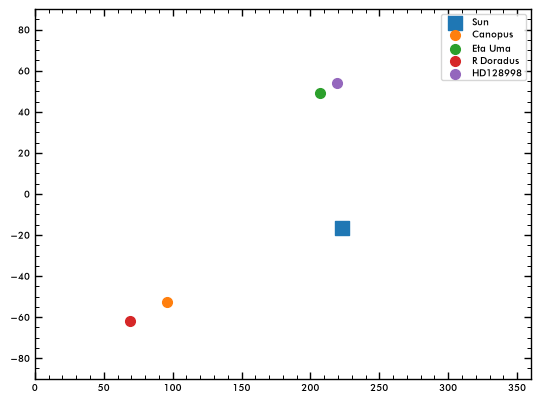

In [6]:
sun_ra = sun_coord.ra.degree
sun_dec = sun_coord.dec.degree
plt.scatter(sun_ra, sun_dec, marker="s", s=100, label="Sun")
plt.scatter(ra_alfCar, dec_alfCar, marker="o", label = "Canopus")
plt.scatter(ra_etaUma, dec_etaUma, marker="o", label = "Eta Uma")
plt.scatter(ra_rDor, dec_rDor, marker="o", label = "R Doradus")
plt.scatter(ra_HD, dec_HD, marker="o", label = "HD128998")
plt.xlim((0,360))
plt.ylim((-90,90))
plt.legend()

In [7]:
CAR171 = pd.read_csv("CAR171_v2_coordinates.csv")
# These are the coordinates of specially sensitive locations 
# for stray-light, measured in offset degrees from the center of WFI focal plane
dX = CAR171["MPA_ThetaX"]
dY = CAR171["MPA_ThetaY"]
CAR171["RA_Source"] = 9999.
CAR171["Dec_Source"] = 9999.
CAR171.at[12:,"RA_Source"] = ra_rDor
CAR171.at[12:,"Dec_Source"] = dec_rDor
CAR171.at[12:,"Target source"] = "R Doradus"

CAR171.at[22:26,"RA_Source"] = ra_alfCar
CAR171.at[22:26,"Dec_Source"] = dec_alfCar
CAR171.at[22:26,"Target source"] = "Canopus"

CAR171.at[0:4, "RA_Source"] = ra_etaUma
CAR171.at[0:4,"Dec_Source"] = dec_etaUma
CAR171.at[0:4,"Target source"] = "EtaUma"
CAR171.at[4:6,"RA_Source"] = ra_HD
CAR171.at[4:6,"Dec_Source"] = dec_HD
CAR171.at[4:6,"Target source"] = "HD128998"
CAR171.at[6:10,"RA_Source"] = ra_etaUma
CAR171.at[6:10,"Dec_Source"] = dec_etaUma
CAR171.at[6:10,"Target source"] = "EtaUma"
CAR171.at[10:11,"RA_Source"] = ra_HD
CAR171.at[10:11,"Dec_Source"] = dec_HD
CAR171.at[10:11,"Target source"] = "HD128998"

CAR171["MA Table"] = "IM_XXX_XX"
CAR171.at[0:11, "MA Table"] = "IM_171_10"
CAR171.at[12:,  "MA Table"] = "IM_193_11"

CAR171["Resultant"] = 9999
CAR171.at[0:11, "Resultant"] = 10
CAR171.at[12:,  "Resultant"] = 11

CAR171

,Unnamed: 0,Activity name,CAR,Region,Lite?,Possible descope,MPA_ThetaX,MPA_ThetaY,Target source,N_FRAME,N_EXP,N_FILT,Time,Filter(s),Notes,RA_Source,Dec_Source,MA Table,Resultant
0,0,SCA14_vertical,171.1,Outer PSF,True,False,0.2730,0.1149,EtaUma,55,2,1,8.8,F158,Risk reduction,206.885157,49.313267,IM_171_10,10
1,1,SCA14_horizontal,171.1,Outer PSF,True,False,0.2044,0.1480,EtaUma,55,2,1,8.8,F158,Risk reduction,206.885157,49.313267,IM_171_10,10
2,2,SCA5_vertical,171.1,Outer PSF,True,False,-0.2713,0.1151,EtaUma,55,2,1,8.8,F158,Risk reduction,206.885157,49.313267,IM_171_10,10
3,3,SCA5_horizontal,171.1,Outer PSF,True,False,-0.2026,0.1481,EtaUma,55,2,1,8.8,F158,Risk reduction,206.885157,49.313267,IM_171_10,10
4,4,SCA14_cen,171.1,Inner PSF,True,False,0.2044,0.0823,HD128998,55,2,1,8.8,F158,Risk reduction,219.563423,54.023340,IM_171_10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,77,SCAN_DRAGON2,171.2,Outer stray,True,False,-0.1408,-0.0083,R Doradus,55,4,1,14.3,F158,Corner light shield scan,69.189964,-62.077166,IM_193_11,11
78,78,SCAN_DRAGON2,171.2,Outer stray,True,False,-0.1352,-0.0083,R Doradus,55,4,1,14.3,F158,Corner light shield scan,69.189964,-62.077166,IM_193_11,11
79,79,SCAN_DRAGON2,171.2,Outer stray,True,False,-0.1324,-0.0035,R Doradus,55,4,1,14.3,F158,Corner light shield scan,69.189964,-62.077166,IM_193_11,11
80,80,NEGATIVE_GAP_1,171.2,Outer stray,True,False,0.0665,-0.1754,R Doradus,55,4,1,14.3,F158,Corner light shield scan,69.189964,-62.077166,IM_193_11,11


In [8]:
# ra_source = CAR171["RA_Source"]
# dec_source = CAR171["Dec_Source"]
number_of_points_of_interest = len(dX)

# To measure the stray-light from those sources, we need to place the center 
# of Roman / WFI at a certain distance and position angle from the source 
# that generates the stray-light. We will name that source the "offending" source. 

# ROSALIA has a specific tool to compute those locations. 

# The optimal position angle of Roman depends with time. 
# Let's set an approximate time for the Commissioning Activities

ra_wfi = np.zeros(number_of_points_of_interest)
dec_wfi = np.zeros(number_of_points_of_interest)
V3PA_ori = np.zeros(number_of_points_of_interest)
V3PA_off = np.zeros(number_of_points_of_interest)
WFIPA_off = np.zeros(number_of_points_of_interest)

activity_name_apt = []
category = []
description = []
for i in range(number_of_points_of_interest):
    offset_pointing = rs.telescopes.Roman.find_wfi_center_for_offset_target(ra_target=CAR171["RA_Source"].iloc[i],
                                                      dec_target=CAR171["Dec_Source"].iloc[i],
                                                      mjd=date.mjd,
                                                      dX=dX[i], dY=dY[i])
    ra_wfi[i] = offset_pointing["ra_wficen"]
    dec_wfi[i] = offset_pointing["dec_wficen"]
    WFIPA_off[i] = offset_pointing["PA_WFI_offset"]%360
    V3PA_off[i] = offset_pointing["V3PA_offset"]%360
    V3PA_ori[i] = offset_pointing["V3PA_origin"]%360
    # v3pa[i] = offset_pointing["PA_v3"] % 360
    activity_name_apt.append(CAR171["Activity name"].iloc[i]+"_"+str(i+1).zfill(3))
    category.append("Calibration")
    description.append("Stray light test")

car171_APT = pd.DataFrame({"Target": activity_name_apt, "ArchiveTarget": activity_name_apt,
                            "description":description, "category": category, "RA": ra_wfi, "DEC": dec_wfi, 
                           "WFIPA_off": WFIPA_off, "V3PA_off": V3PA_off, "V3PA_ori": V3PA_ori,
                           "CAR": CAR171["CAR"], "Region": CAR171["Region"], "Target_Source": CAR171["Target source"],
                           "RA_Source": CAR171["RA_Source"],"Dec_Source": CAR171["Dec_Source"],
                           "MPA_ThetaX": CAR171["MPA_ThetaX"], "MPA_ThetaY": CAR171["MPA_ThetaY"], 
                           "N_FRAME": CAR171["N_FRAME"], "N_EXP": CAR171["N_EXP"], "N_FILT": CAR171["N_FILT"], "Filter": CAR171["Filter(s)"],
                           "MA Table": CAR171["MA Table"], "Resultant": CAR171["Resultant"]})
car171_APT.to_csv("CAR171_apt_targets.csv")


Directory CAR171_SCA14_vertical_001 already exists. Skipping this target.
Directory CAR171_SCA14_horizontal_002 already exists. Skipping this target.
Directory CAR171_SCA5_vertical_003 already exists. Skipping this target.
Directory CAR171_SCA5_horizontal_004 already exists. Skipping this target.
Directory CAR171_SCA14_cen_005 already exists. Skipping this target.
Directory CAR171_SCA5_cen_006 already exists. Skipping this target.
Directory CAR171_SCA14_vertical_007 already exists. Skipping this target.
Directory CAR171_SCA14_horizontal_008 already exists. Skipping this target.
Directory CAR171_SCA5_vertical_009 already exists. Skipping this target.
Directory CAR171_SCA5_horizontal_010 already exists. Skipping this target.
Directory CAR171_SCA14_cen_011 already exists. Skipping this target.
Directory CAR171_SCA5_cen_012 already exists. Skipping this target.
Directory CAR171_OUT_pos_1_a_013 already exists. Skipping this target.
Directory CAR171_OUT_pos_1_b_014 already exists. Skipping t

18it [00:03,  5.39it/s]

2026-10-24T13:31:10.055729 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:55<00:00,  3.10s/it]


2026-10-24T13:32:06.756960 > Done : 0:00:56.701259 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T13:32:07.697077 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T13:32:17.647247 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


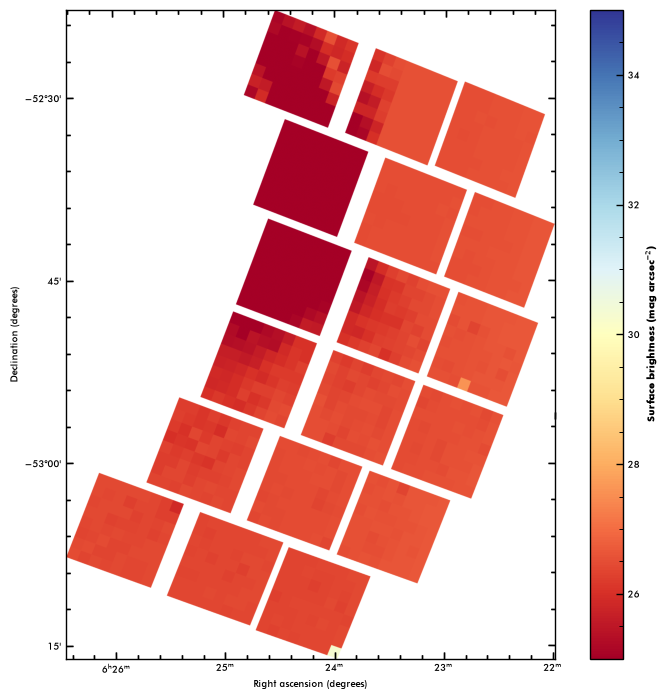

Plot: Stray-light surface brightness flux.
0.010715468
1.0559255


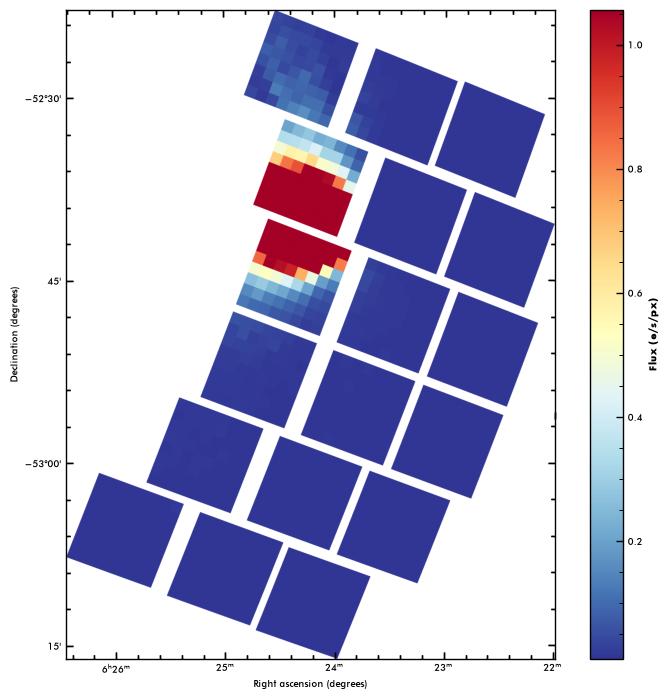

Plot: Main offender map.
8.0
21.0
Unique IDs:
[     8     21 197960]
Unique IDs with counts > 1:
[     8     21 197960]
V* R Dor
* alf Car
Simbad cannot find the name of the offender at 96.33796 - -53.068806
Main stray-light offenders:

93.21% - (95.99, -52.70), m=-0.08 - * alf Car
6.61% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (96.34, -53.07), m=14.20 - CAT_ID_197960


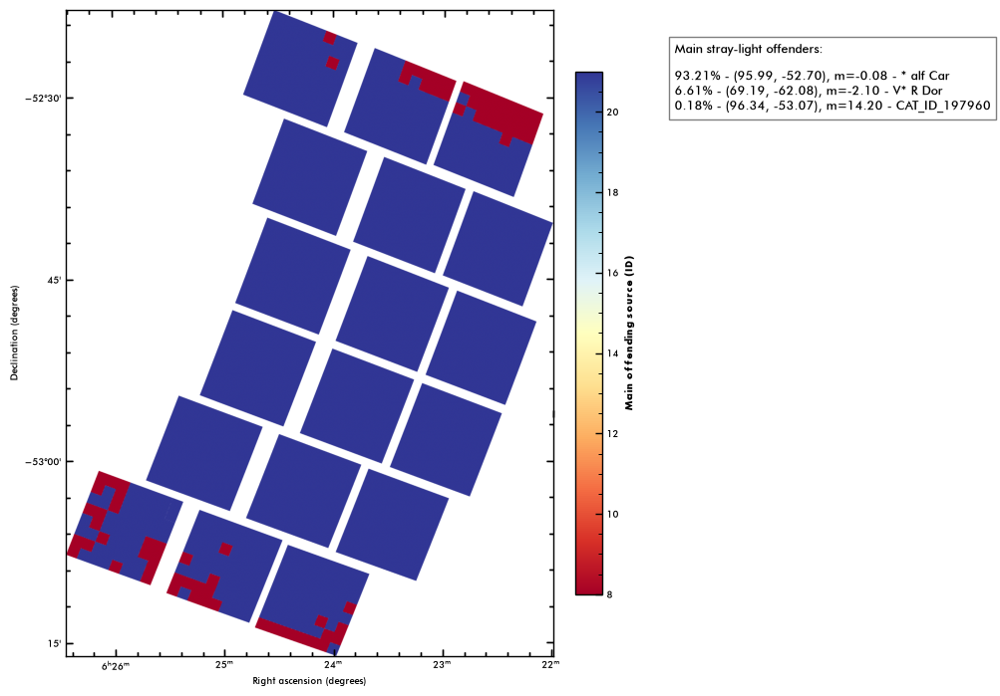

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


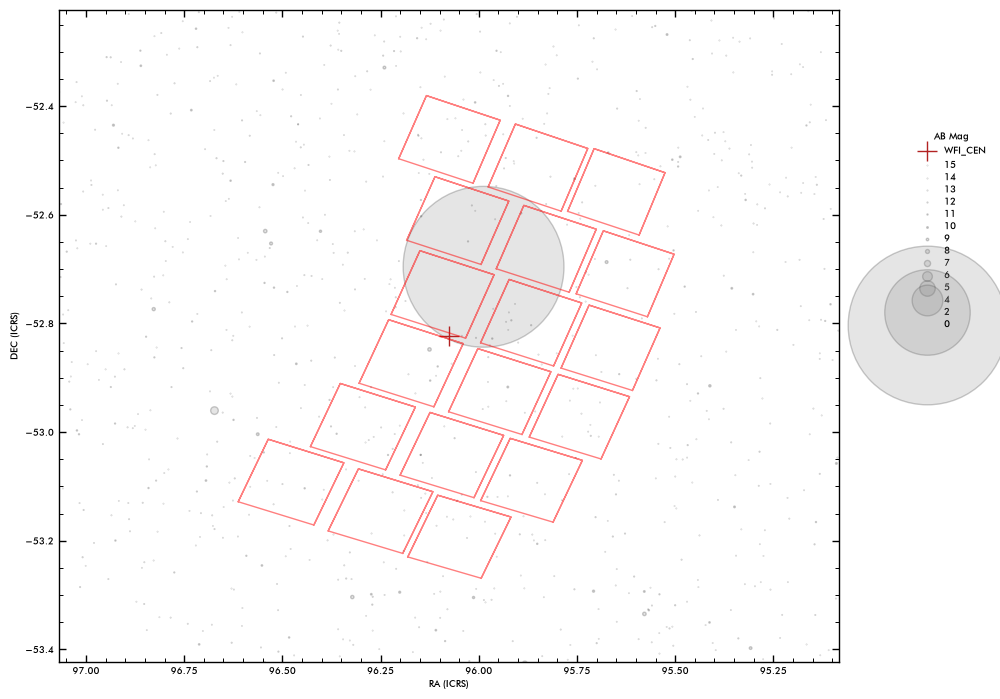

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8     21 197960]
Unique IDs with counts > 1:
[     8     21 197960]
V* R Dor
* alf Car
Simbad cannot find the name of the offender at 96.33796 - -53.068806
Main stray-light offenders:

93.21% - (95.99, -52.70), m=-0.08 - * alf Car
6.61% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (96.34, -53.07), m=14.20 - CAT_ID_197960
2026-10-24T13:32:28.396648 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_IN_pos_5_b_026_Roman_RA_096.076_DEC_-52.823_MJD_61352.00000_PA_069.17_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_IN_pos_5_b_026_Roman_RA_096.076_DEC_-52.823_MJD_61352.00000_PA_069.17_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T13:32:44.499628 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2M

2026-10-24 13:32:45 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

2026-10-24 13:32:47 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T13:32:58.437684 > Done.


18it [00:03,  5.17it/s]

2026-10-24T13:33:01.928791 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:49<00:00,  2.73s/it]


2026-10-24T13:33:52.209431 > Done : 0:00:50.280663 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T13:33:53.236350 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T13:34:02.260391 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


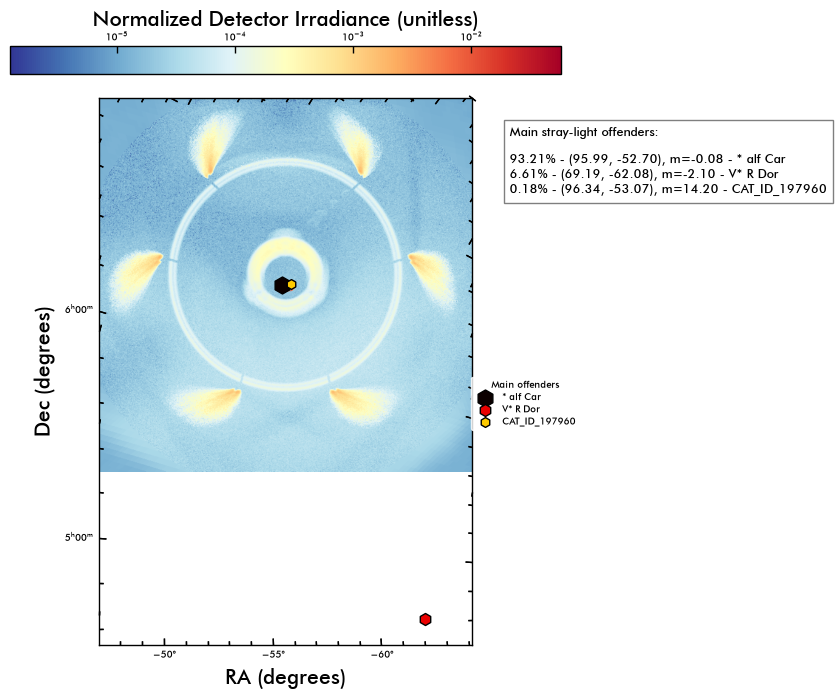

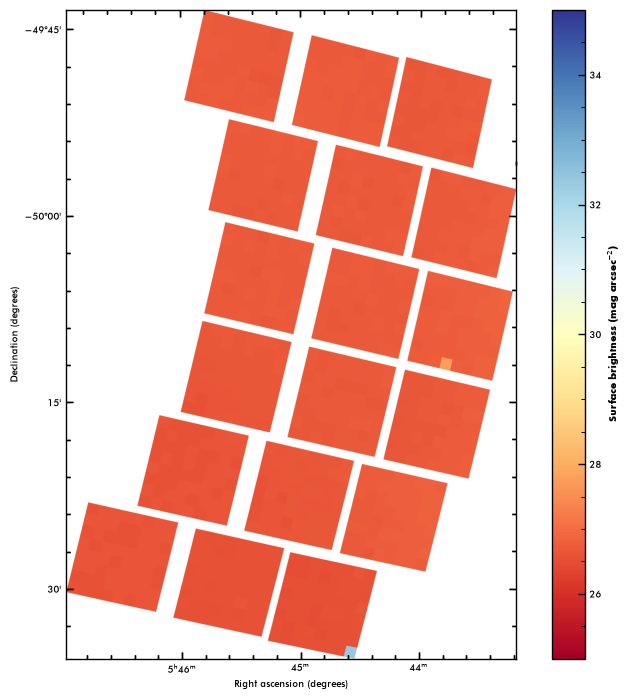

Plot: Stray-light surface brightness flux.
0.009250561
0.01121739


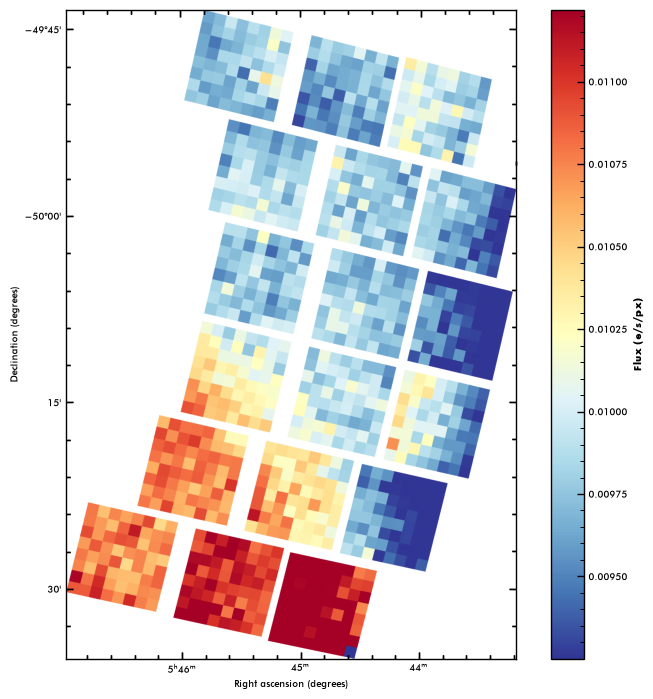

Plot: Main offender map.
454.0
454.0
Unique IDs:
[   454 196888]
Unique IDs with counts > 1:
[   454 196888]
Simbad cannot find the name of the offender at 77.6163 - -48.533405
CD-49  1866
Main stray-light offenders:

99.92% - (77.62, -48.53), m=2.31 - CAT_ID_454
0.08% - (86.19, -49.74), m=10.52 - CD-49  1866


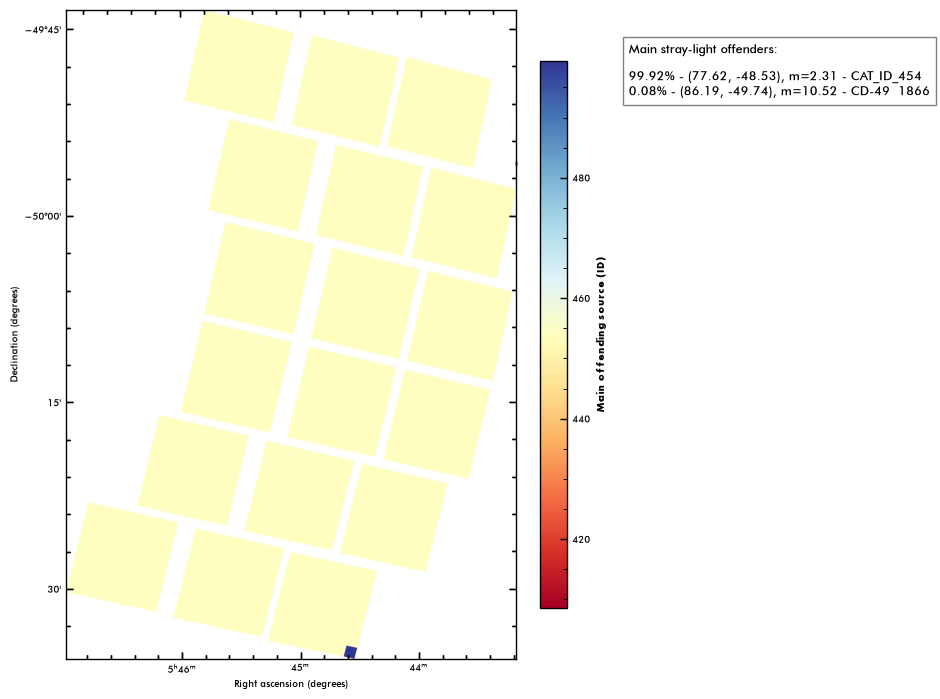

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


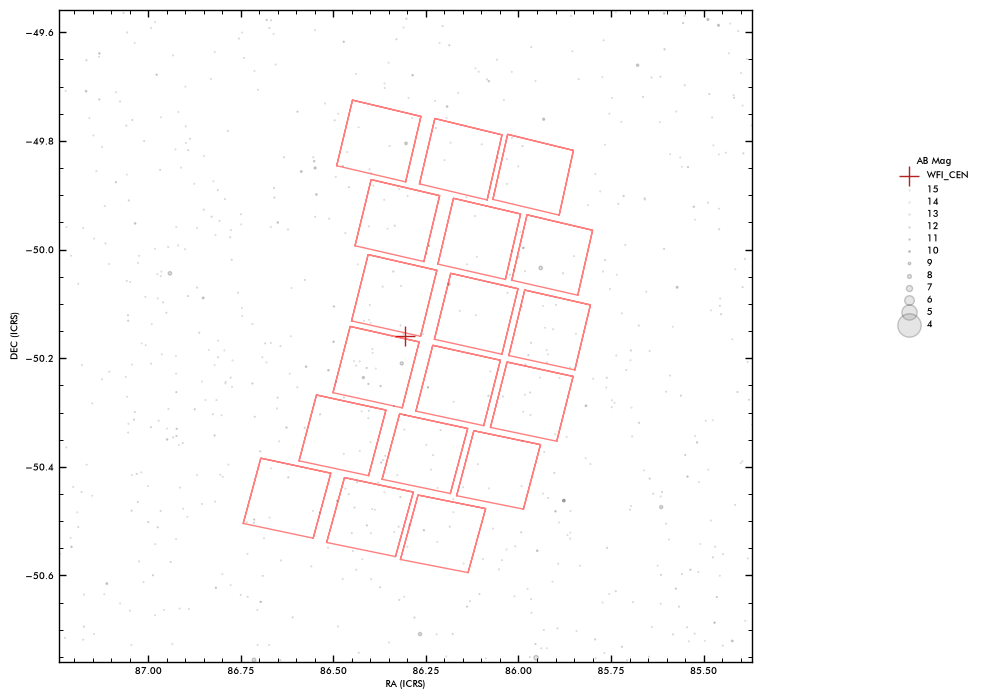

Plot: Location of Main offenders on NDI map.
Unique IDs:
[   454 196888]
Unique IDs with counts > 1:
[   454 196888]
Simbad cannot find the name of the offender at 77.6163 - -48.533405
CD-49  1866
Main stray-light offenders:

99.92% - (77.62, -48.53), m=2.31 - CAT_ID_454
0.08% - (86.19, -49.74), m=10.52 - CD-49  1866
2026-10-24T13:34:10.501609 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_027_Roman_RA_086.305_DEC_-50.159_MJD_61352.00000_PA_076.71_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_027_Roman_RA_086.305_DEC_-50.159_MJD_61352.00000_PA_076.71_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T13:53:04.852278 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes

2026-10-24 13:53:04 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 13:53:06 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

...


Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T13:58:07.996905 > Done.


18it [00:03,  4.69it/s]

2026-10-24T13:58:11.842547 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:52<00:00,  2.93s/it]


2026-10-24T13:59:05.596426 > Done : 0:00:53.753898 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T13:59:06.689457 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T13:59:15.959557 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


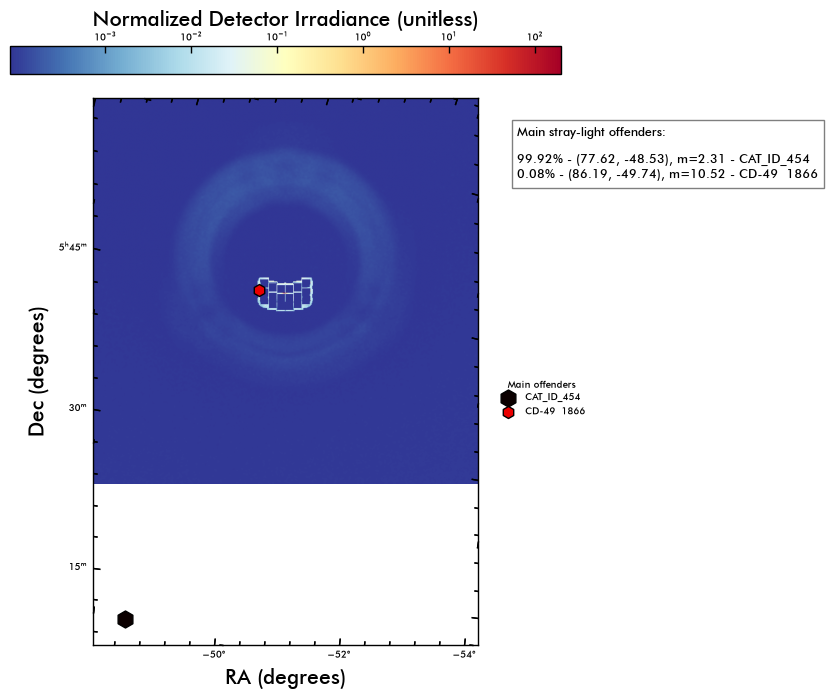

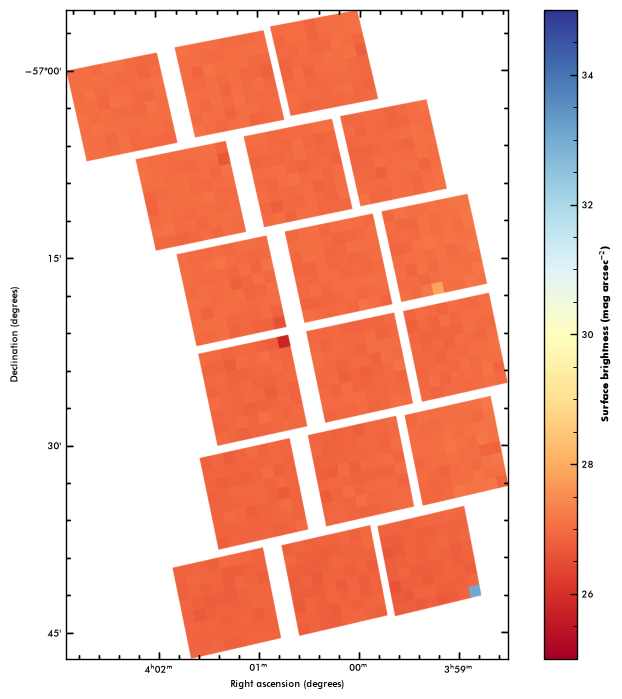

Plot: Stray-light surface brightness flux.
0.0069449143
0.009034228


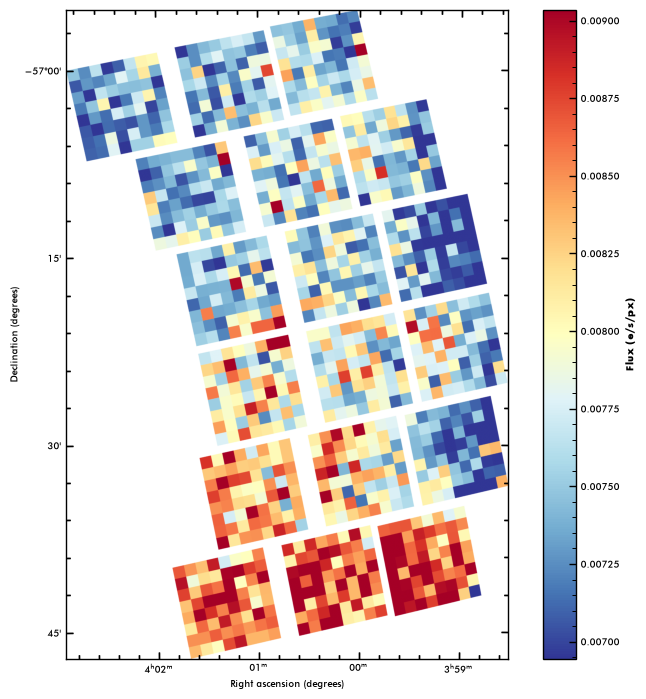

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196895 197124 197352]
Unique IDs with counts > 1:
[     8 196895 197124 197352]
V* R Dor
Simbad cannot find the name of the offender at 60.066097 - -57.76069
Simbad cannot find the name of the offender at 60.1656 - -57.3503
Simbad cannot find the name of the offender at 60.306744 - -57.11321
Main stray-light offenders:

99.56% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (60.17, -57.35), m=13.61 - CAT_ID_197124
0.09% - (60.31, -57.11), m=14.74 - CAT_ID_197352
0.08% - (60.07, -57.76), m=11.52 - CAT_ID_196895


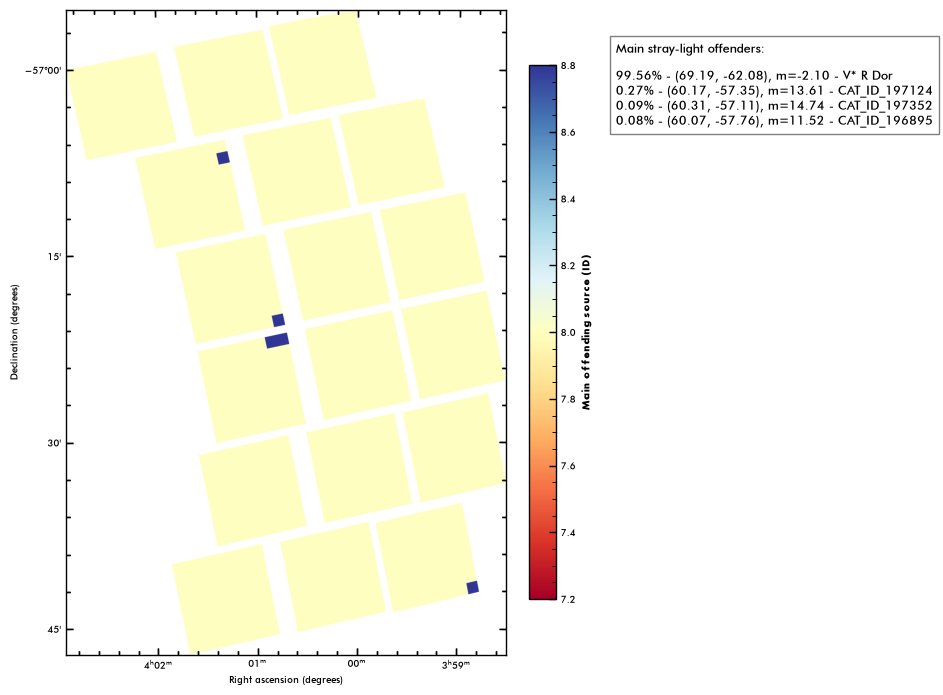

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


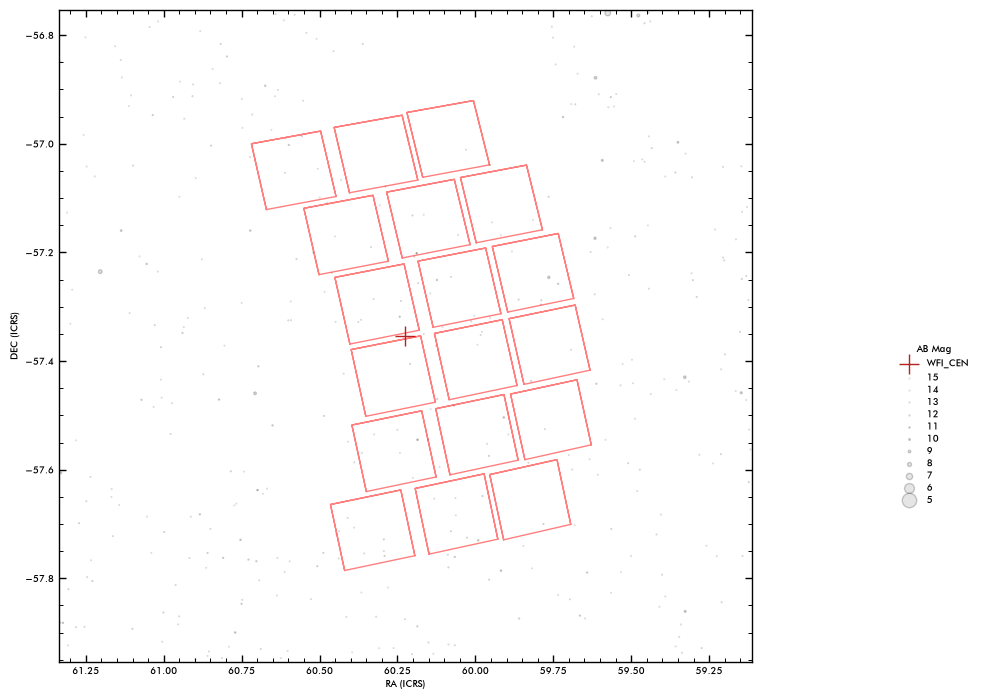

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196895 197124 197352]
Unique IDs with counts > 1:
[     8 196895 197124 197352]
V* R Dor
Simbad cannot find the name of the offender at 60.066097 - -57.76069
Simbad cannot find the name of the offender at 60.1656 - -57.3503
Simbad cannot find the name of the offender at 60.306744 - -57.11321
Main stray-light offenders:

99.56% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (60.17, -57.35), m=13.61 - CAT_ID_197124
0.09% - (60.31, -57.11), m=14.74 - CAT_ID_197352
0.08% - (60.07, -57.76), m=11.52 - CAT_ID_196895
2026-10-24T13:59:25.276293 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_028_Roman_RA_060.224_DEC_-57.354_MJD_61352.00000_PA_102.02_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_028_Roman_RA_060.224_DEC_-57.354_MJD_61352.00000_PA_102.02_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T13:59:45.191144 > Fetching source cata

2026-10-24 13:59:45 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 13:59:47 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T13:59:58.507602 > Done.


18it [00:04,  4.42it/s]


2026-10-24T14:00:02.595307 > Starting Stray-light scan: 


100%|██████████| 18/18 [00:54<00:00,  3.05s/it]


2026-10-24T14:00:58.533945 > Done : 0:00:55.938657 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:00:59.627173 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:01:09.158957 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


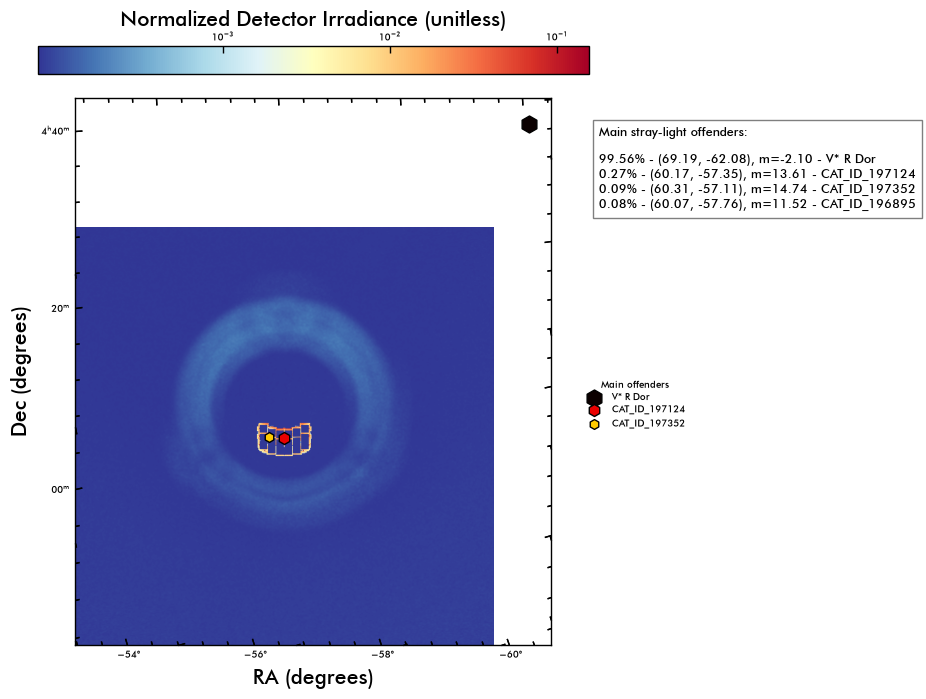

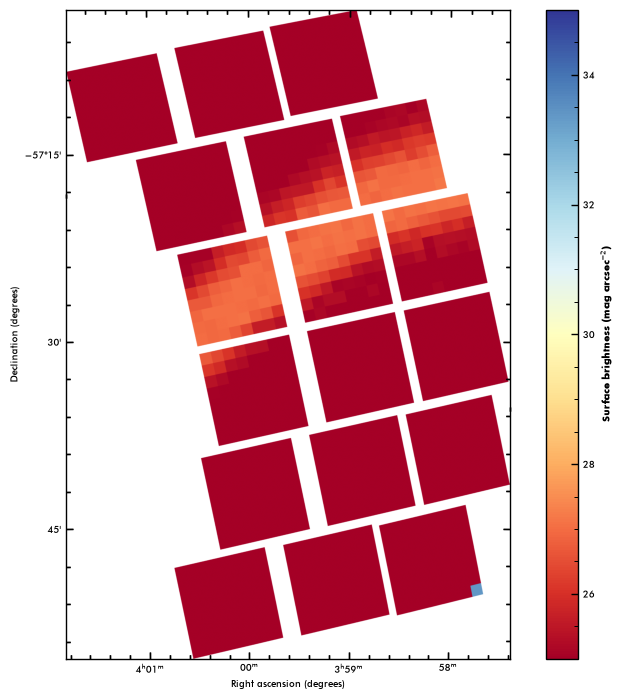

Plot: Stray-light surface brightness flux.
0.0074603604
0.07438152


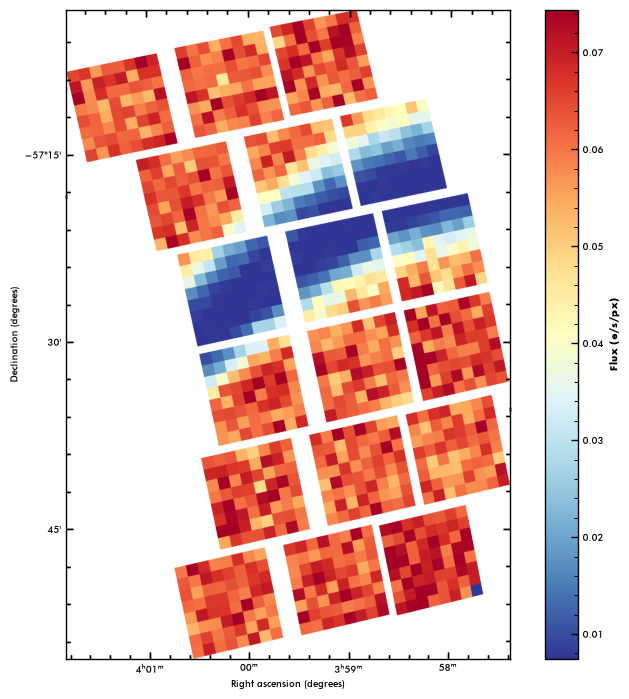

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196860]
Unique IDs with counts > 1:
[     8 196860]
V* R Dor
TYC 8507-1303-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.92, -57.79), m=10.51 - TYC 8507-1303-1


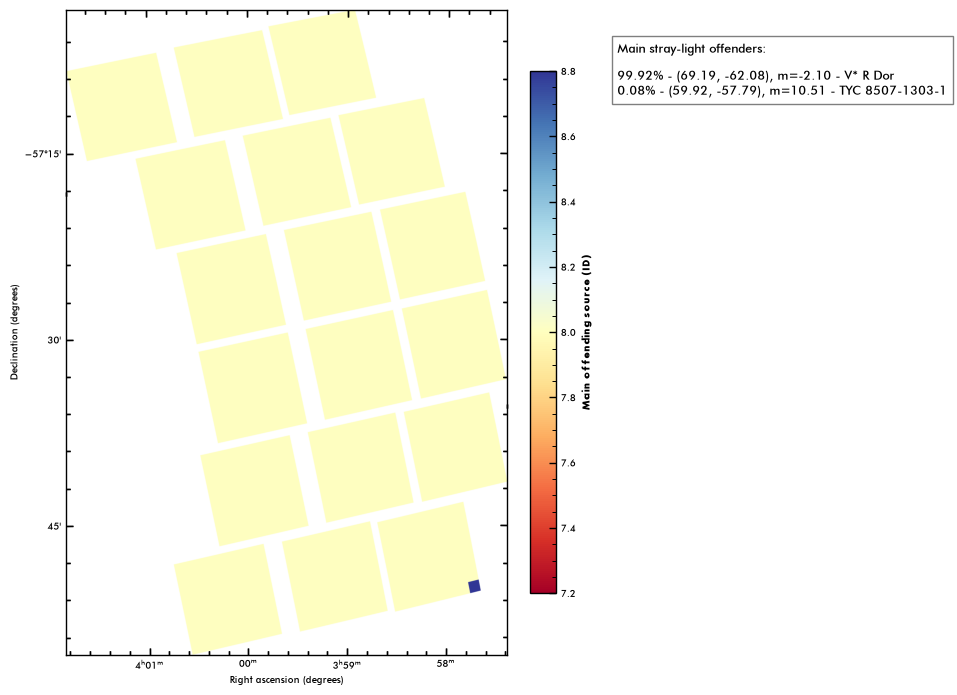

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


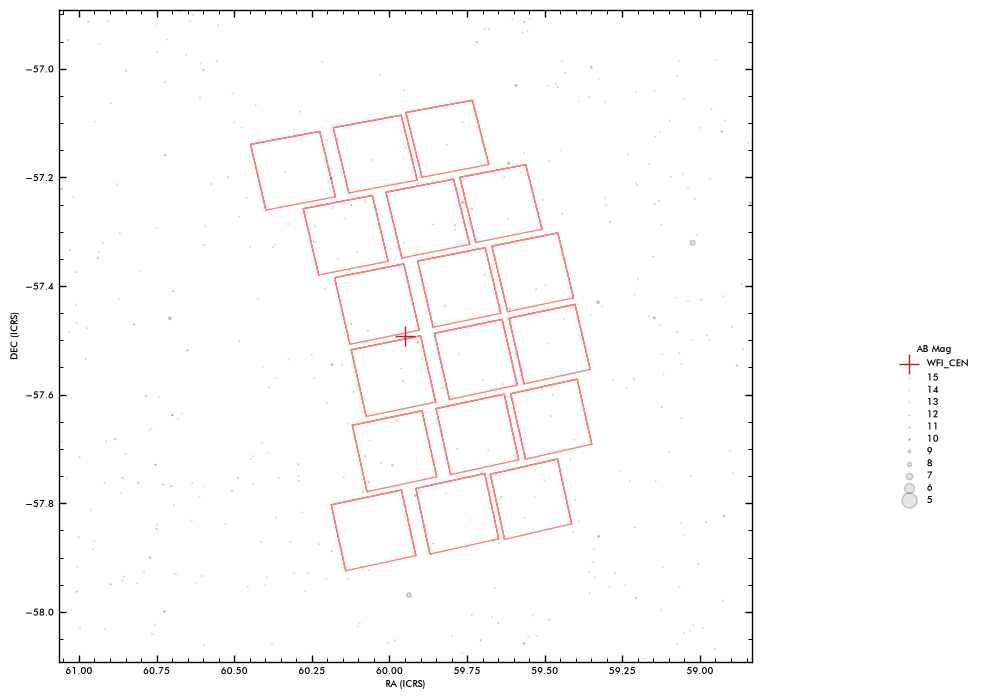

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196860]
Unique IDs with counts > 1:
[     8 196860]
V* R Dor
TYC 8507-1303-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.92, -57.79), m=10.51 - TYC 8507-1303-1
2026-10-24T14:01:17.957906 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_029_Roman_RA_059.948_DEC_-57.492_MJD_61352.00000_PA_102.26_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_029_Roman_RA_059.948_DEC_-57.492_MJD_61352.00000_PA_102.26_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:01:37.378096 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:01:37 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

2026-10-24 14:01:39 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T14:01:50.149809 > Done.


18it [00:03,  4.93it/s]

2026-10-24T14:01:53.808746 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:50<00:00,  2.82s/it]


2026-10-24T14:02:45.560724 > Done : 0:00:51.751994 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:02:46.629536 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:02:56.346391 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


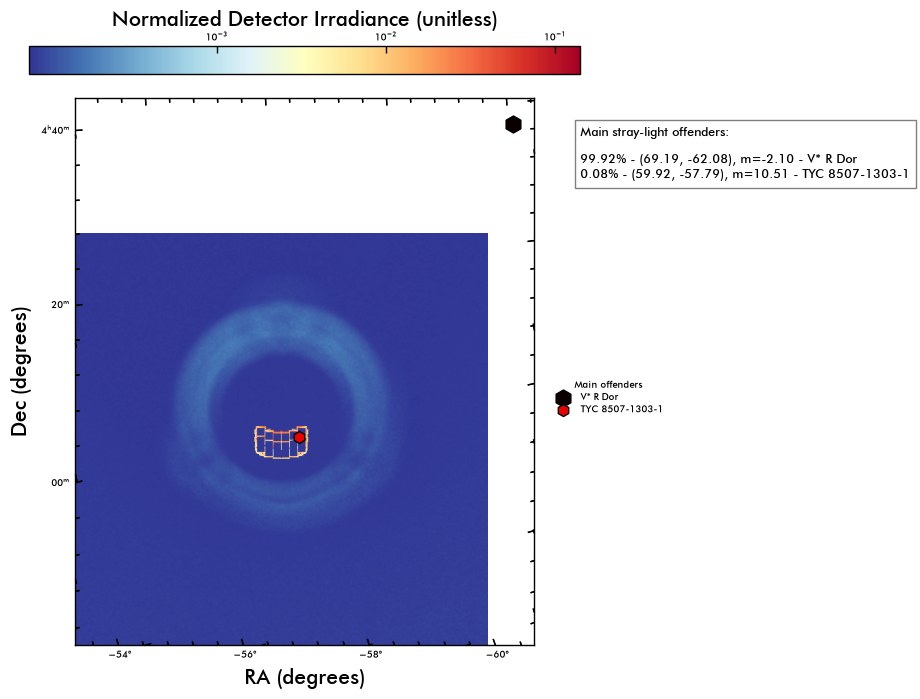

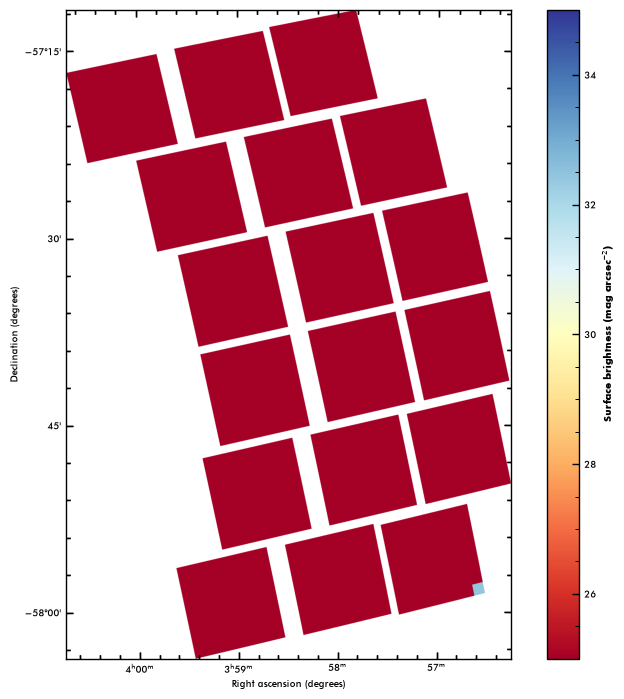

Plot: Stray-light surface brightness flux.
0.0625832
0.20250171


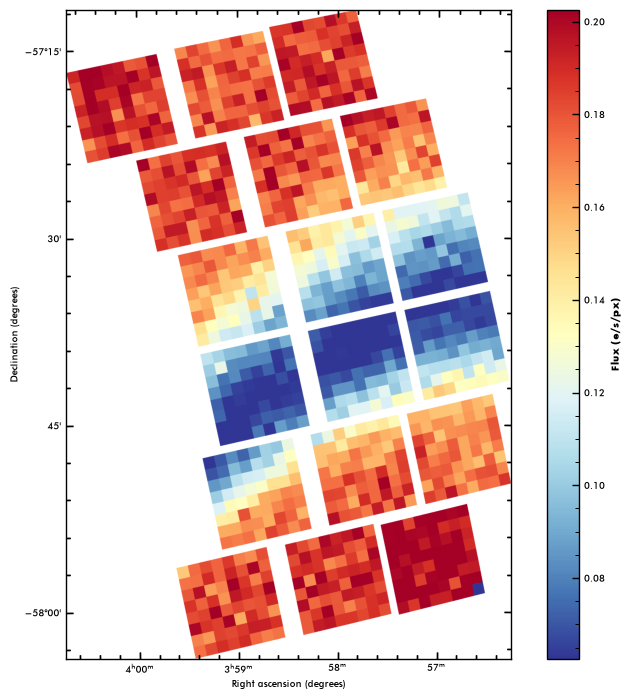

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196813]
Unique IDs with counts > 1:
[     8 196813]
V* R Dor
TYC 8504-847-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.62, -57.17), m=9.39 - TYC 8504-847-1


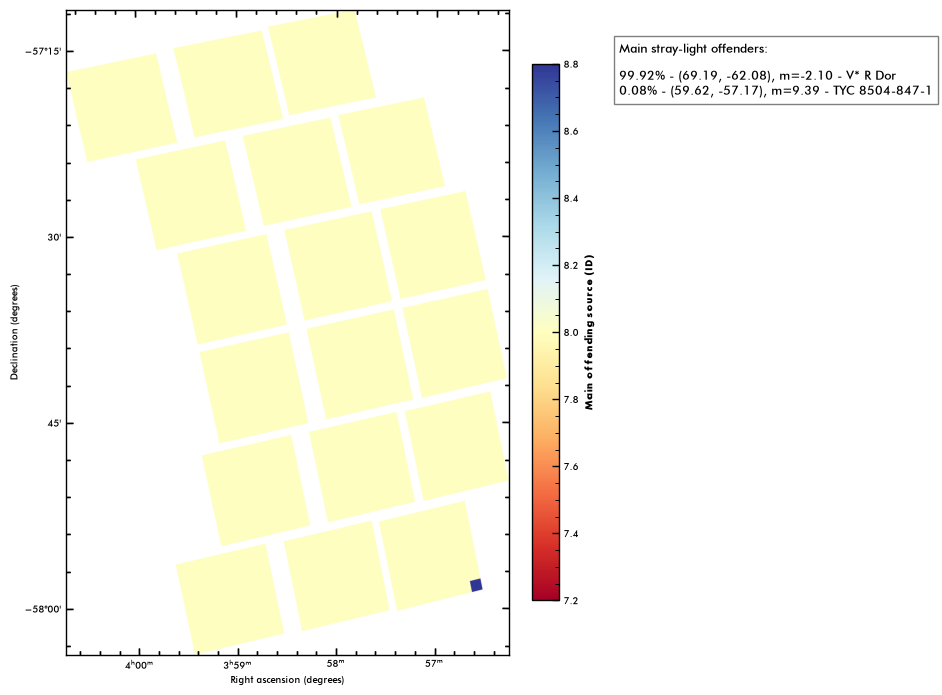

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


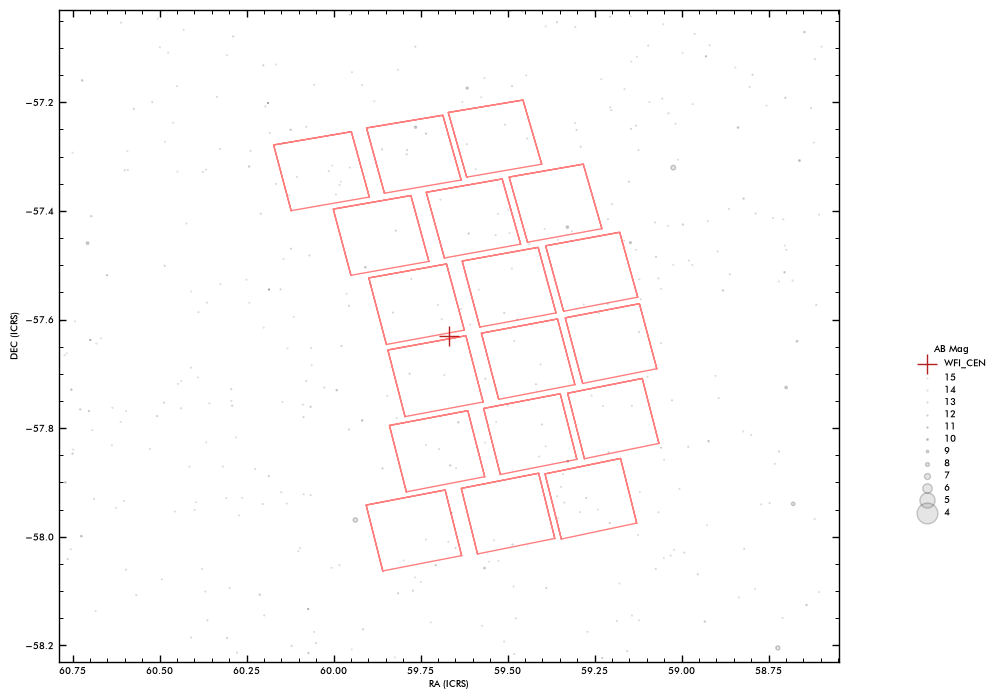

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196813]
Unique IDs with counts > 1:
[     8 196813]
V* R Dor
TYC 8504-847-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.62, -57.17), m=9.39 - TYC 8504-847-1
2026-10-24T14:03:05.307293 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_030_Roman_RA_059.669_DEC_-57.630_MJD_61352.00000_PA_102.50_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_030_Roman_RA_059.669_DEC_-57.630_MJD_61352.00000_PA_102.50_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:03:22.908232 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:03:22 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

2026-10-24 14:03:24 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T14:04:15.766758 > Done.


18it [00:03,  4.80it/s]

2026-10-24T14:04:19.527731 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:53<00:00,  2.98s/it]


2026-10-24T14:05:14.236935 > Done : 0:00:54.709250 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:05:15.311210 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:05:25.124276 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


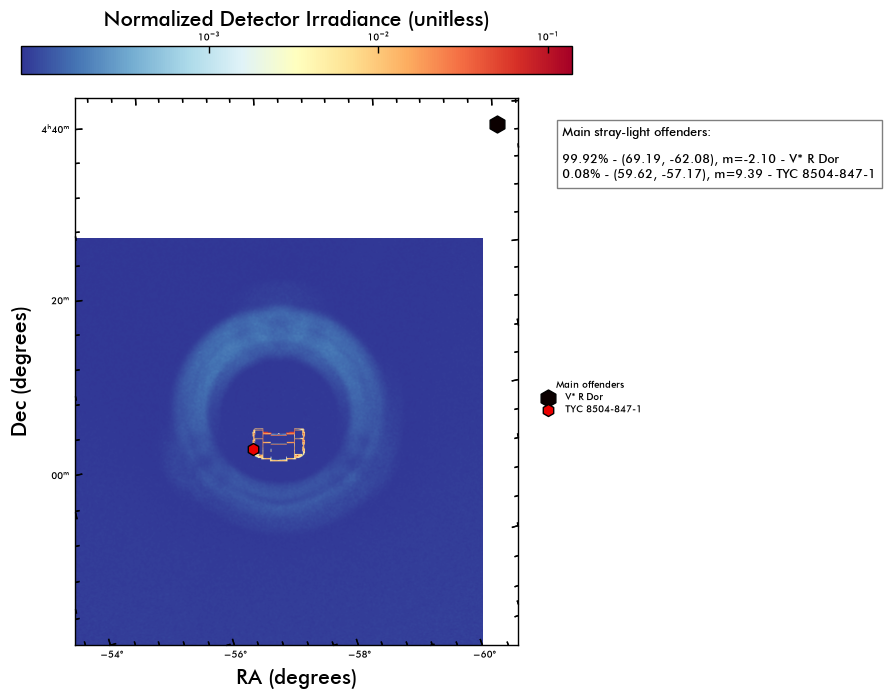

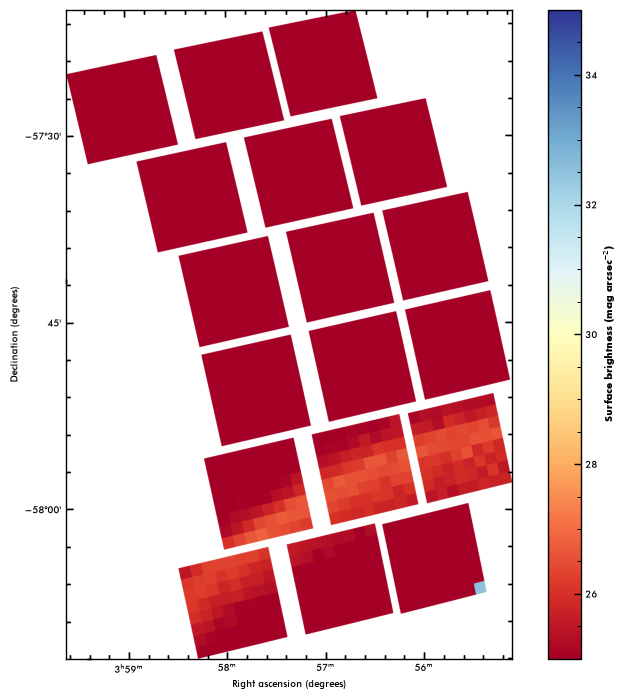

Plot: Stray-light surface brightness flux.
0.015278422
0.092019275


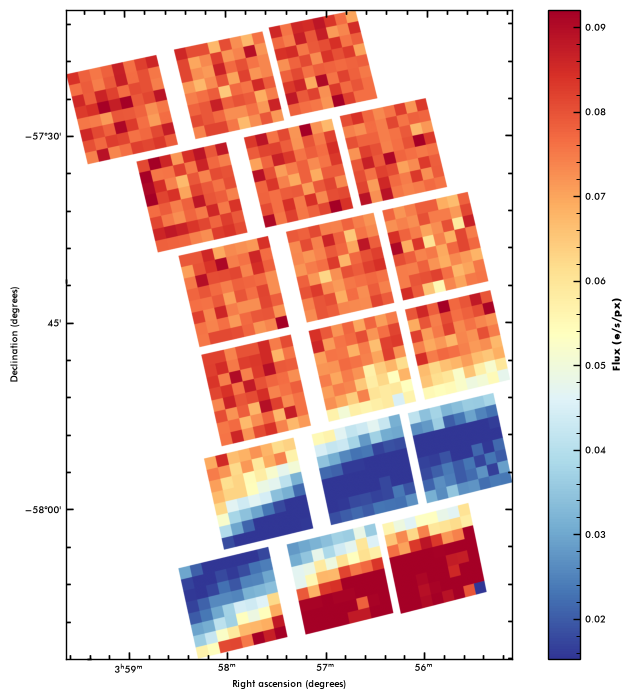

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196851]
Unique IDs with counts > 1:
[     8 196851]
V* R Dor
CD-58   805
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.57, -58.06), m=10.29 - CD-58   805


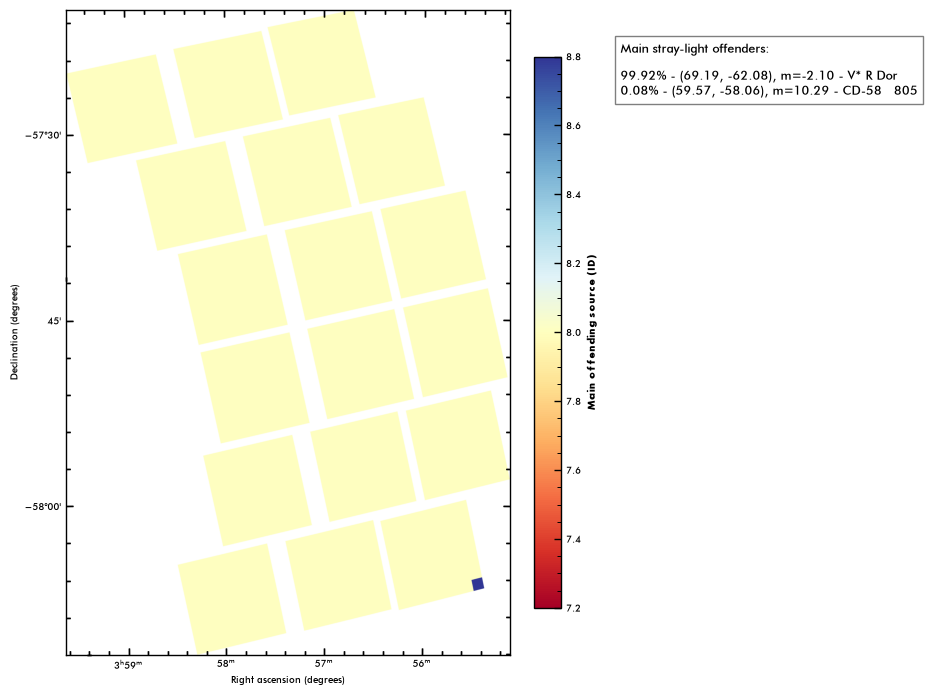

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


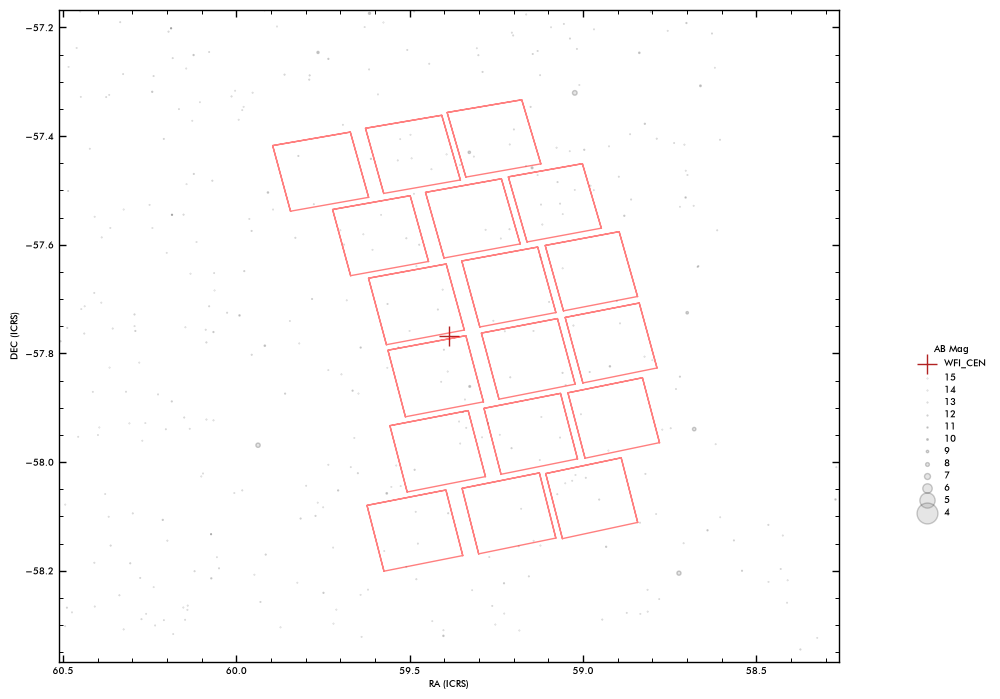

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196851]
Unique IDs with counts > 1:
[     8 196851]
V* R Dor
CD-58   805
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.57, -58.06), m=10.29 - CD-58   805
2026-10-24T14:05:34.158244 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_031_Roman_RA_059.387_DEC_-57.768_MJD_61352.00000_PA_102.75_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_031_Roman_RA_059.387_DEC_-57.768_MJD_61352.00000_PA_102.75_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:05:51.238021 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:05:51 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 14:05:52 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T14:06:44.213536 > Done.


18it [00:03,  4.85it/s]

2026-10-24T14:06:47.937848 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:53<00:00,  2.99s/it]


2026-10-24T14:07:42.854374 > Done : 0:00:54.916540 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:07:43.976027 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:07:53.000096 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


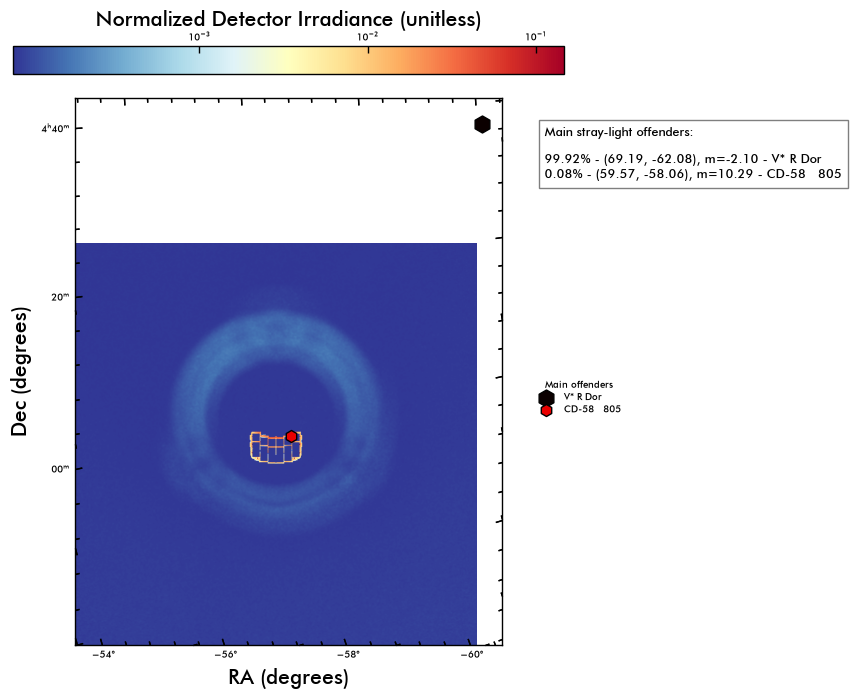

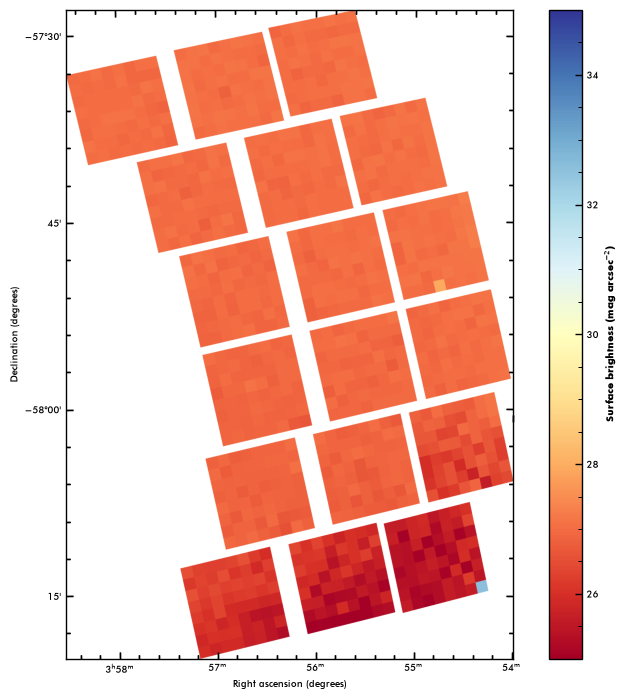

Plot: Stray-light surface brightness flux.
0.0067732157
0.030269403


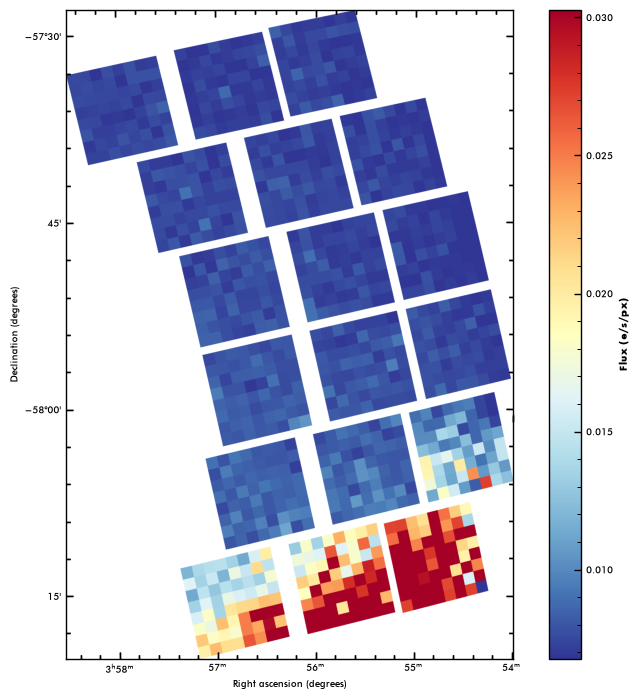

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196842 197117]
Unique IDs with counts > 1:
[     8 196842 197117]
V* R Dor
CD-58   800
Simbad cannot find the name of the offender at 59.031296 - -58.034496
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (59.03, -58.03), m=13.71 - CAT_ID_197117
0.08% - (59.33, -57.86), m=9.76 - CD-58   800


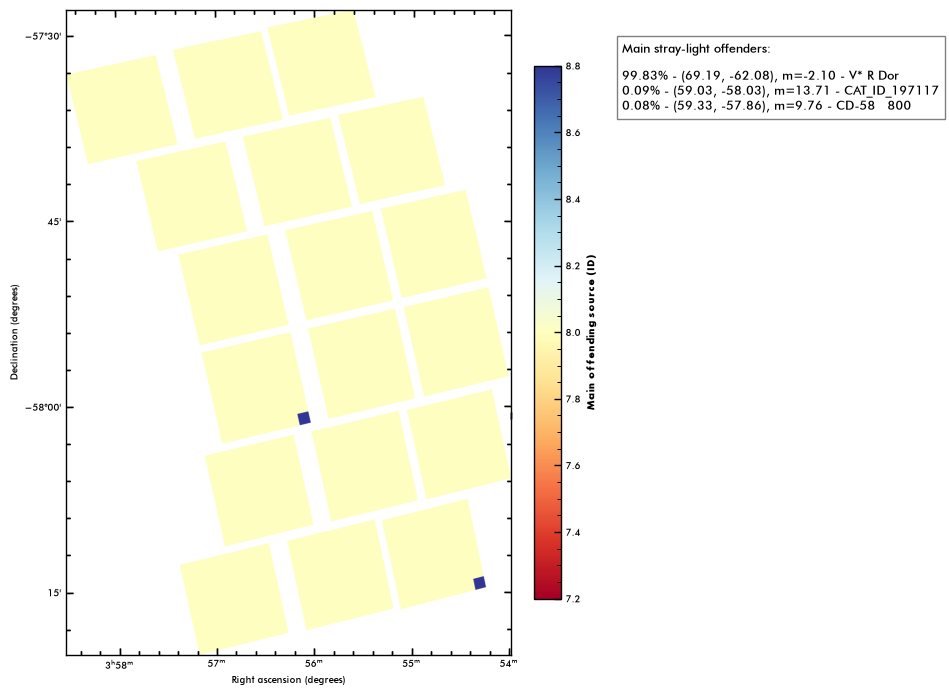

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


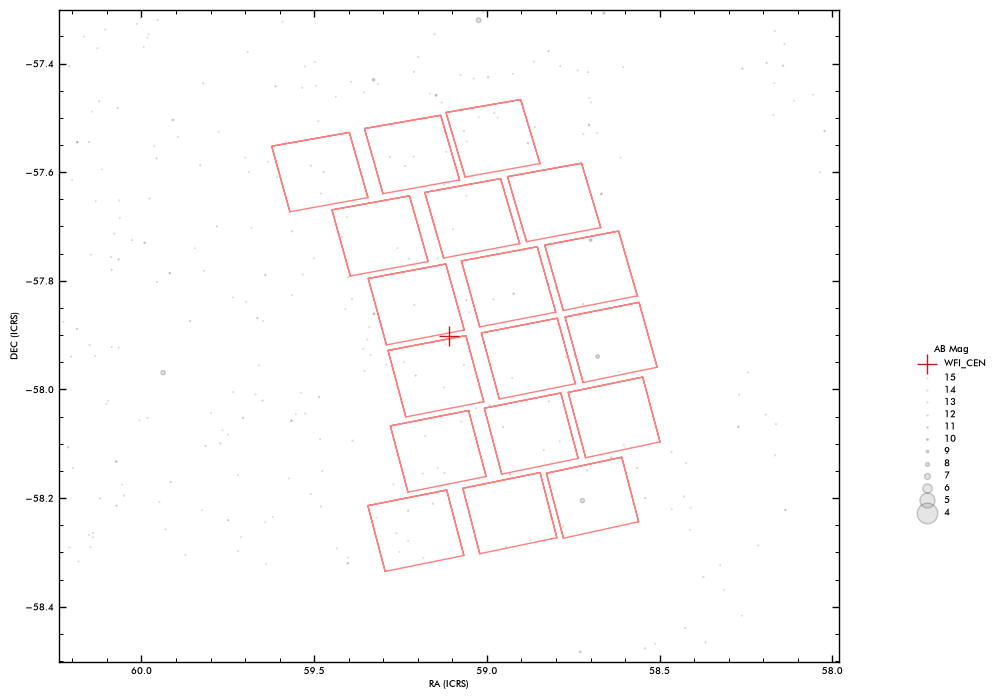

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196842 197117]
Unique IDs with counts > 1:
[     8 196842 197117]
V* R Dor
CD-58   800
Simbad cannot find the name of the offender at 59.031296 - -58.034496
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (59.03, -58.03), m=13.71 - CAT_ID_197117
0.08% - (59.33, -57.86), m=9.76 - CD-58   800
2026-10-24T14:08:01.790908 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_032_Roman_RA_059.110_DEC_-57.901_MJD_61352.00000_PA_102.99_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_032_Roman_RA_059.110_DEC_-57.901_MJD_61352.00000_PA_102.99_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:08:18.240943 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Queryi

2026-10-24 14:08:18 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 14:08:19 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣽
2026-10-24T14:08:30.705367 > Done.


18it [00:03,  4.98it/s]


2026-10-24T14:08:34.333410 > Starting Stray-light scan: 


100%|██████████| 18/18 [00:46<00:00,  2.56s/it]


2026-10-24T14:09:21.396389 > Done : 0:00:47.062999 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:09:22.416890 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:09:31.358695 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


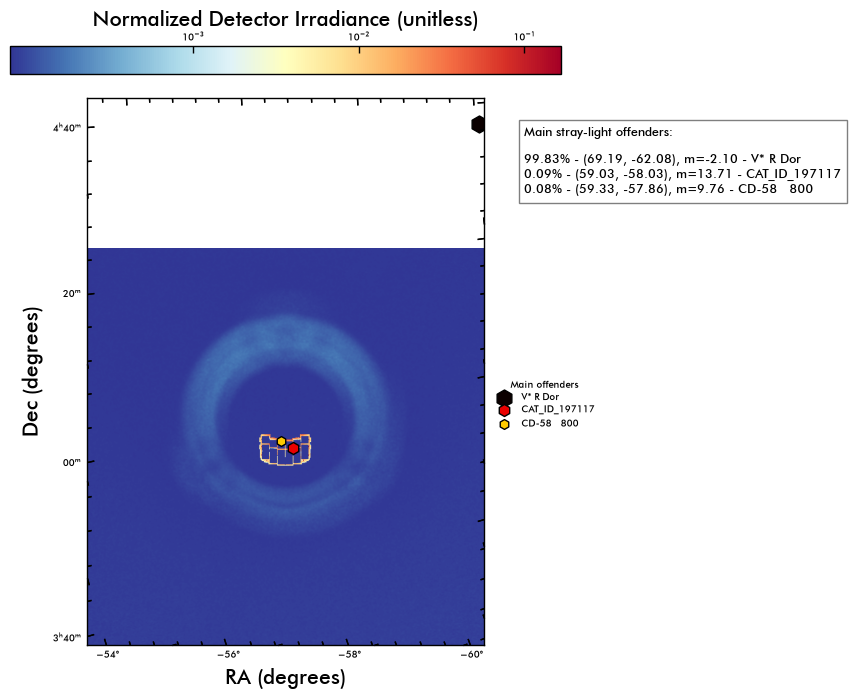

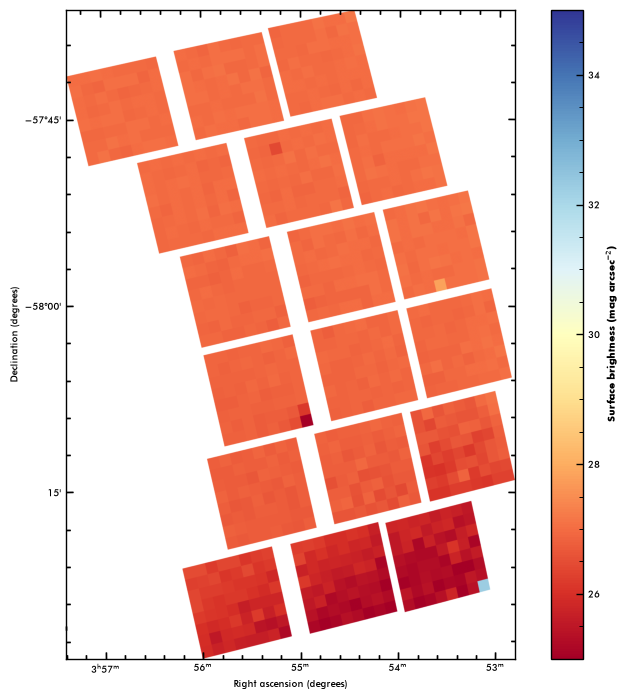

Plot: Stray-light surface brightness flux.
0.0070274626
0.032446273


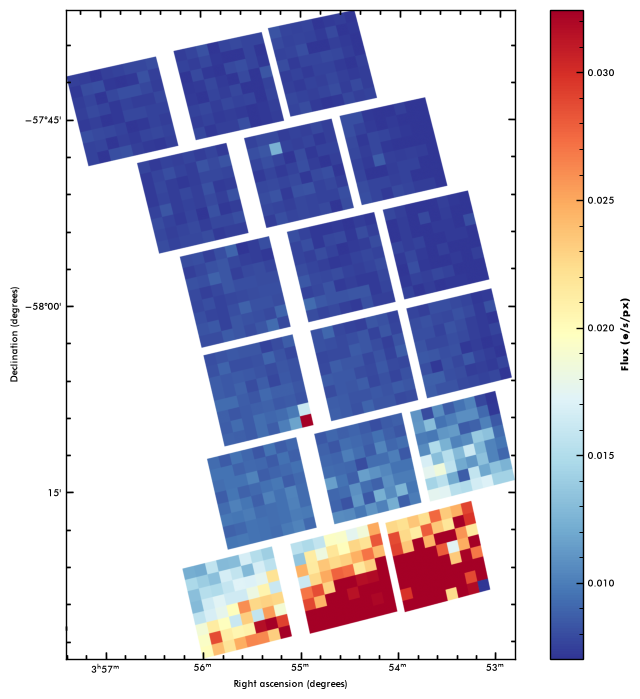

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 166128 197111]
Unique IDs with counts > 1:
[     8 166128 197111]
V* R Dor
HD  24955
Simbad cannot find the name of the offender at 58.709965 - -58.14952
Main stray-light offenders:

99.65% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (58.71, -58.15), m=13.69 - CAT_ID_197111
0.08% - (58.72, -58.20), m=7.82 - HD  24955


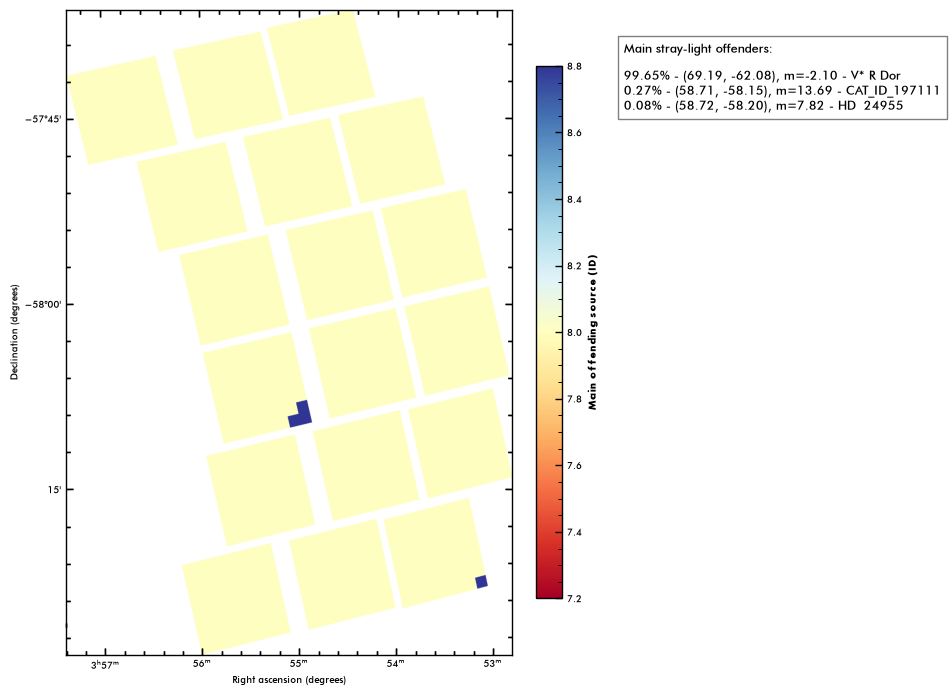

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


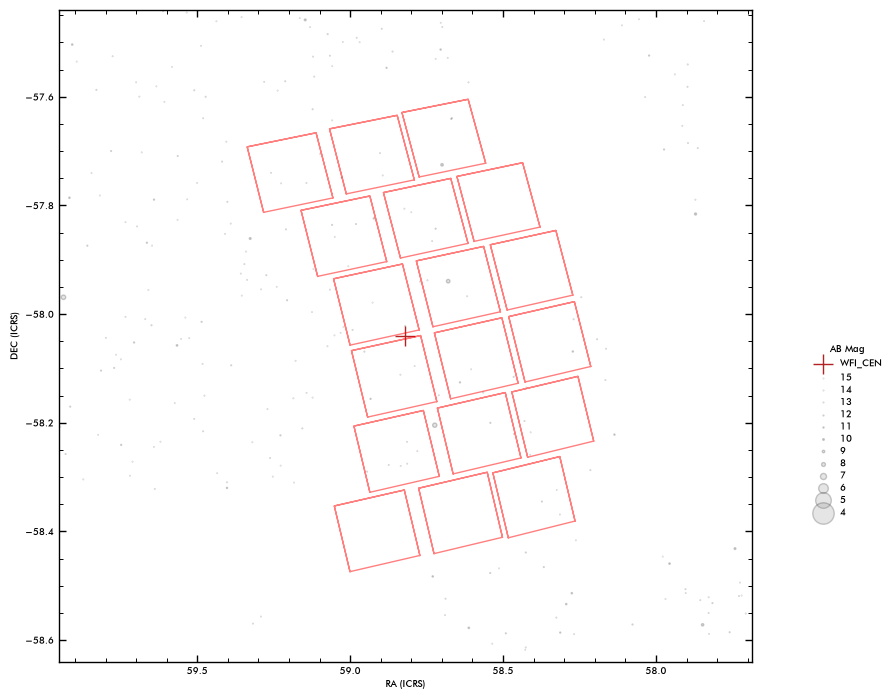

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 166128 197111]
Unique IDs with counts > 1:
[     8 166128 197111]
V* R Dor
HD  24955
Simbad cannot find the name of the offender at 58.709965 - -58.14952
Main stray-light offenders:

99.65% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (58.71, -58.15), m=13.69 - CAT_ID_197111
0.08% - (58.72, -58.20), m=7.82 - HD  24955
2026-10-24T14:09:39.869021 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_033_Roman_RA_058.819_DEC_-58.040_MJD_61352.00000_PA_103.24_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_RCHANNEL_033_Roman_RA_058.819_DEC_-58.040_MJD_61352.00000_PA_103.24_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:09:56.212547 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Ga

2026-10-24 14:09:56 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 14:09:57 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⢿
2026-10-24T14:10:49.020909 > Done.


18it [00:03,  5.03it/s]

2026-10-24T14:10:52.609747 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.57s/it]


2026-10-24T14:11:39.841150 > Done : 0:00:47.231425 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:11:40.876441 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:11:49.941007 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


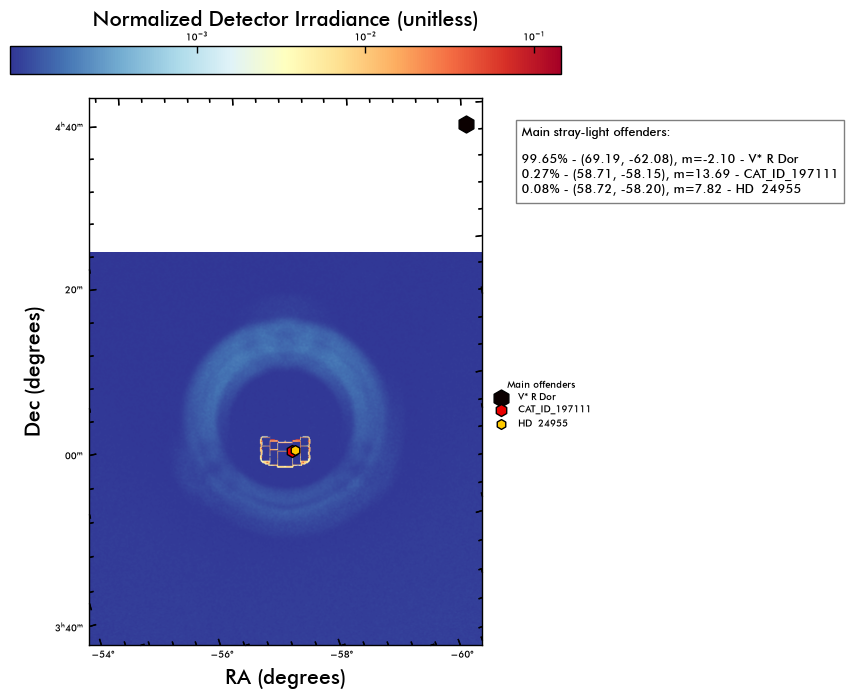

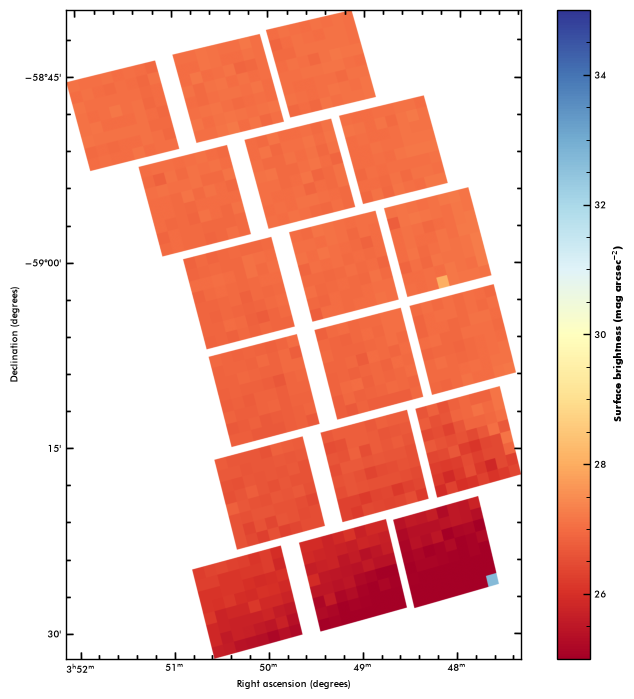

Plot: Stray-light surface brightness flux.
0.006667652
0.04083908


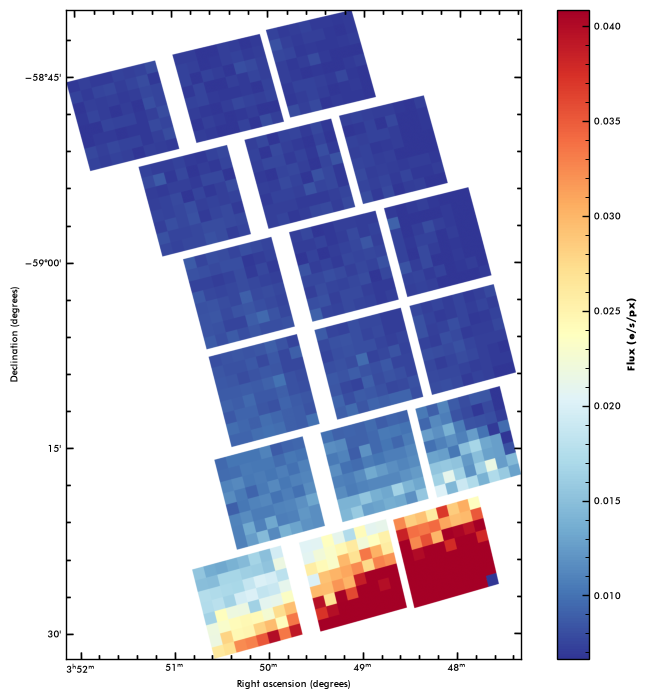

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196851]
Unique IDs with counts > 1:
[     8 196851]
V* R Dor
TYC 8507-1541-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.98, -58.74), m=9.81 - TYC 8507-1541-1


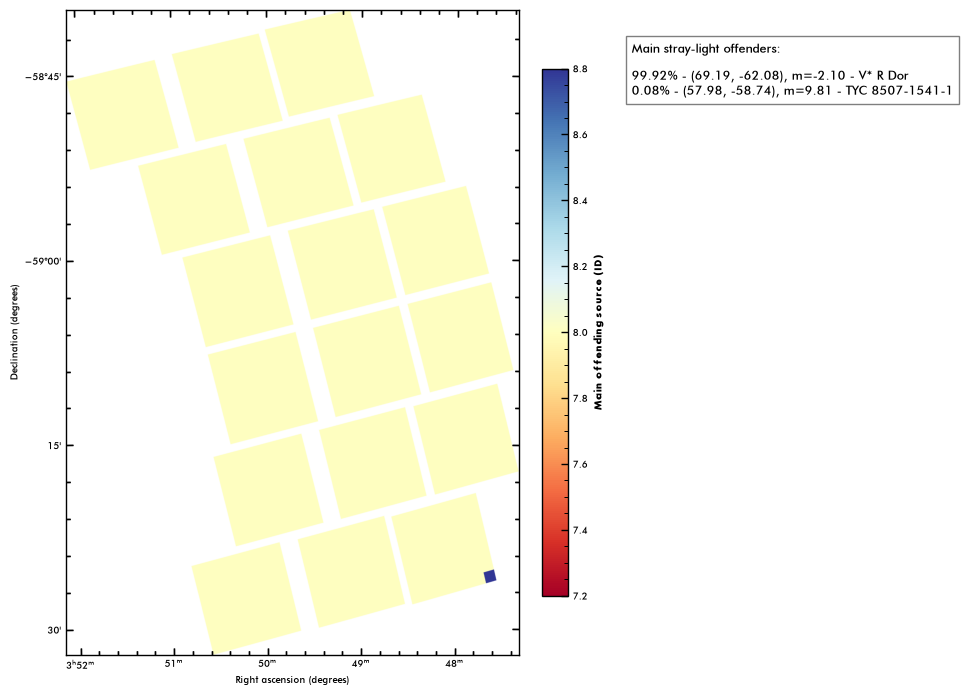

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


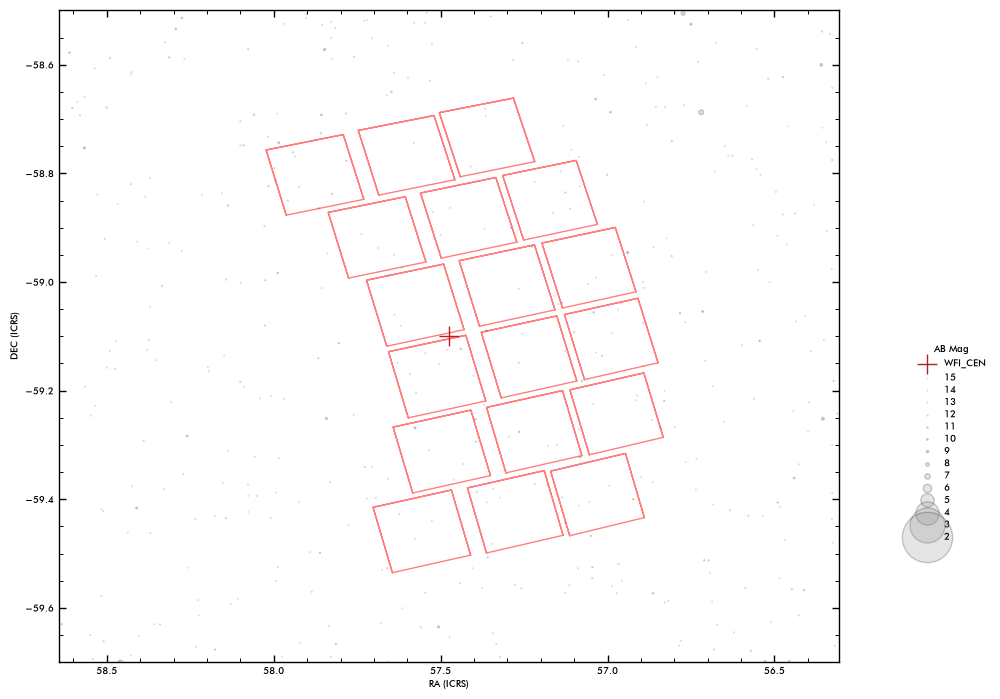

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196851]
Unique IDs with counts > 1:
[     8 196851]
V* R Dor
TYC 8507-1541-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.98, -58.74), m=9.81 - TYC 8507-1541-1
2026-10-24T14:11:58.207498 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_034_Roman_RA_057.476_DEC_-59.099_MJD_61352.00000_PA_104.44_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_034_Roman_RA_057.476_DEC_-59.099_MJD_61352.00000_PA_104.44_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:12:14.669780 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:12:14 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:12:16 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T14:13:09.731779 > Done.


18it [00:03,  4.92it/s]

2026-10-24T14:13:13.403393 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:47<00:00,  2.61s/it]


2026-10-24T14:14:01.415340 > Done : 0:00:48.011962 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:14:02.446746 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:14:11.757819 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


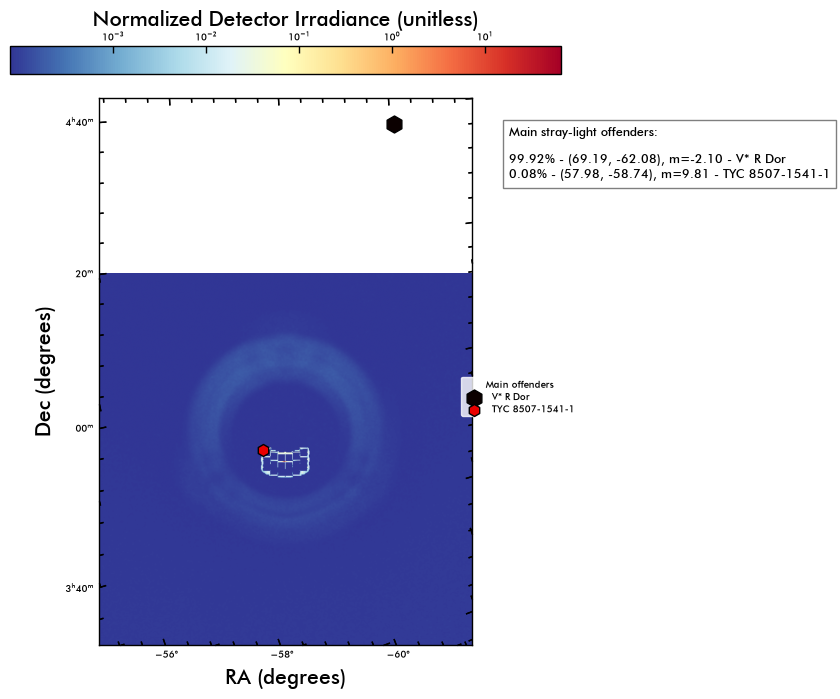

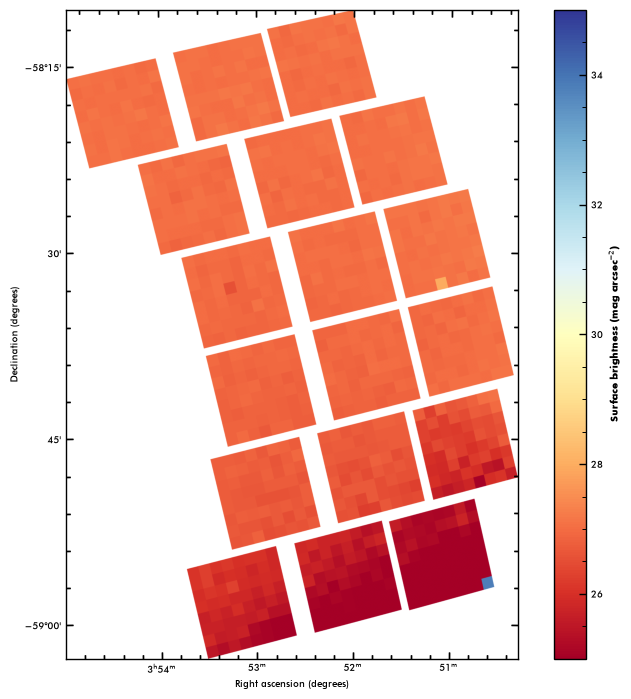

Plot: Stray-light surface brightness flux.
0.0066508986
0.048932955


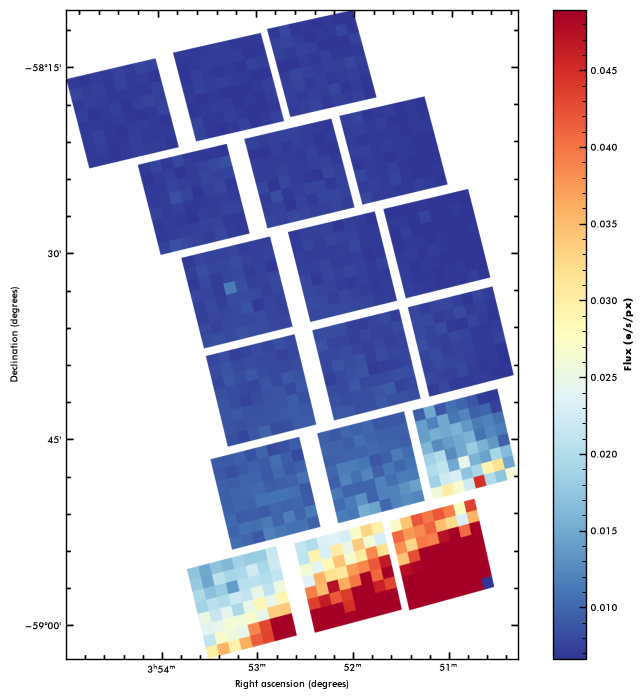

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196931 196948]
Unique IDs with counts > 1:
[     8 196931 196948]
V* R Dor
Simbad cannot find the name of the offender at 58.541924 - -58.476765
UCAC4 156-003596
Main stray-light offenders:

99.74% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (58.14, -59.00), m=12.48 - UCAC4 156-003596
0.08% - (58.54, -58.48), m=12.22 - CAT_ID_196931


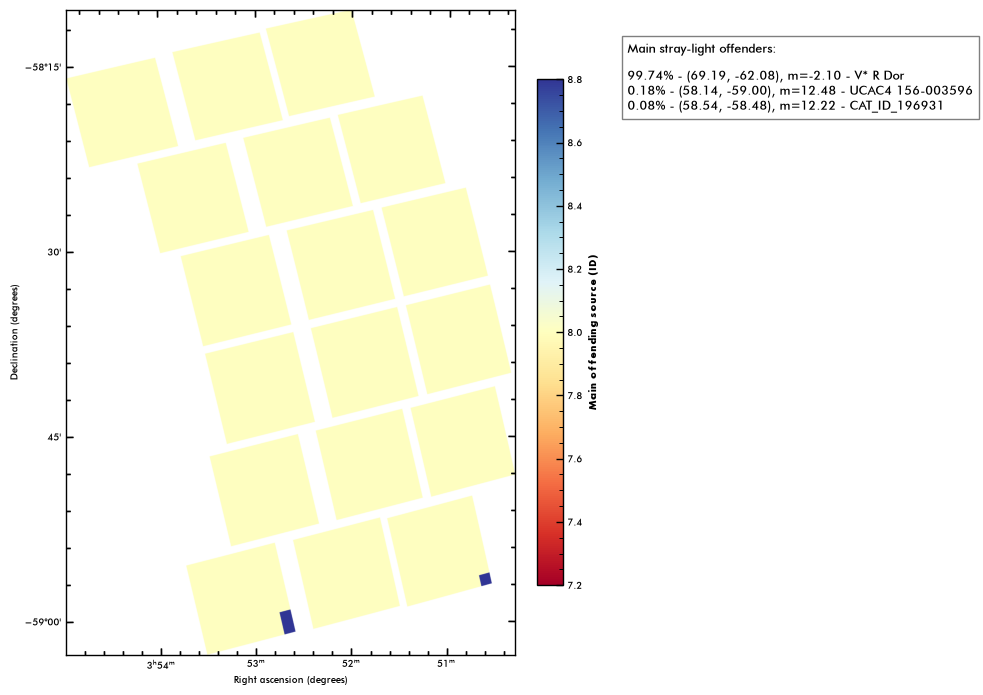

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


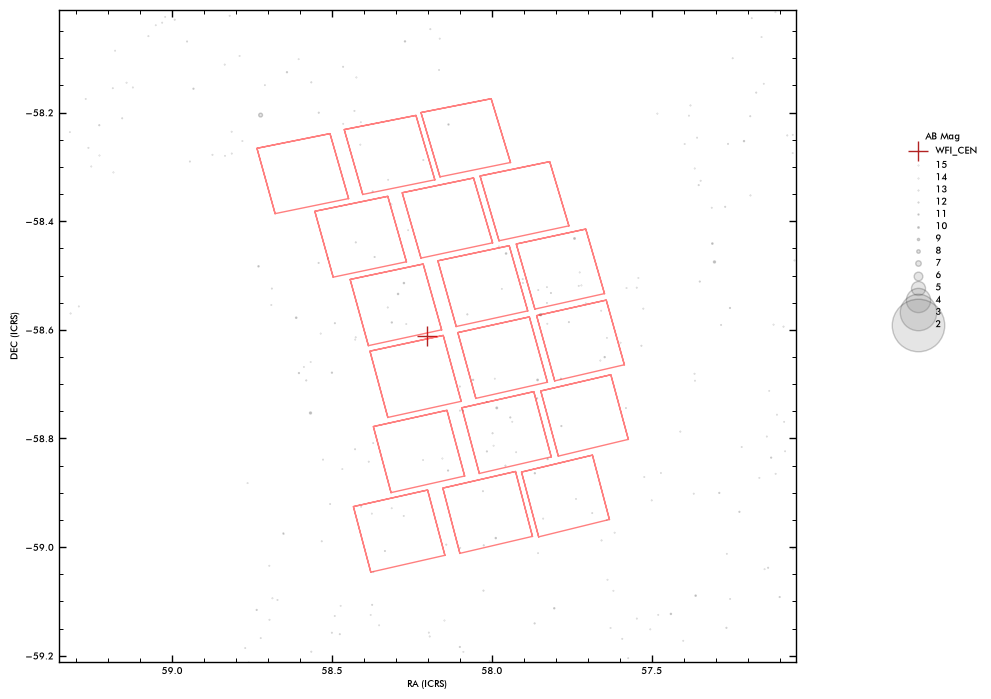

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196931 196948]
Unique IDs with counts > 1:
[     8 196931 196948]
V* R Dor
Simbad cannot find the name of the offender at 58.541924 - -58.476765
UCAC4 156-003596
Main stray-light offenders:

99.74% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (58.14, -59.00), m=12.48 - UCAC4 156-003596
0.08% - (58.54, -58.48), m=12.22 - CAT_ID_196931
2026-10-24T14:14:22.545526 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_035_Roman_RA_058.202_DEC_-58.611_MJD_61352.00000_PA_103.79_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_035_Roman_RA_058.202_DEC_-58.611_MJD_61352.00000_PA_103.79_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:14:39.208453 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be pa

2026-10-24 14:14:39 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

2026-10-24 14:14:40 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T14:15:31.916135 > Done.


18it [00:03,  5.20it/s]

2026-10-24T14:15:35.387114 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.55s/it]


2026-10-24T14:16:22.176693 > Done : 0:00:46.789599 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:16:23.194013 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:16:32.427082 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


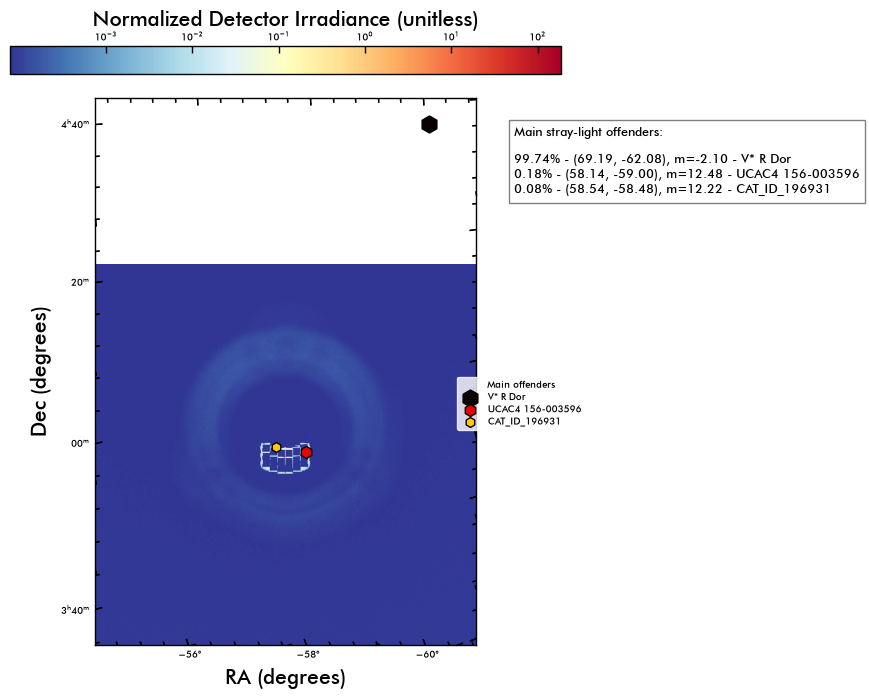

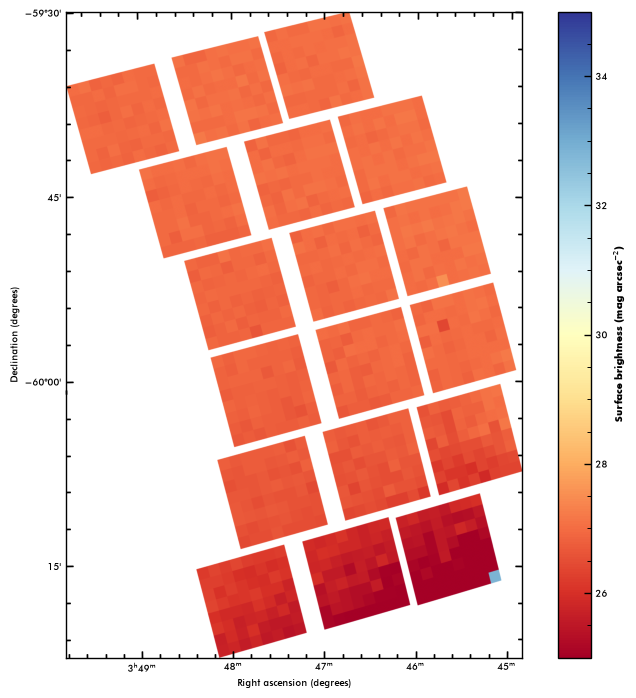

Plot: Stray-light surface brightness flux.
0.0068252455
0.035882737


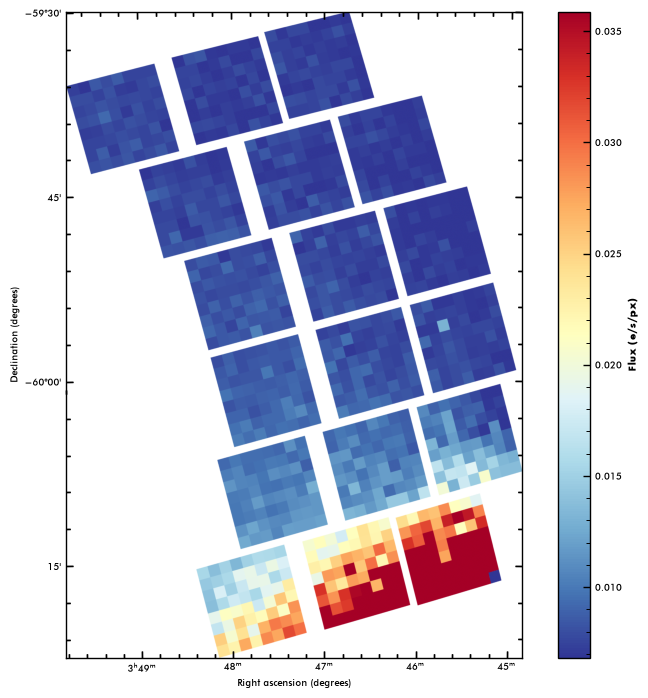

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8    418 196775]
Unique IDs with counts > 1:
[     8    418 196775]
V* R Dor
Simbad cannot find the name of the offender at 59.68411 - -61.39412
CD-60   775
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.68, -61.39), m=2.24 - CAT_ID_418
0.08% - (56.50, -59.74), m=9.30 - CD-60   775


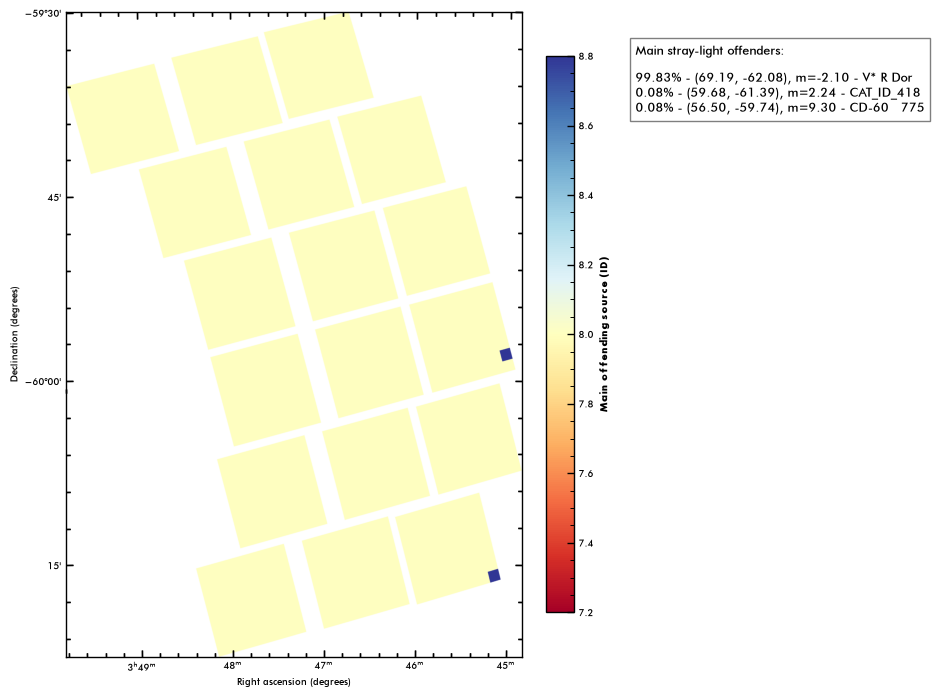

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


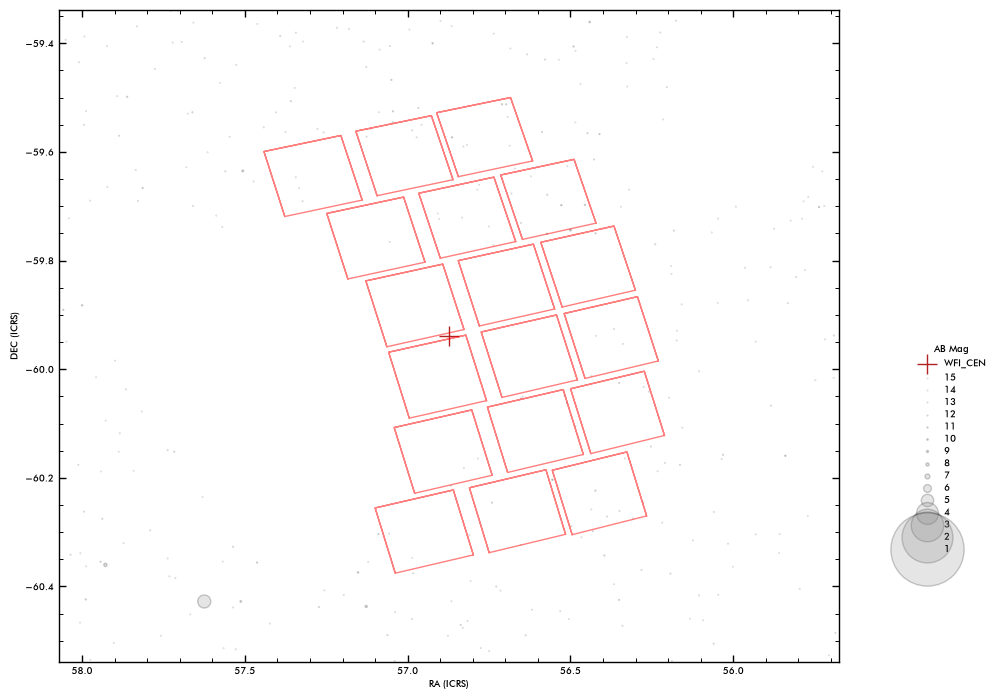

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8    418 196775]
Unique IDs with counts > 1:
[     8    418 196775]
V* R Dor
Simbad cannot find the name of the offender at 59.68411 - -61.39412
CD-60   775
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (59.68, -61.39), m=2.24 - CAT_ID_418
0.08% - (56.50, -59.74), m=9.30 - CD-60   775
2026-10-24T14:16:41.168380 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_036_Roman_RA_056.874_DEC_-59.939_MJD_61352.00000_PA_105.02_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_036_Roman_RA_056.874_DEC_-59.939_MJD_61352.00000_PA_105.02_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:16:57.558508 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying G

2026-10-24 14:16:57 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 14:16:59 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⡿
2026-10-24T14:18:02.664404 > Done.


18it [00:03,  5.19it/s]

2026-10-24T14:18:06.138648 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:44<00:00,  2.50s/it]


2026-10-24T14:18:52.061817 > Done : 0:00:45.923192 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:18:53.089796 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:19:02.280954 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


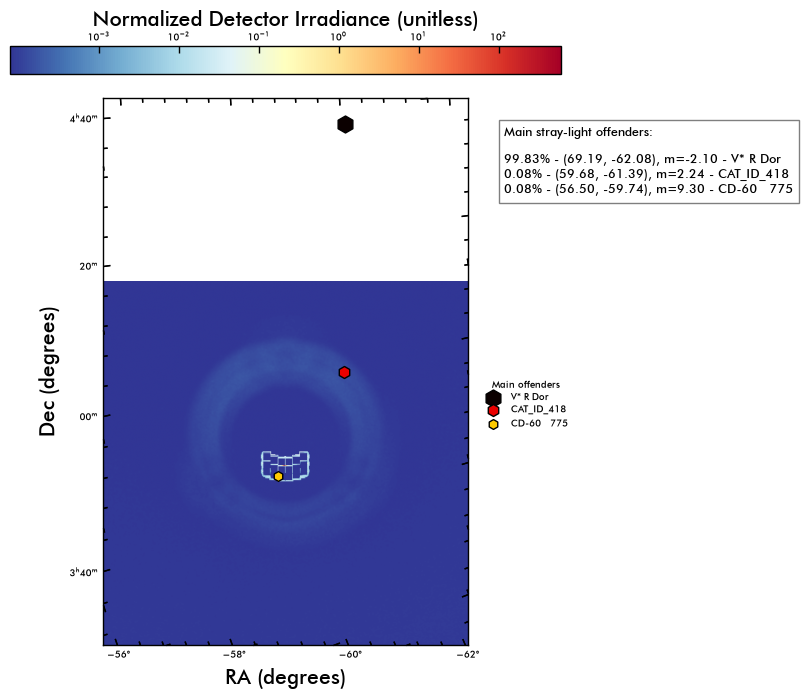

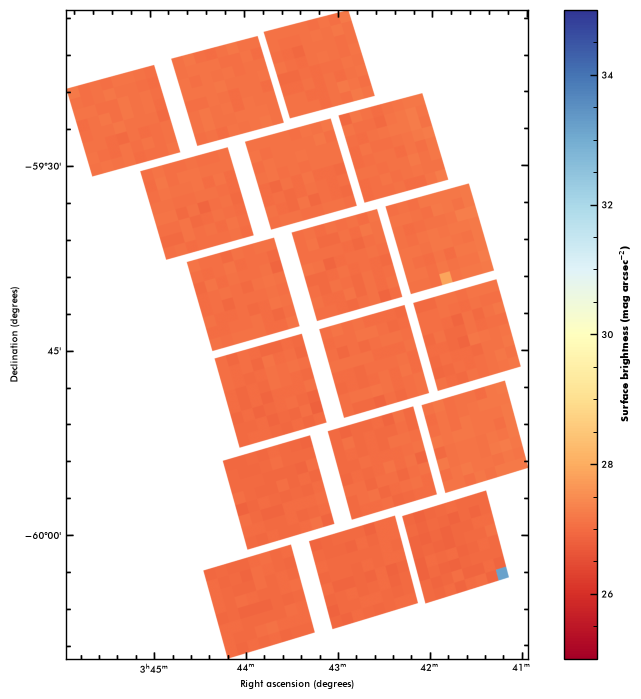

Plot: Stray-light surface brightness flux.
0.006416864
0.008071262


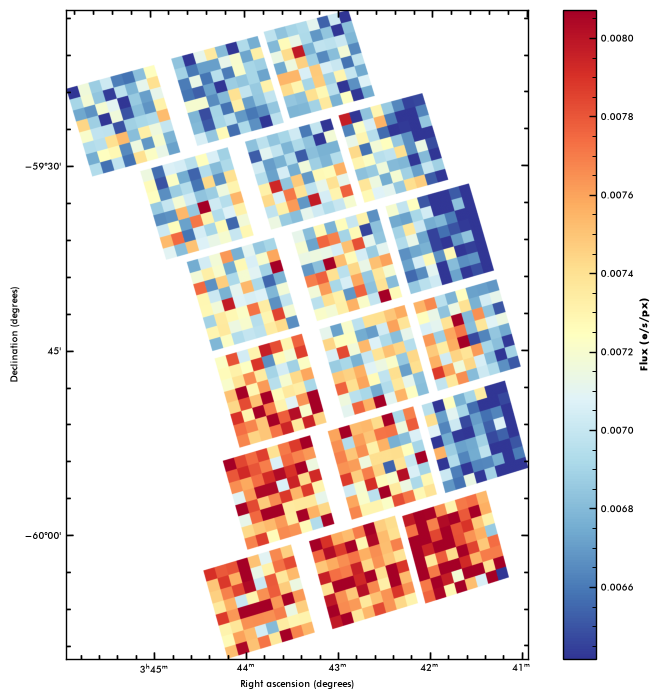

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196845]
Unique IDs with counts > 1:
[     8 196845]
V* R Dor
UCAC2   5740264
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (56.44, -59.36), m=9.99 - UCAC2   5740264


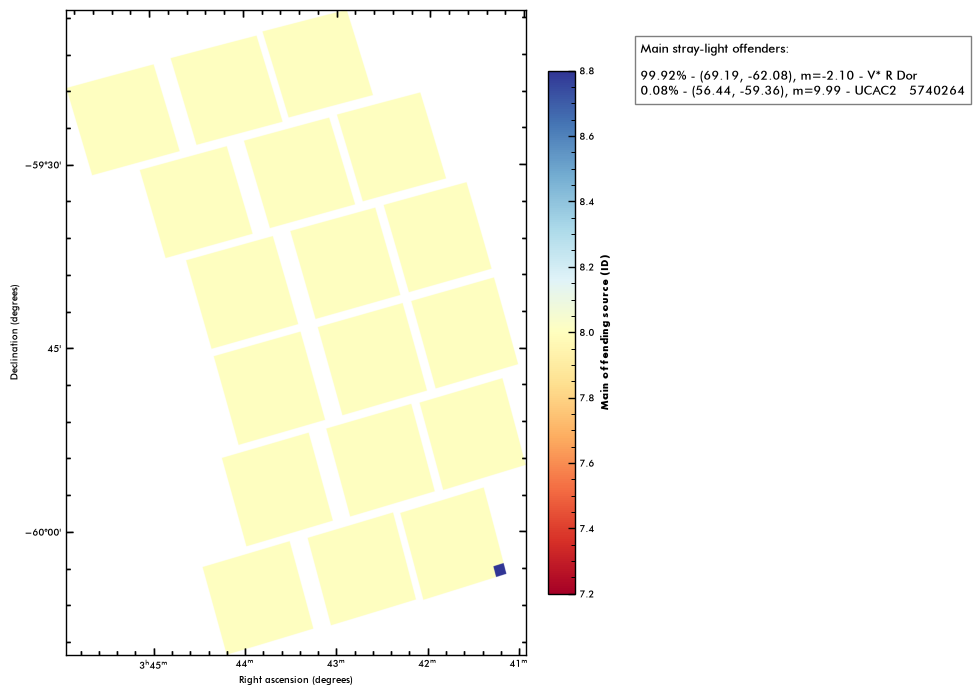

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


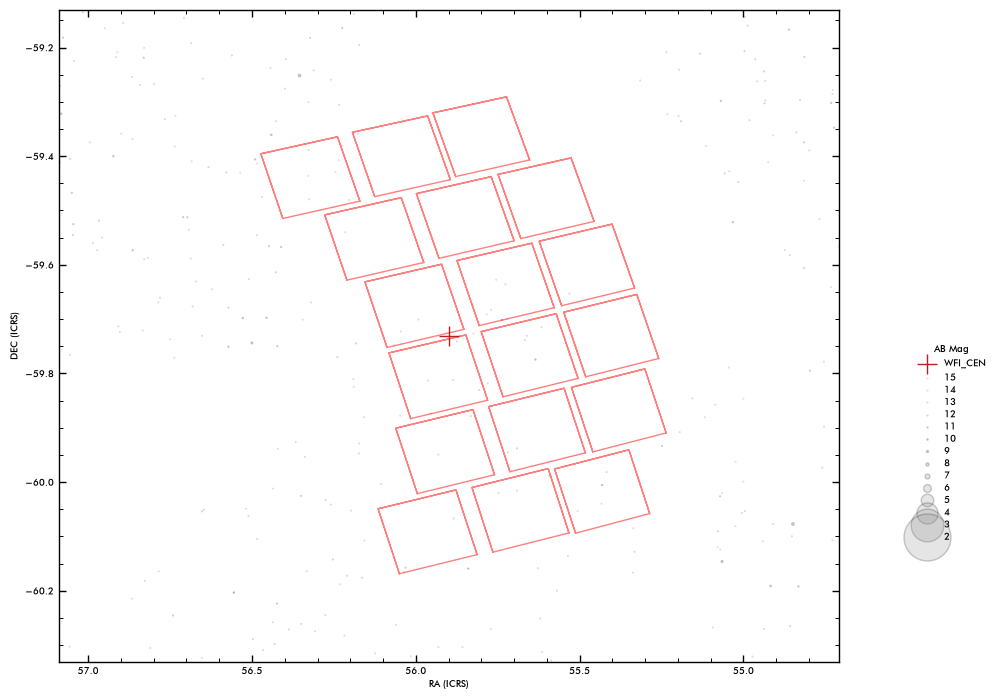

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196845]
Unique IDs with counts > 1:
[     8 196845]
V* R Dor
UCAC2   5740264
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (56.44, -59.36), m=9.99 - UCAC2   5740264
2026-10-24T14:19:10.764634 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_037_Roman_RA_055.899_DEC_-59.731_MJD_61352.00000_PA_105.84_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_037_Roman_RA_055.899_DEC_-59.731_MJD_61352.00000_PA_105.84_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:19:27.115394 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:19:27 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

2026-10-24 14:19:28 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T14:20:23.839648 > Done.


18it [00:03,  5.01it/s]

2026-10-24T14:20:27.446709 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.53s/it]


2026-10-24T14:21:14.022808 > Done : 0:00:46.576117 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:21:15.007667 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:21:24.183828 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


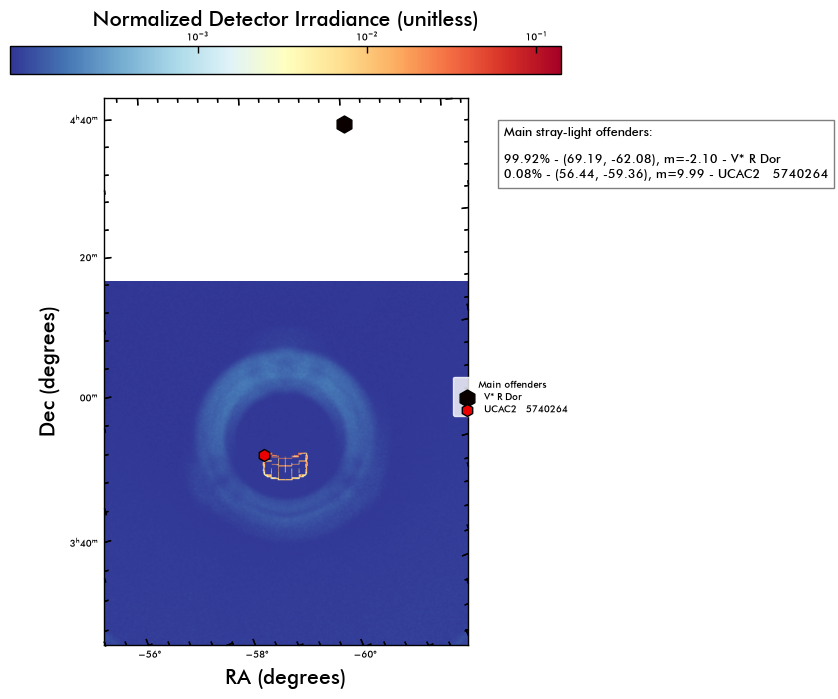

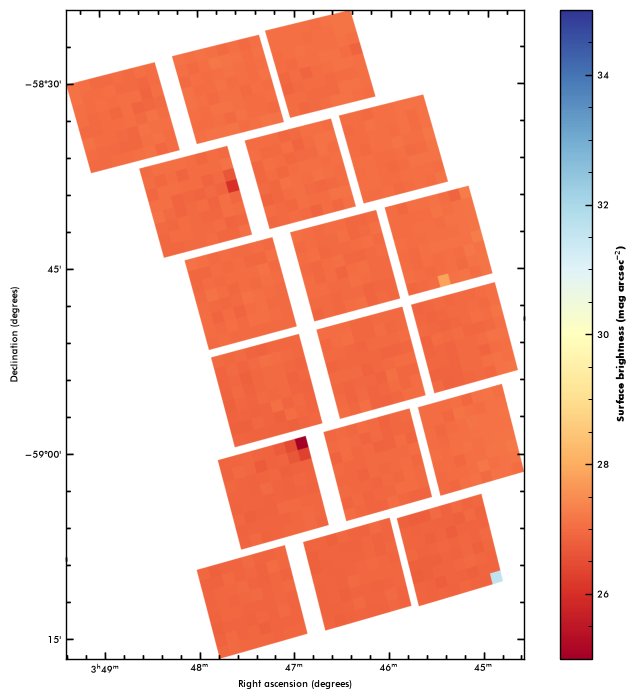

Plot: Stray-light surface brightness flux.
0.0068341424
0.008597148


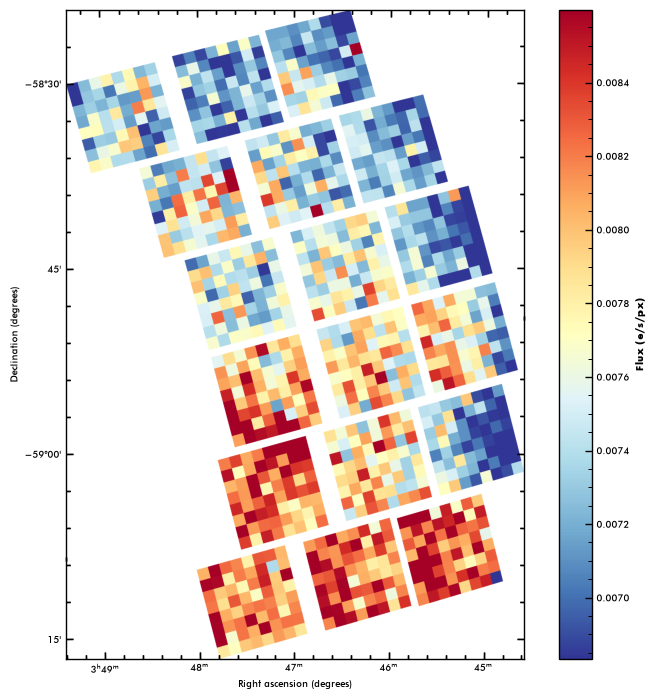

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196731 197080 197238]
Unique IDs with counts > 1:
[     8 196731 197080 197238]
V* R Dor
CD-59   708
Simbad cannot find the name of the offender at 56.704357 - -58.981518
Simbad cannot find the name of the offender at 56.885777 - -58.634266
Main stray-light offenders:

99.47% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (56.70, -58.98), m=13.31 - CAT_ID_197080
0.18% - (56.89, -58.63), m=14.14 - CAT_ID_197238
0.08% - (56.94, -58.95), m=9.22 - CD-59   708


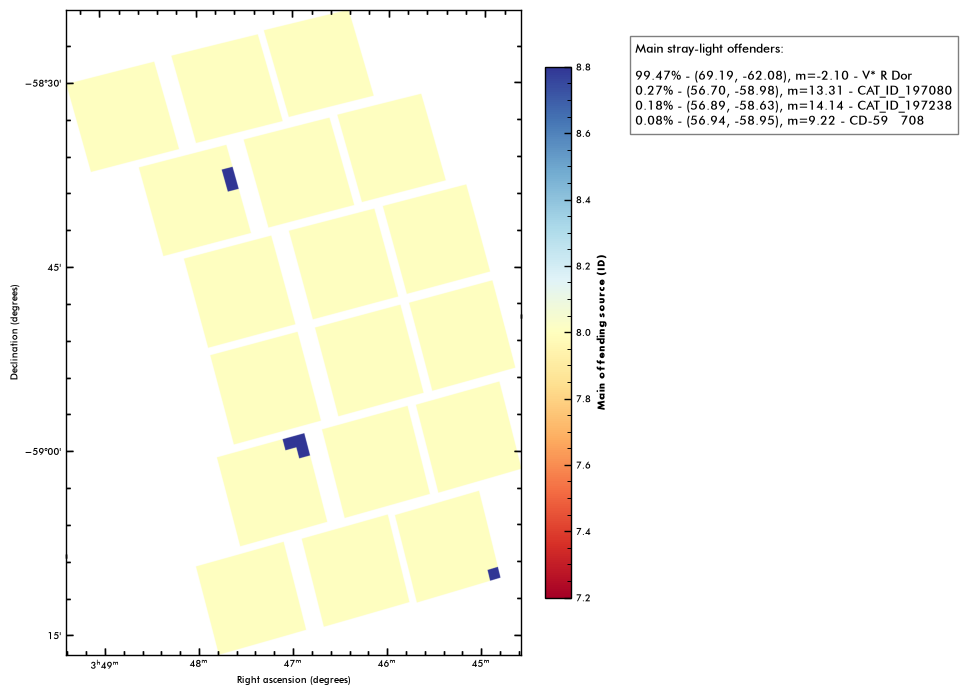

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


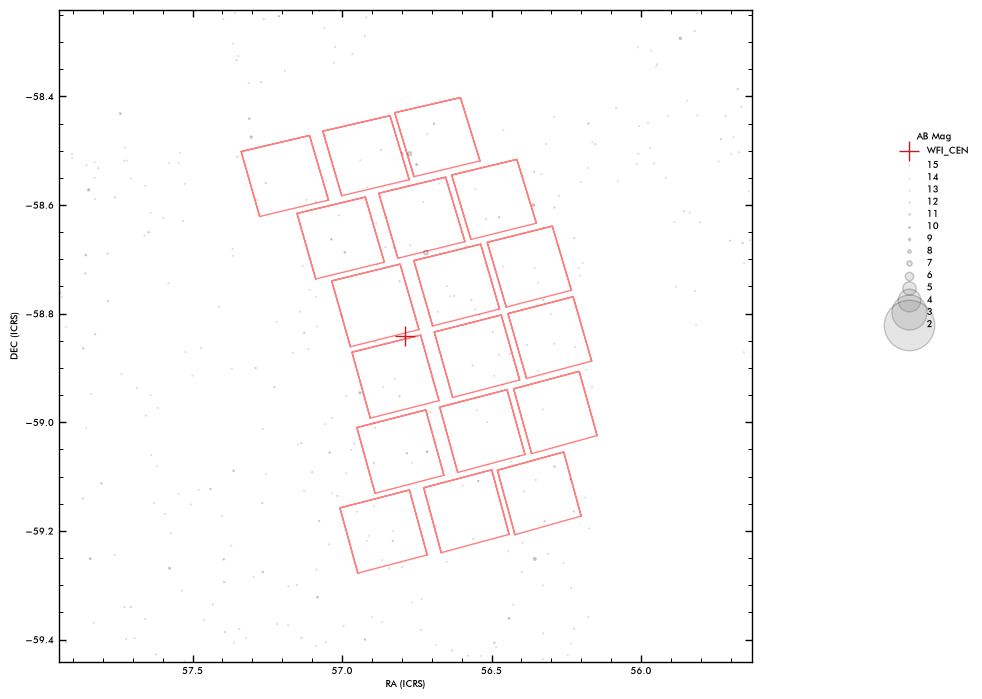

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196731 197080 197238]
Unique IDs with counts > 1:
[     8 196731 197080 197238]
V* R Dor
CD-59   708
Simbad cannot find the name of the offender at 56.704357 - -58.981518
Simbad cannot find the name of the offender at 56.885777 - -58.634266
Main stray-light offenders:

99.47% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (56.70, -58.98), m=13.31 - CAT_ID_197080
0.18% - (56.89, -58.63), m=14.14 - CAT_ID_197238
0.08% - (56.94, -58.95), m=9.22 - CD-59   708
2026-10-24T14:21:33.108253 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_038_Roman_RA_056.788_DEC_-58.841_MJD_61352.00000_PA_105.01_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_038_Roman_RA_056.788_DEC_-58.841_MJD_61352.00000_PA_105.01_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:21:49.369446 > Fetching source catalog
INFO: radius parameter (minimum distance to searc

2026-10-24 14:21:49 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

2026-10-24 14:21:51 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T14:22:45.414857 > Done.


18it [00:03,  5.05it/s]

2026-10-24T14:22:48.985114 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:48<00:00,  2.68s/it]


2026-10-24T14:23:38.325824 > Done : 0:00:49.340728 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:23:39.385858 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:23:49.725120 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


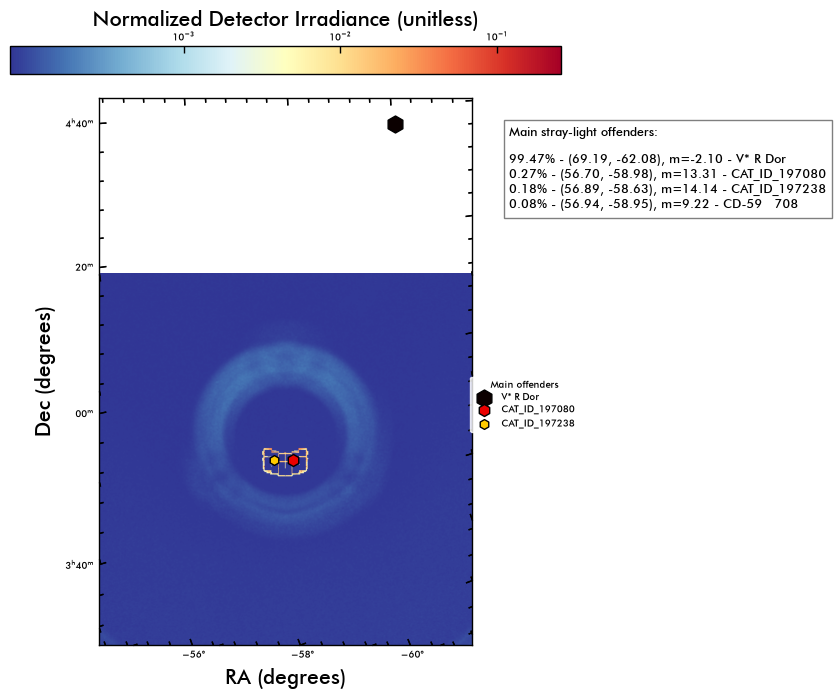

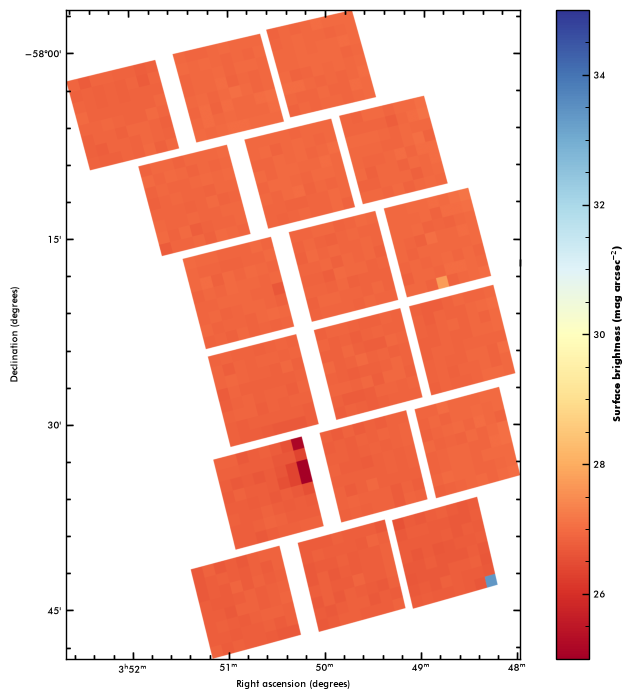

Plot: Stray-light surface brightness flux.
0.0075772353
0.009691557


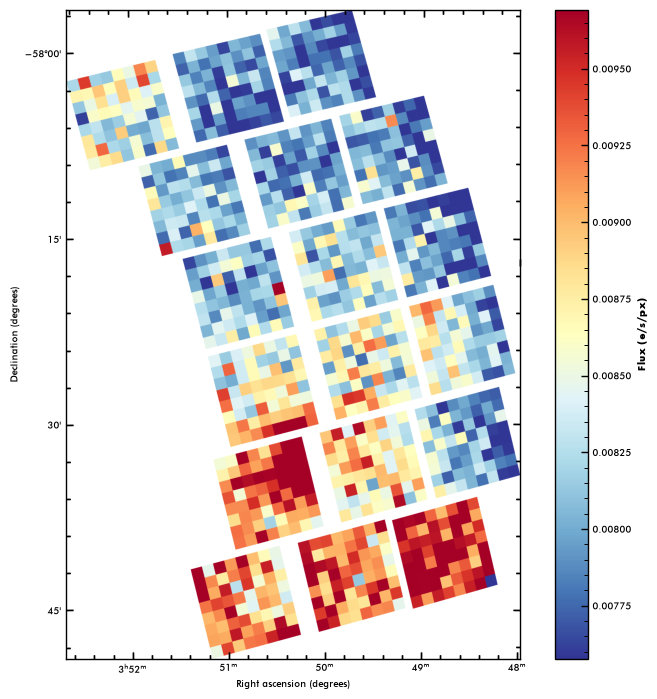

Plot: Main offender map.
8.0
842.0
Unique IDs:
[     8    842 196741 197052 197064]
Unique IDs with counts > 1:
[     8    842 196741 197052 197064]
V* R Dor
Simbad cannot find the name of the offender at 56.058414 - -64.80945
TYC 8506-887-1
Simbad cannot find the name of the offender at 57.52643 - -58.56096
Simbad cannot find the name of the offender at 57.54698 - -58.52235
Main stray-light offenders:

89.81% - (69.19, -62.08), m=-2.10 - V* R Dor
9.39% - (56.06, -64.81), m=2.77 - CAT_ID_842
0.44% - (57.53, -58.56), m=13.31 - CAT_ID_197052
0.27% - (57.55, -58.52), m=13.39 - CAT_ID_197064
0.08% - (57.30, -58.47), m=9.23 - TYC 8506-887-1


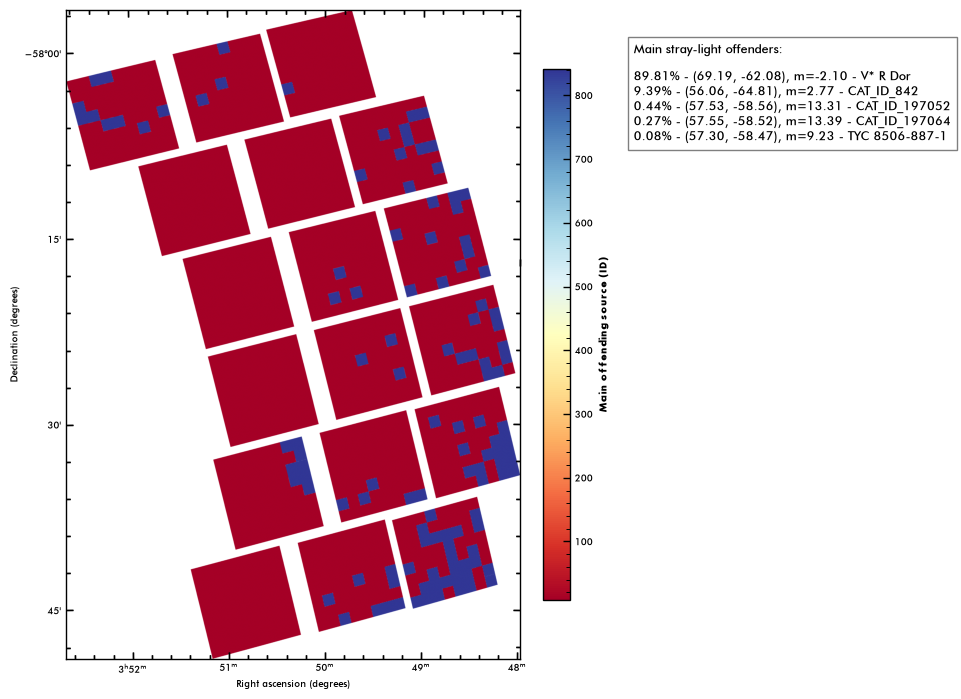

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


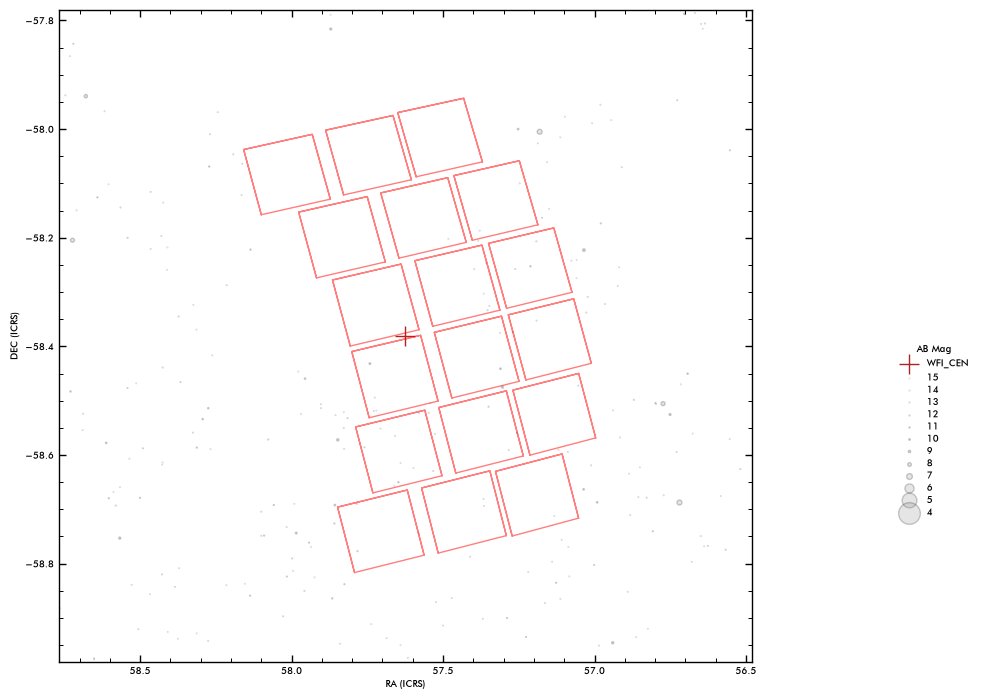

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8    842 196741 197052 197064]
Unique IDs with counts > 1:
[     8    842 196741 197052 197064]
V* R Dor
Simbad cannot find the name of the offender at 56.058414 - -64.80945
TYC 8506-887-1
Simbad cannot find the name of the offender at 57.52643 - -58.56096
Simbad cannot find the name of the offender at 57.54698 - -58.52235
Main stray-light offenders:

89.81% - (69.19, -62.08), m=-2.10 - V* R Dor
9.39% - (56.06, -64.81), m=2.77 - CAT_ID_842
0.44% - (57.53, -58.56), m=13.31 - CAT_ID_197052
0.27% - (57.55, -58.52), m=13.39 - CAT_ID_197064
0.08% - (57.30, -58.47), m=9.23 - TYC 8506-887-1
2026-10-24T14:23:59.600041 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_039_Roman_RA_057.624_DEC_-58.381_MJD_61352.00000_PA_104.27_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_039_Roman_RA_057.624_DEC_-58.381_MJD_61352.00000_PA_104.27_stray.pdf
> S

2026-10-24 14:24:17 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 14:24:18 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿INFO: Done. [astroquery.utils.tap.core]


...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⢿
2026-10-24T14:25:07.035685 > Done.


18it [00:03,  4.89it/s]

2026-10-24T14:25:10.726152 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:47<00:00,  2.62s/it]


2026-10-24T14:25:58.913199 > Done : 0:00:48.187063 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:25:59.928176 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:26:09.466943 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


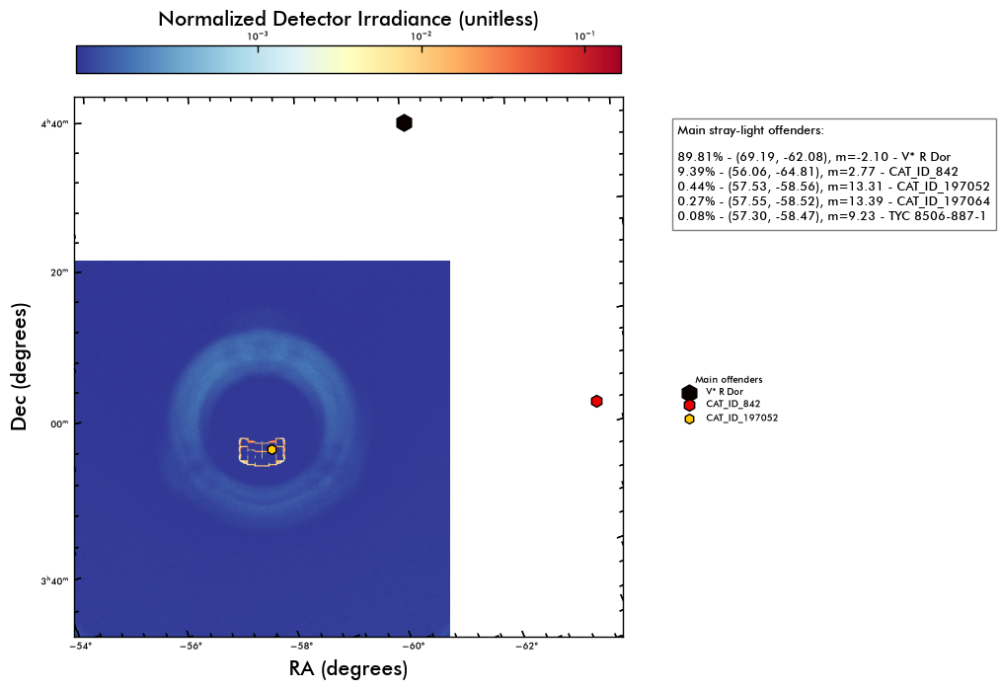

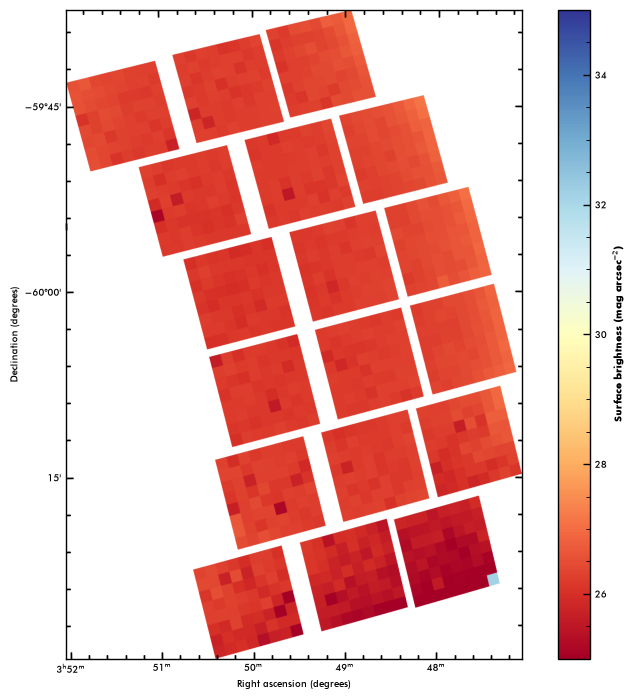

Plot: Stray-light surface brightness flux.
0.010292631
0.032708142


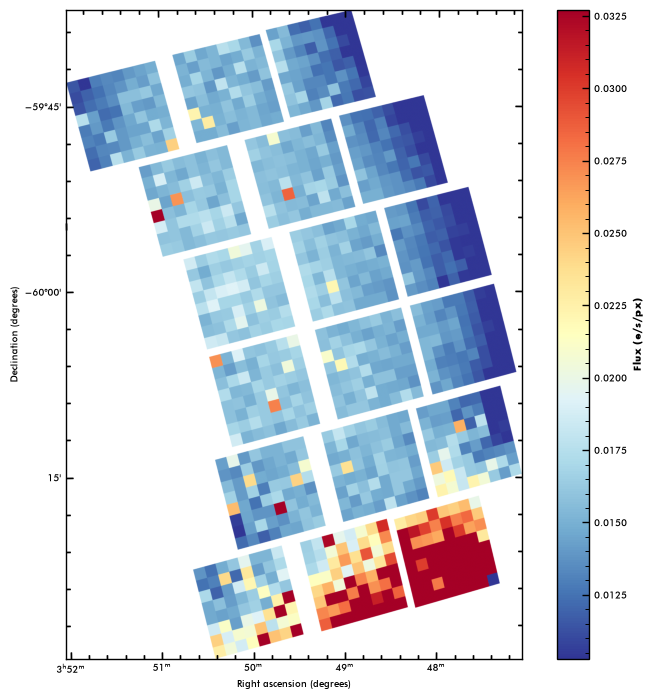

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196818]
Unique IDs with counts > 1:
[     8 196818]
V* R Dor
CD-60   800
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.51, -59.63), m=9.42 - CD-60   800


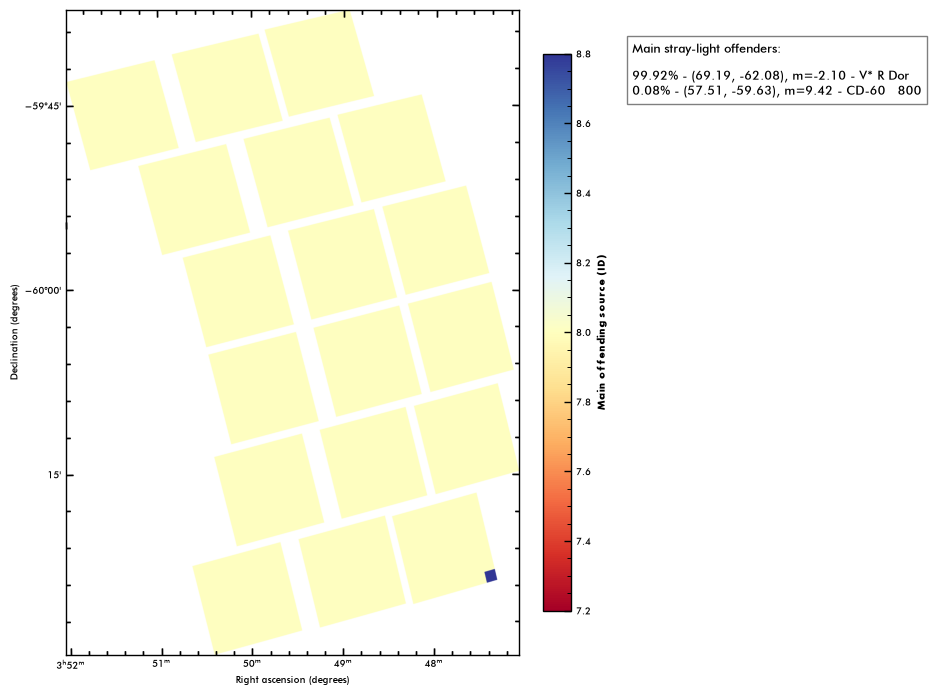

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


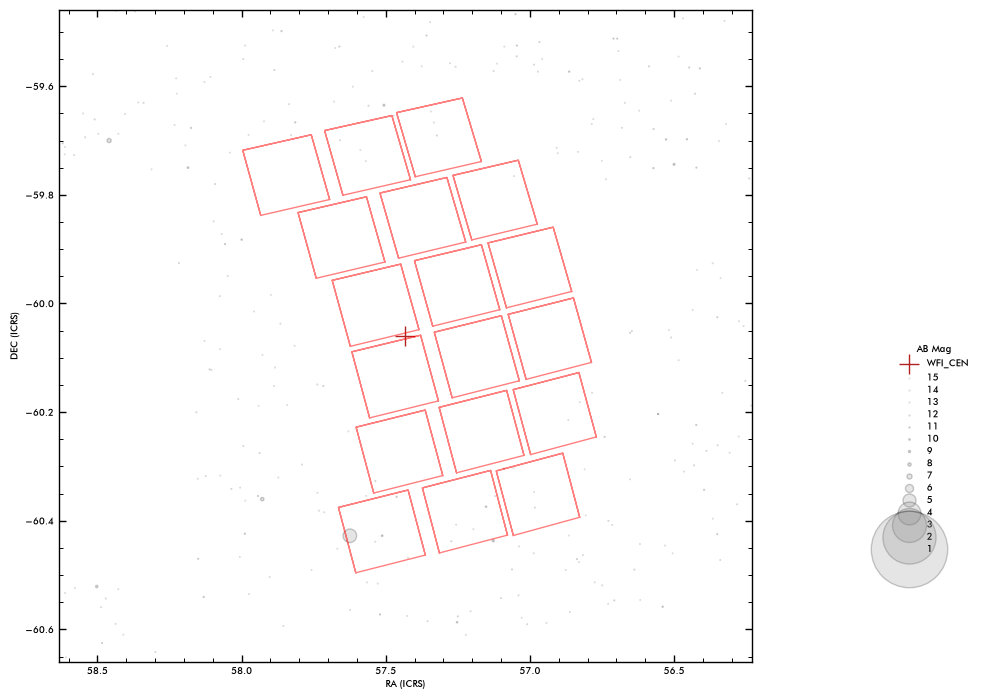

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196818]
Unique IDs with counts > 1:
[     8 196818]
V* R Dor
CD-60   800
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.51, -59.63), m=9.42 - CD-60   800
2026-10-24T14:26:18.154788 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_040_Roman_RA_057.432_DEC_-60.060_MJD_61352.00000_PA_104.56_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_040_Roman_RA_057.432_DEC_-60.060_MJD_61352.00000_PA_104.56_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:26:34.967151 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:26:34 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 14:26:36 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T14:27:24.860714 > Done.


18it [00:03,  4.85it/s]

2026-10-24T14:27:28.586065 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.51s/it]


2026-10-24T14:28:14.849662 > Done : 0:00:46.263615 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:28:15.871065 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:28:25.305072 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


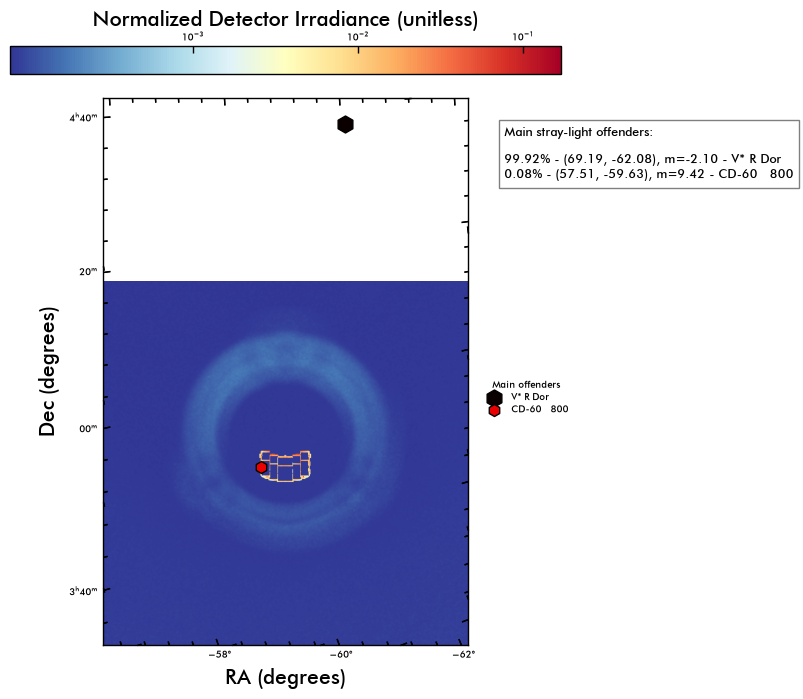

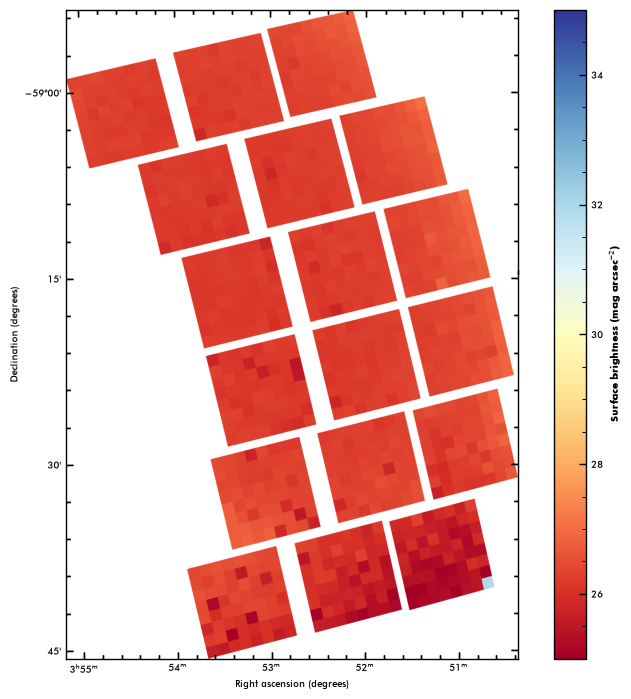

Plot: Stray-light surface brightness flux.
0.01037365
0.027824339


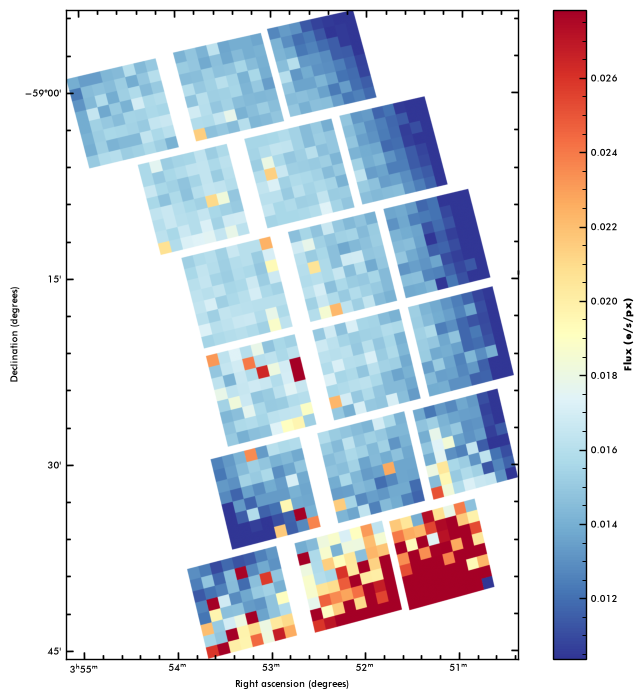

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 148589 197121 197170]
Unique IDs with counts > 1:
[     8 148589 197121 197170]
V* R Dor
CD-60   812
Simbad cannot find the name of the offender at 58.152866 - -59.369957
Simbad cannot find the name of the offender at 58.1082 - -59.58285
Main stray-light offenders:

99.65% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (58.15, -59.37), m=14.07 - CAT_ID_197121
0.09% - (58.11, -59.58), m=14.31 - CAT_ID_197170
0.08% - (58.46, -59.70), m=7.49 - CD-60   812


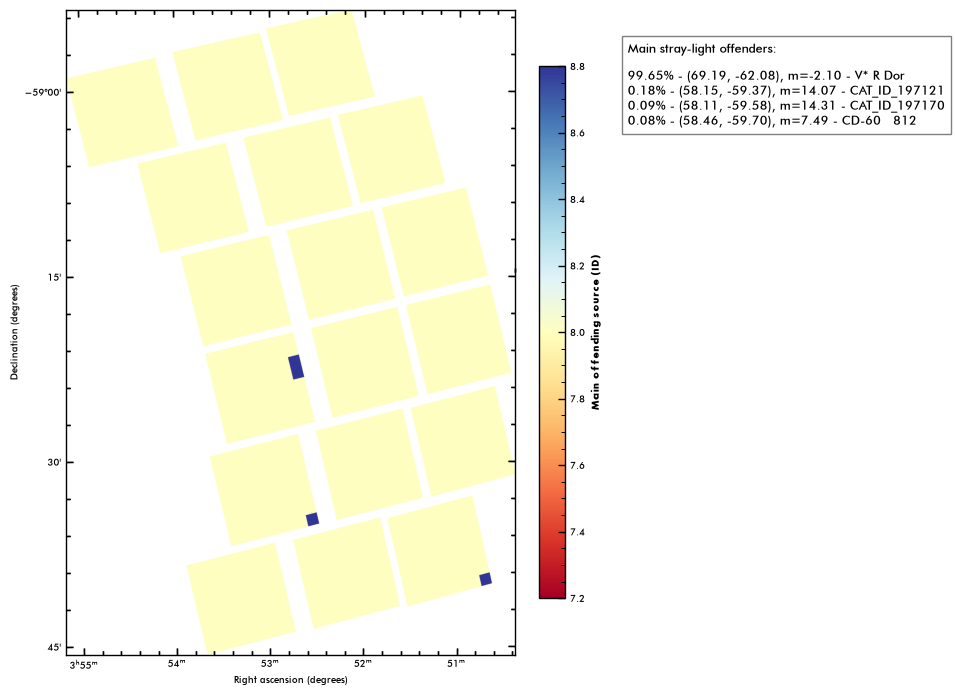

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


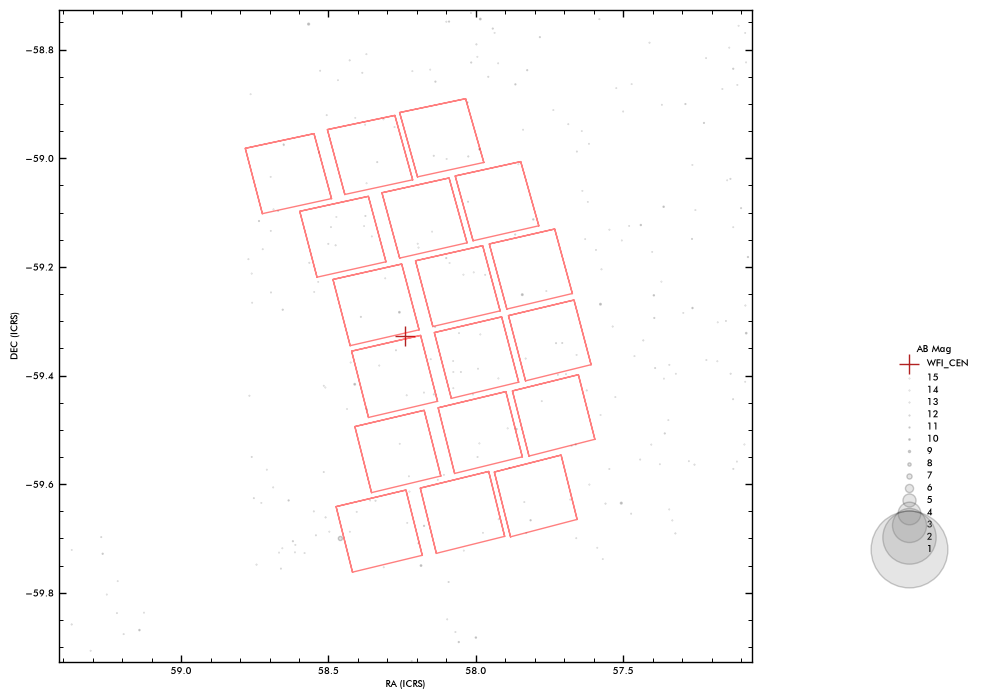

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 148589 197121 197170]
Unique IDs with counts > 1:
[     8 148589 197121 197170]
V* R Dor
CD-60   812
Simbad cannot find the name of the offender at 58.152866 - -59.369957
Simbad cannot find the name of the offender at 58.1082 - -59.58285
Main stray-light offenders:

99.65% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (58.15, -59.37), m=14.07 - CAT_ID_197121
0.09% - (58.11, -59.58), m=14.31 - CAT_ID_197170
0.08% - (58.46, -59.70), m=7.49 - CD-60   812
2026-10-24T14:28:34.328589 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_041_Roman_RA_058.239_DEC_-59.327_MJD_61352.00000_PA_103.81_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_041_Roman_RA_058.239_DEC_-59.327_MJD_61352.00000_PA_103.81_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:28:51.083805 > Fetching source catalog
INFO: radius parameter (minimum distance to search f

2026-10-24 14:28:51 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 14:28:52 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

...

INFO: Query finished. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣽
2026-10-24T14:29:38.879882 > Done.


18it [00:03,  5.06it/s]

2026-10-24T14:29:42.446053 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.59s/it]


2026-10-24T14:30:30.031416 > Done : 0:00:47.585384 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:30:31.020827 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:30:40.319224 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


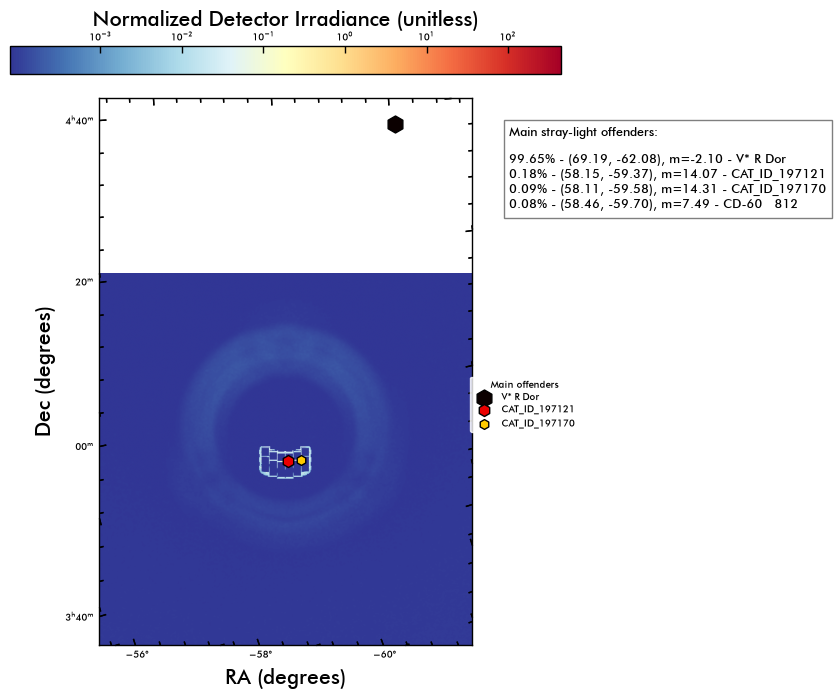

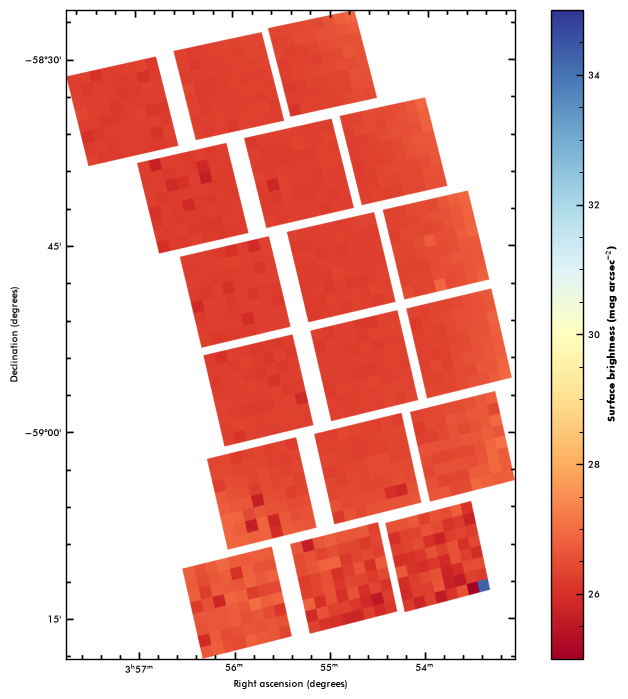

Plot: Stray-light surface brightness flux.
0.009366525
0.018098919


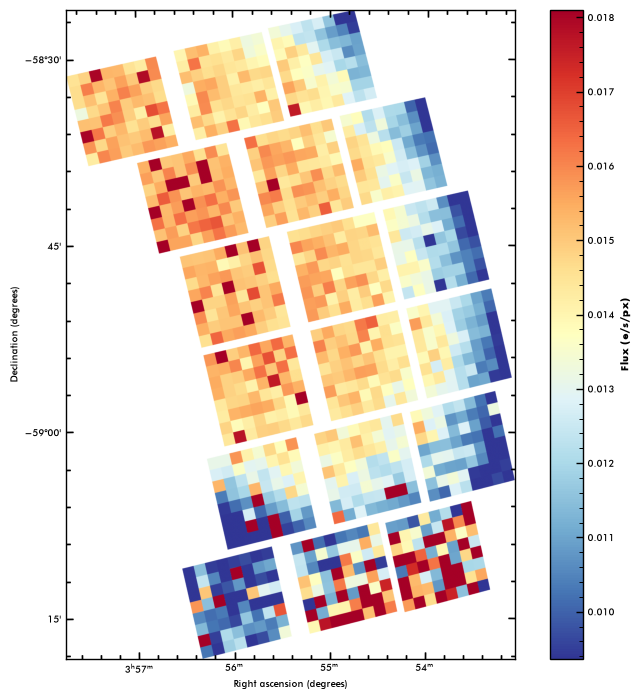

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196884]
Unique IDs with counts > 1:
[     8 196884]
V* R Dor
TYC 8507-973-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (58.66, -59.28), m=11.47 - TYC 8507-973-1


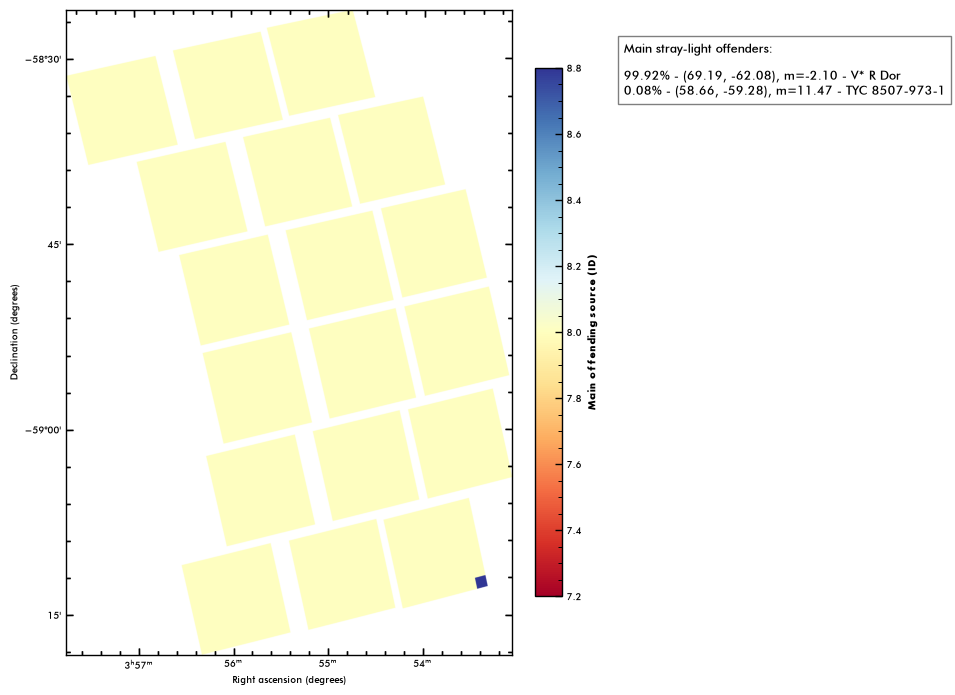

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


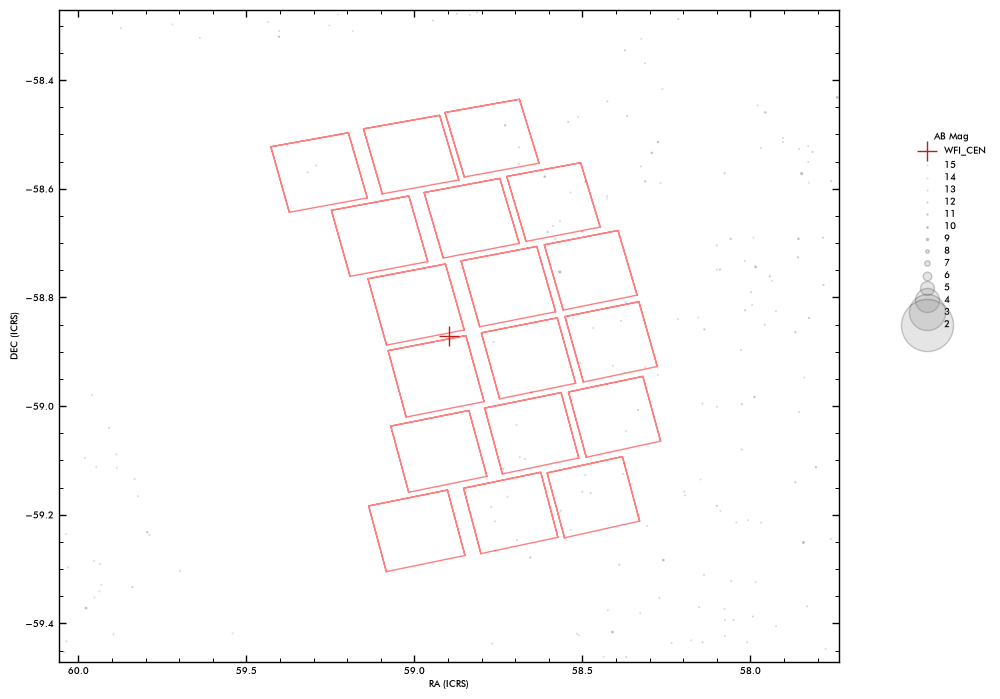

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196884]
Unique IDs with counts > 1:
[     8 196884]
V* R Dor
TYC 8507-973-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (58.66, -59.28), m=11.47 - TYC 8507-973-1
2026-10-24T14:30:48.552086 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_042_Roman_RA_058.898_DEC_-58.871_MJD_61352.00000_PA_103.22_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_042_Roman_RA_058.898_DEC_-58.871_MJD_61352.00000_PA_103.22_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:31:05.159191 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:31:05 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 14:31:06 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣽
2026-10-24T14:31:19.309459 > Done.


18it [00:03,  5.01it/s]

2026-10-24T14:31:22.911742 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.57s/it]


2026-10-24T14:32:10.259396 > Done : 0:00:47.347675 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:32:11.351558 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:32:21.179571 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


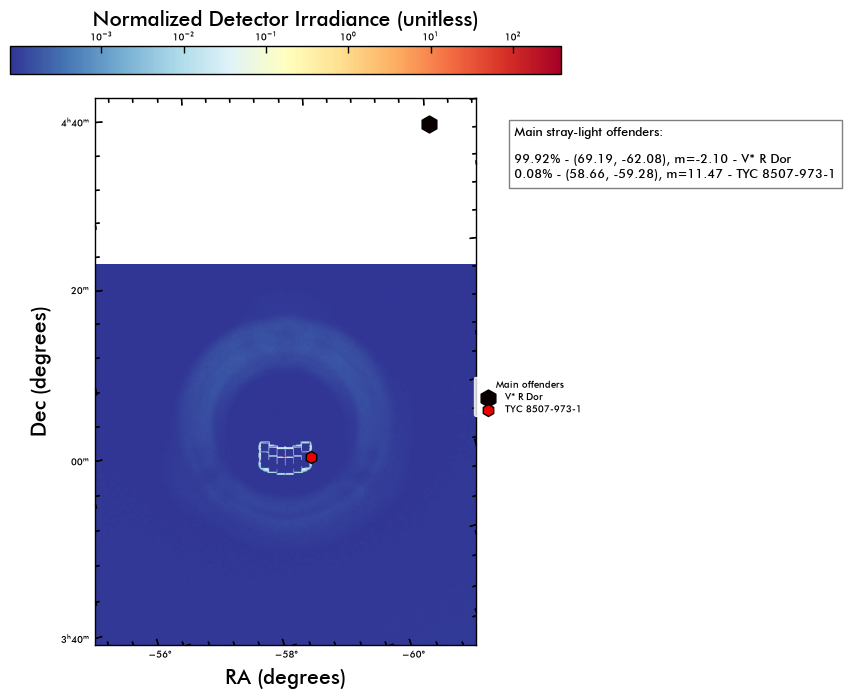

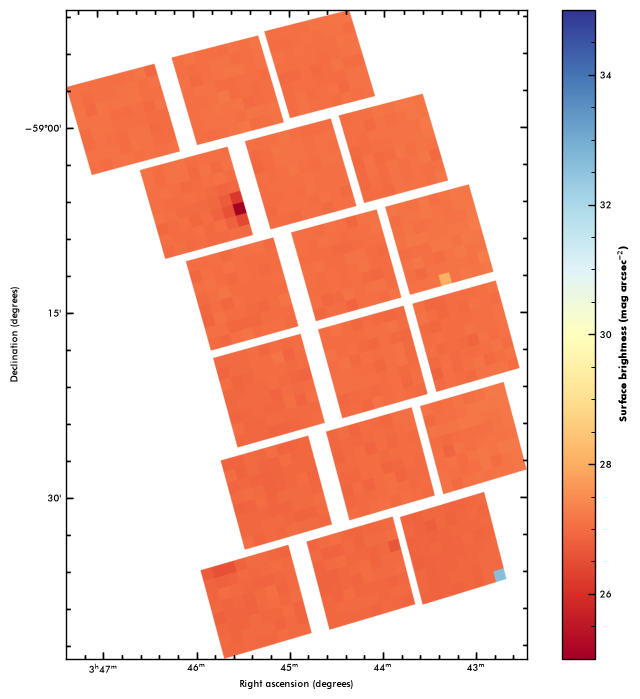

Plot: Stray-light surface brightness flux.
0.0065769157
0.0083319


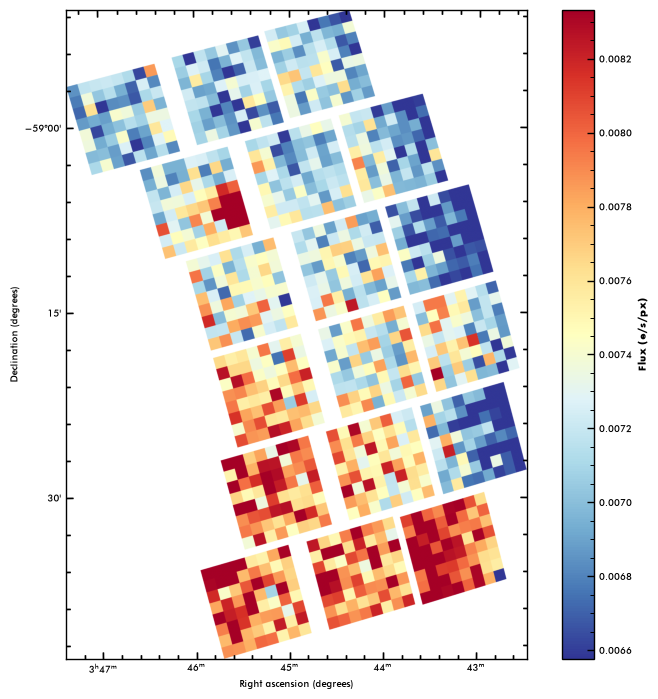

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196849 196877 197011]
Unique IDs with counts > 1:
[     8 196849 196877 197011]
V* R Dor
UCAC2   5740264
UCAC2   5489719
Simbad cannot find the name of the offender at 56.352398 - -59.106236
Main stray-light offenders:

99.20% - (69.19, -62.08), m=-2.10 - V* R Dor
0.44% - (56.35, -59.11), m=13.01 - CAT_ID_197011
0.27% - (56.41, -59.57), m=11.04 - UCAC2   5489719
0.08% - (56.44, -59.36), m=9.99 - UCAC2   5740264


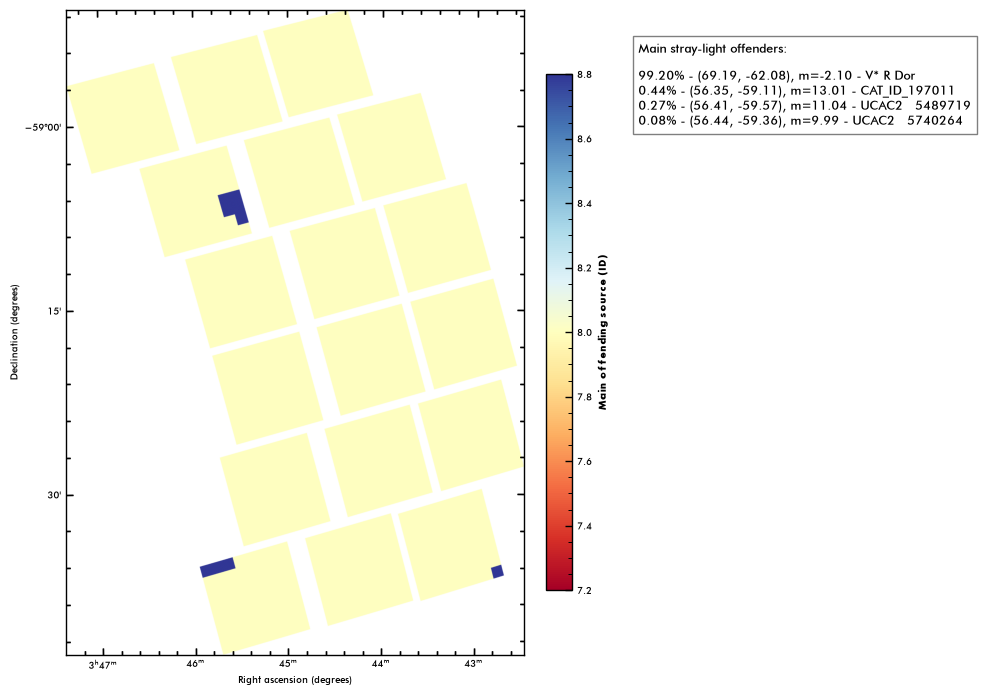

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


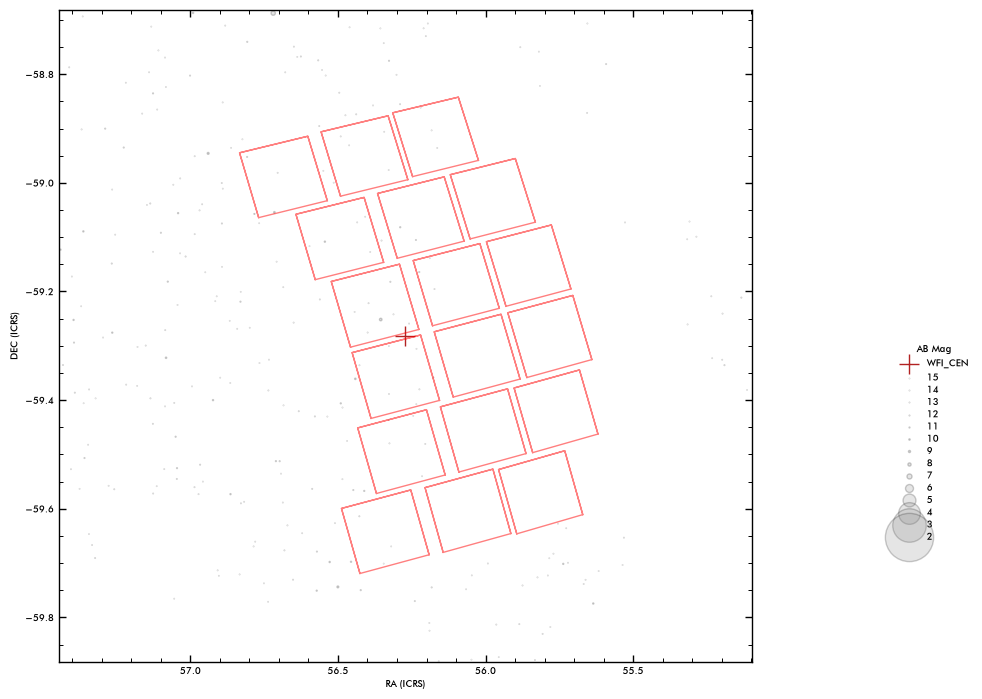

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196849 196877 197011]
Unique IDs with counts > 1:
[     8 196849 196877 197011]
V* R Dor
UCAC2   5740264
UCAC2   5489719
Simbad cannot find the name of the offender at 56.352398 - -59.106236
Main stray-light offenders:

99.20% - (69.19, -62.08), m=-2.10 - V* R Dor
0.44% - (56.35, -59.11), m=13.01 - CAT_ID_197011
0.27% - (56.41, -59.57), m=11.04 - UCAC2   5489719
0.08% - (56.44, -59.36), m=9.99 - UCAC2   5740264
2026-10-24T14:32:30.211243 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_043_Roman_RA_056.271_DEC_-59.282_MJD_61352.00000_PA_105.48_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_043_Roman_RA_056.271_DEC_-59.282_MJD_61352.00000_PA_105.48_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:32:47.261859 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Ga

2026-10-24 14:32:47 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 14:32:48 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣷
2026-10-24T14:33:00.511097 > Done.


18it [00:03,  4.73it/s]

2026-10-24T14:33:04.322322 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:47<00:00,  2.66s/it]


2026-10-24T14:33:53.152271 > Done : 0:00:48.829978 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:33:54.264041 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:34:03.892711 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


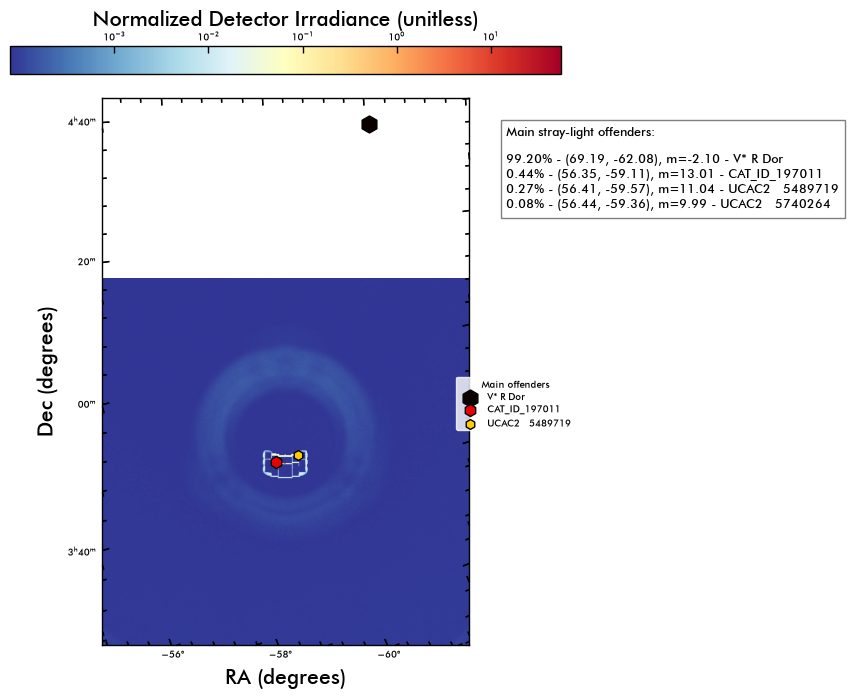

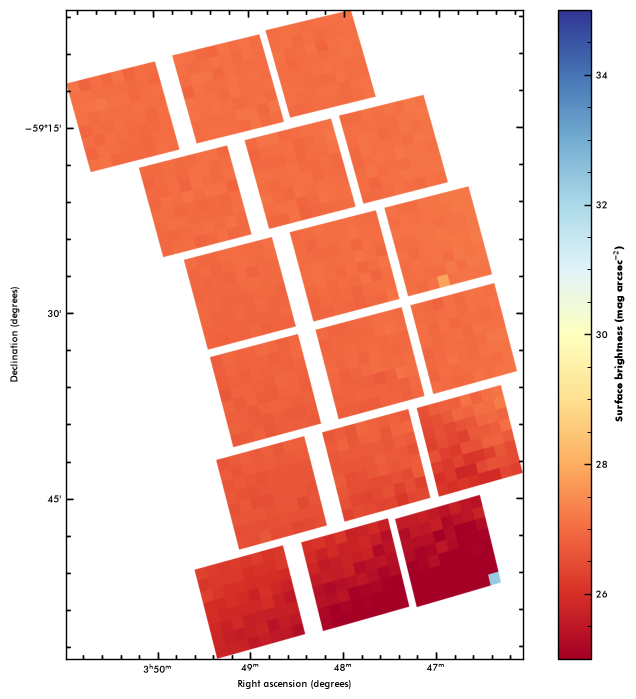

Plot: Stray-light surface brightness flux.
0.0067316703
0.039754197


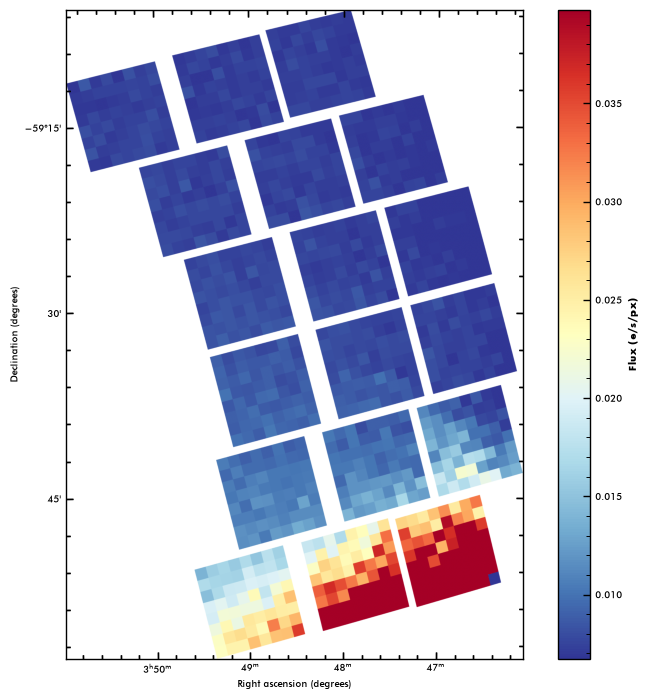

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196926]
Unique IDs with counts > 1:
[     8 196926]
V* R Dor
TYC 8506-238-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.10, -59.09), m=11.77 - TYC 8506-238-1


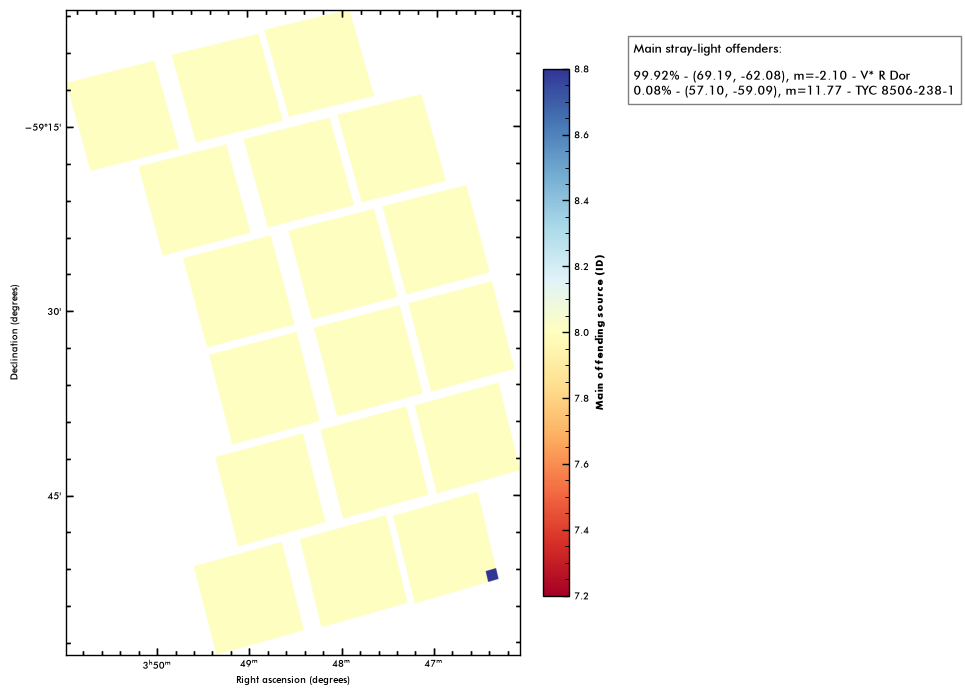

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


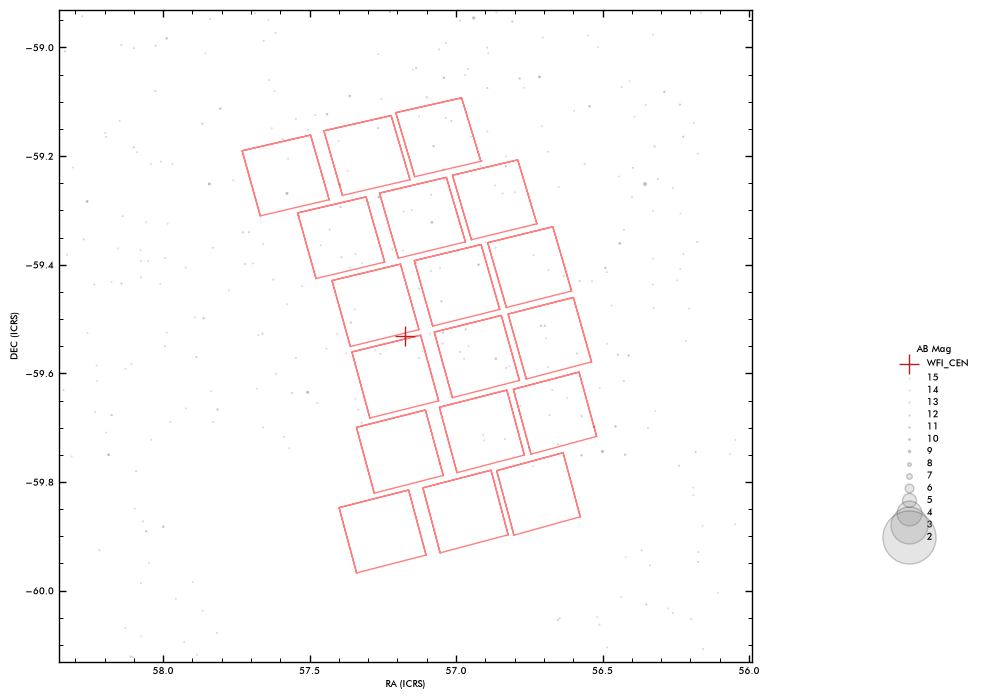

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196926]
Unique IDs with counts > 1:
[     8 196926]
V* R Dor
TYC 8506-238-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.10, -59.09), m=11.77 - TYC 8506-238-1
2026-10-24T14:34:12.407396 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_044_Roman_RA_057.173_DEC_-59.531_MJD_61352.00000_PA_104.73_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_044_Roman_RA_057.173_DEC_-59.531_MJD_61352.00000_PA_104.73_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:34:29.510464 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:34:29 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 14:34:30 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⢿
2026-10-24T14:34:42.338244 > Done.


18it [00:03,  4.86it/s]

2026-10-24T14:34:46.055422 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.59s/it]


2026-10-24T14:35:33.842695 > Done : 0:00:47.787294 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:35:34.916265 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:35:44.573857 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


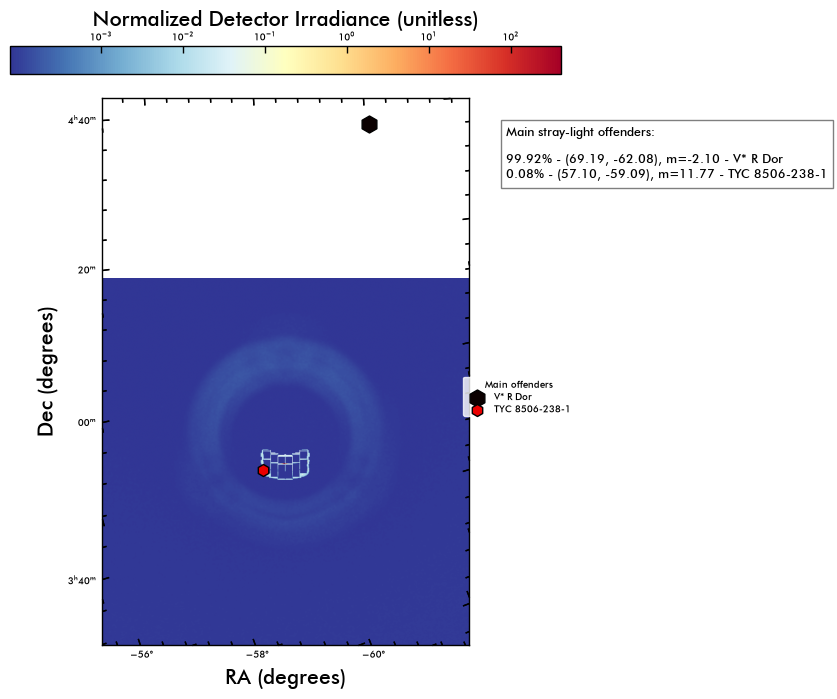

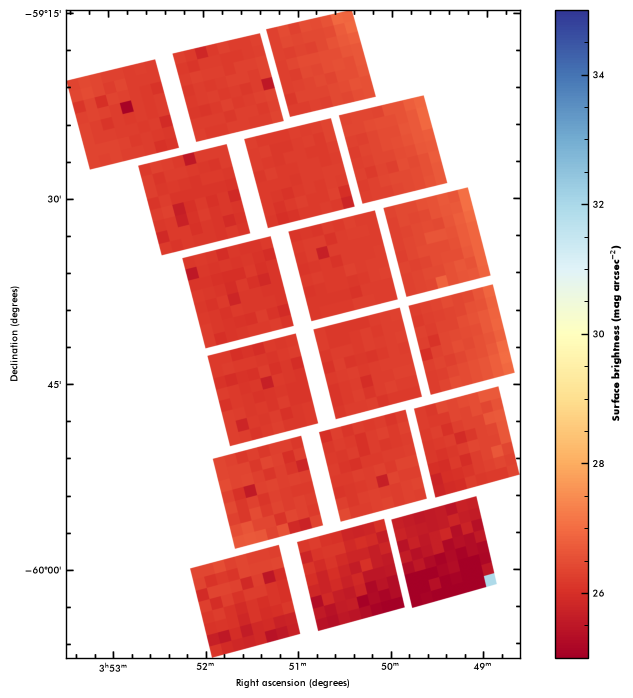

Plot: Stray-light surface brightness flux.
0.010257754
0.030296404


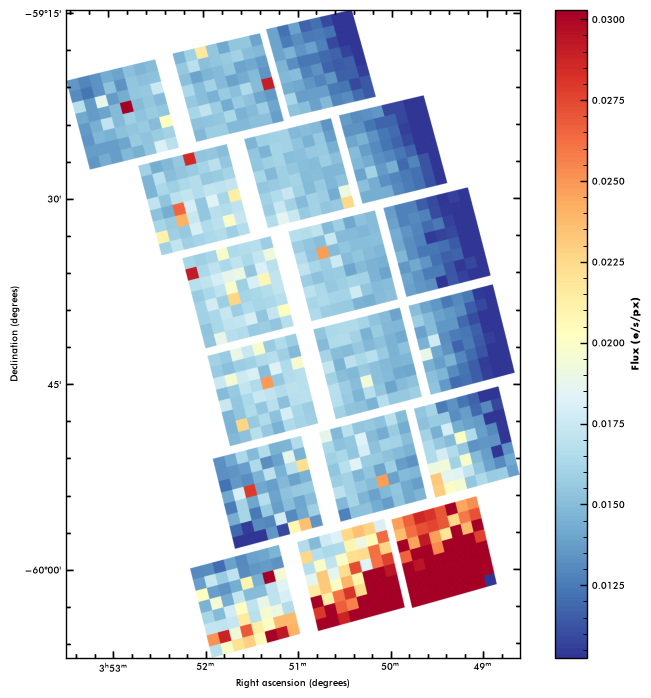

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196837]
Unique IDs with counts > 1:
[     8 196837]
V* R Dor
Simbad cannot find the name of the offender at 57.84234 - -59.251144
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.84, -59.25), m=9.58 - CAT_ID_196837


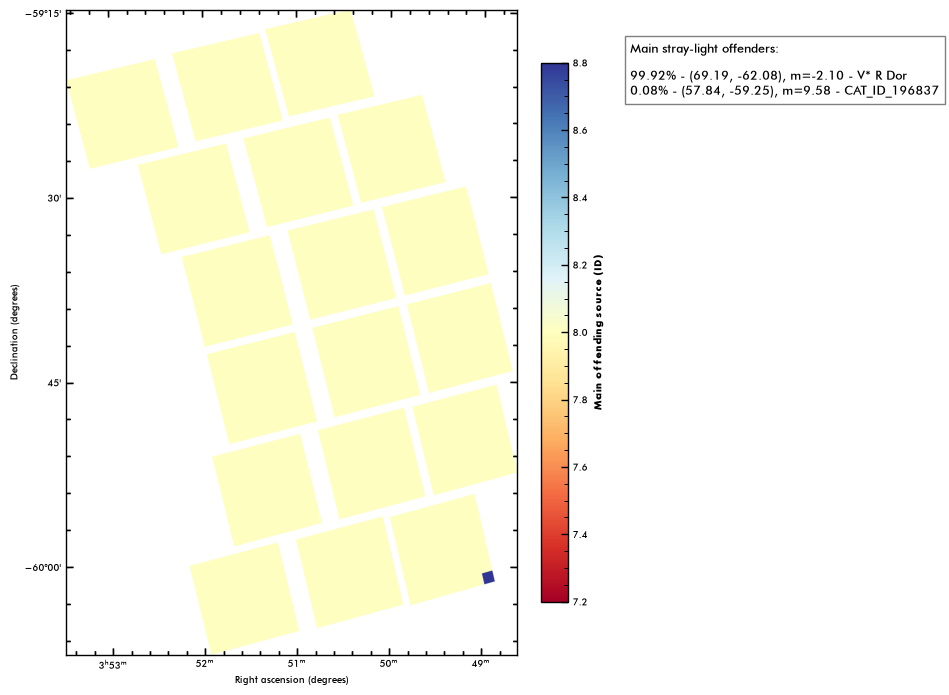

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


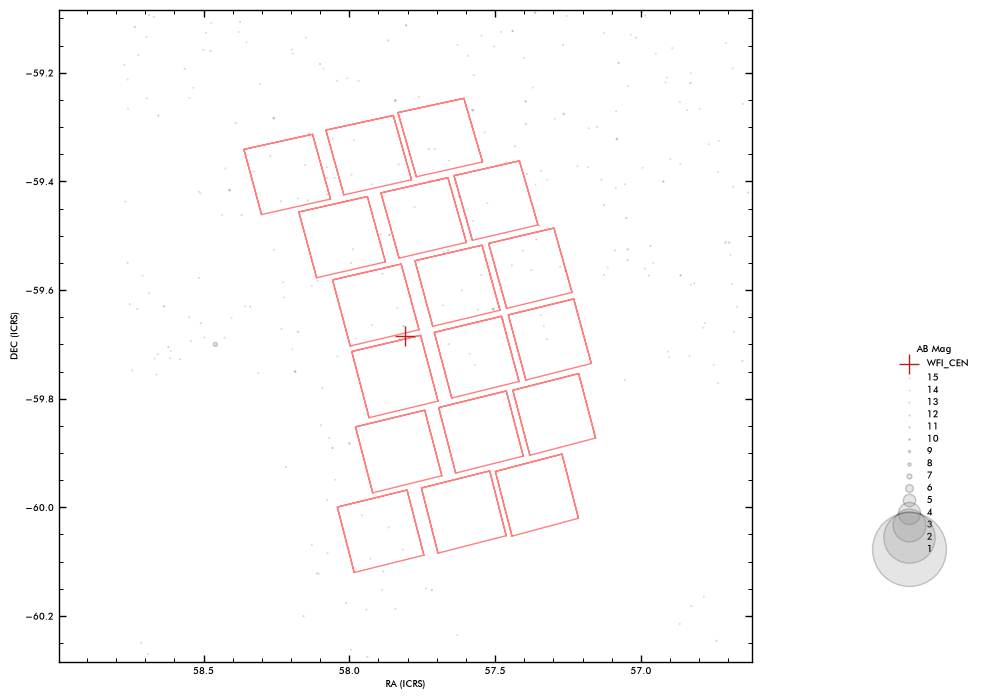

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196837]
Unique IDs with counts > 1:
[     8 196837]
V* R Dor
Simbad cannot find the name of the offender at 57.84234 - -59.251144
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (57.84, -59.25), m=9.58 - CAT_ID_196837
2026-10-24T14:35:53.296518 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_045_Roman_RA_057.807_DEC_-59.684_MJD_61352.00000_PA_104.20_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_045_Roman_RA_057.807_DEC_-59.684_MJD_61352.00000_PA_104.20_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:36:10.628722 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes

2026-10-24 14:36:10 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 14:36:12 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⡿
2026-10-24T14:36:51.832250 > Done.


18it [00:03,  4.65it/s]

2026-10-24T14:36:55.714231 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.59s/it]


2026-10-24T14:37:43.259964 > Done : 0:00:47.545756 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:37:44.320437 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:37:54.130426 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


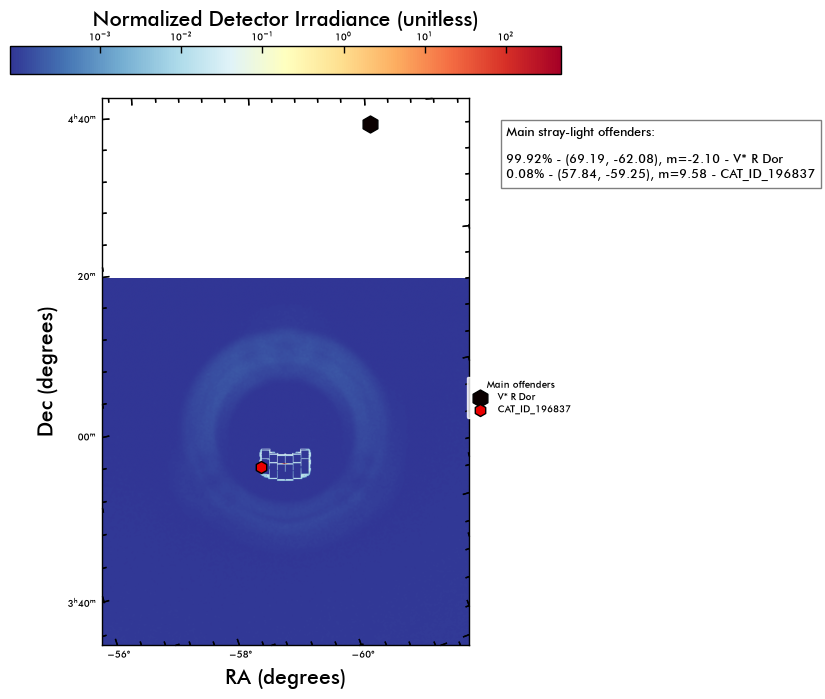

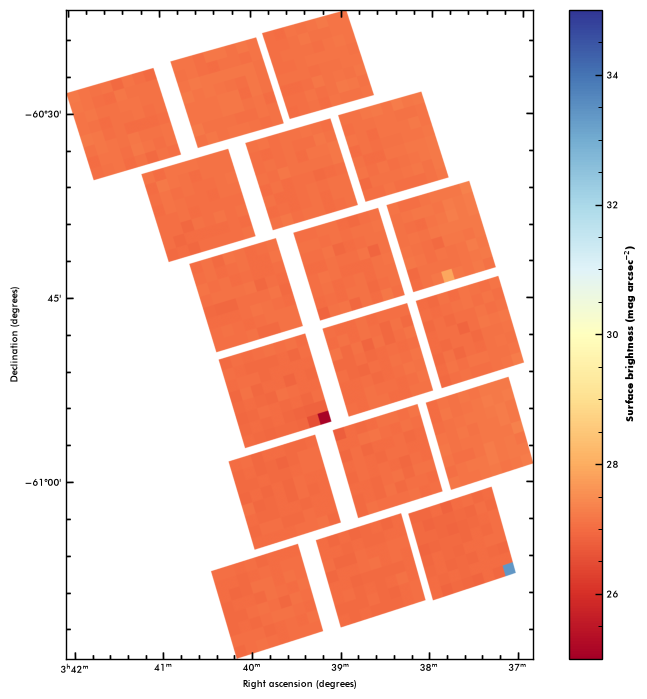

Plot: Stray-light surface brightness flux.
0.006345212
0.007849335


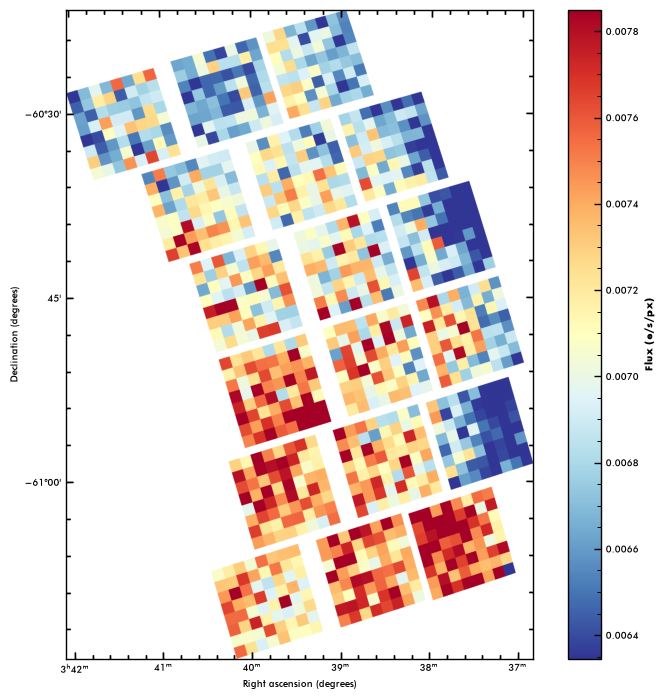

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196891 197060]
Unique IDs with counts > 1:
[     8 196891 197060]
V* R Dor
UCAC4 146-003290
Simbad cannot find the name of the offender at 54.76356 - -60.917763
Main stray-light offenders:

99.65% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (54.76, -60.92), m=13.44 - CAT_ID_197060
0.08% - (55.05, -60.82), m=11.63 - UCAC4 146-003290


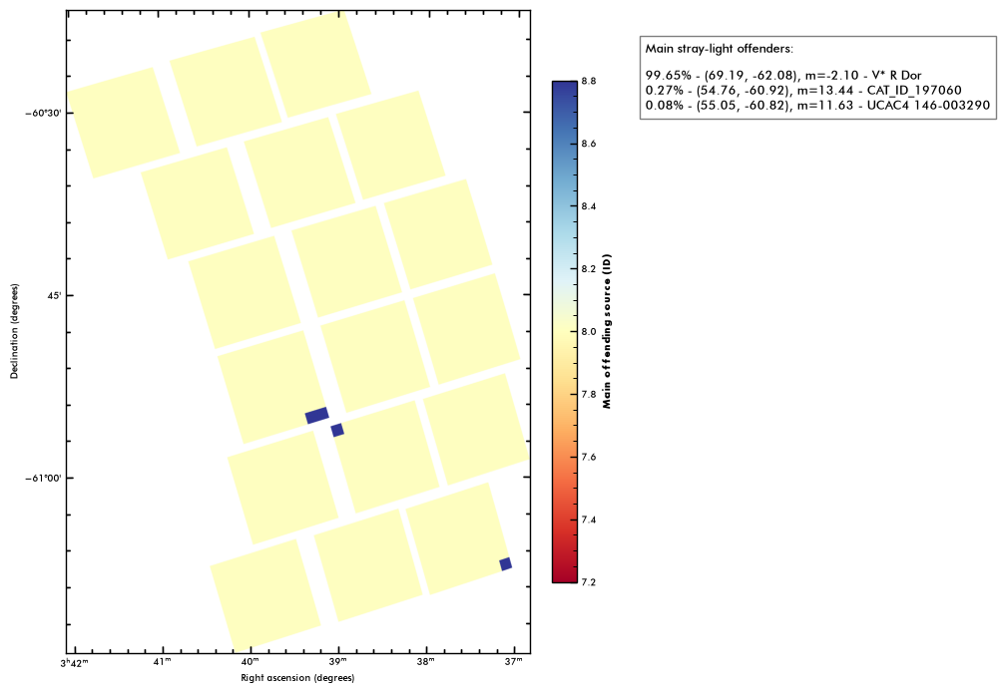

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


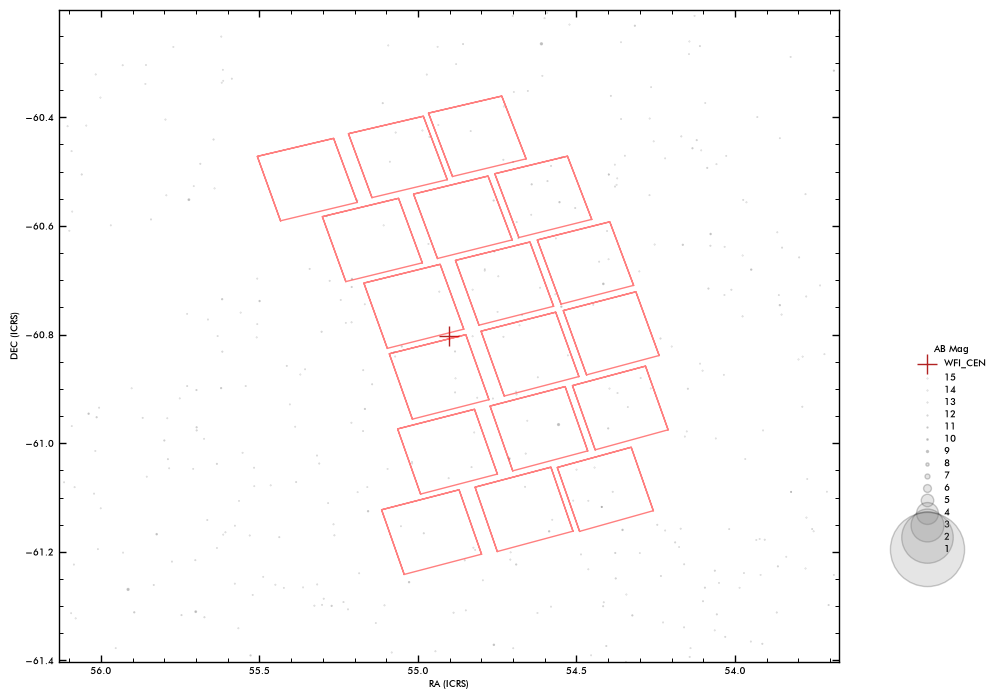

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196891 197060]
Unique IDs with counts > 1:
[     8 196891 197060]
V* R Dor
UCAC4 146-003290
Simbad cannot find the name of the offender at 54.76356 - -60.917763
Main stray-light offenders:

99.65% - (69.19, -62.08), m=-2.10 - V* R Dor
0.27% - (54.76, -60.92), m=13.44 - CAT_ID_197060
0.08% - (55.05, -60.82), m=11.63 - UCAC4 146-003290
2026-10-24T14:38:03.384232 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_046_Roman_RA_054.903_DEC_-60.802_MJD_61352.00000_PA_106.80_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_046_Roman_RA_054.903_DEC_-60.802_MJD_61352.00000_PA_106.80_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:38:20.417620 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be pat

2026-10-24 14:38:20 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 14:38:22 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T14:39:03.755894 > Done.


18it [00:03,  4.74it/s]

2026-10-24T14:39:07.564556 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.58s/it]


2026-10-24T14:39:55.059464 > Done : 0:00:47.494925 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:39:56.134894 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:40:05.982012 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


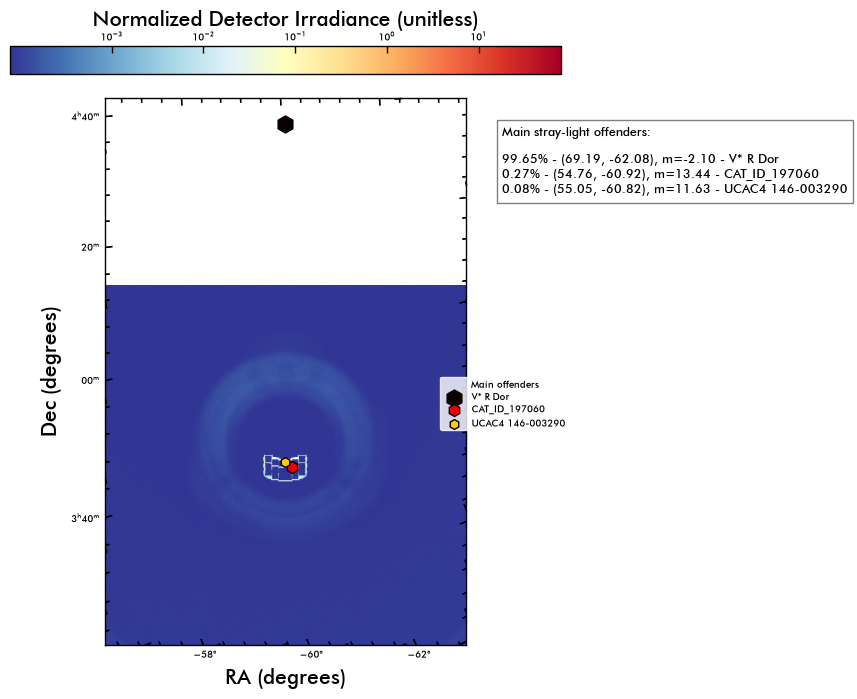

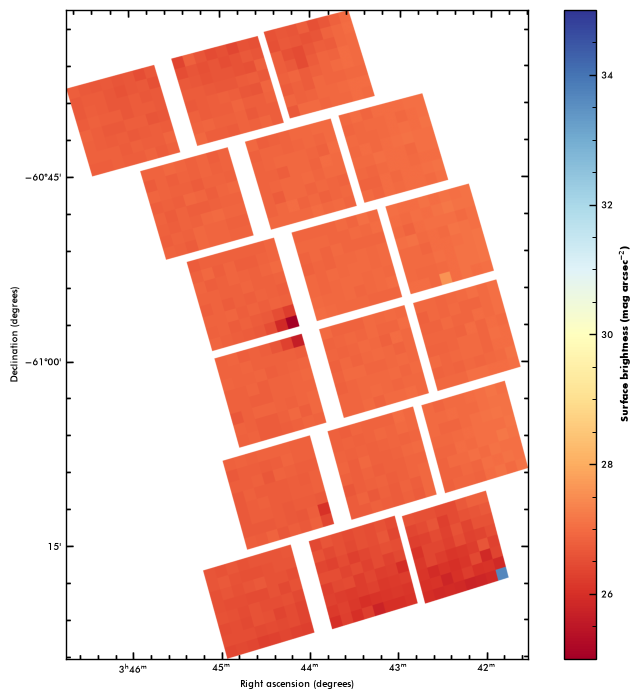

Plot: Stray-light surface brightness flux.
0.007163274
0.014673404


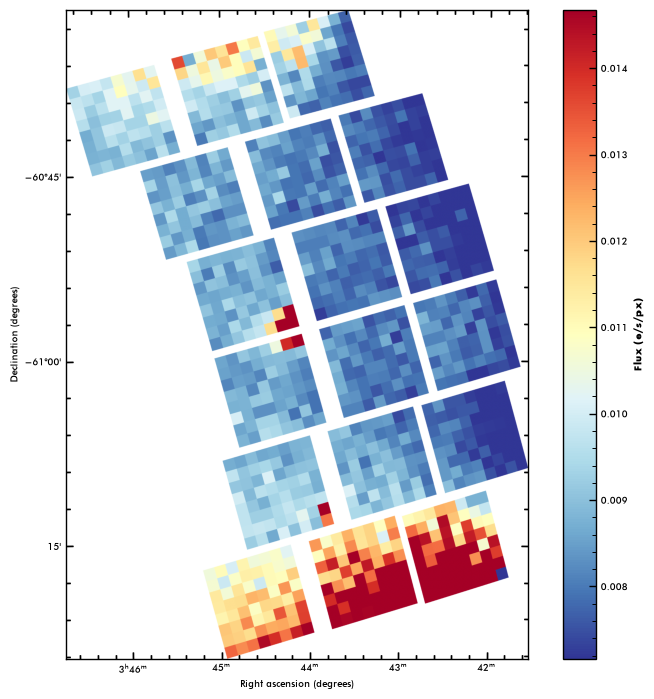

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196873 197315]
Unique IDs with counts > 1:
[     8 196873 197315]
V* R Dor
Simbad cannot find the name of the offender at 56.013237 - -60.952225
Simbad cannot find the name of the offender at 55.930035 - -61.201435
Main stray-light offenders:

99.03% - (69.19, -62.08), m=-2.10 - V* R Dor
0.79% - (56.01, -60.95), m=11.44 - CAT_ID_196873
0.18% - (55.93, -61.20), m=14.80 - CAT_ID_197315


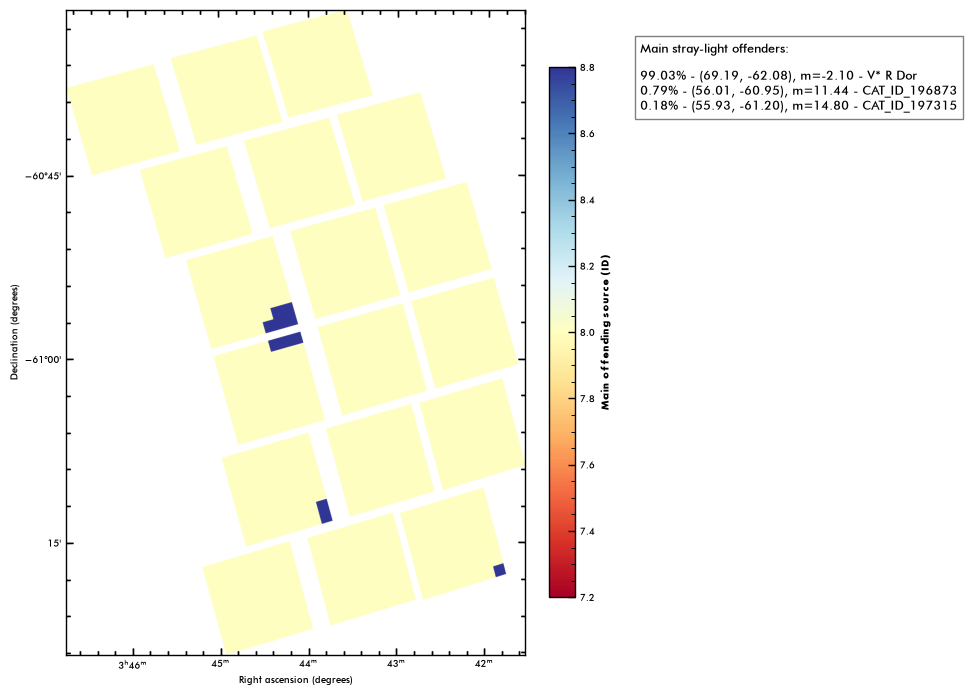

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


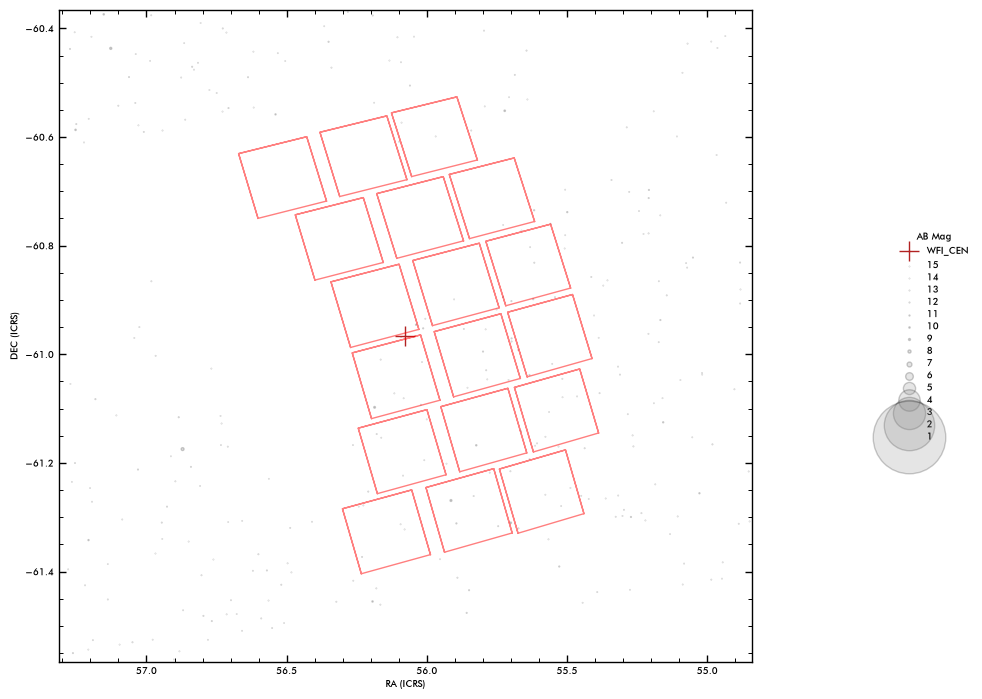

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196873 197315]
Unique IDs with counts > 1:
[     8 196873 197315]
V* R Dor
Simbad cannot find the name of the offender at 56.013237 - -60.952225
Simbad cannot find the name of the offender at 55.930035 - -61.201435
Main stray-light offenders:

99.03% - (69.19, -62.08), m=-2.10 - V* R Dor
0.79% - (56.01, -60.95), m=11.44 - CAT_ID_196873
0.18% - (55.93, -61.20), m=14.80 - CAT_ID_197315
2026-10-24T14:40:15.106742 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_047_Roman_RA_056.076_DEC_-60.966_MJD_61352.00000_PA_105.80_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_047_Roman_RA_056.076_DEC_-60.966_MJD_61352.00000_PA_105.80_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:40:32.384437 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database

2026-10-24 14:40:32 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 14:40:33 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T14:41:19.758599 > Done.


18it [00:03,  4.96it/s]

2026-10-24T14:41:23.400189 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.55s/it]


2026-10-24T14:42:10.535440 > Done : 0:00:47.135271 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:42:11.531435 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:42:21.221855 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


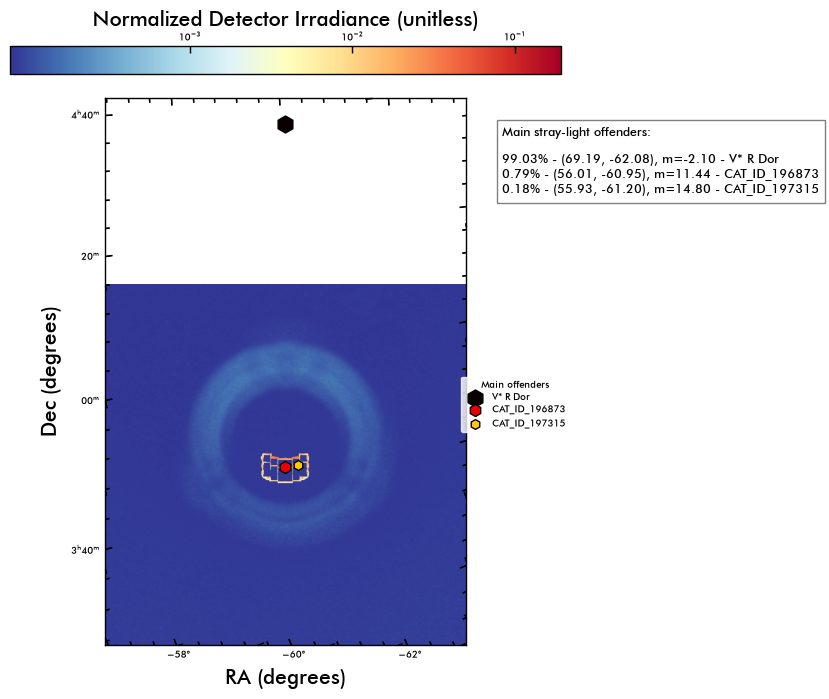

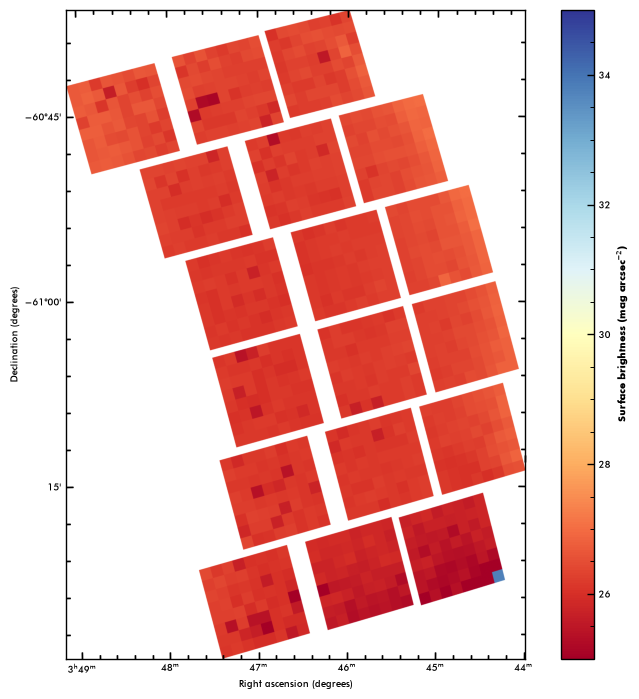

Plot: Stray-light surface brightness flux.
0.009763212
0.028773773


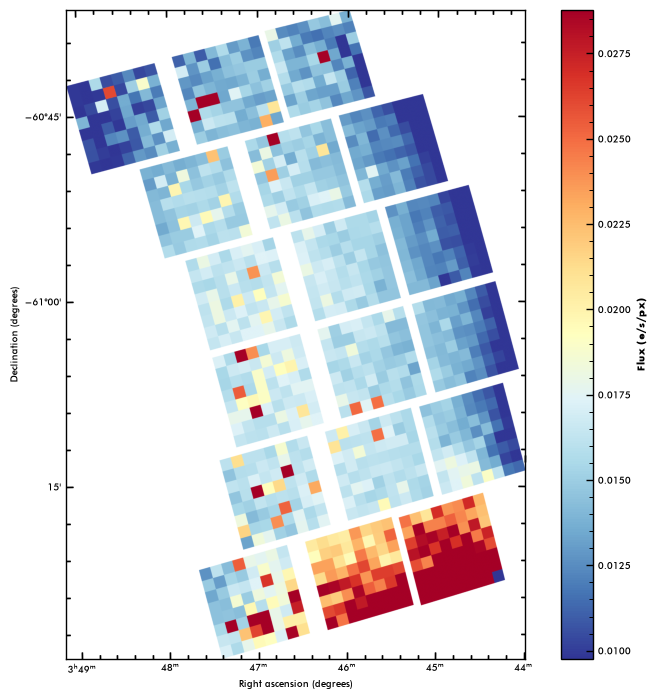

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196889 197024]
Unique IDs with counts > 1:
[     8 196889 197024]
V* R Dor
UCAC2   4706372
Simbad cannot find the name of the offender at 56.620445 - -61.398563
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (56.62, -61.40), m=13.13 - CAT_ID_197024
0.08% - (56.88, -61.12), m=11.70 - UCAC2   4706372


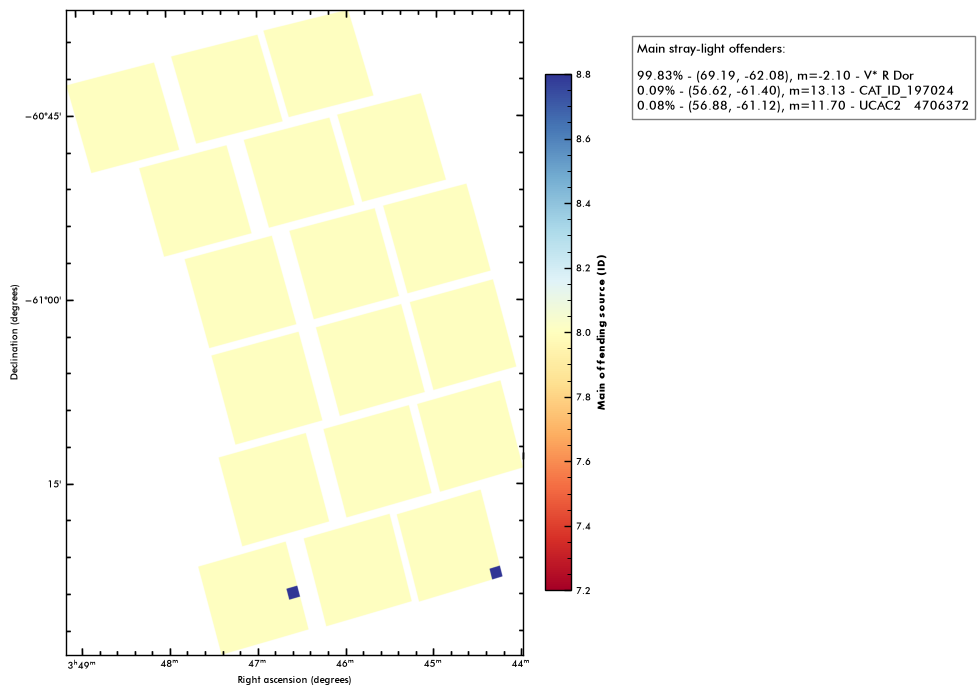

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


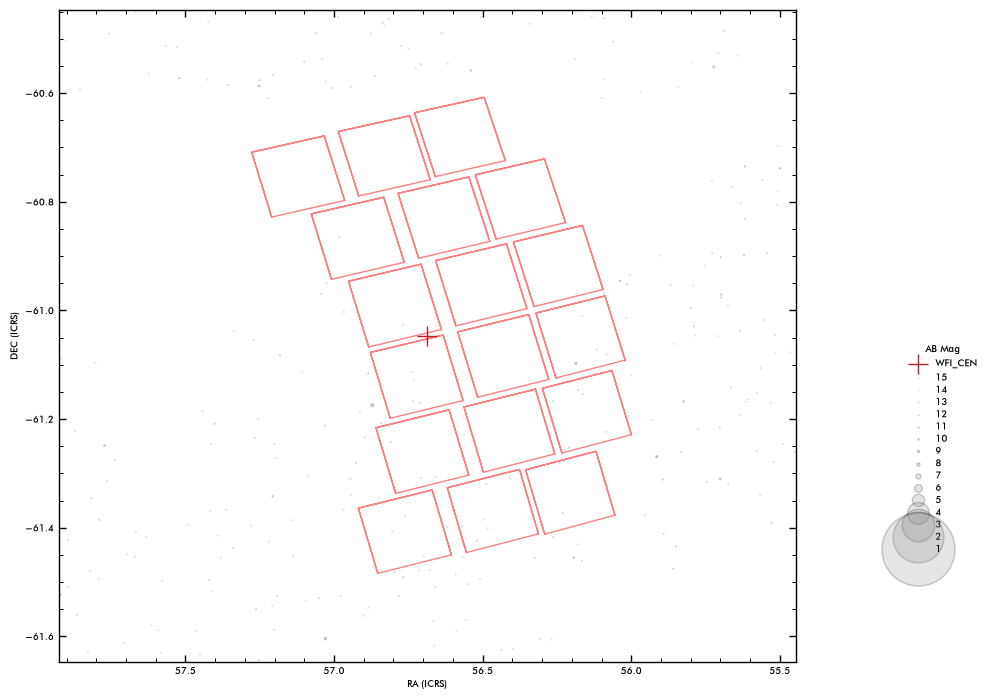

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196889 197024]
Unique IDs with counts > 1:
[     8 196889 197024]
V* R Dor
UCAC2   4706372
Simbad cannot find the name of the offender at 56.620445 - -61.398563
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (56.62, -61.40), m=13.13 - CAT_ID_197024
0.08% - (56.88, -61.12), m=11.70 - UCAC2   4706372
2026-10-24T14:42:29.994217 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_048_Roman_RA_056.687_DEC_-61.047_MJD_61352.00000_PA_105.28_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_048_Roman_RA_056.687_DEC_-61.047_MJD_61352.00000_PA_105.28_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:42:46.410366 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be pati

2026-10-24 14:42:46 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 14:42:47 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣷
2026-10-24T14:43:30.753922 > Done.


18it [00:03,  4.99it/s]

2026-10-24T14:43:34.373553 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.57s/it]


2026-10-24T14:44:21.588644 > Done : 0:00:47.215106 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:44:22.591271 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:44:32.212534 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


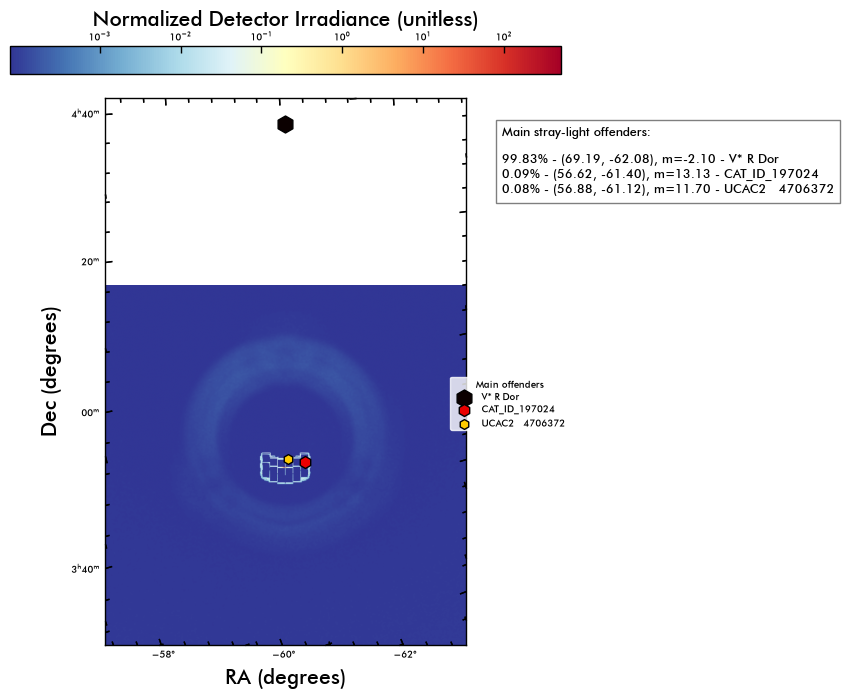

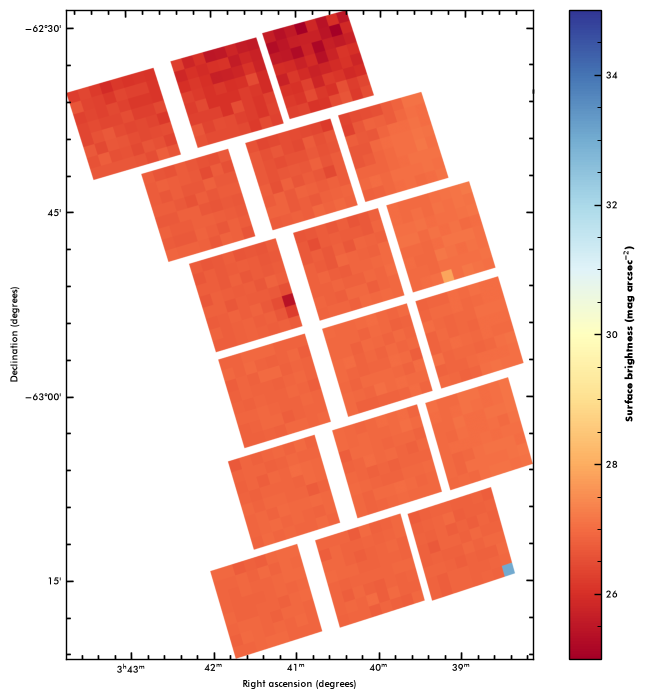

Plot: Stray-light surface brightness flux.
0.007047955
0.018898485


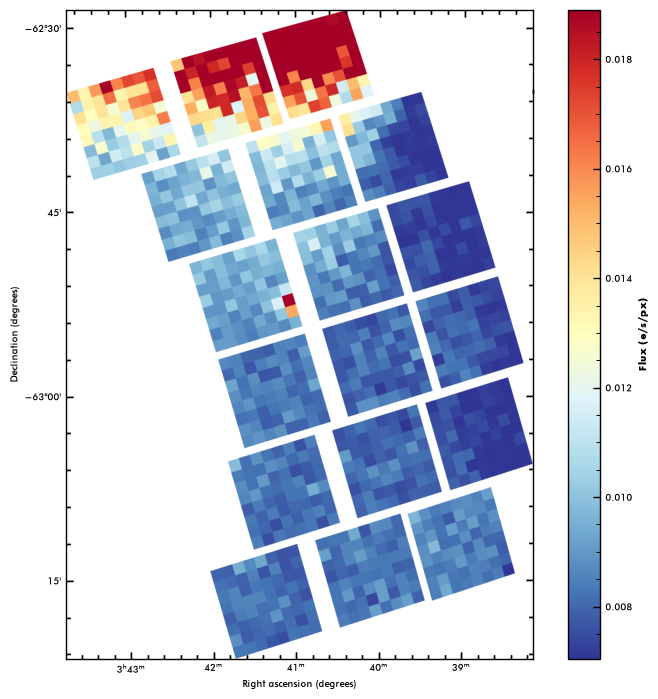

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 192347 197208]
Unique IDs with counts > 1:
[     8 192347 197208]
V* R Dor
CPD-63   245
Simbad cannot find the name of the offender at 55.237347 - -62.87032
Main stray-light offenders:

99.74% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (55.24, -62.87), m=14.21 - CAT_ID_197208
0.08% - (54.56, -62.92), m=8.59 - CPD-63   245


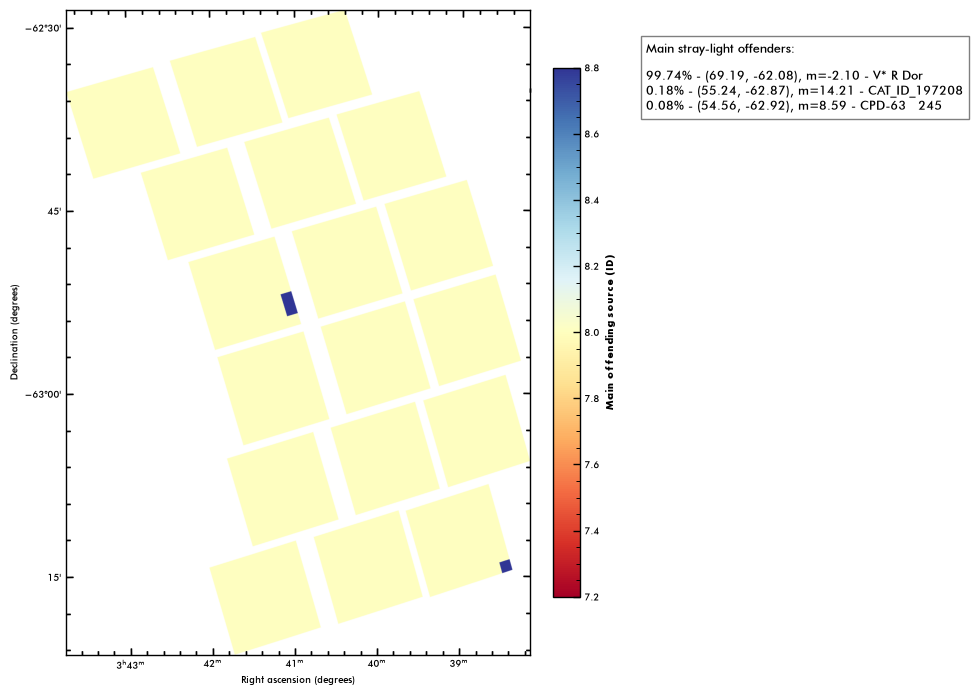

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


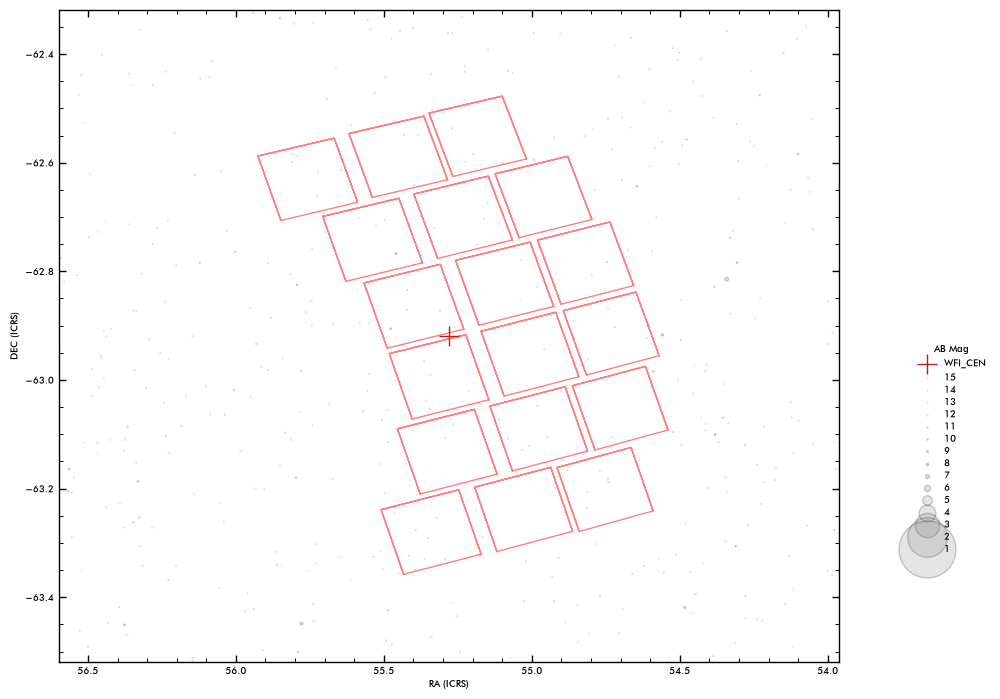

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 192347 197208]
Unique IDs with counts > 1:
[     8 192347 197208]
V* R Dor
CPD-63   245
Simbad cannot find the name of the offender at 55.237347 - -62.87032
Main stray-light offenders:

99.74% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (55.24, -62.87), m=14.21 - CAT_ID_197208
0.08% - (54.56, -62.92), m=8.59 - CPD-63   245
2026-10-24T14:44:41.204737 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_049_Roman_RA_055.280_DEC_-62.919_MJD_61352.00000_PA_106.69_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_049_Roman_RA_055.280_DEC_-62.919_MJD_61352.00000_PA_106.69_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:44:57.779729 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Que

2026-10-24 14:44:57 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 14:44:59 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T14:45:49.986919 > Done.


18it [00:03,  4.98it/s]

2026-10-24T14:45:53.606935 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.53s/it]


2026-10-24T14:46:40.257364 > Done : 0:00:46.650446 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:46:41.262610 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:46:51.169412 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


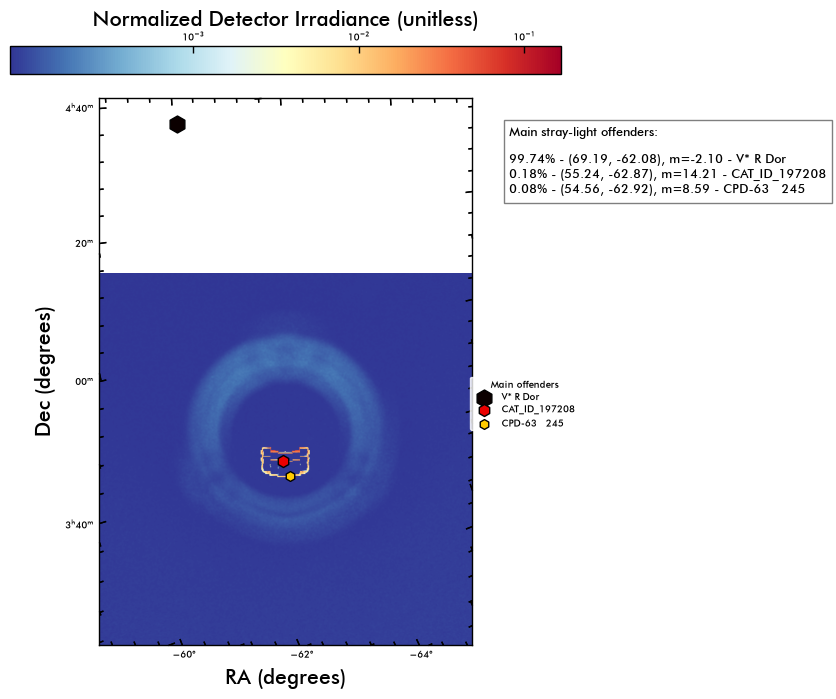

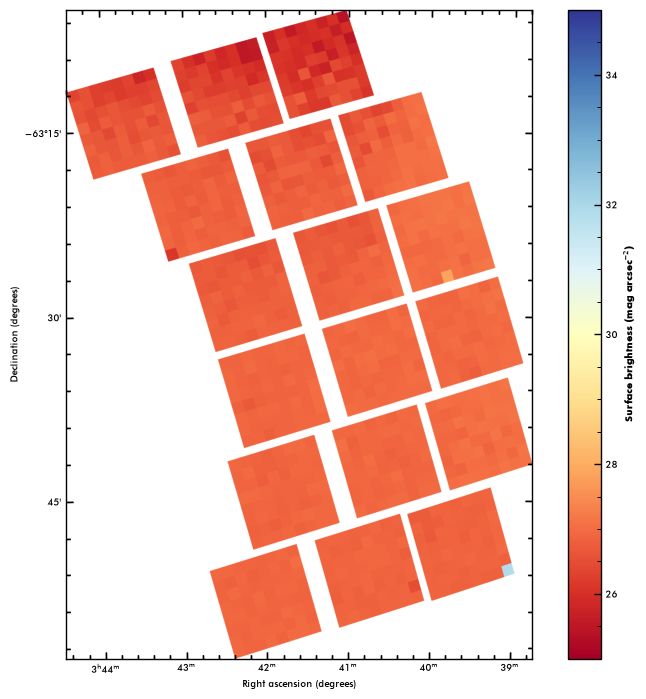

Plot: Stray-light surface brightness flux.
0.0070337346
0.016552089


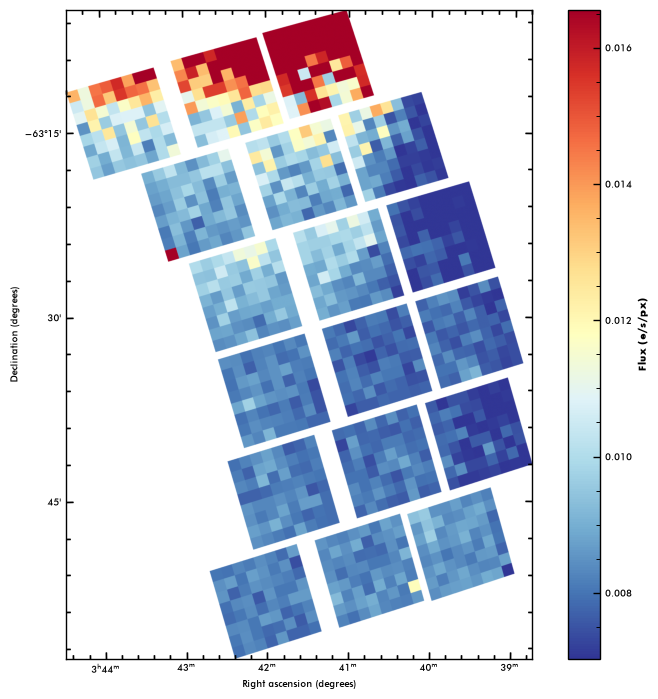

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 173959]
Unique IDs with counts > 1:
[     8 173959]
V* R Dor
HD  23661
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (55.78, -63.45), m=7.99 - HD  23661


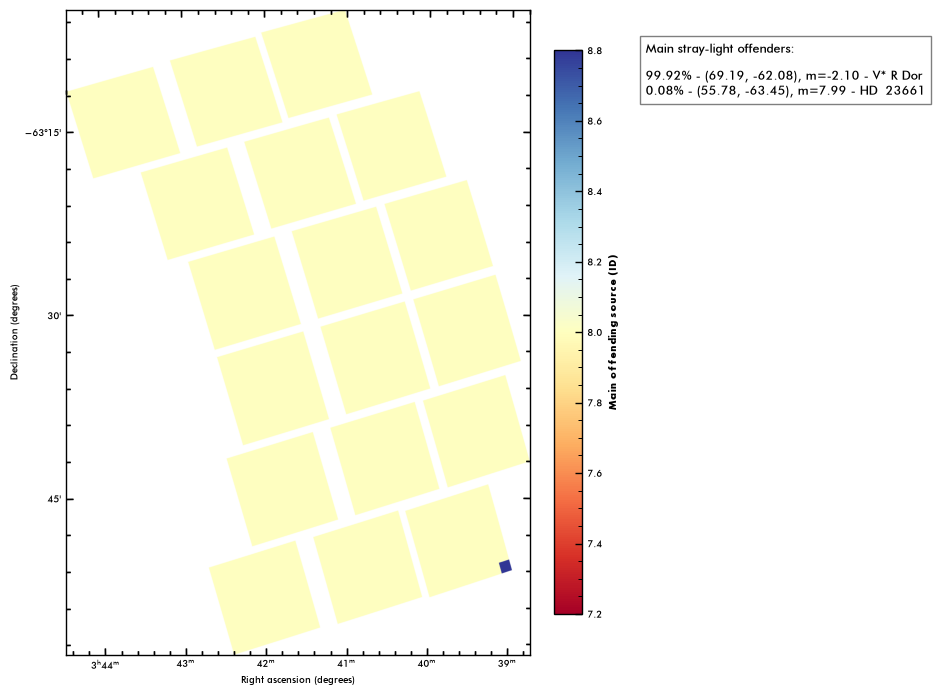

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


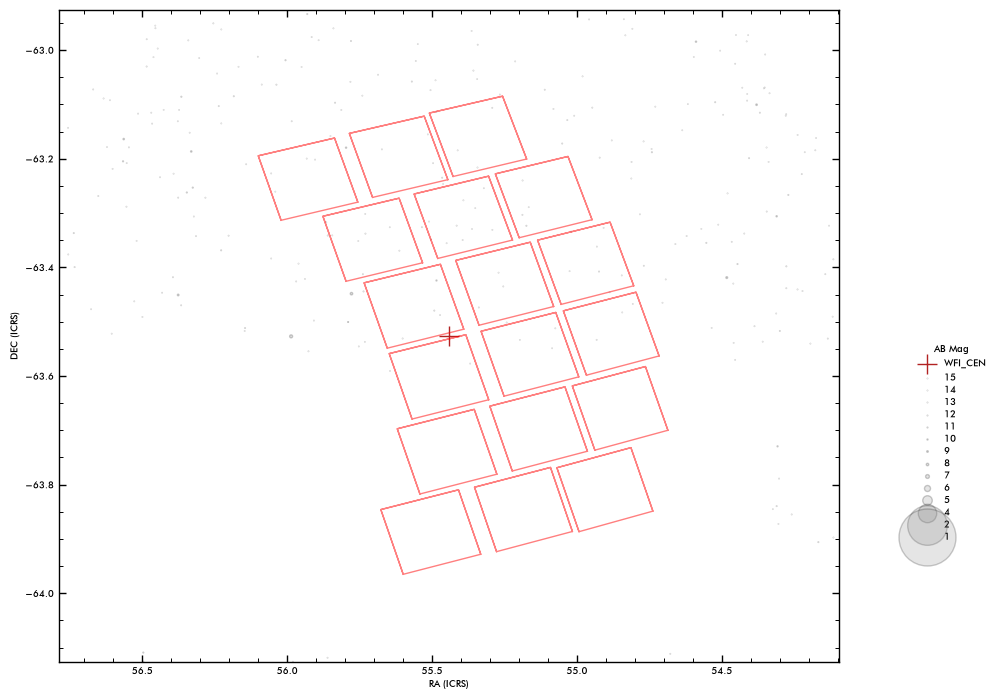

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 173959]
Unique IDs with counts > 1:
[     8 173959]
V* R Dor
HD  23661
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (55.78, -63.45), m=7.99 - HD  23661
2026-10-24T14:46:59.924753 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_050_Roman_RA_055.442_DEC_-63.526_MJD_61352.00000_PA_106.62_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_050_Roman_RA_055.442_DEC_-63.526_MJD_61352.00000_PA_106.62_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:47:17.329186 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:47:17 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:47:18 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⢿
2026-10-24T14:48:09.507554 > Done.


18it [00:03,  5.07it/s]

2026-10-24T14:48:13.064643 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.52s/it]


2026-10-24T14:48:59.348835 > Done : 0:00:46.284213 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:49:00.348232 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:49:10.218437 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


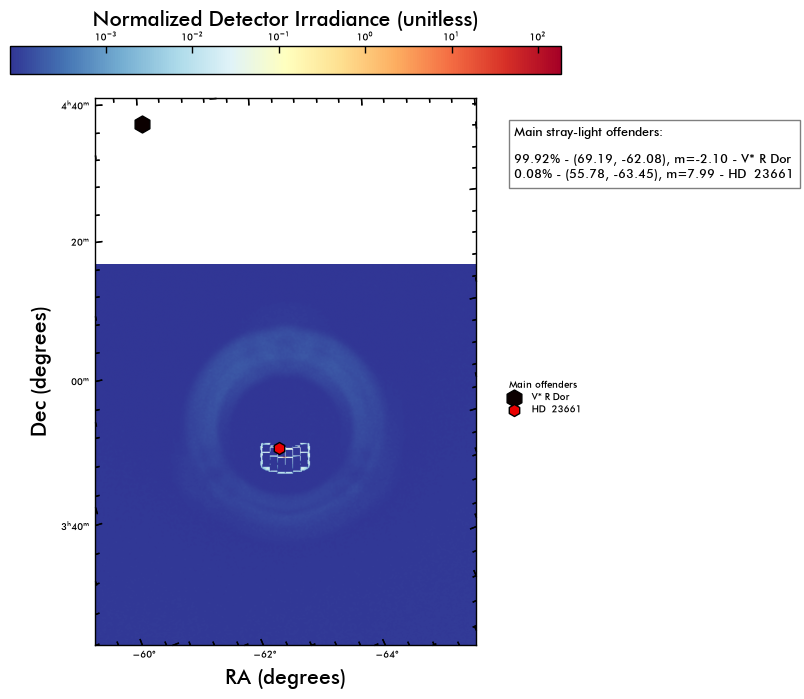

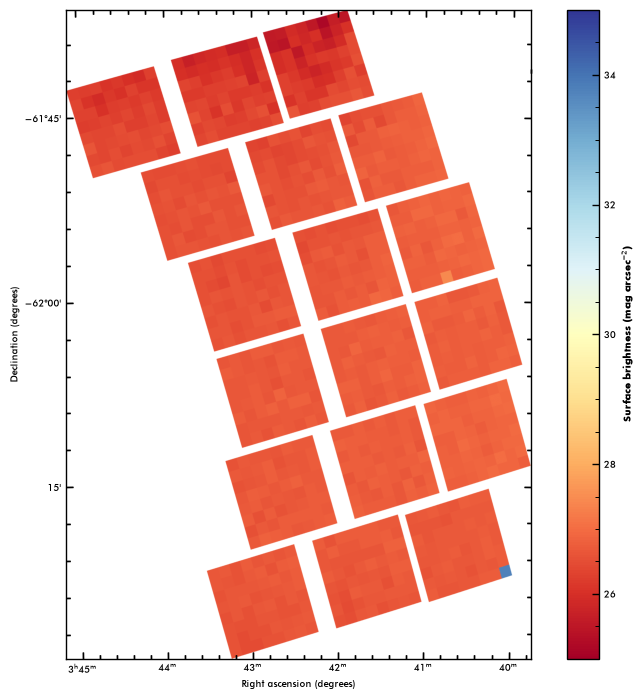

Plot: Stray-light surface brightness flux.
0.008357747
0.017372169


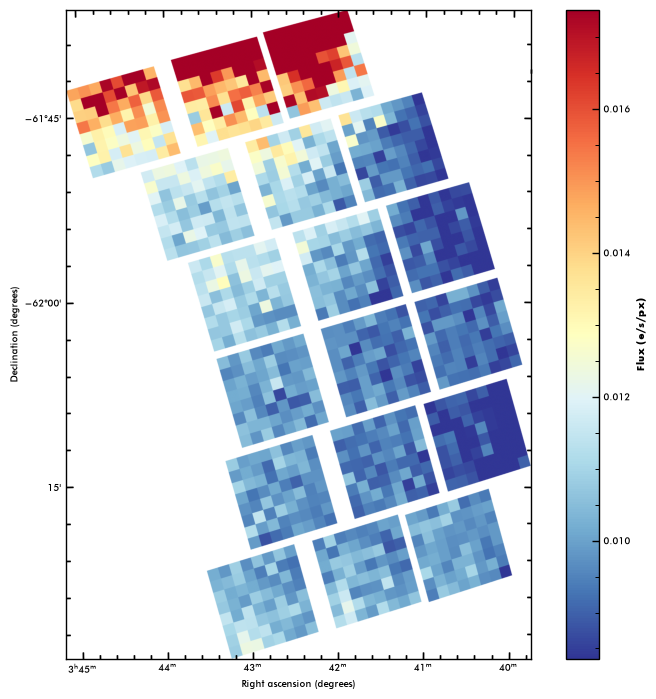

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8    134    396 196848]
Unique IDs with counts > 1:
[     8    134    396 196848]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
Simbad cannot find the name of the offender at 48.1281 - -57.30644
CPD-62   293
Main stray-light offenders:

96.20% - (69.19, -62.08), m=-2.10 - V* R Dor
2.79% - (60.23, -62.16), m=1.32 - CAT_ID_134
0.93% - (48.13, -57.31), m=2.21 - CAT_ID_396
0.08% - (55.85, -62.33), m=10.14 - CPD-62   293


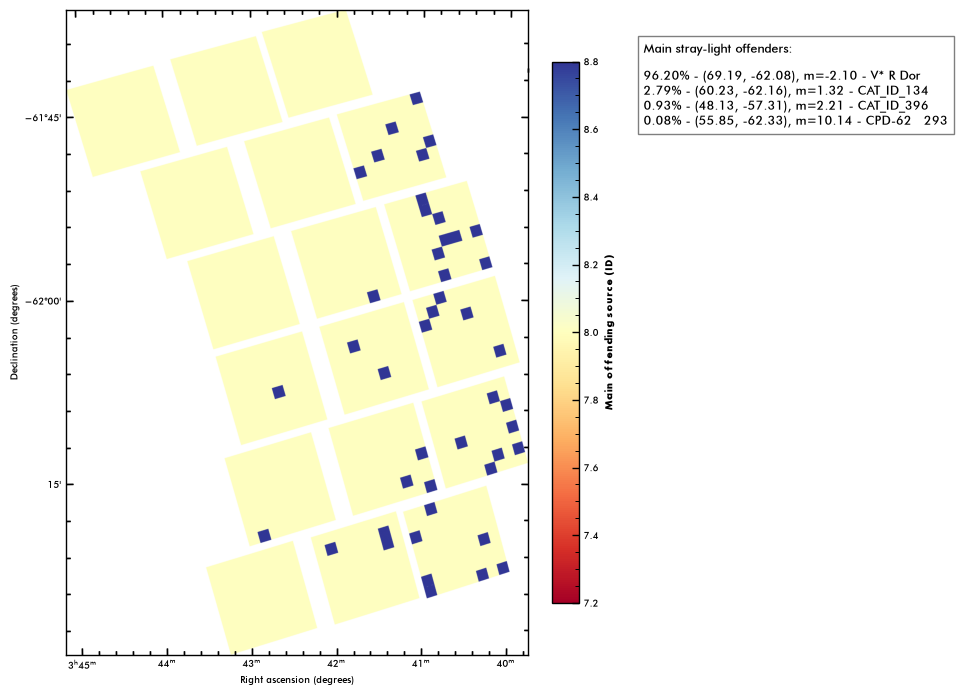

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


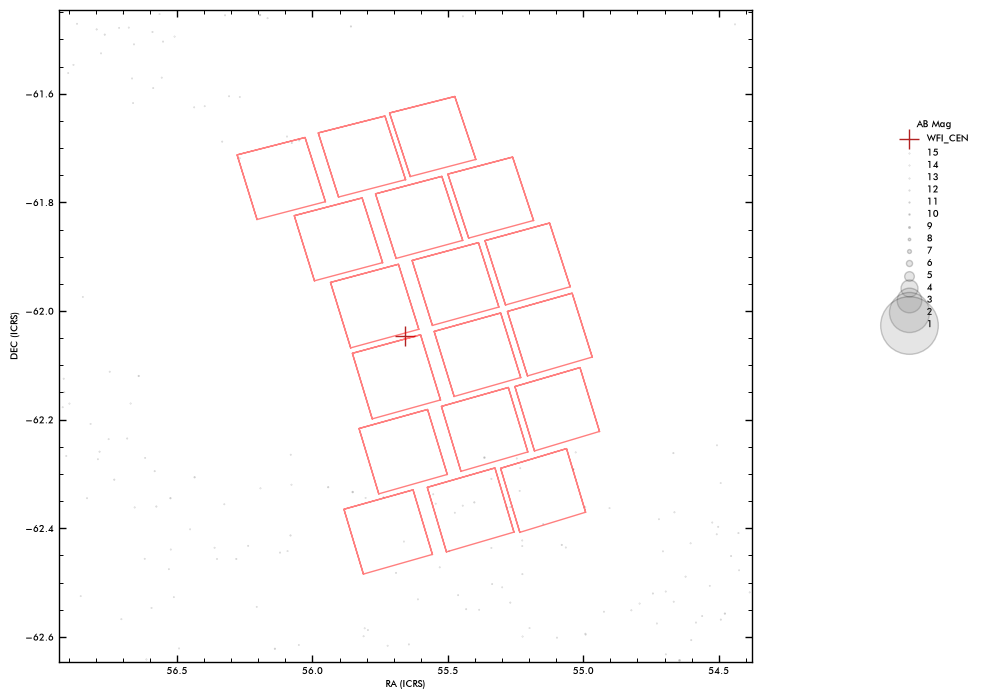

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8    134    396 196848]
Unique IDs with counts > 1:
[     8    134    396 196848]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
Simbad cannot find the name of the offender at 48.1281 - -57.30644
CPD-62   293
Main stray-light offenders:

96.20% - (69.19, -62.08), m=-2.10 - V* R Dor
2.79% - (60.23, -62.16), m=1.32 - CAT_ID_134
0.93% - (48.13, -57.31), m=2.21 - CAT_ID_396
0.08% - (55.85, -62.33), m=10.14 - CPD-62   293
2026-10-24T14:49:19.433332 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_051_Roman_RA_055.657_DEC_-62.046_MJD_61352.00000_PA_106.27_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_051_Roman_RA_055.657_DEC_-62.046_MJD_61352.00000_PA_106.27_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:49:35.964550 > Fetching source catalog
INFO: radius parameter (minimum distance to search for indiv

2026-10-24 14:49:35 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟INFO

2026-10-24 14:49:37 INFO     Parsing tables...


: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣾
2026-10-24T14:50:29.454622 > Done.


18it [00:03,  5.04it/s]

2026-10-24T14:50:33.033770 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:44<00:00,  2.47s/it]


2026-10-24T14:51:18.515136 > Done : 0:00:45.481383 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:51:19.495392 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:51:29.145723 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


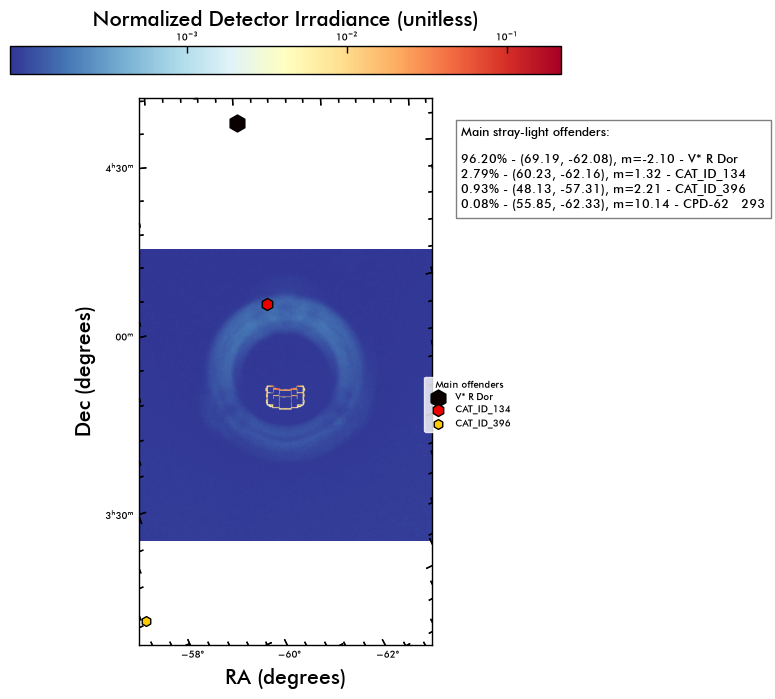

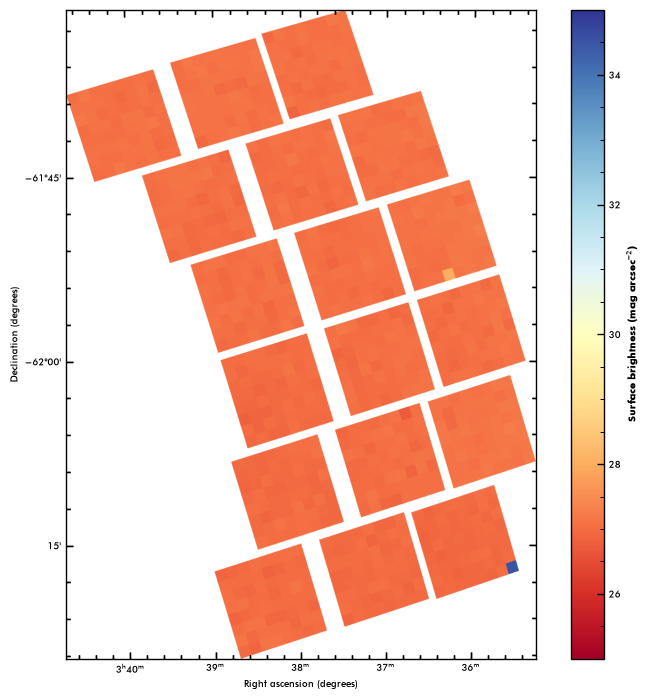

Plot: Stray-light surface brightness flux.
0.00646735
0.007952831


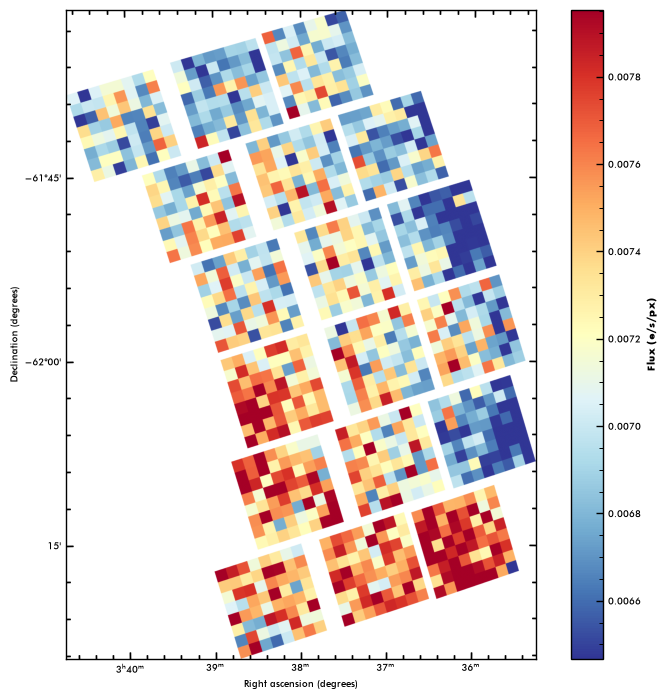

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196946]
Unique IDs with counts > 1:
[     8 196946]
V* R Dor
Simbad cannot find the name of the offender at 54.502033 - -62.397343
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (54.50, -62.40), m=12.75 - CAT_ID_196946


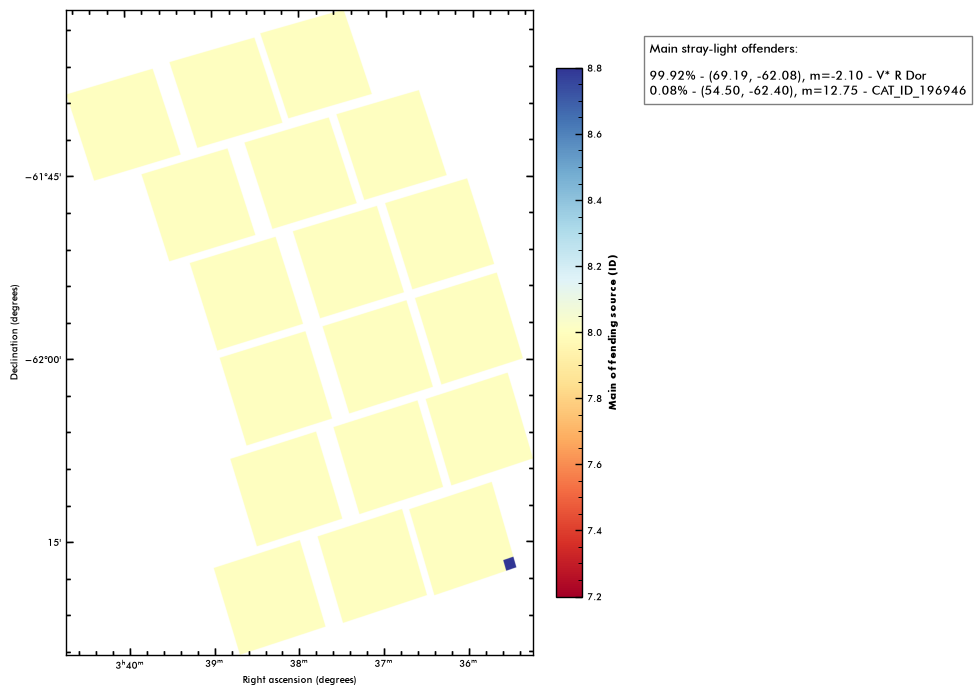

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


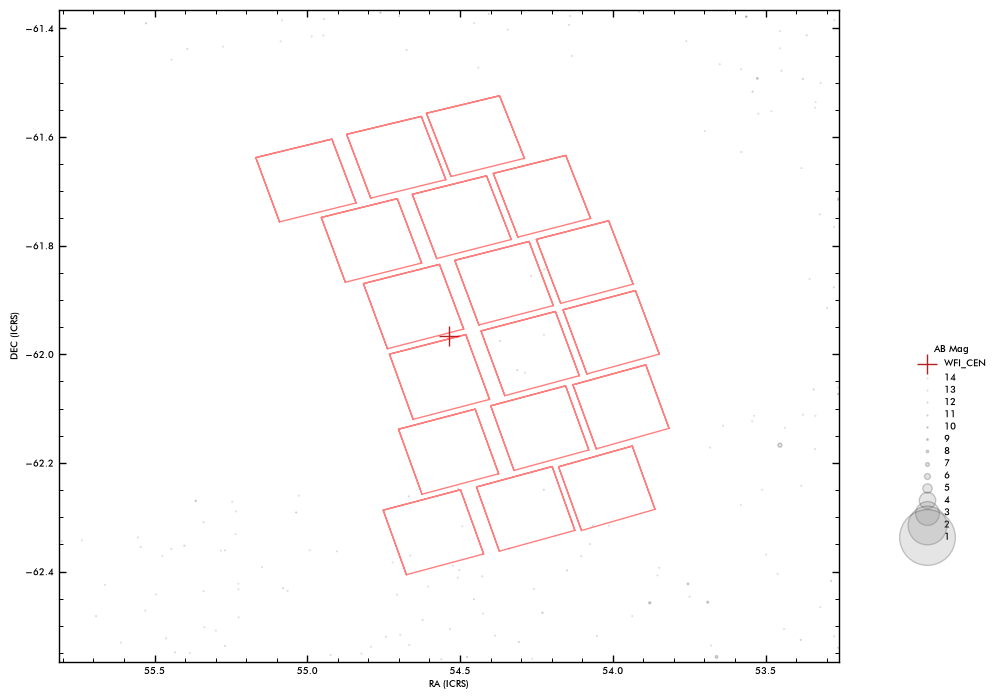

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196946]
Unique IDs with counts > 1:
[     8 196946]
V* R Dor
Simbad cannot find the name of the offender at 54.502033 - -62.397343
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (54.50, -62.40), m=12.75 - CAT_ID_196946
2026-10-24T14:51:38.027473 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_052_Roman_RA_054.537_DEC_-61.966_MJD_61352.00000_PA_107.24_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_052_Roman_RA_054.537_DEC_-61.966_MJD_61352.00000_PA_107.24_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:51:54.400894 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minut

2026-10-24 14:51:54 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

2026-10-24 14:51:56 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣾
2026-10-24T14:52:38.763505 > Done.


18it [00:03,  4.99it/s]

2026-10-24T14:52:42.376723 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:44<00:00,  2.48s/it]


2026-10-24T14:53:27.996038 > Done : 0:00:45.619333 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:53:28.992127 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:53:38.761445 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


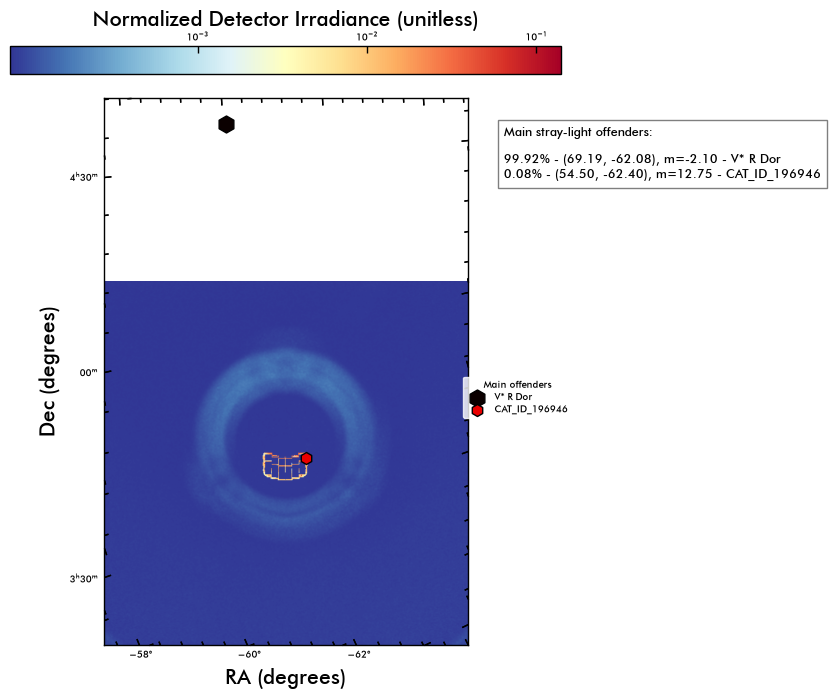

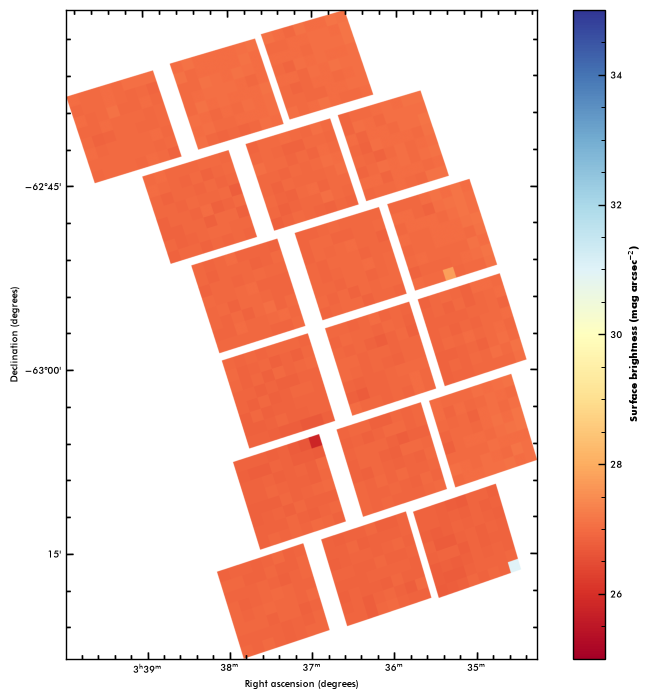

Plot: Stray-light surface brightness flux.
0.007064793
0.008861685


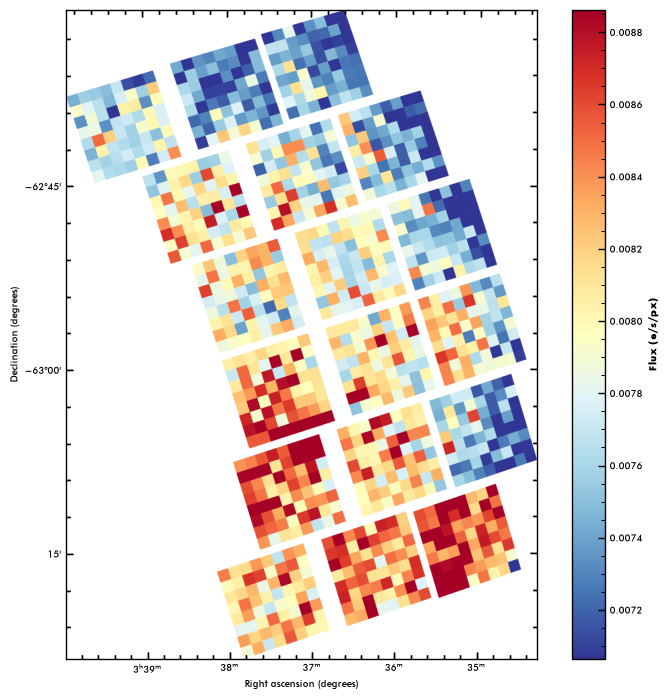

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 126267 197303]
Unique IDs with counts > 1:
[     8 126267 197303]
V* R Dor
HD  22937
Simbad cannot find the name of the offender at 54.215576 - -63.086998
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (54.22, -63.09), m=14.47 - CAT_ID_197303
0.08% - (54.34, -62.81), m=7.09 - HD  22937


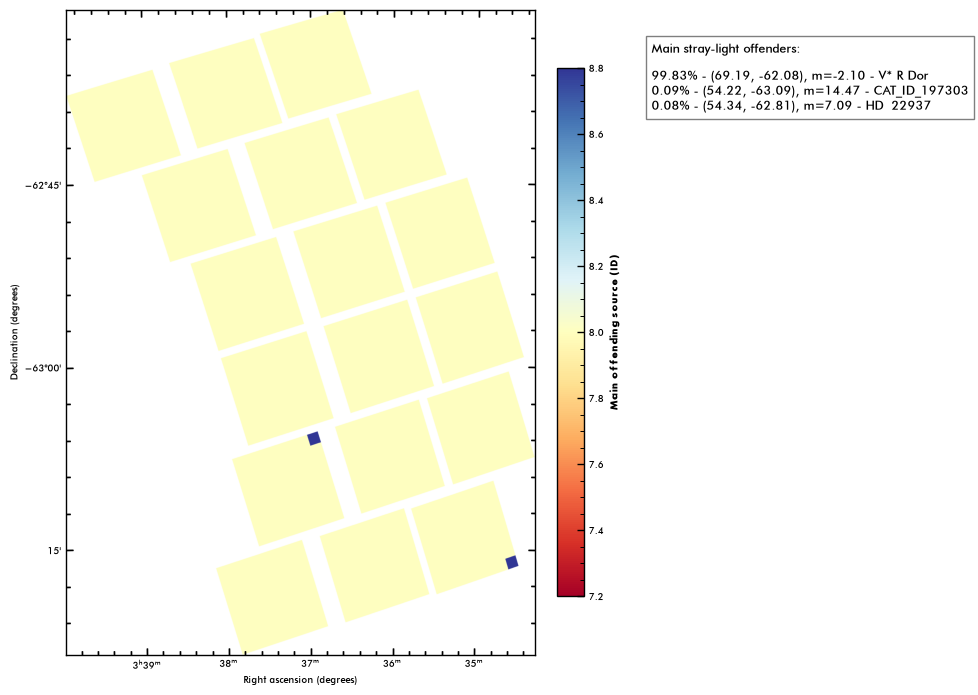

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


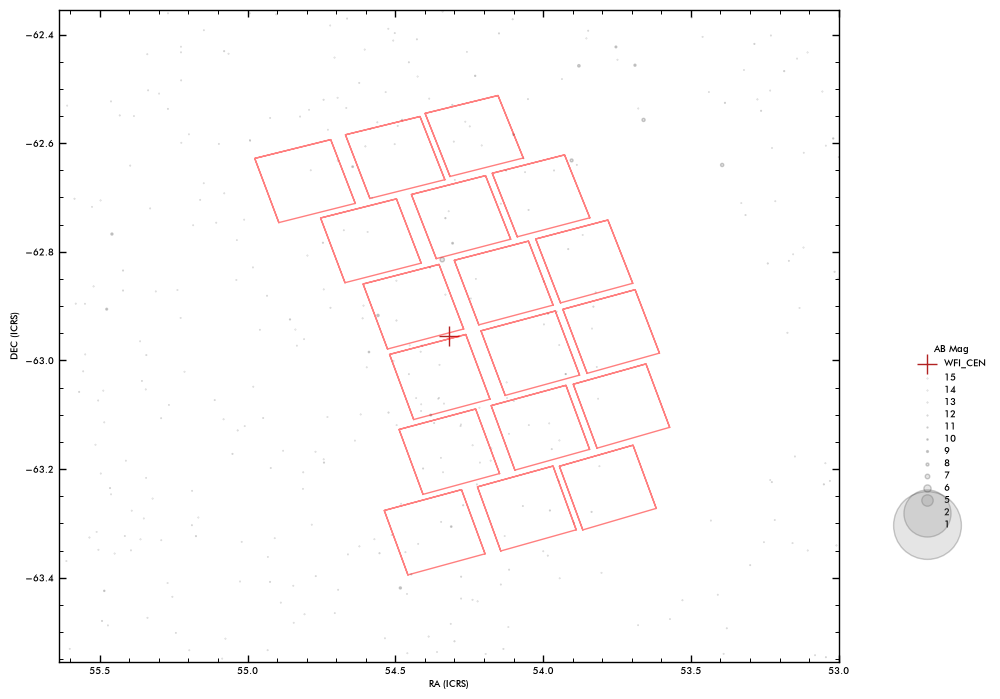

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 126267 197303]
Unique IDs with counts > 1:
[     8 126267 197303]
V* R Dor
HD  22937
Simbad cannot find the name of the offender at 54.215576 - -63.086998
Main stray-light offenders:

99.83% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (54.22, -63.09), m=14.47 - CAT_ID_197303
0.08% - (54.34, -62.81), m=7.09 - HD  22937
2026-10-24T14:53:48.177776 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_053_Roman_RA_054.319_DEC_-62.955_MJD_61352.00000_PA_107.55_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_053_Roman_RA_054.319_DEC_-62.955_MJD_61352.00000_PA_107.55_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:54:04.733875 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying

2026-10-24 14:54:04 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 14:54:06 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⡿
2026-10-24T14:54:53.307022 > Done.


18it [00:03,  4.94it/s]

2026-10-24T14:54:56.959453 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:44<00:00,  2.47s/it]


2026-10-24T14:55:42.511877 > Done : 0:00:45.552440 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:55:43.528956 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:55:53.223109 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


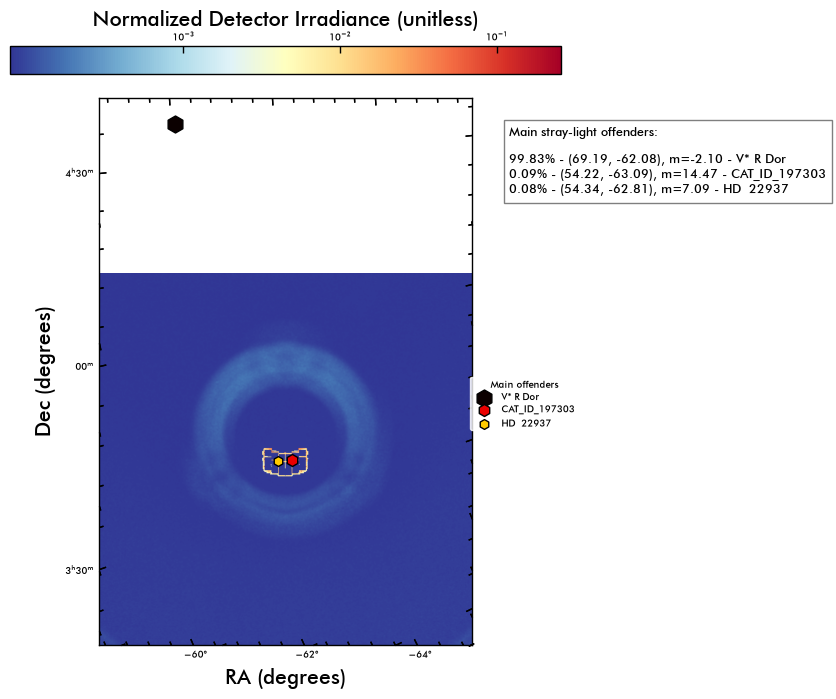

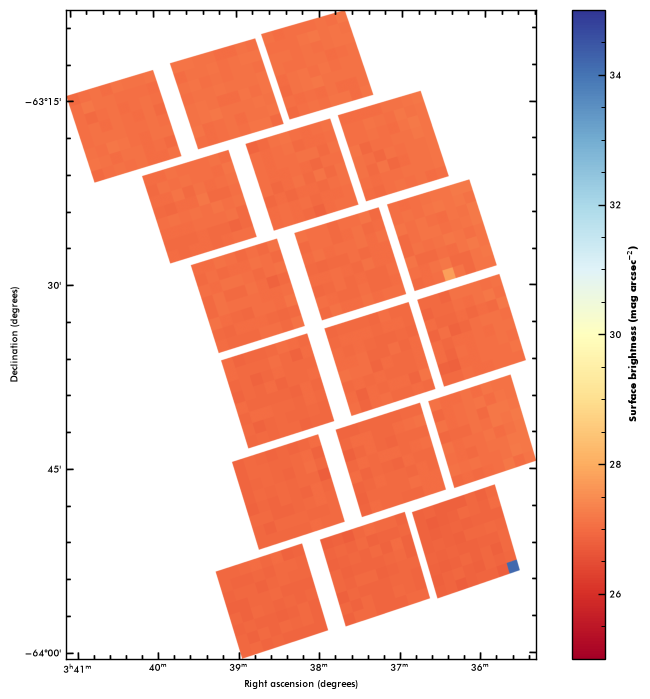

Plot: Stray-light surface brightness flux.
0.006607966
0.008418263


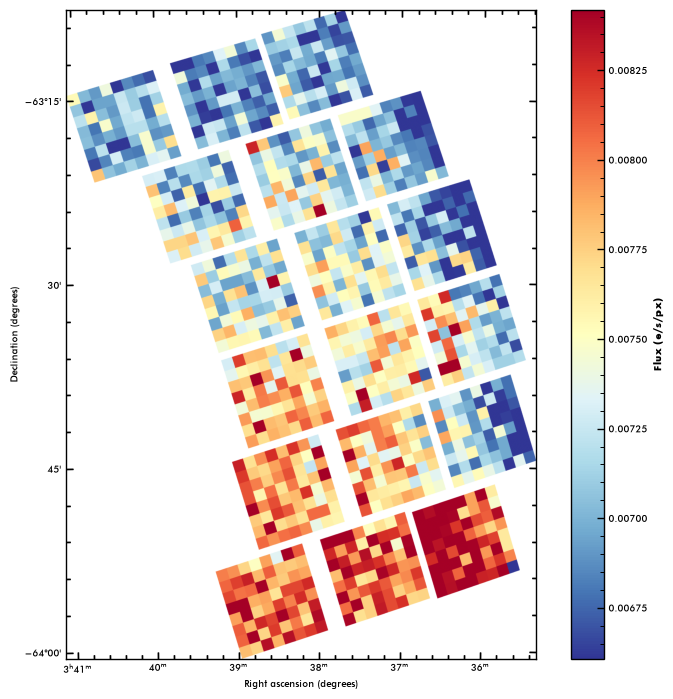

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196935]
Unique IDs with counts > 1:
[     8 196935]
V* R Dor
TYC 8870-885-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (54.22, -63.23), m=12.47 - TYC 8870-885-1


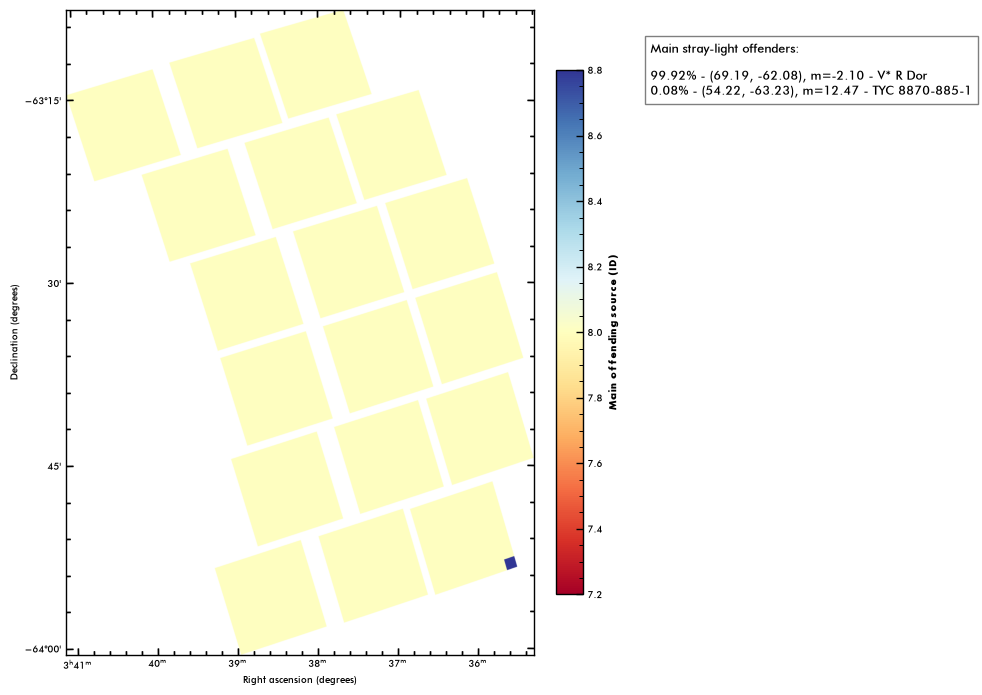

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


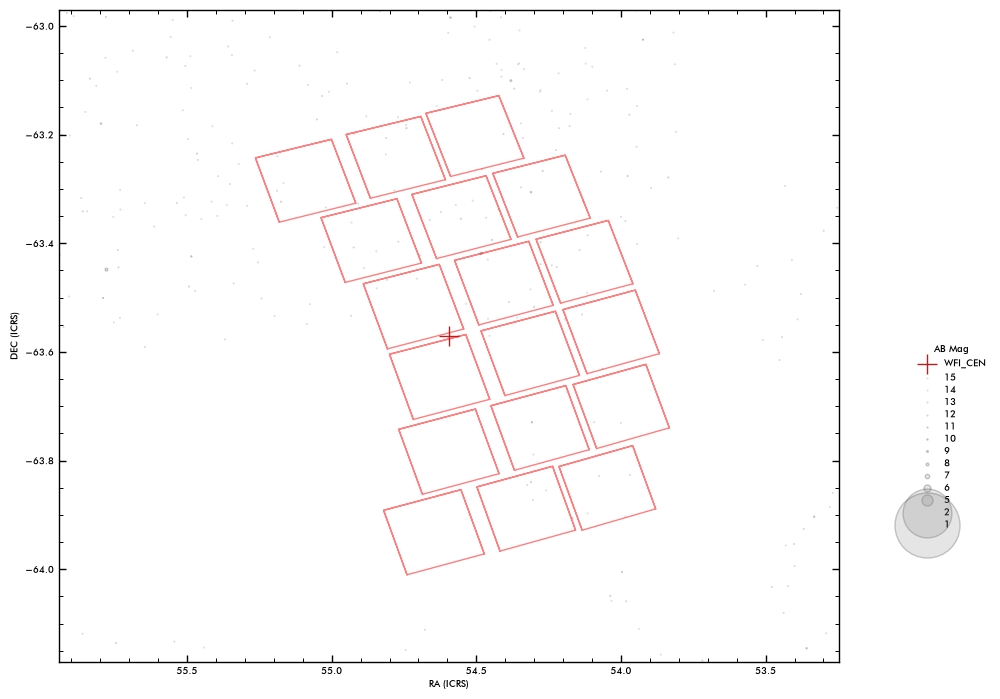

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196935]
Unique IDs with counts > 1:
[     8 196935]
V* R Dor
TYC 8870-885-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (54.22, -63.23), m=12.47 - TYC 8870-885-1
2026-10-24T14:56:02.575924 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_054_Roman_RA_054.595_DEC_-63.571_MJD_61352.00000_PA_107.37_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_054_Roman_RA_054.595_DEC_-63.571_MJD_61352.00000_PA_107.37_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:56:18.939230 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:56:18 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

2026-10-24 14:56:20 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣾
2026-10-24T14:57:27.217073 > Done.


18it [00:03,  5.09it/s]

2026-10-24T14:57:30.759884 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:44<00:00,  2.49s/it]


2026-10-24T14:58:16.600133 > Done : 0:00:45.840267 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T14:58:17.636555 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T14:58:27.395799 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


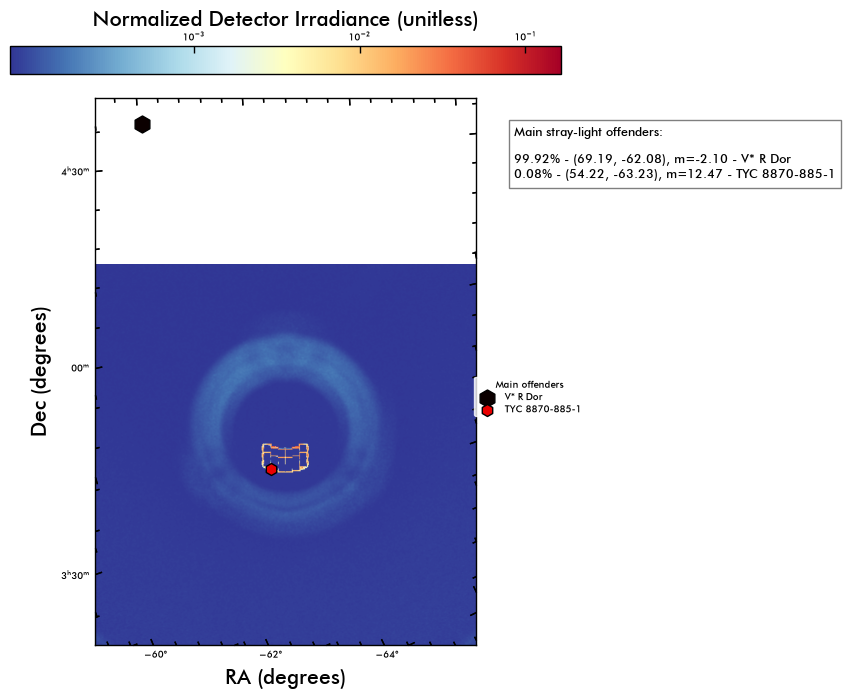

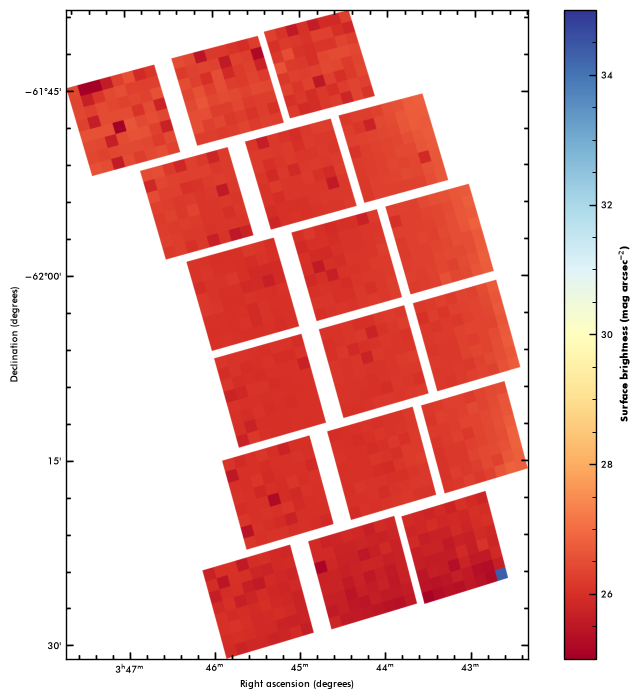

Plot: Stray-light surface brightness flux.
0.011486993
0.02734131


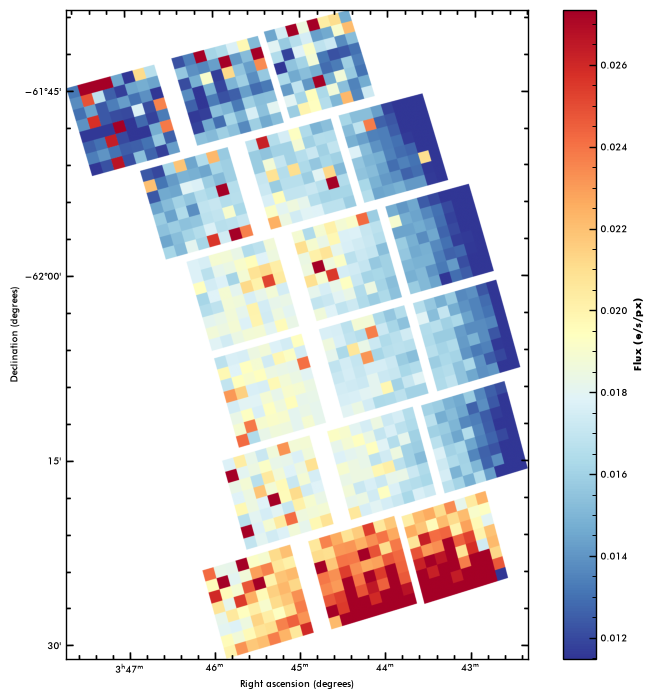

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196909]
Unique IDs with counts > 1:
[     8 196909]
V* R Dor
Simbad cannot find the name of the offender at 56.04905 - -61.685978
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (56.05, -61.69), m=12.40 - CAT_ID_196909


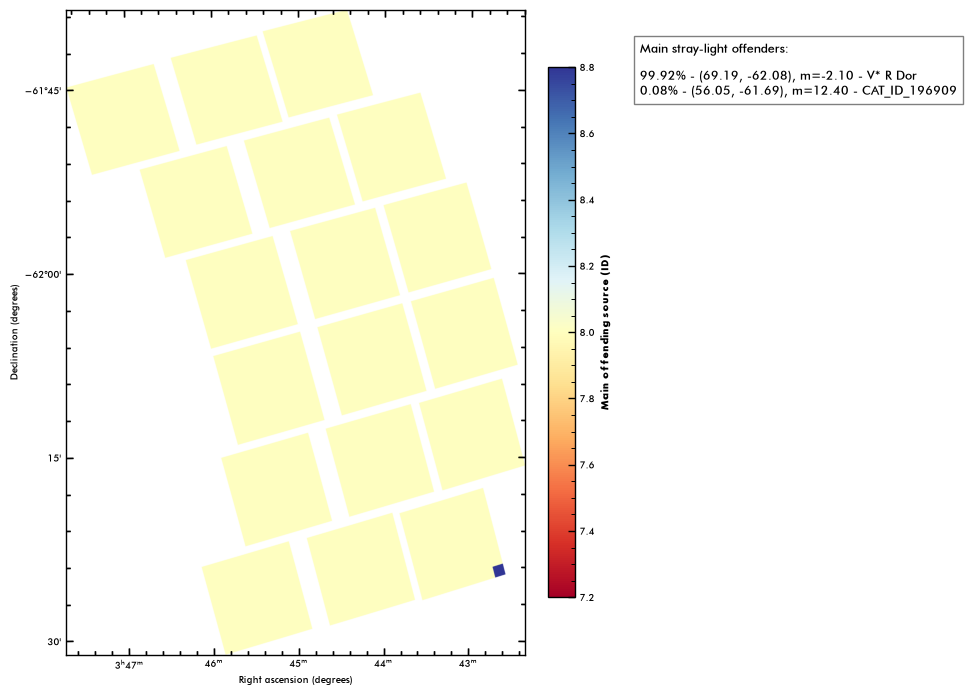

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


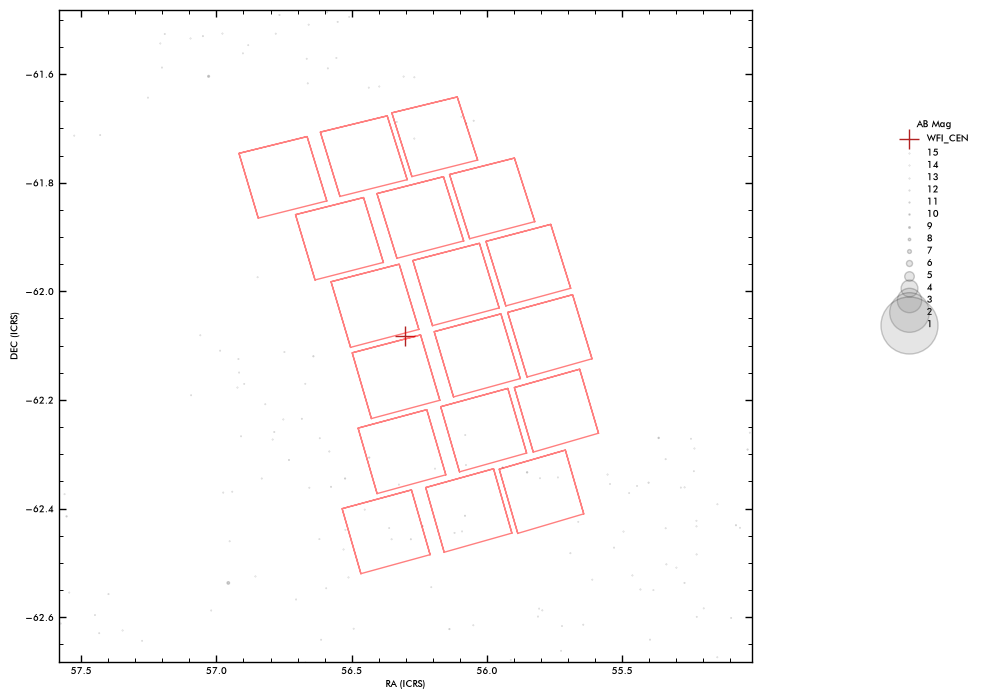

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196909]
Unique IDs with counts > 1:
[     8 196909]
V* R Dor
Simbad cannot find the name of the offender at 56.04905 - -61.685978
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (56.05, -61.69), m=12.40 - CAT_ID_196909
2026-10-24T14:58:36.085977 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_055_Roman_RA_056.301_DEC_-62.082_MJD_61352.00000_PA_105.71_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_055_Roman_RA_056.301_DEC_-62.082_MJD_61352.00000_PA_105.71_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T14:58:52.694901 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minute

2026-10-24 14:58:52 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 14:58:54 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣽
2026-10-24T14:59:48.402370 > Done.


18it [00:03,  4.94it/s]

2026-10-24T14:59:52.060239 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.52s/it]


2026-10-24T15:00:38.392656 > Done : 0:00:46.332432 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:00:39.379323 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:00:48.997524 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


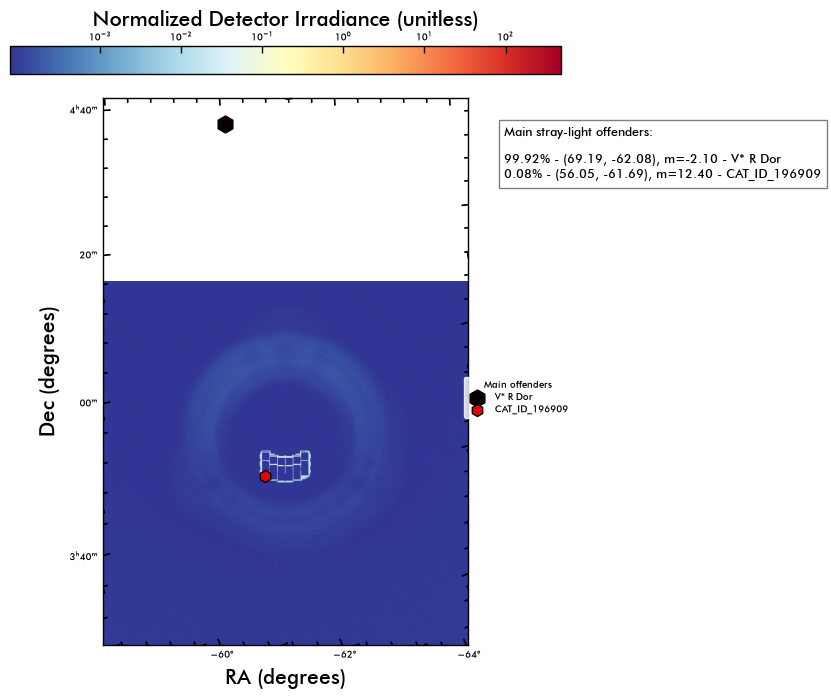

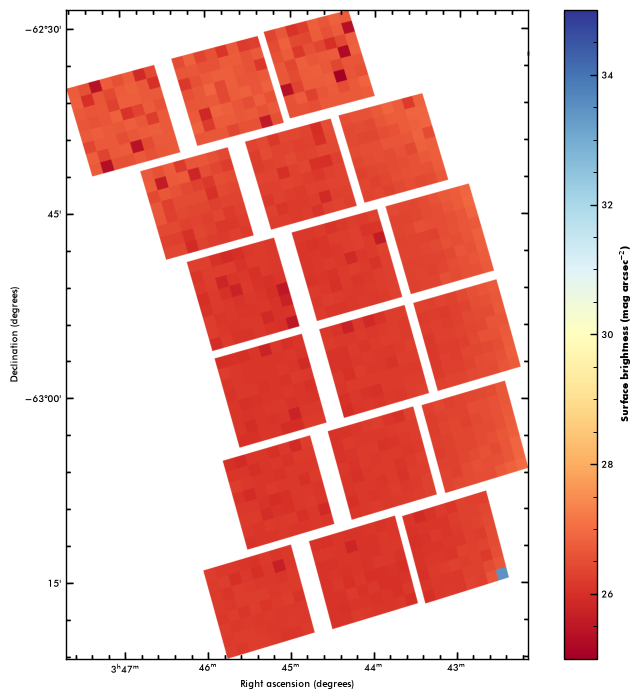

Plot: Stray-light surface brightness flux.
0.009396264
0.018650852


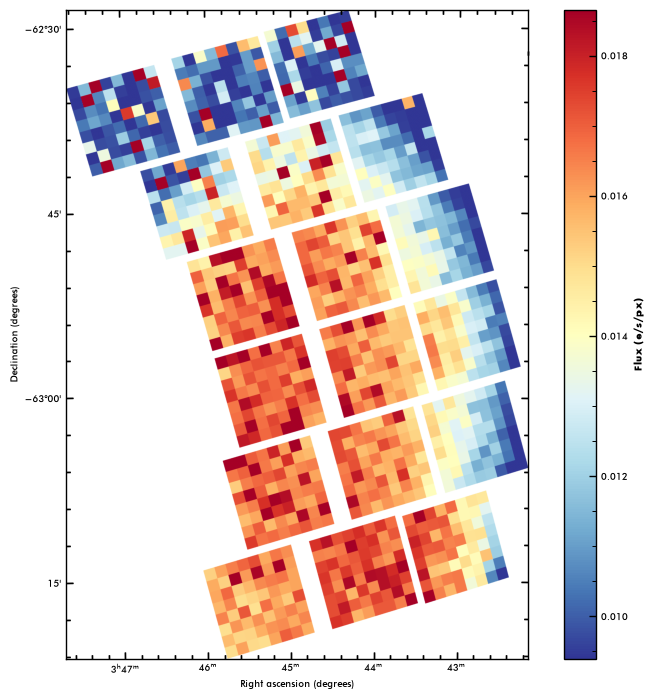

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8    134 196922 196978]
Unique IDs with counts > 1:
[     8    134 196922 196978]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
Simbad cannot find the name of the offender at 56.485287 - -63.03023
Simbad cannot find the name of the offender at 56.240307 - -62.85658
Main stray-light offenders:

97.74% - (69.19, -62.08), m=-2.10 - V* R Dor
2.08% - (60.23, -62.16), m=1.32 - CAT_ID_134
0.09% - (56.24, -62.86), m=13.09 - CAT_ID_196978
0.08% - (56.49, -63.03), m=12.53 - CAT_ID_196922


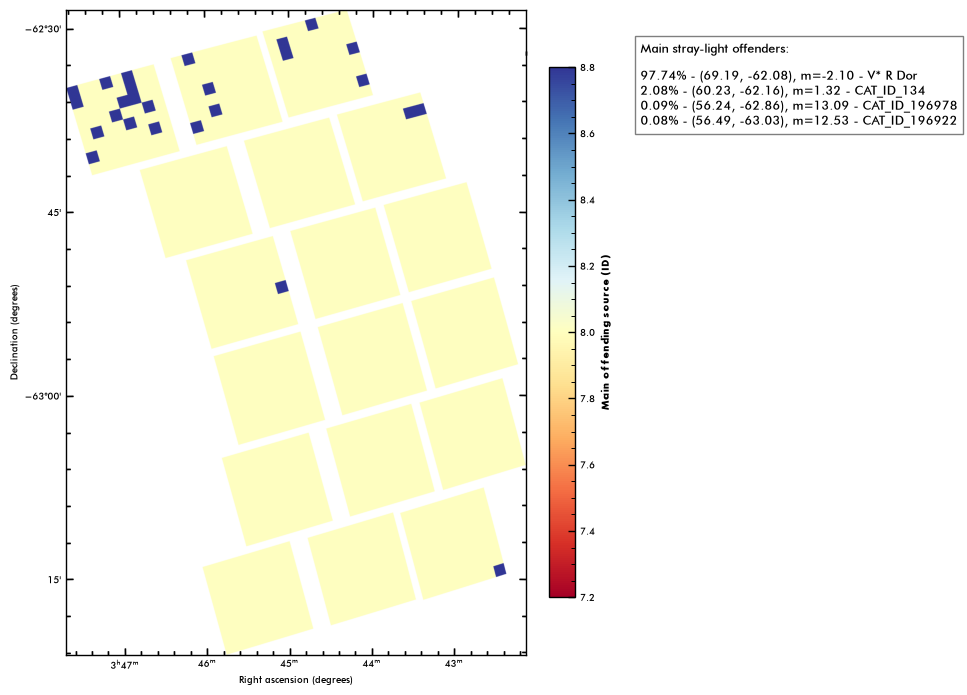

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


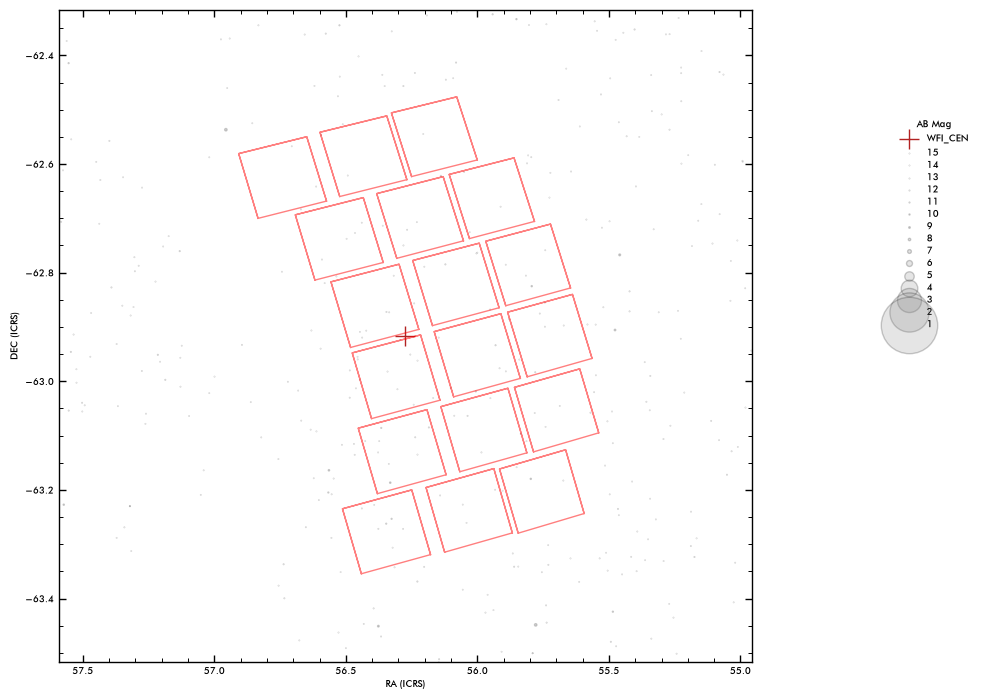

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8    134 196922 196978]
Unique IDs with counts > 1:
[     8    134 196922 196978]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
Simbad cannot find the name of the offender at 56.485287 - -63.03023
Simbad cannot find the name of the offender at 56.240307 - -62.85658
Main stray-light offenders:

97.74% - (69.19, -62.08), m=-2.10 - V* R Dor
2.08% - (60.23, -62.16), m=1.32 - CAT_ID_134
0.09% - (56.24, -62.86), m=13.09 - CAT_ID_196978
0.08% - (56.49, -63.03), m=12.53 - CAT_ID_196922
2026-10-24T15:00:57.784540 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_056_Roman_RA_056.273_DEC_-62.916_MJD_61352.00000_PA_105.82_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_056_Roman_RA_056.273_DEC_-62.916_MJD_61352.00000_PA_105.82_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:01:14.649958 > Fetching source catal

2026-10-24 15:01:14 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

2026-10-24 15:01:16 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T15:02:14.731046 > Done.


18it [00:03,  5.13it/s]

2026-10-24T15:02:18.246269 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:44<00:00,  2.47s/it]


2026-10-24T15:03:03.896281 > Done : 0:00:45.650027 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:03:04.885526 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:03:14.482102 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


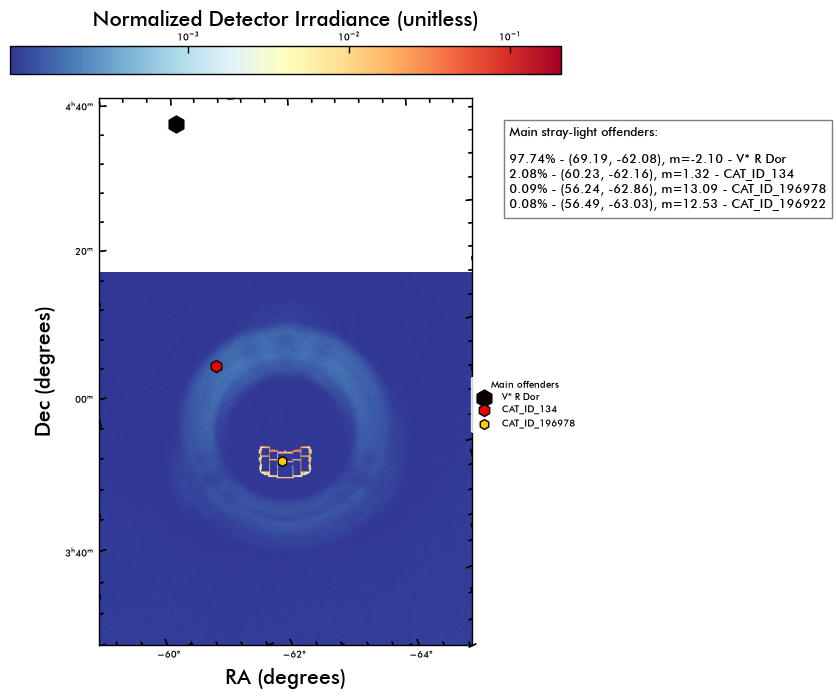

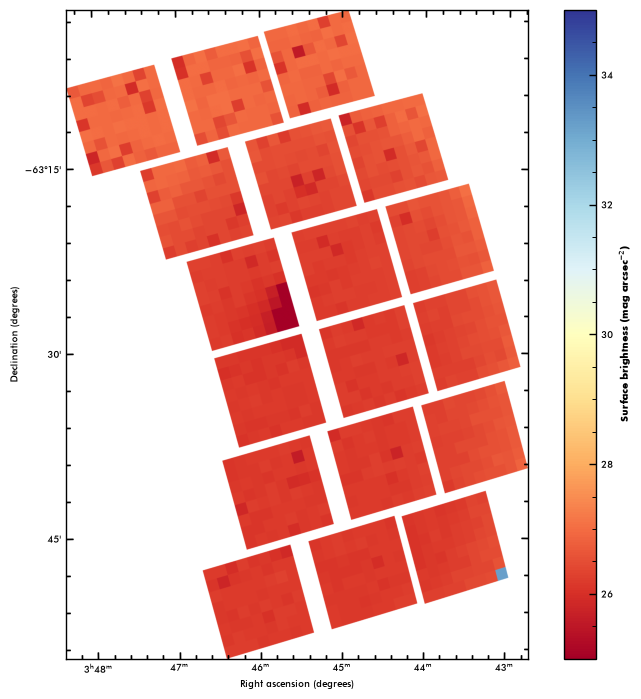

Plot: Stray-light surface brightness flux.
0.0075880066
0.017980285


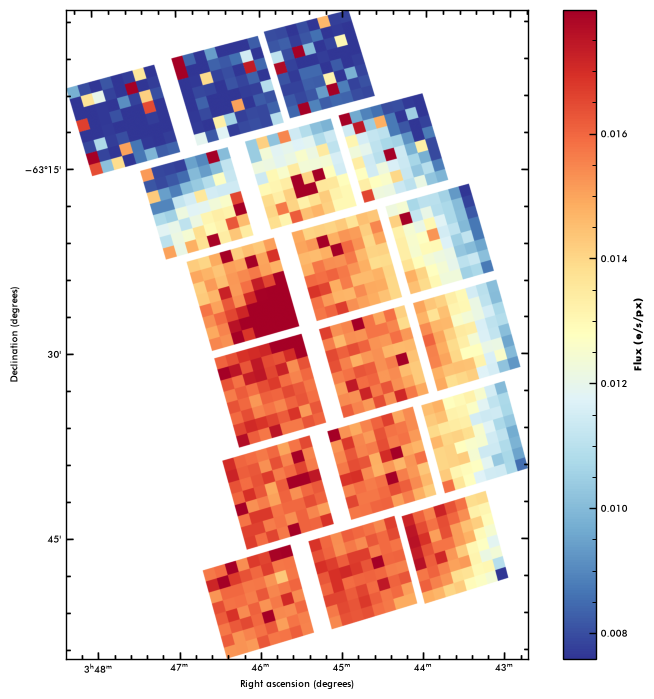

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196156 196839 196936]
Unique IDs with counts > 1:
[     8 196156 196839 196936]
V* R Dor
TYC 8870-533-1
CPD-63   257
UCAC4 133-003481
Main stray-light offenders:

99.38% - (69.19, -62.08), m=-2.10 - V* R Dor
0.36% - (56.38, -63.45), m=8.96 - TYC 8870-533-1
0.18% - (56.39, -63.42), m=12.48 - UCAC4 133-003481
0.08% - (56.33, -63.19), m=9.50 - CPD-63   257


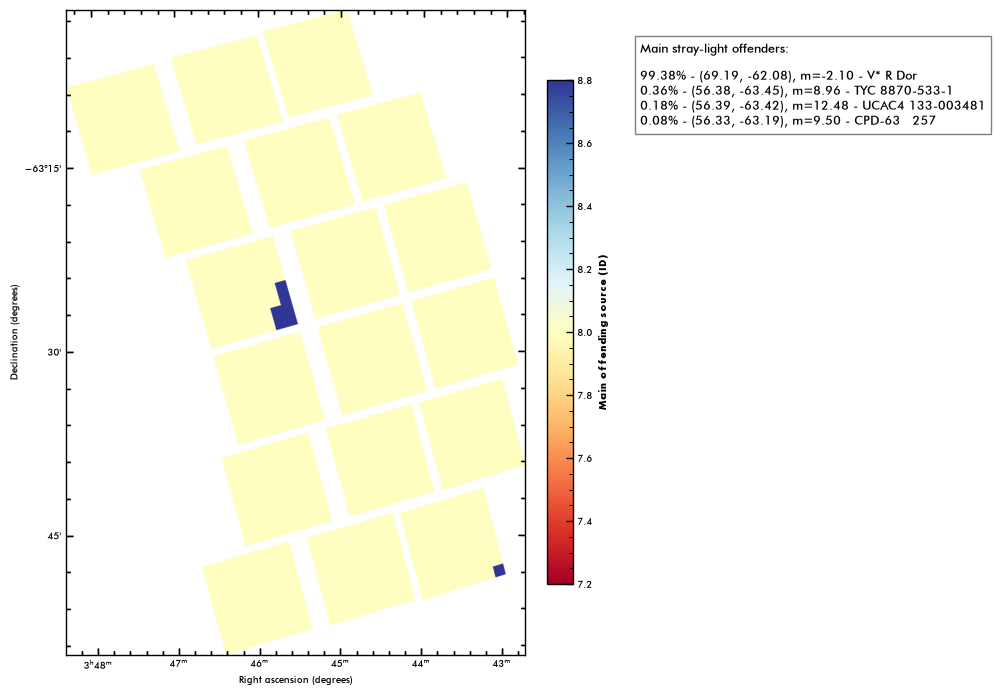

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


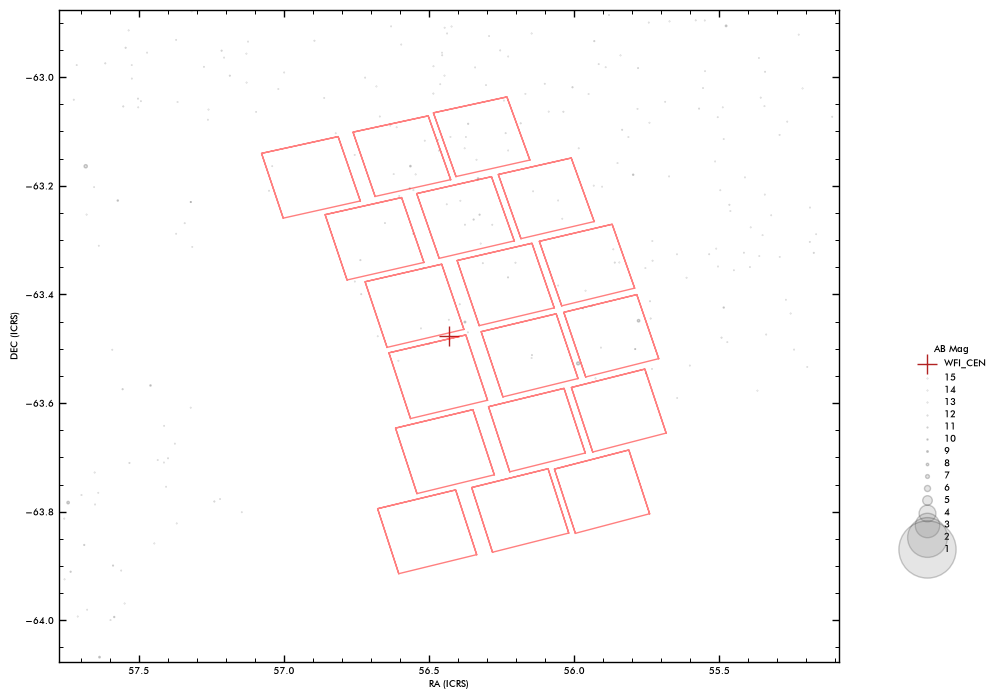

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196156 196839 196936]
Unique IDs with counts > 1:
[     8 196156 196839 196936]
V* R Dor
TYC 8870-533-1
CPD-63   257
UCAC4 133-003481
Main stray-light offenders:

99.38% - (69.19, -62.08), m=-2.10 - V* R Dor
0.36% - (56.38, -63.45), m=8.96 - TYC 8870-533-1
0.18% - (56.39, -63.42), m=12.48 - UCAC4 133-003481
0.08% - (56.33, -63.19), m=9.50 - CPD-63   257
2026-10-24T15:03:23.759846 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_057_Roman_RA_056.432_DEC_-63.476_MJD_61352.00000_PA_105.74_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_057_Roman_RA_056.432_DEC_-63.476_MJD_61352.00000_PA_105.74_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:03:40.274339 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to pr

2026-10-24 15:03:40 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 15:03:41 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T15:03:53.140124 > Done.


18it [00:03,  4.98it/s]

2026-10-24T15:03:56.762277 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:44<00:00,  2.46s/it]


2026-10-24T15:04:42.179967 > Done : 0:00:45.417714 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:04:43.195966 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:04:52.924894 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


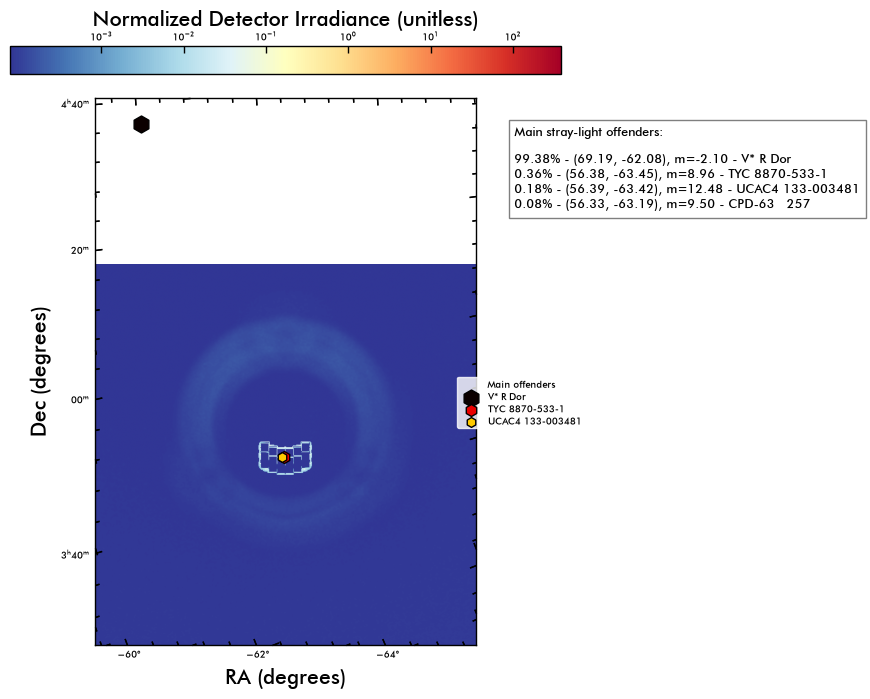

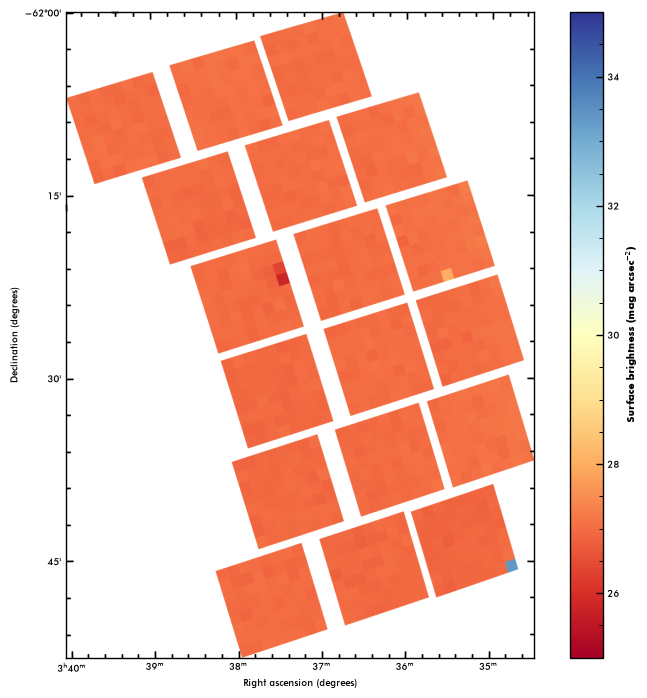

Plot: Stray-light surface brightness flux.
0.006735153
0.008182386


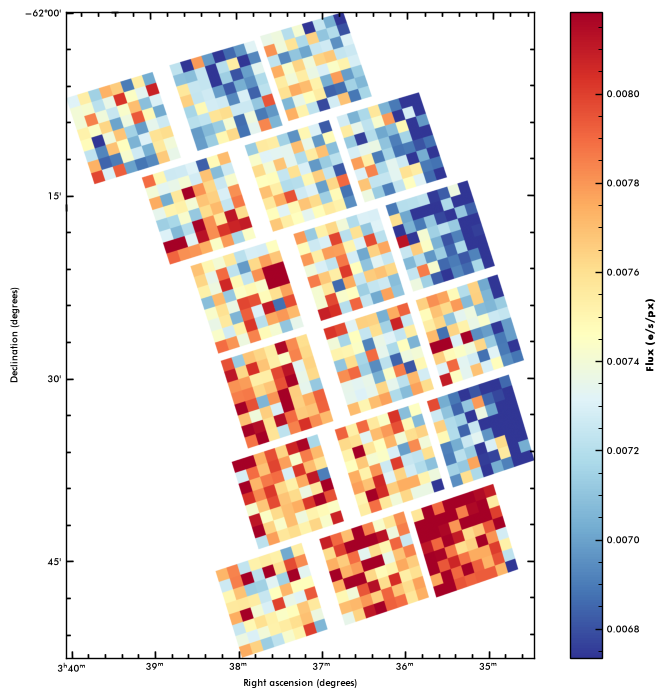

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196859 197023]
Unique IDs with counts > 1:
[     8 196859 197023]
V* R Dor
TYC 8867-293-1
Simbad cannot find the name of the offender at 54.340256 - -62.357624
Main stray-light offenders:

99.74% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (54.34, -62.36), m=13.49 - CAT_ID_197023
0.08% - (54.23, -62.48), m=10.59 - TYC 8867-293-1


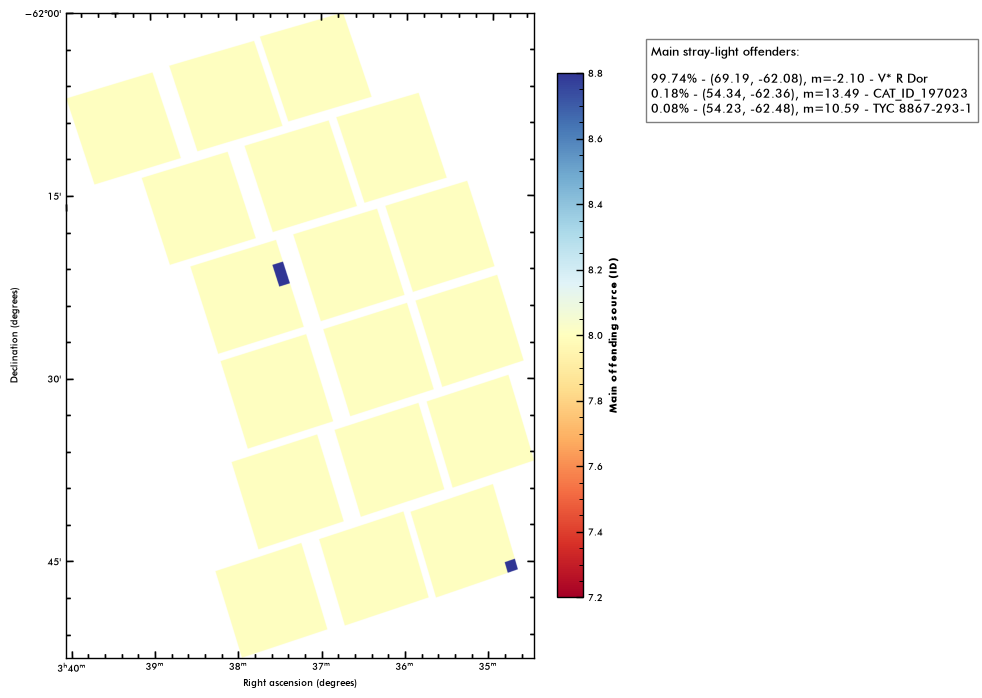

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


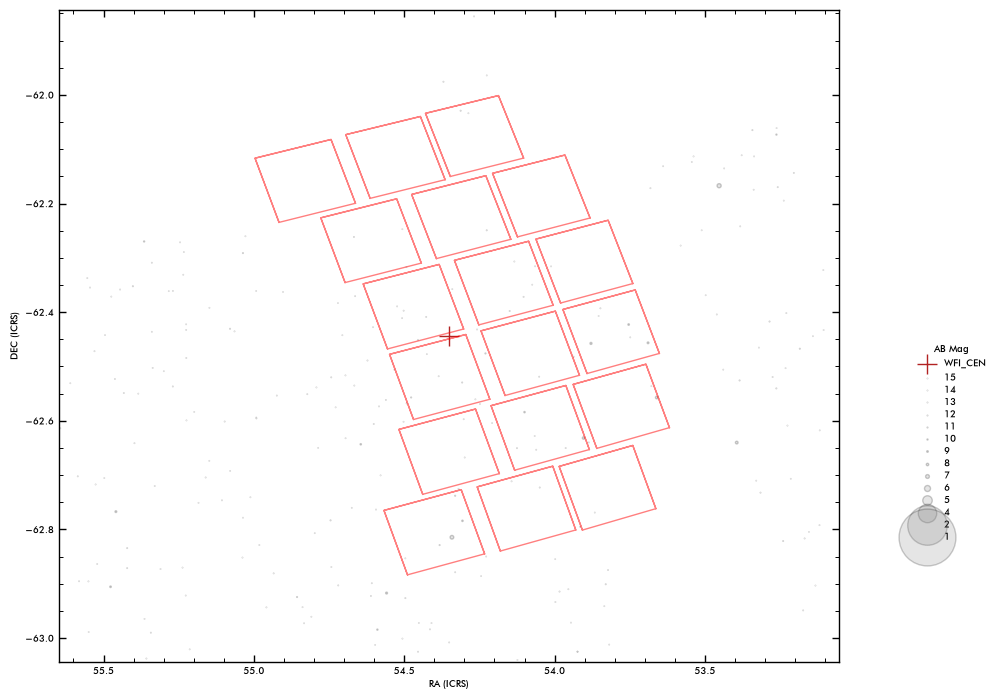

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196859 197023]
Unique IDs with counts > 1:
[     8 196859 197023]
V* R Dor
TYC 8867-293-1
Simbad cannot find the name of the offender at 54.340256 - -62.357624
Main stray-light offenders:

99.74% - (69.19, -62.08), m=-2.10 - V* R Dor
0.18% - (54.34, -62.36), m=13.49 - CAT_ID_197023
0.08% - (54.23, -62.48), m=10.59 - TYC 8867-293-1
2026-10-24T15:05:01.920841 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_058_Roman_RA_054.352_DEC_-62.444_MJD_61352.00000_PA_107.46_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_058_Roman_RA_054.352_DEC_-62.444_MJD_61352.00000_PA_107.46_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:05:18.387544 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patien

2026-10-24 15:05:18 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 15:05:19 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T15:05:30.717568 > Done.


18it [00:03,  4.98it/s]

2026-10-24T15:05:34.340555 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.53s/it]


2026-10-24T15:06:20.981187 > Done : 0:00:46.640649 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:06:21.975681 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:06:31.735715 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


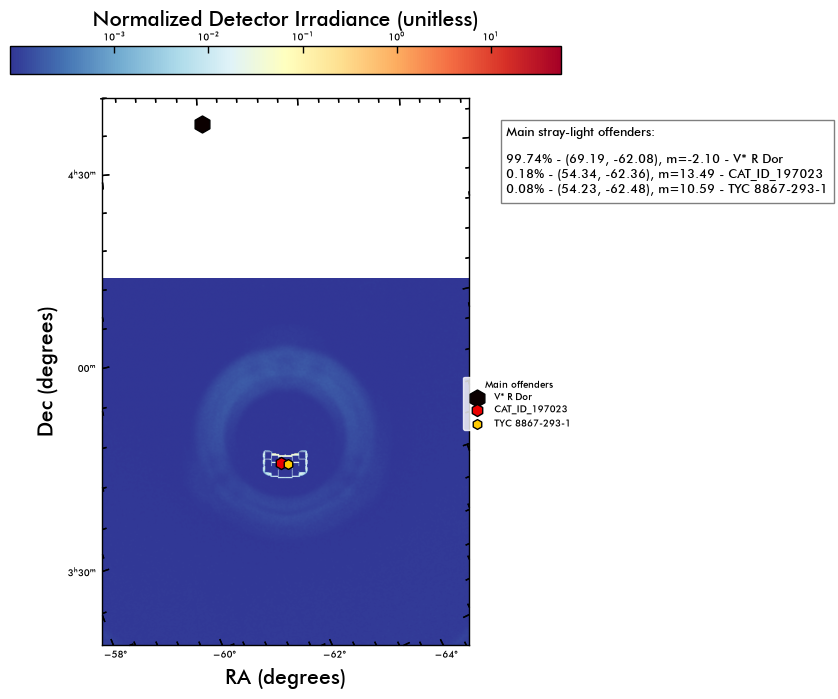

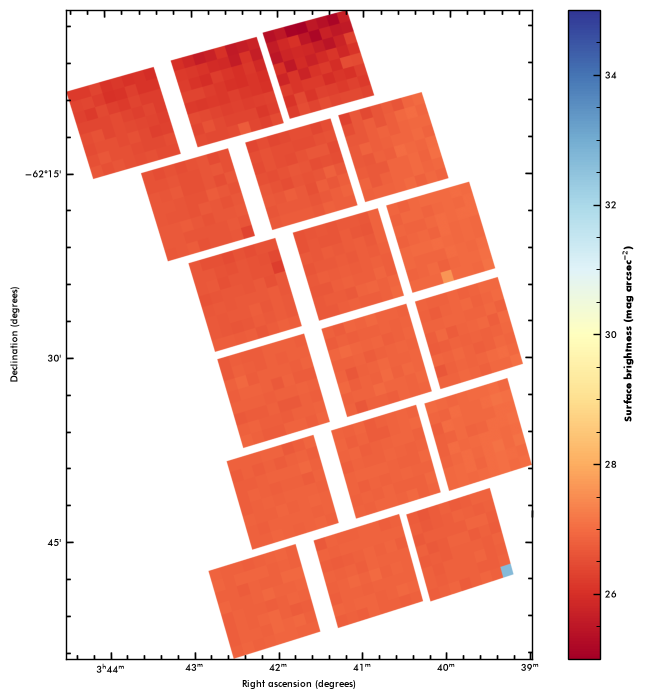

Plot: Stray-light surface brightness flux.
0.007664062
0.01766384


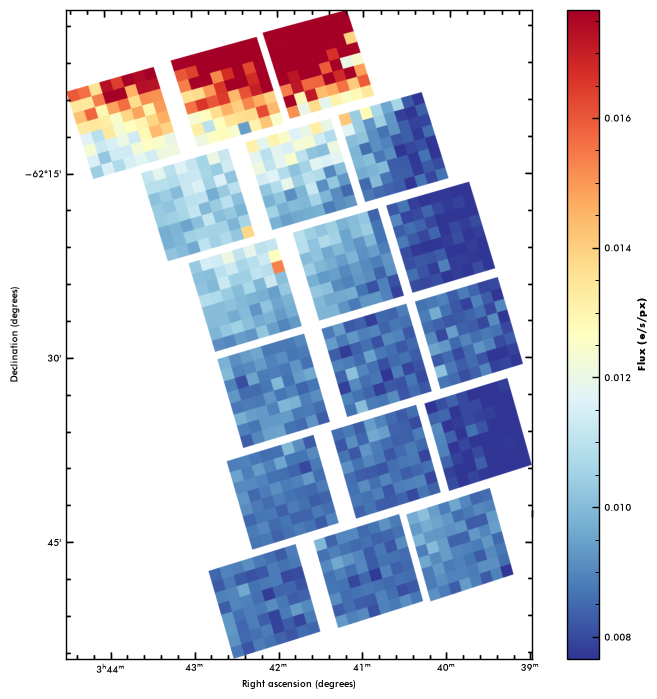

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8    134    396 196855 197005 197212]
Unique IDs with counts > 1:
[     8    134    396 196855 197005 197212]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
Simbad cannot find the name of the offender at 48.1281 - -57.30644
CPD-62   293
Simbad cannot find the name of the offender at 55.55411 - -62.33732
Simbad cannot find the name of the offender at 55.474323 - -62.371403
Main stray-light offenders:

99.33% - (69.19, -62.08), m=-2.10 - V* R Dor
0.33% - (48.13, -57.31), m=2.21 - CAT_ID_396
0.09% - (55.55, -62.34), m=13.28 - CAT_ID_197005
0.09% - (55.47, -62.37), m=14.33 - CAT_ID_197212
0.08% - (55.85, -62.33), m=10.14 - CPD-62   293
0.08% - (60.23, -62.16), m=1.32 - CAT_ID_134


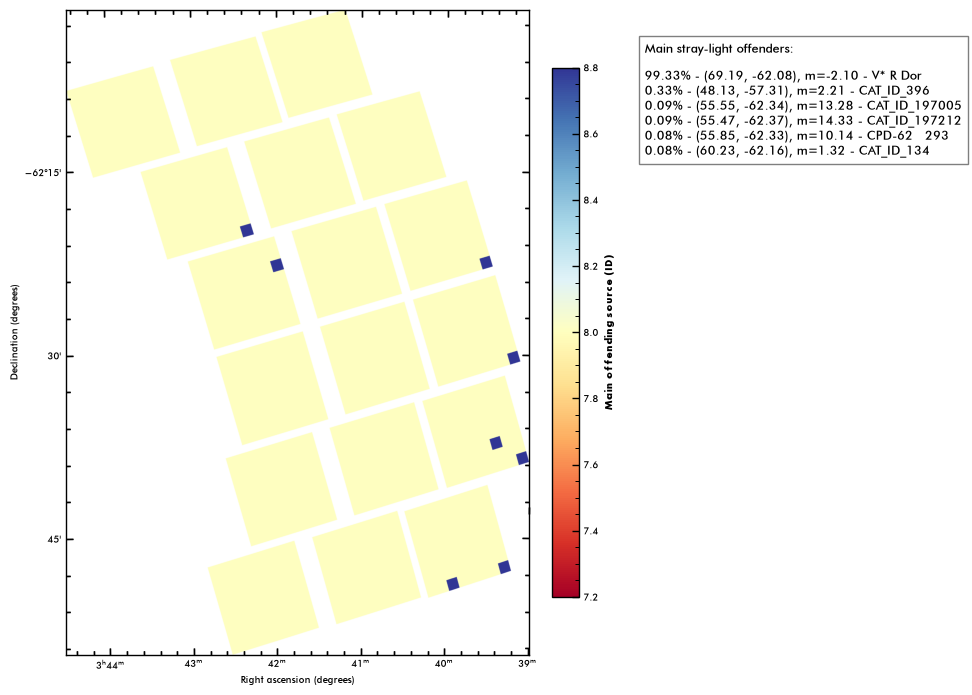

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


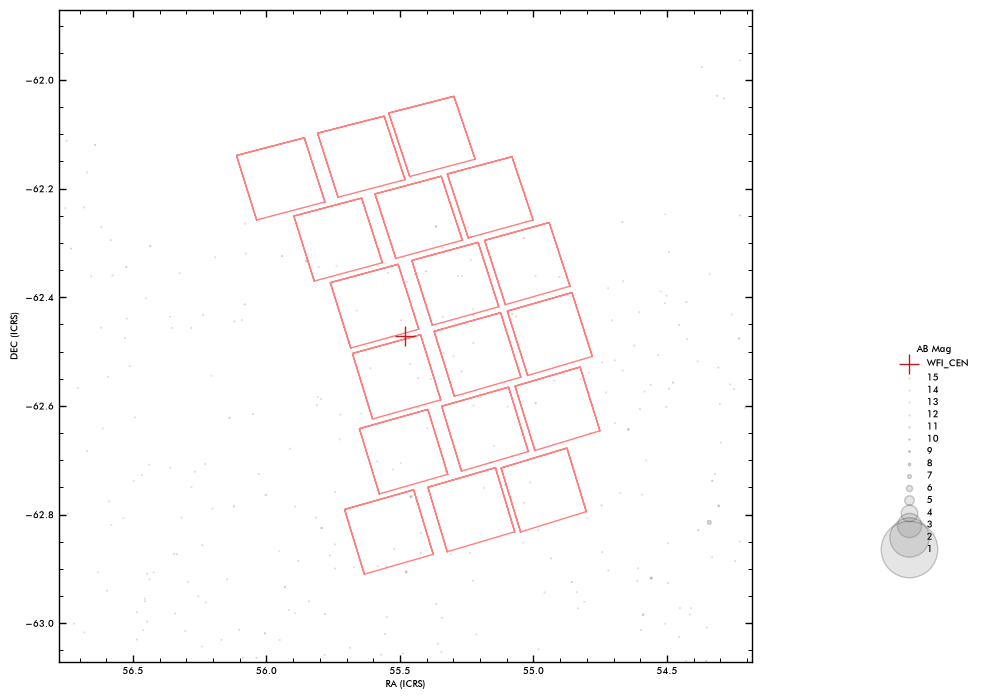

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8    134    396 196855 197005 197212]
Unique IDs with counts > 1:
[     8    134    396 196855 197005 197212]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
Simbad cannot find the name of the offender at 48.1281 - -57.30644
CPD-62   293
Simbad cannot find the name of the offender at 55.55411 - -62.33732
Simbad cannot find the name of the offender at 55.474323 - -62.371403
Main stray-light offenders:

99.33% - (69.19, -62.08), m=-2.10 - V* R Dor
0.33% - (48.13, -57.31), m=2.21 - CAT_ID_396
0.09% - (55.55, -62.34), m=13.28 - CAT_ID_197005
0.09% - (55.47, -62.37), m=14.33 - CAT_ID_197212
0.08% - (55.85, -62.33), m=10.14 - CPD-62   293
0.08% - (60.23, -62.16), m=1.32 - CAT_ID_134
2026-10-24T15:06:40.691117 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_059_Roman_RA_055.479_DEC_-62.471_MJD_61352.00000_PA_106.47_stray.fits
Report saved in: /Users/aborlaff/N

2026-10-24 15:06:57 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

2026-10-24 15:06:58 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⢿
2026-10-24T15:07:09.855918 > Done.


18it [00:03,  5.00it/s]

2026-10-24T15:07:13.467222 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.58s/it]


2026-10-24T15:08:01.033117 > Done : 0:00:47.565912 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:08:02.085350 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:08:11.812117 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


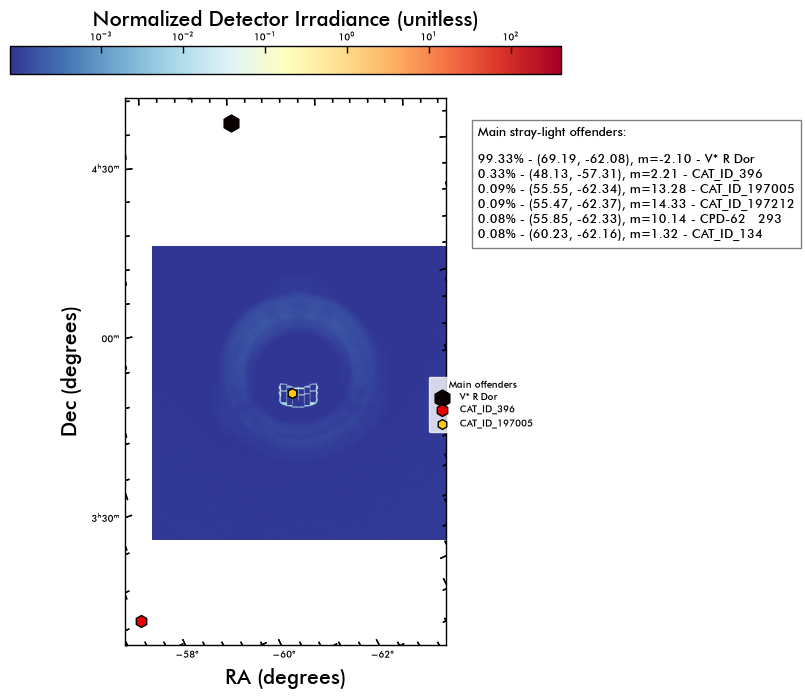

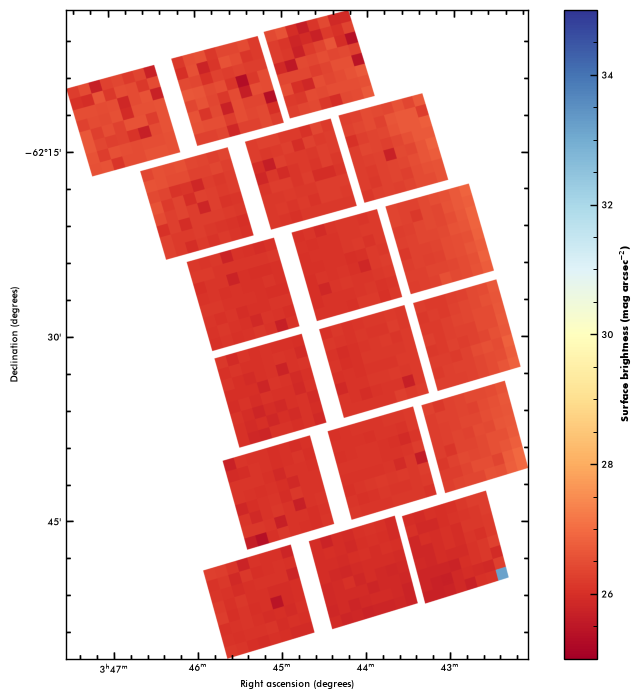

Plot: Stray-light surface brightness flux.
0.0108338455
0.02214424


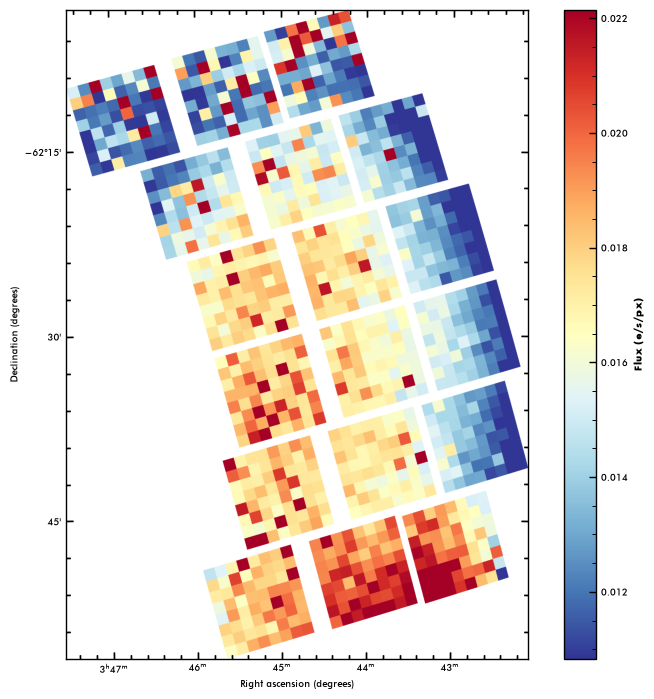

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8    134 196864]
Unique IDs with counts > 1:
[     8    134 196864]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
CPD-62   297
Main stray-light offenders:

99.39% - (69.19, -62.08), m=-2.10 - V* R Dor
0.53% - (60.23, -62.16), m=1.32 - CAT_ID_134
0.08% - (56.64, -62.12), m=11.09 - CPD-62   297


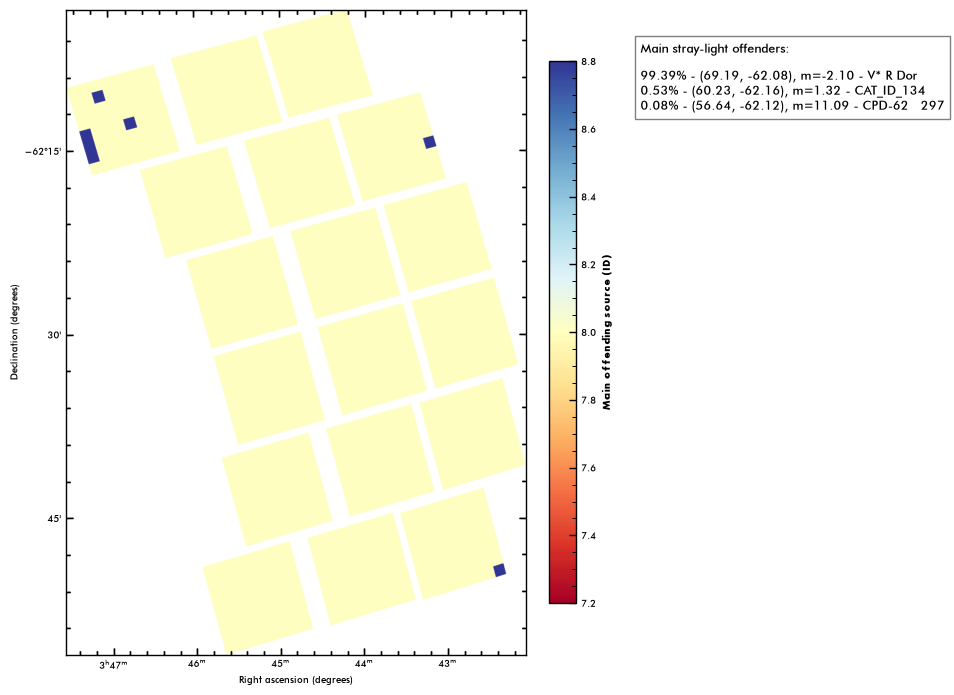

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


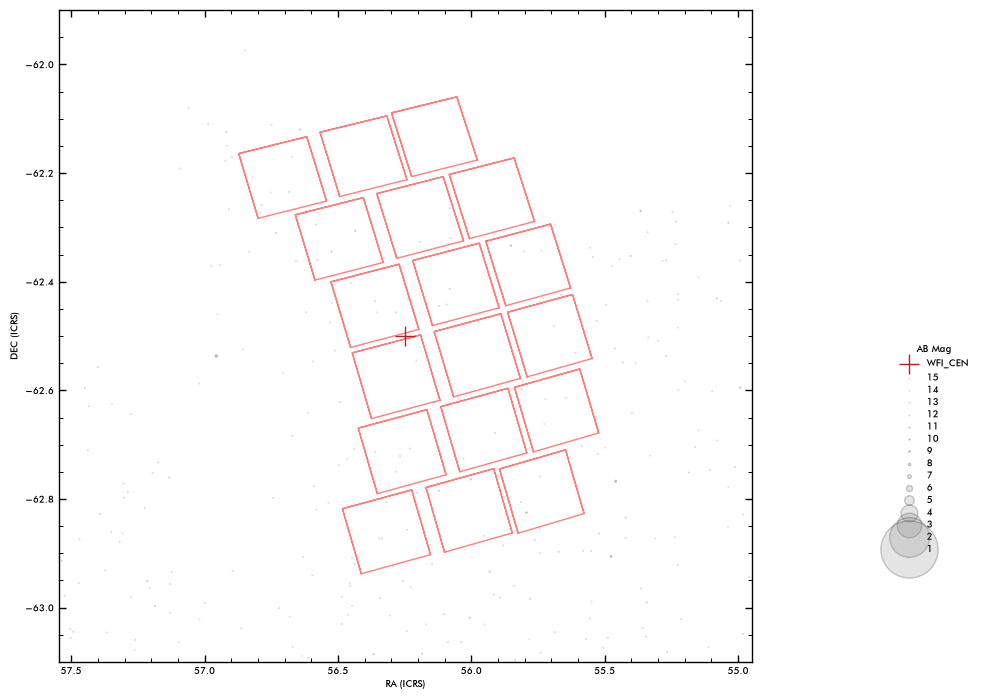

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8    134 196864]
Unique IDs with counts > 1:
[     8    134 196864]
V* R Dor
Simbad cannot find the name of the offender at 60.23141 - -62.1605
CPD-62   297
Main stray-light offenders:

99.39% - (69.19, -62.08), m=-2.10 - V* R Dor
0.53% - (60.23, -62.16), m=1.32 - CAT_ID_134
0.08% - (56.64, -62.12), m=11.09 - CPD-62   297
2026-10-24T15:08:20.533849 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_060_Roman_RA_056.247_DEC_-62.500_MJD_61352.00000_PA_105.80_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_ROGUEPATH_060_Roman_RA_056.247_DEC_-62.500_MJD_61352.00000_PA_105.80_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:08:36.997425 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying

2026-10-24 15:08:37 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

2026-10-24 15:08:38 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T15:09:35.226394 > Done.


18it [00:03,  5.07it/s]

2026-10-24T15:09:38.786709 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.55s/it]


2026-10-24T15:10:25.669417 > Done : 0:00:46.882729 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:10:26.664016 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:10:34.506905 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


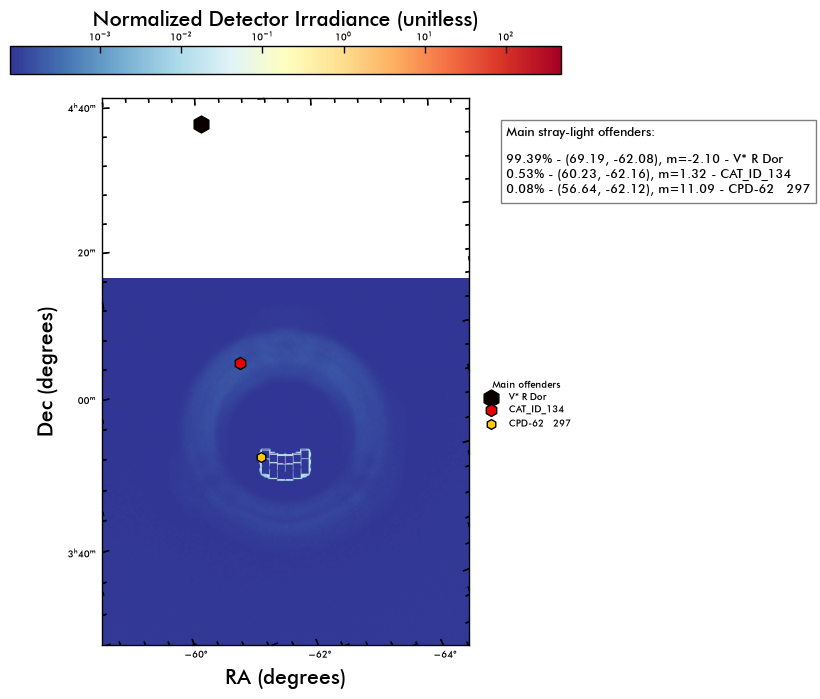

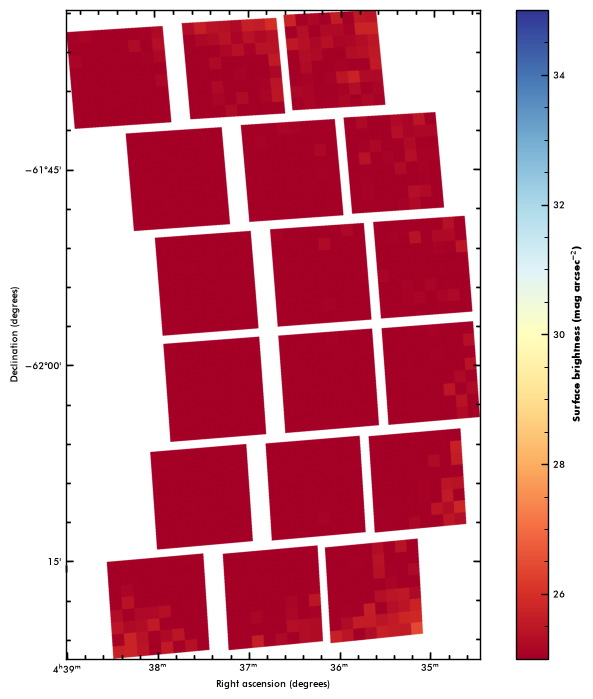

Plot: Stray-light surface brightness flux.
0.03212769
26.924736


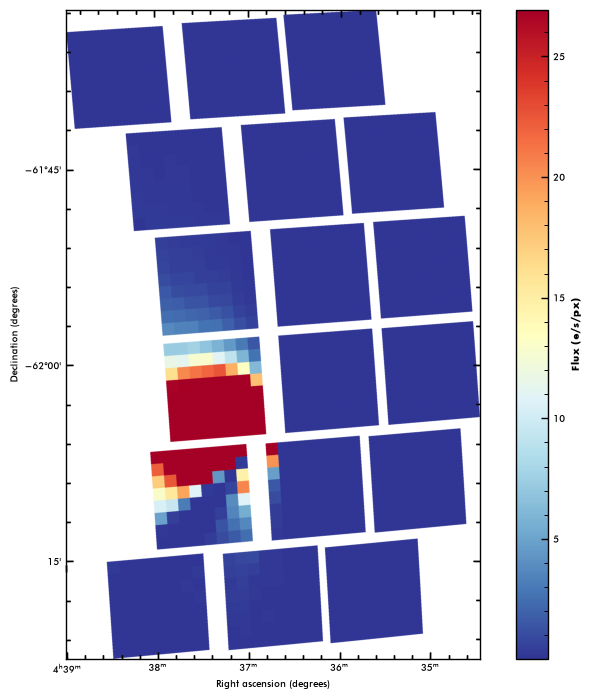

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


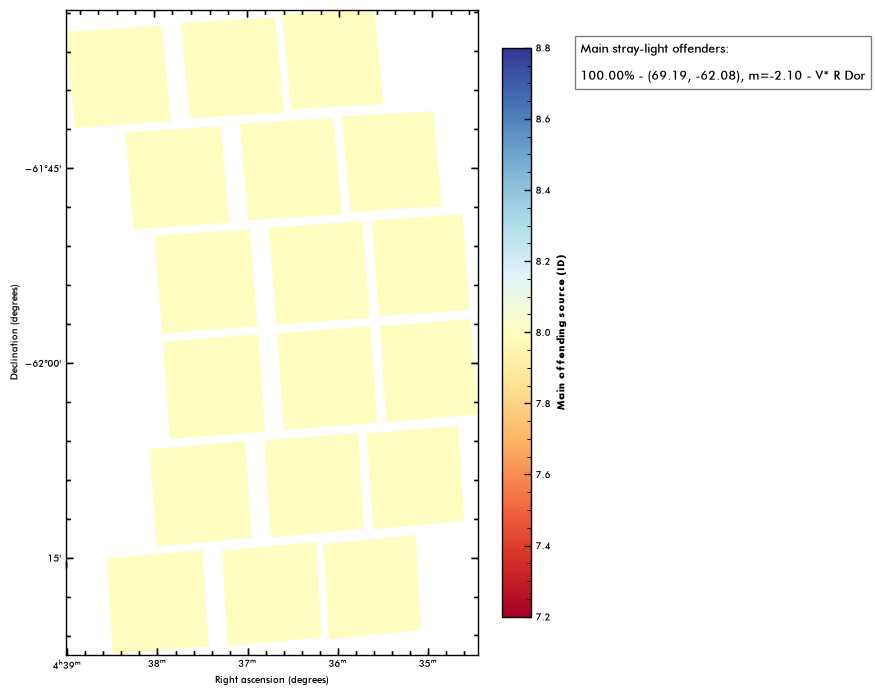

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


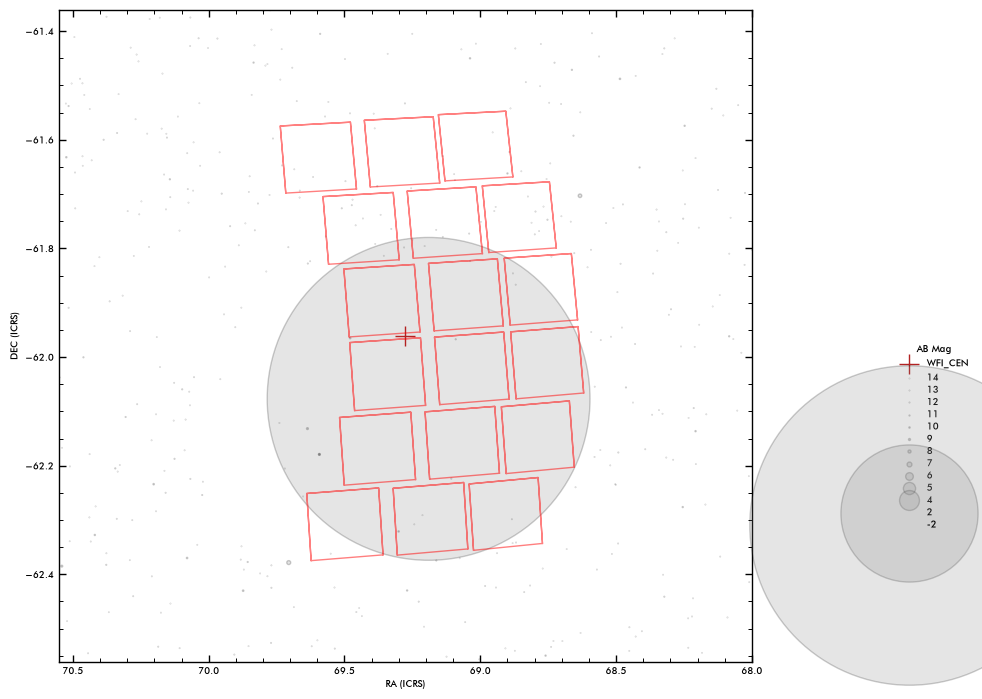

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:10:42.157174 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_061_Roman_RA_069.275_DEC_-61.961_MJD_61352.00000_PA_094.31_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_061_Roman_RA_069.275_DEC_-61.961_MJD_61352.00000_PA_094.31_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:10:58.771603 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:10:58 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 15:11:00 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣾
2026-10-24T15:11:11.060523 > Done.


18it [00:03,  4.92it/s]

2026-10-24T15:11:14.728543 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:47<00:00,  2.66s/it]


2026-10-24T15:12:03.626852 > Done : 0:00:48.898328 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:12:04.688161 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:12:12.567023 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


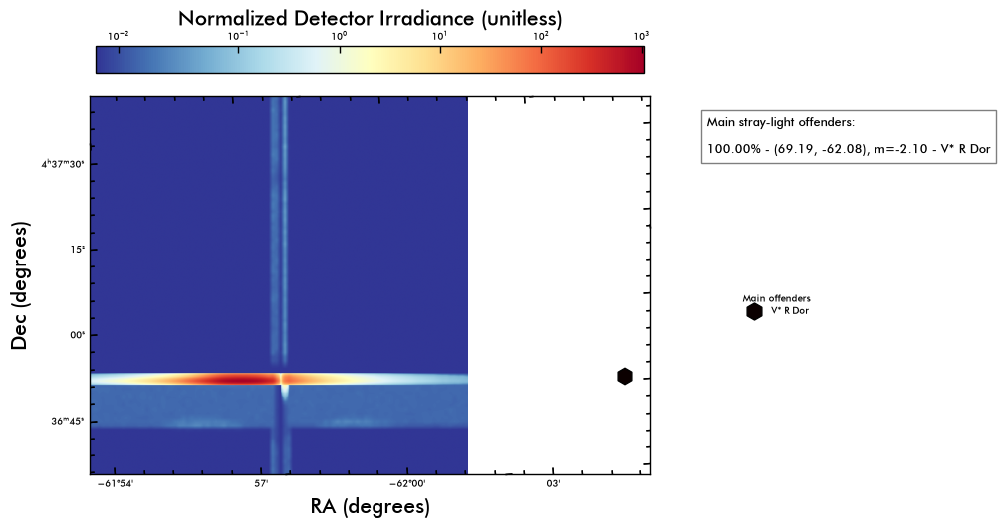

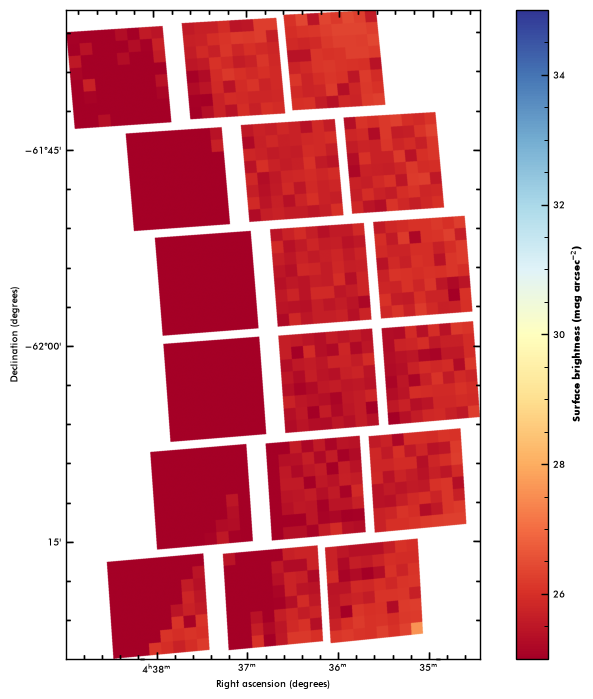

Plot: Stray-light surface brightness flux.
0.016202444
29.722137


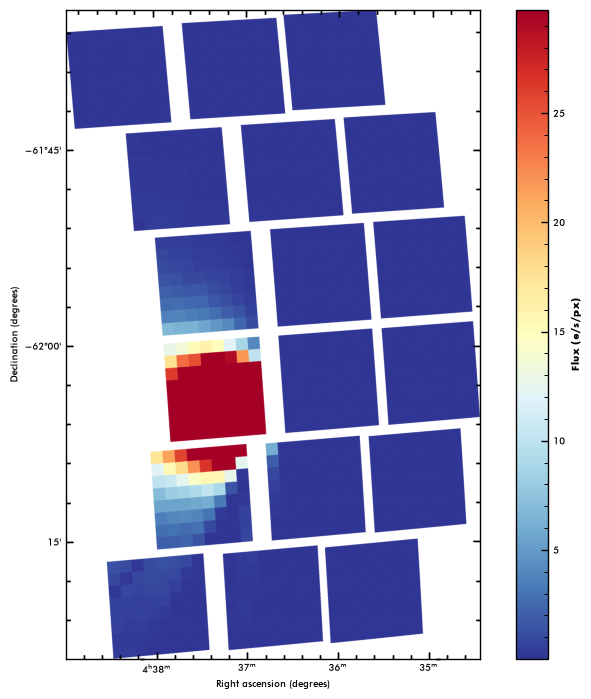

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


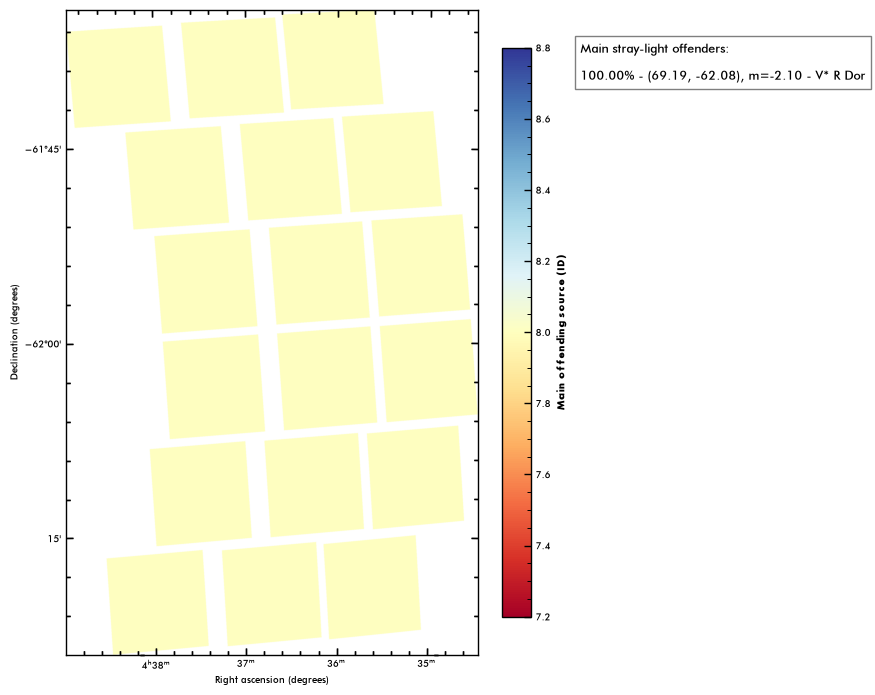

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


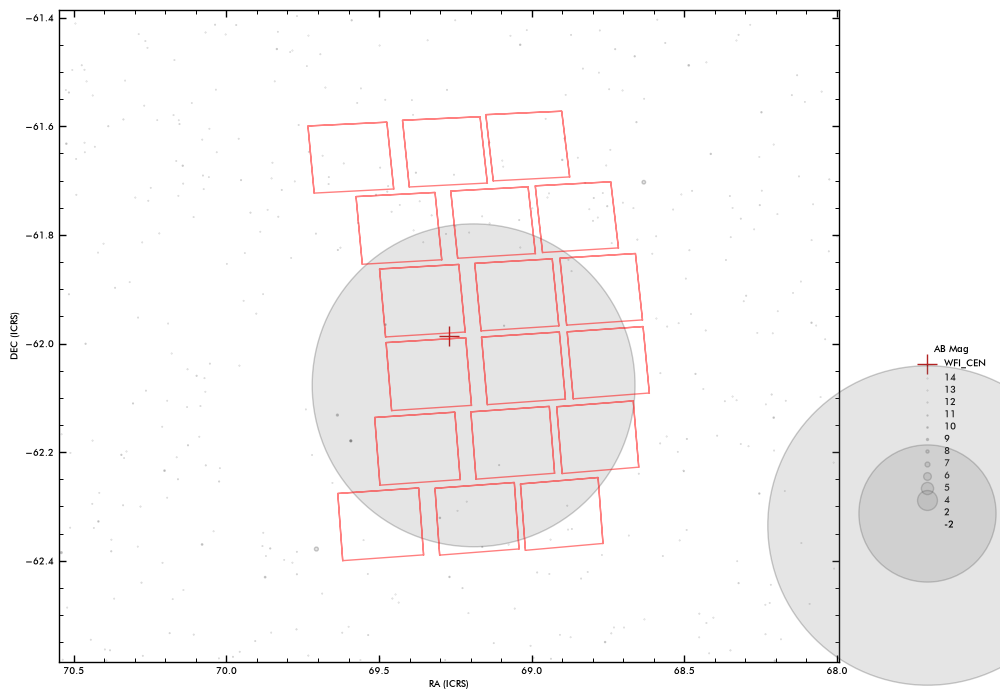

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:12:20.077851 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_062_Roman_RA_069.271_DEC_-61.986_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_062_Roman_RA_069.271_DEC_-61.986_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:12:36.620109 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:12:36 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

2026-10-24 15:12:38 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⢿
2026-10-24T15:12:48.834903 > Done.


18it [00:03,  4.90it/s]

2026-10-24T15:12:52.521672 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.50s/it]


2026-10-24T15:13:38.611777 > Done : 0:00:46.090127 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:13:39.653432 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:13:48.214754 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


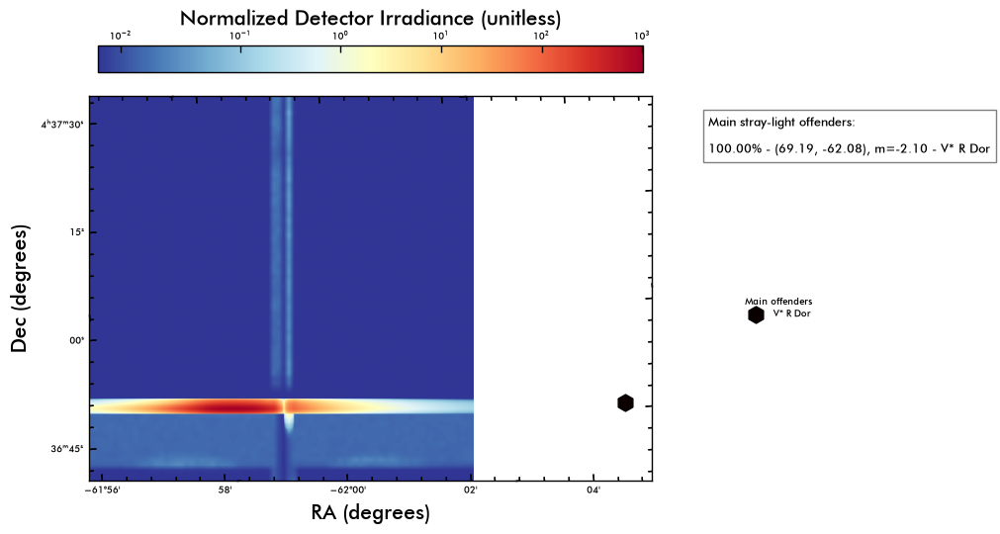

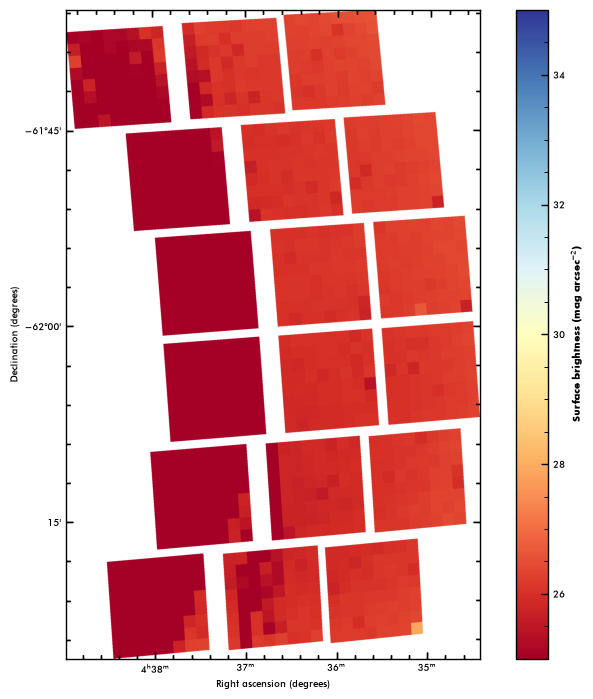

Plot: Stray-light surface brightness flux.
0.013782223
32.58525


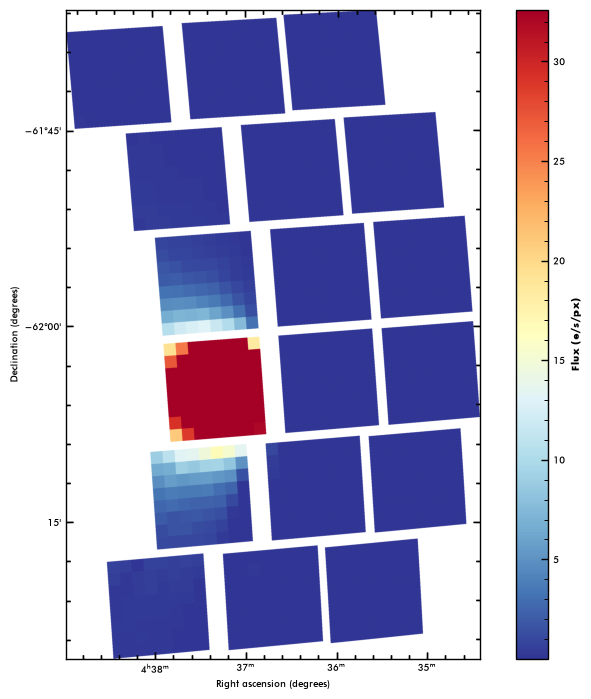

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


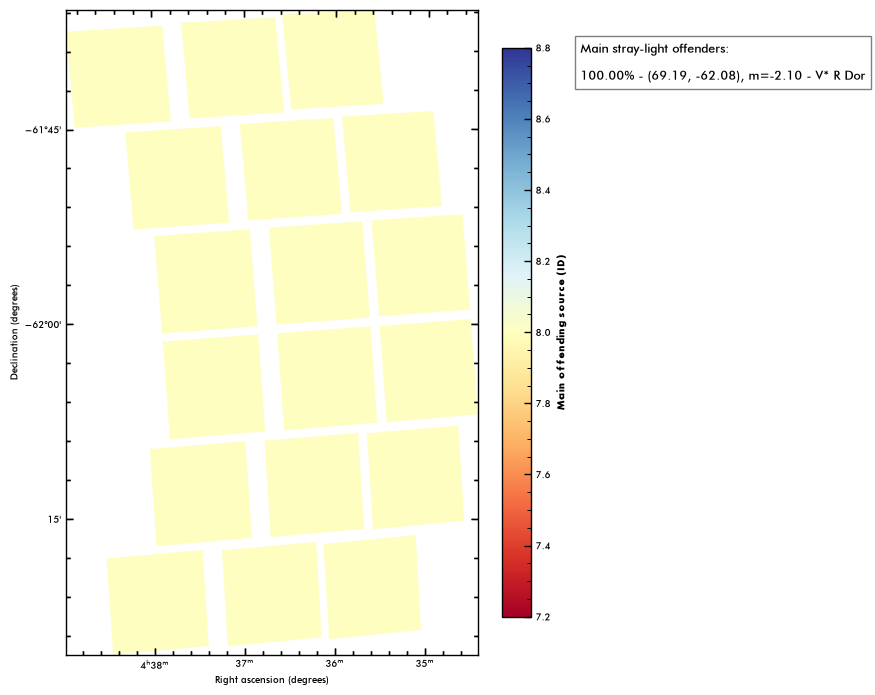

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


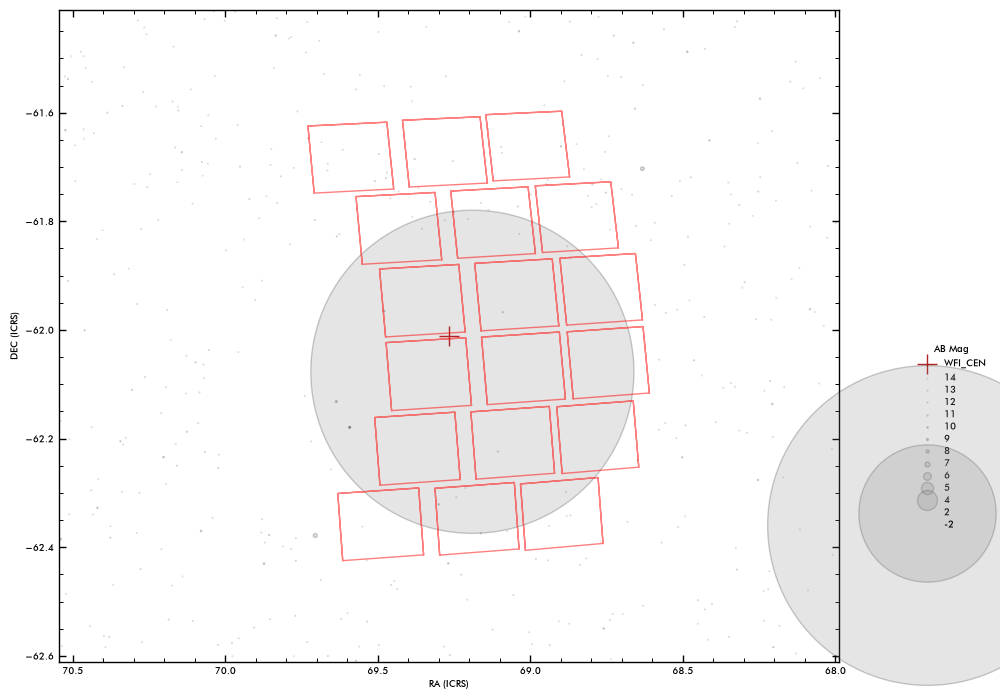

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:13:55.798762 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_063_Roman_RA_069.267_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_063_Roman_RA_069.267_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:14:12.316457 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:14:12 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

2026-10-24 15:14:13 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣷
2026-10-24T15:14:25.323673 > Done.


18it [00:03,  5.00it/s]

2026-10-24T15:14:28.935022 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.57s/it]


2026-10-24T15:15:16.400257 > Done : 0:00:47.465252 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:15:17.395932 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:15:25.291105 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


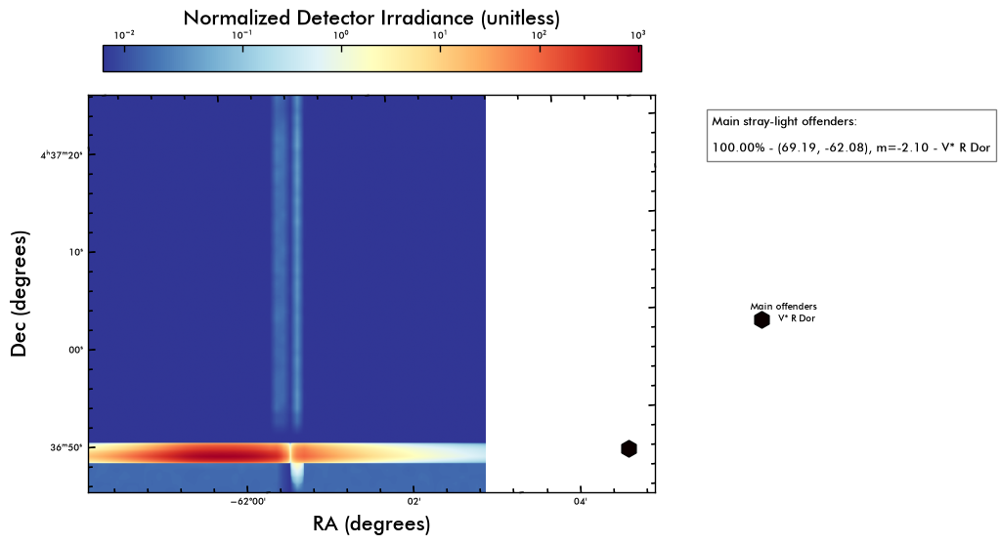

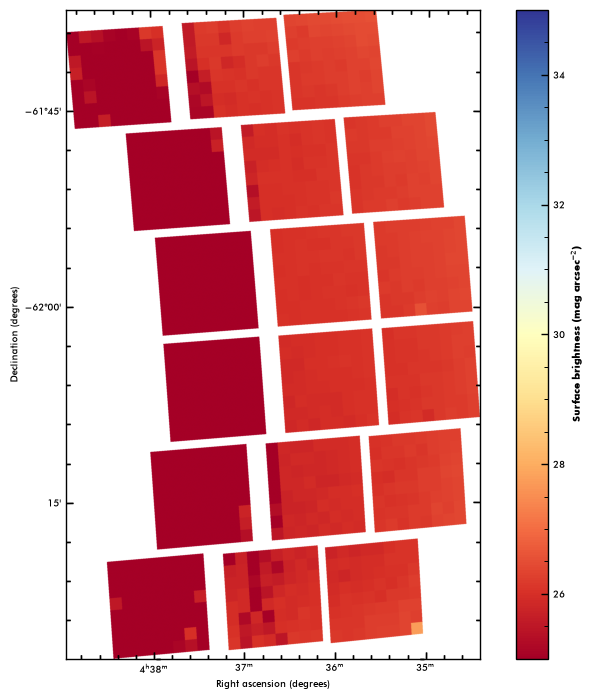

Plot: Stray-light surface brightness flux.
0.01389491
23.613039


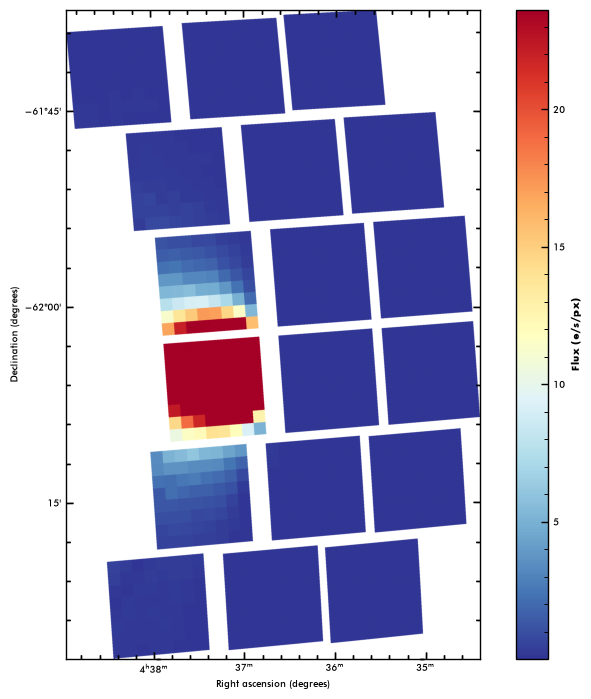

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


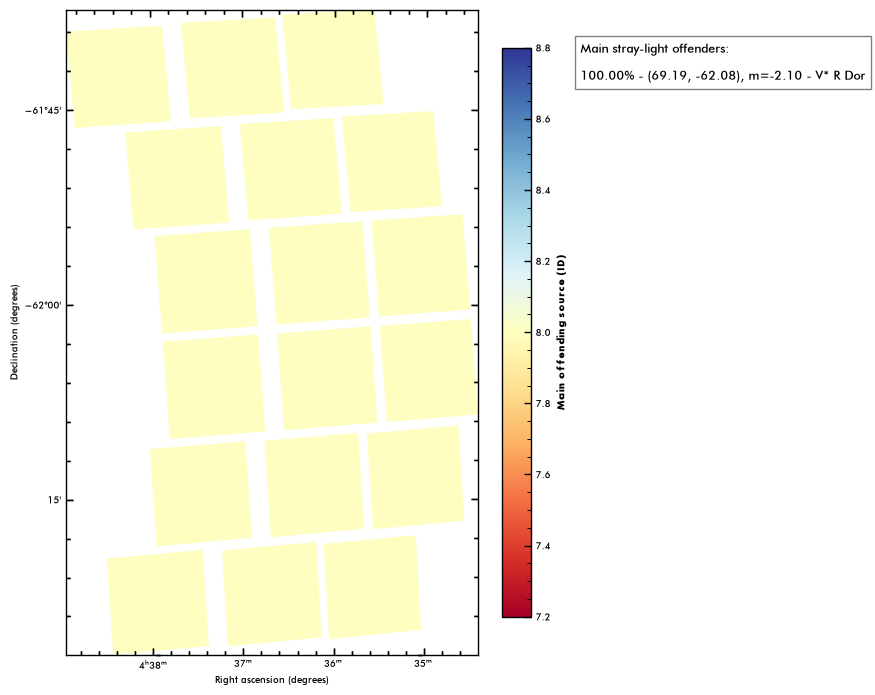

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


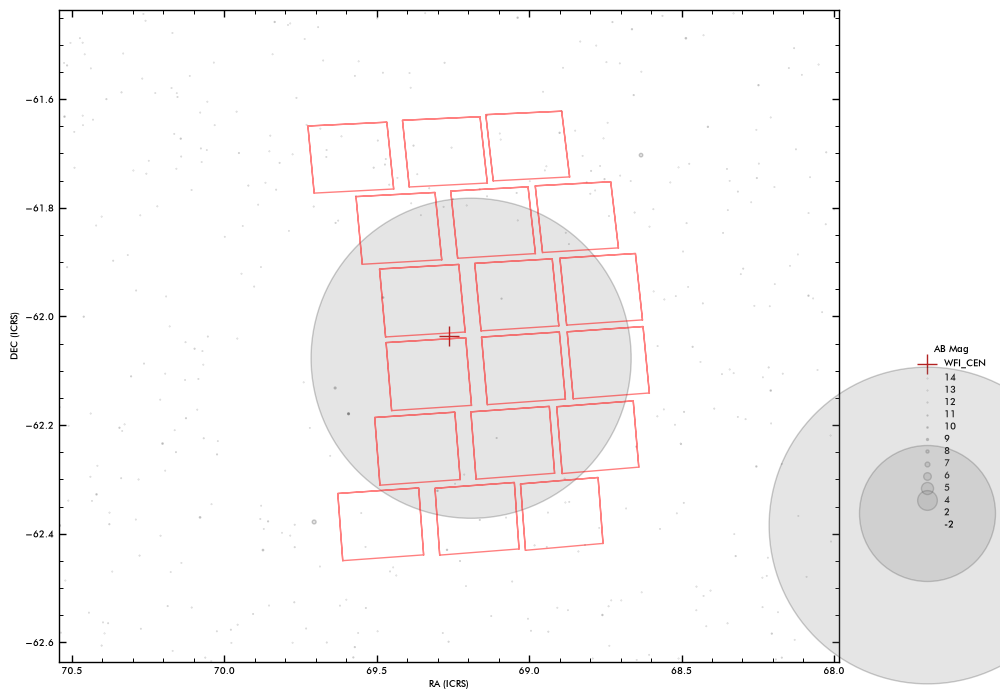

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:15:32.847449 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_064_Roman_RA_069.263_DEC_-62.036_MJD_61352.00000_PA_094.33_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_064_Roman_RA_069.263_DEC_-62.036_MJD_61352.00000_PA_094.33_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:15:49.529814 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:15:49 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 15:15:51 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣾
2026-10-24T15:16:01.664492 > Done.


18it [00:03,  5.03it/s]

2026-10-24T15:16:05.254049 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.54s/it]


2026-10-24T15:16:52.055529 > Done : 0:00:46.801499 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:16:53.079394 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:17:01.093268 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


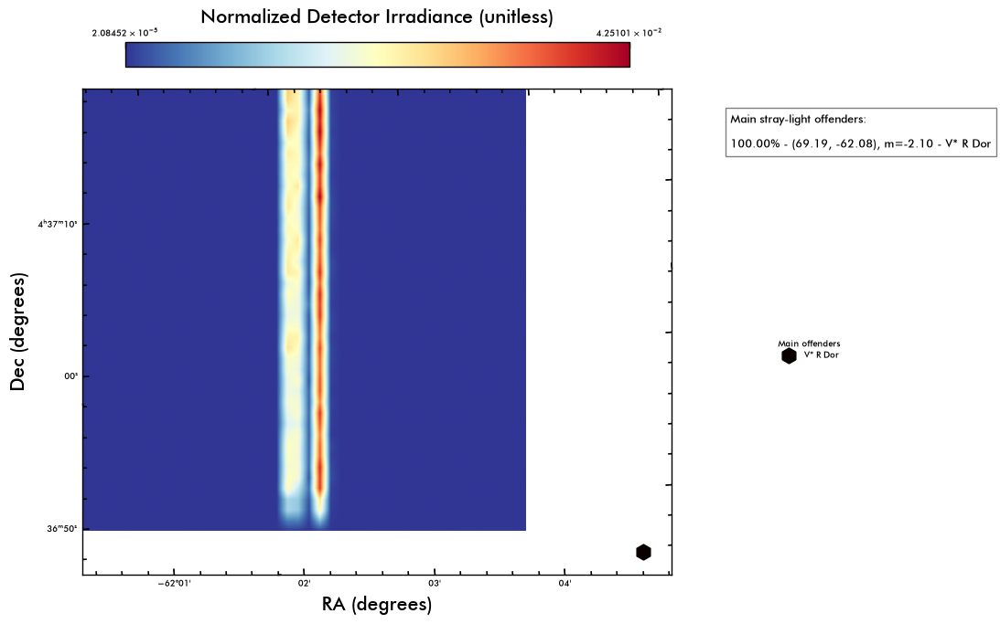

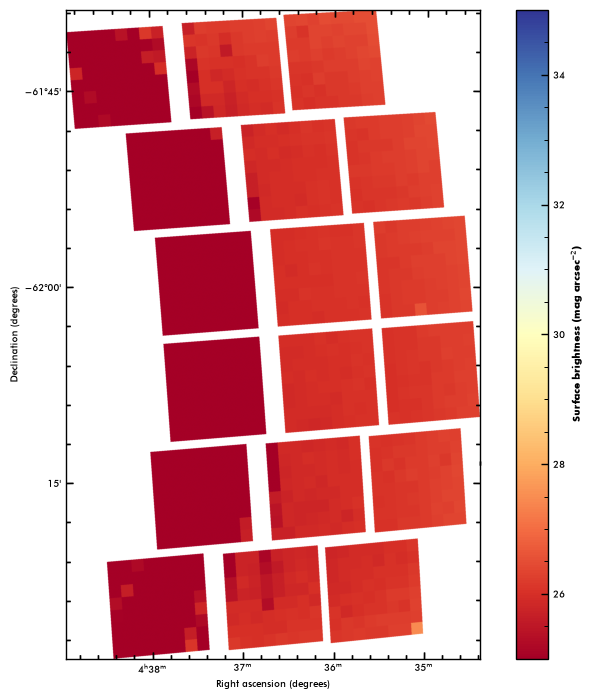

Plot: Stray-light surface brightness flux.
0.013953285
20.56176


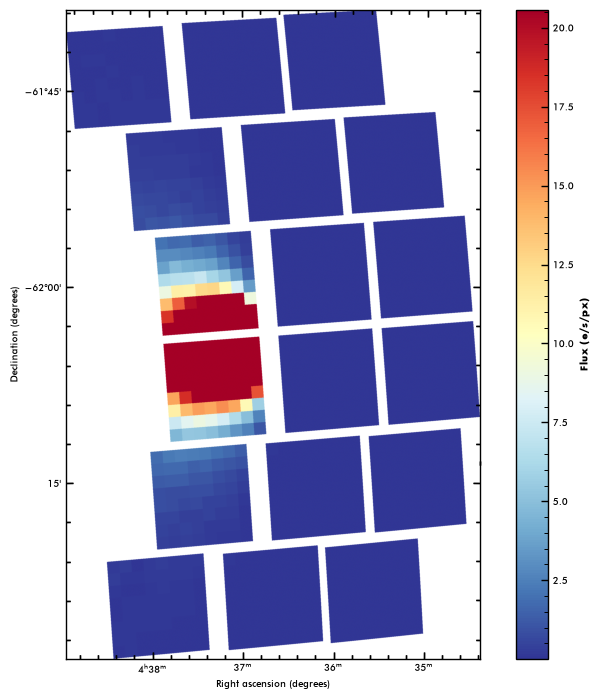

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


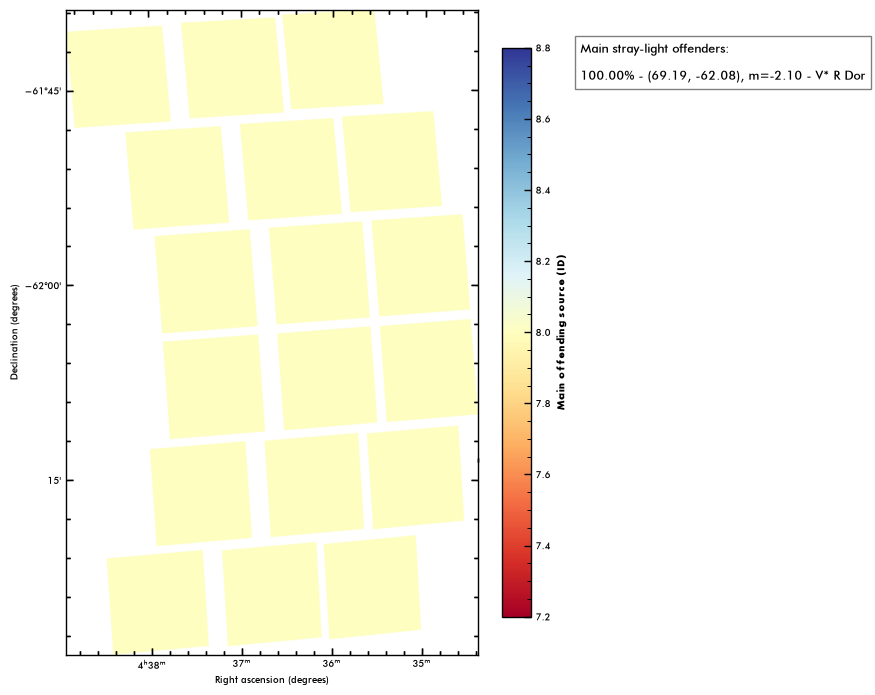

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


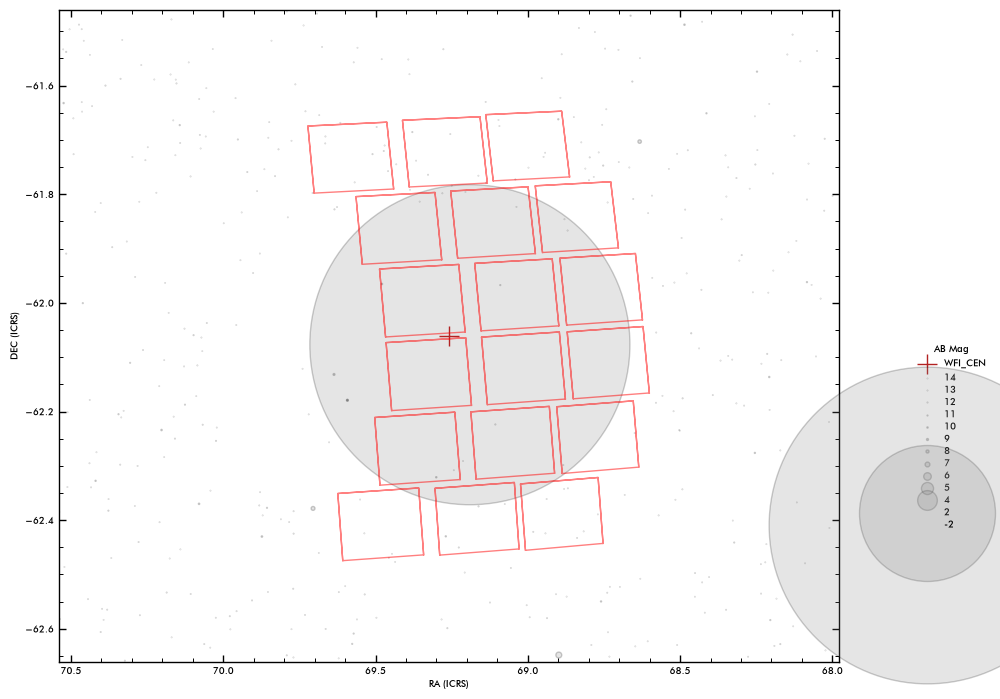

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:17:08.474216 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_065_Roman_RA_069.259_DEC_-62.061_MJD_61352.00000_PA_094.33_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_065_Roman_RA_069.259_DEC_-62.061_MJD_61352.00000_PA_094.33_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:17:24.984906 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:17:24 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽: Parsing tables... [astroquery.utils.tap.core]


2026-10-24 15:17:26 INFO     Parsing tables...


Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⡿
2026-10-24T15:17:37.292625 > Done.


18it [00:03,  4.95it/s]

2026-10-24T15:17:40.939457 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.56s/it]


2026-10-24T15:18:28.017854 > Done : 0:00:47.078412 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:18:29.007372 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:18:36.831316 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


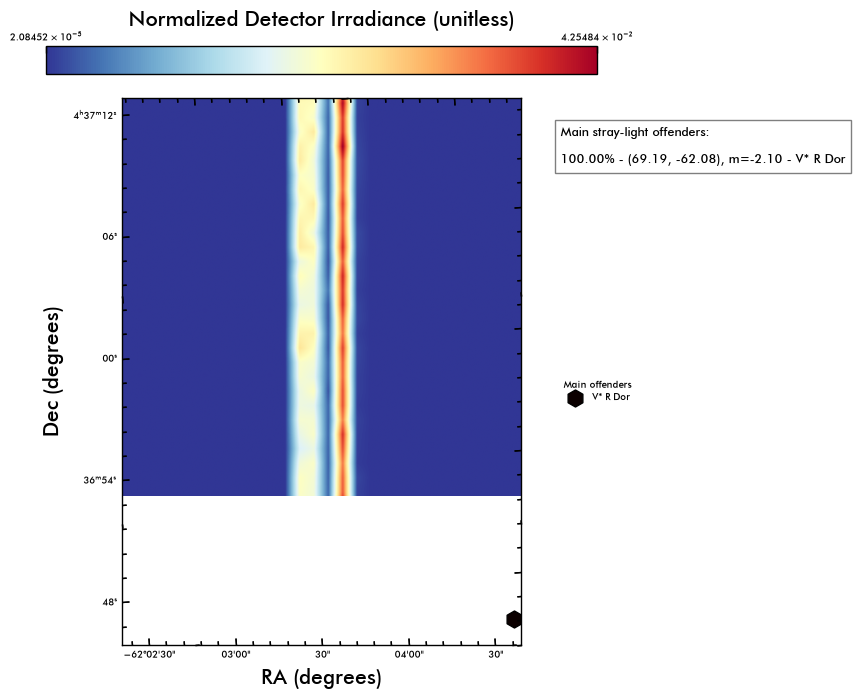

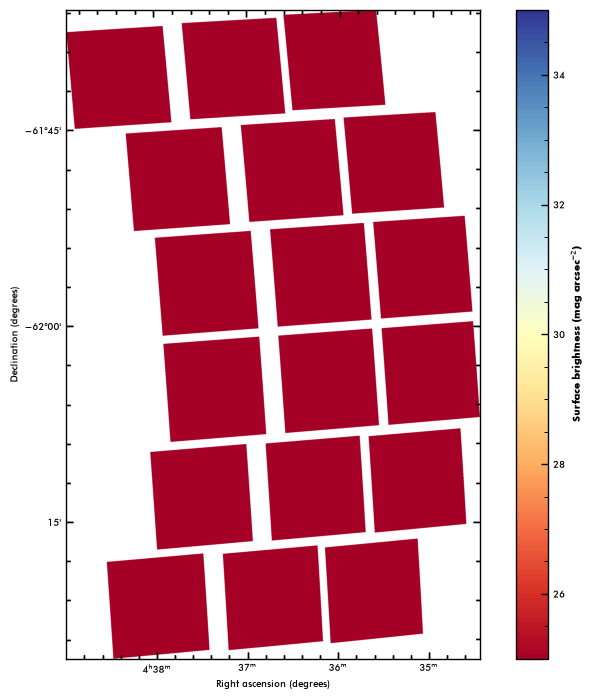

Plot: Stray-light surface brightness flux.
0.81728625
20.990255


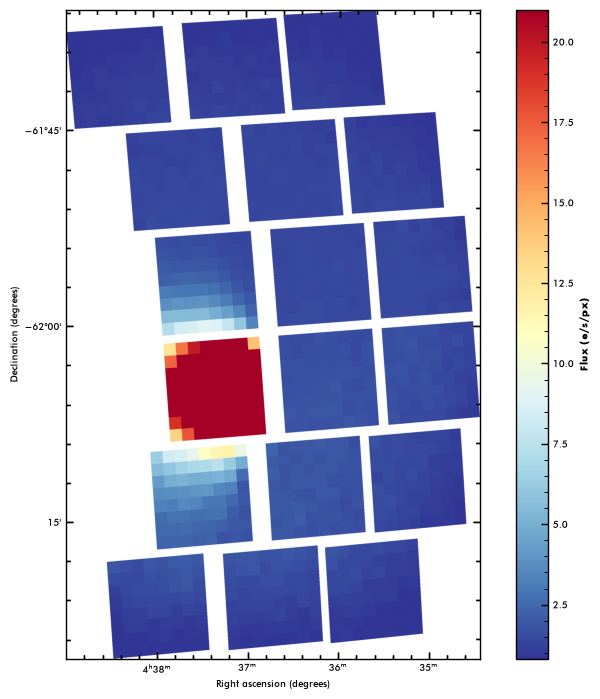

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


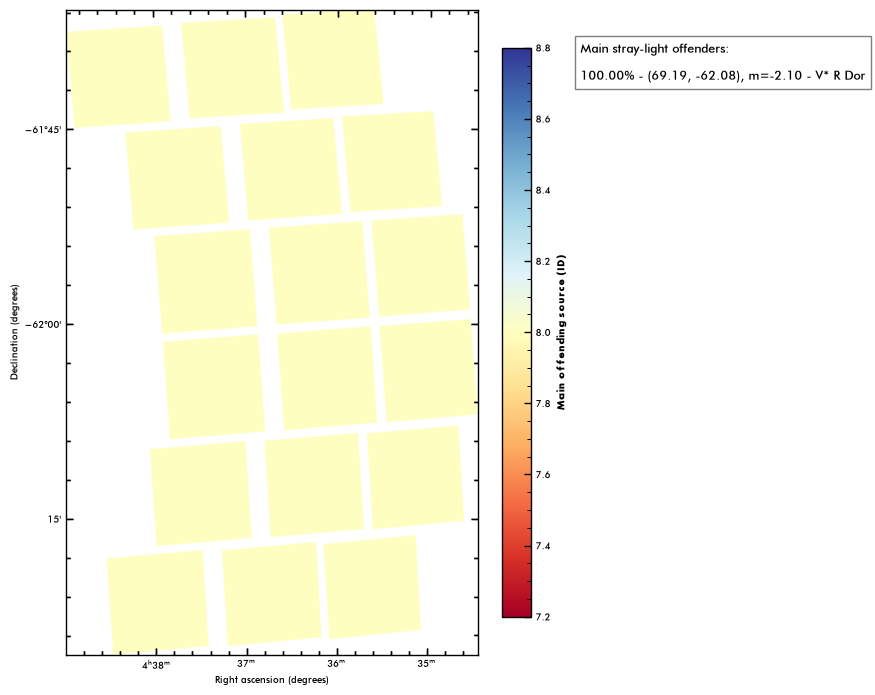

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


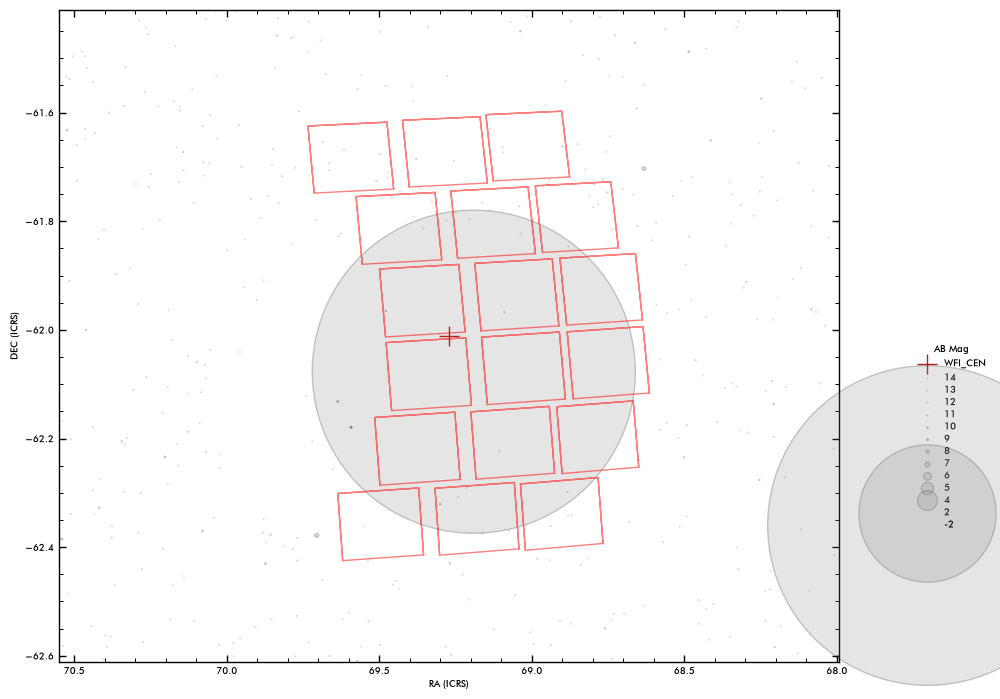

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:18:44.413986 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_066_Roman_RA_069.272_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_066_Roman_RA_069.272_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:19:00.909925 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:19:00 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

2026-10-24 15:19:02 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⡿
2026-10-24T15:19:13.031250 > Done.


18it [00:03,  5.04it/s]

2026-10-24T15:19:16.608999 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.54s/it]


2026-10-24T15:20:03.300591 > Done : 0:00:46.691610 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:20:04.366698 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:20:12.263171 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


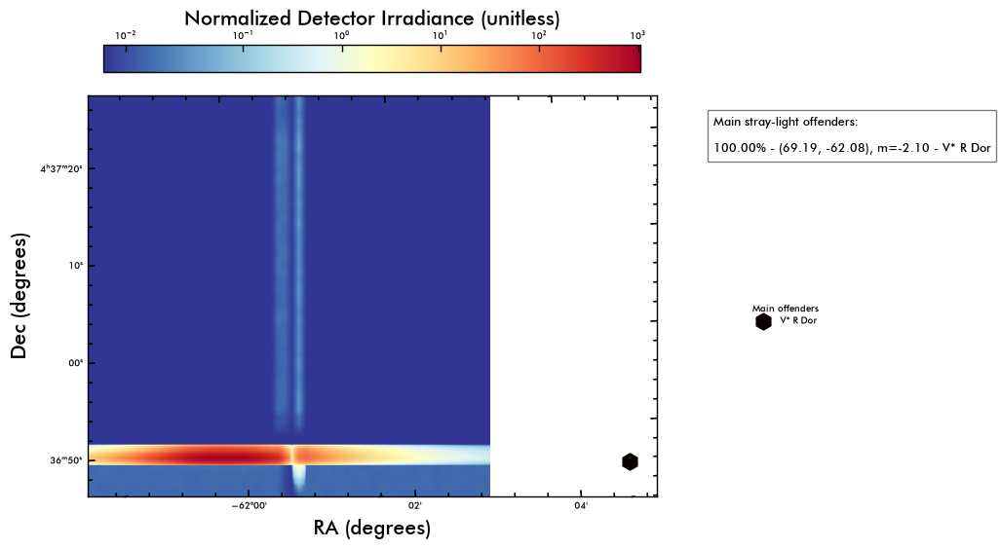

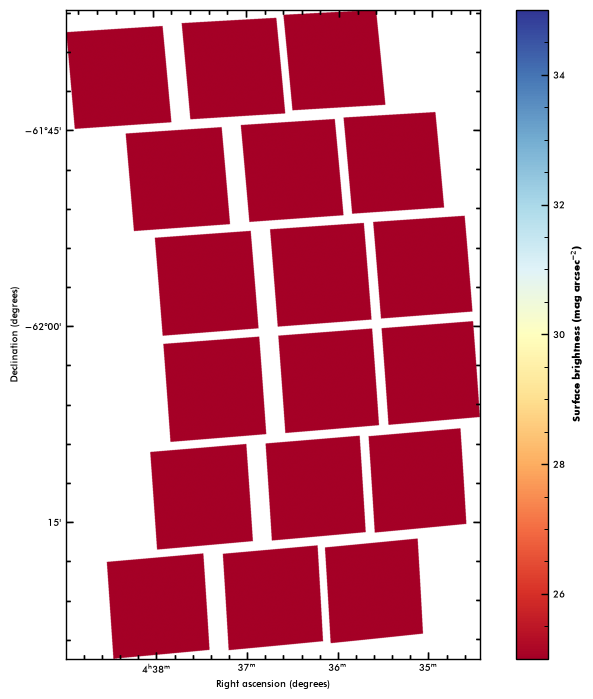

Plot: Stray-light surface brightness flux.
0.7171415
35.821915


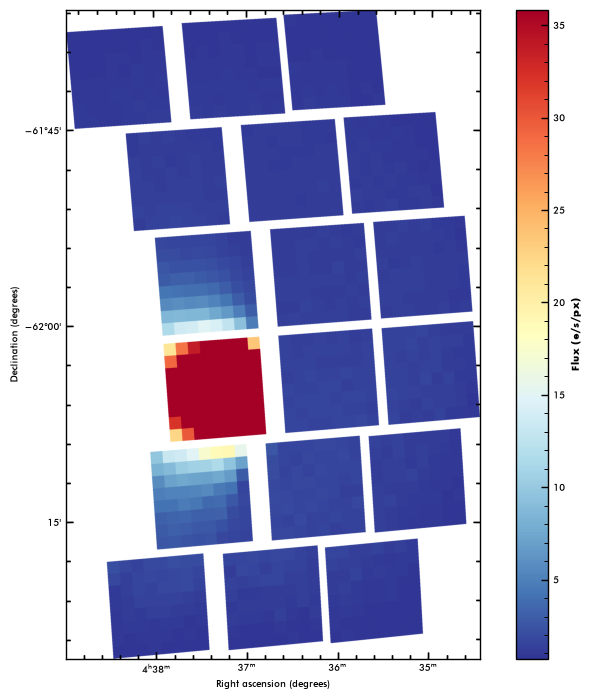

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


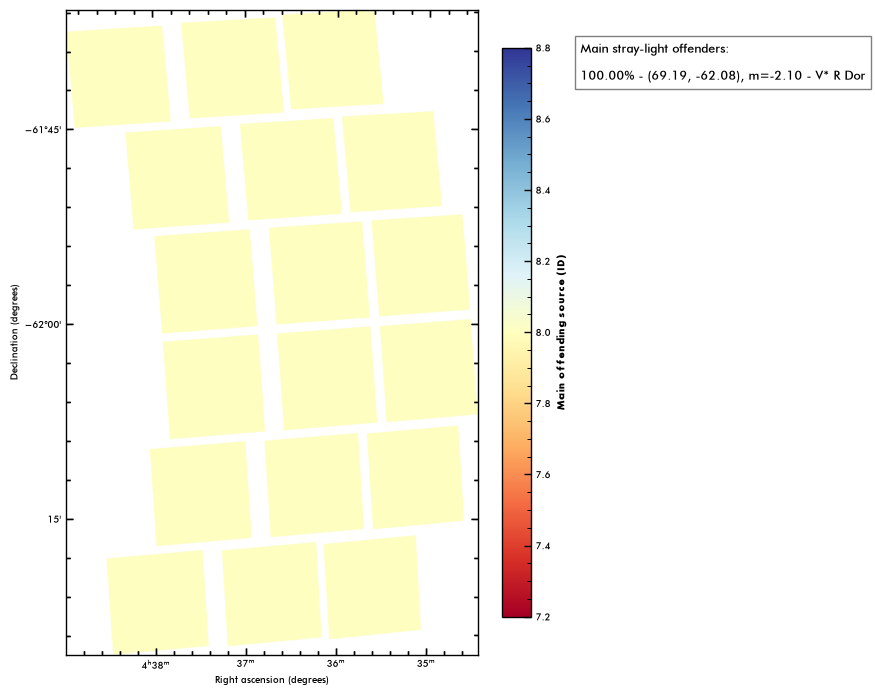

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


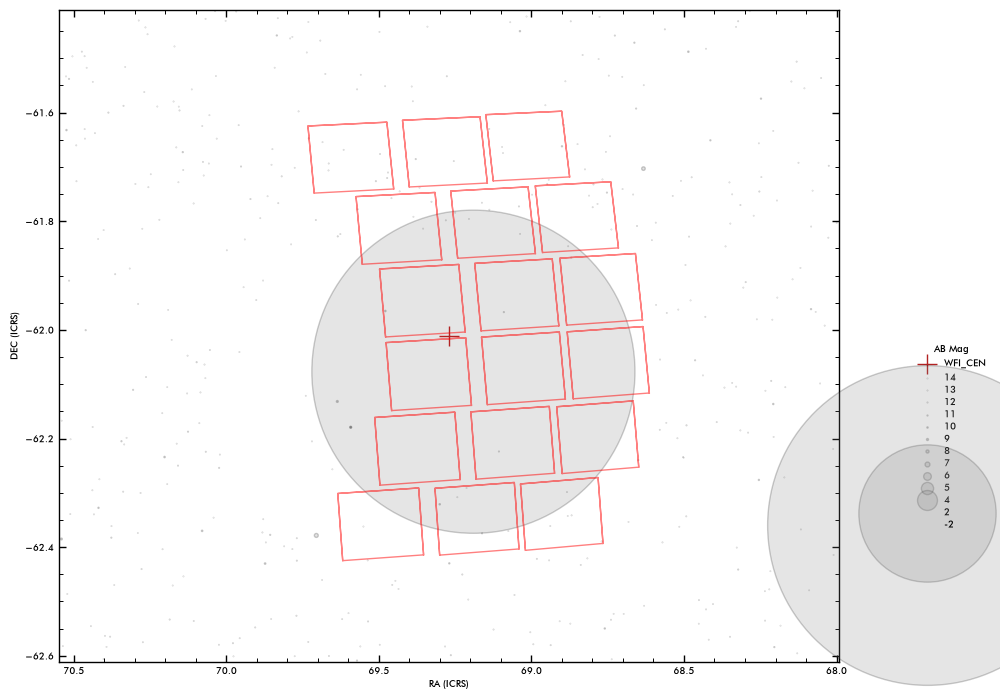

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:20:19.755640 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_067_Roman_RA_069.271_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_067_Roman_RA_069.271_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:20:36.456766 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:20:36 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 15:20:37 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T15:20:48.324616 > Done.


18it [00:03,  4.94it/s]

2026-10-24T15:20:51.975925 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.56s/it]


2026-10-24T15:21:39.031419 > Done : 0:00:47.055514 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:21:40.016511 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:21:47.889237 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


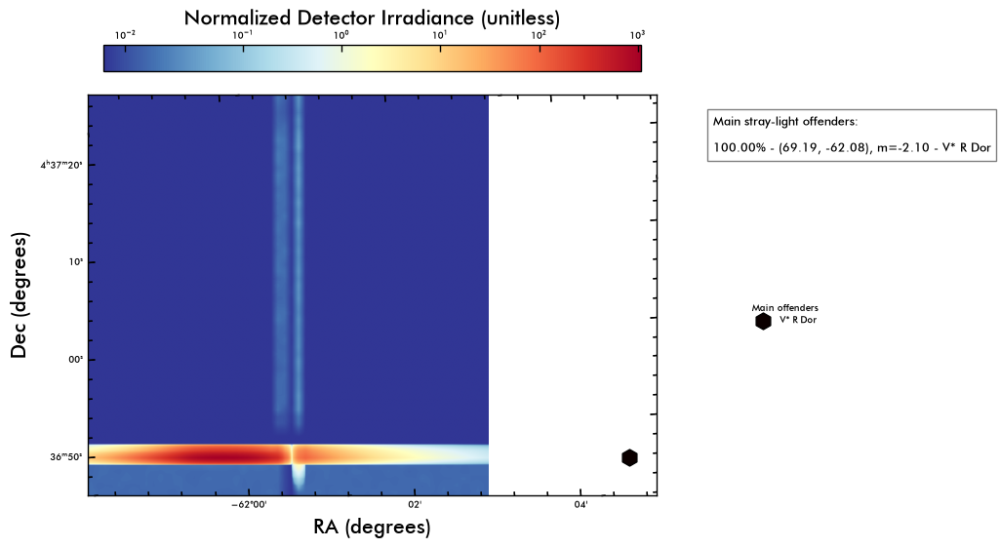

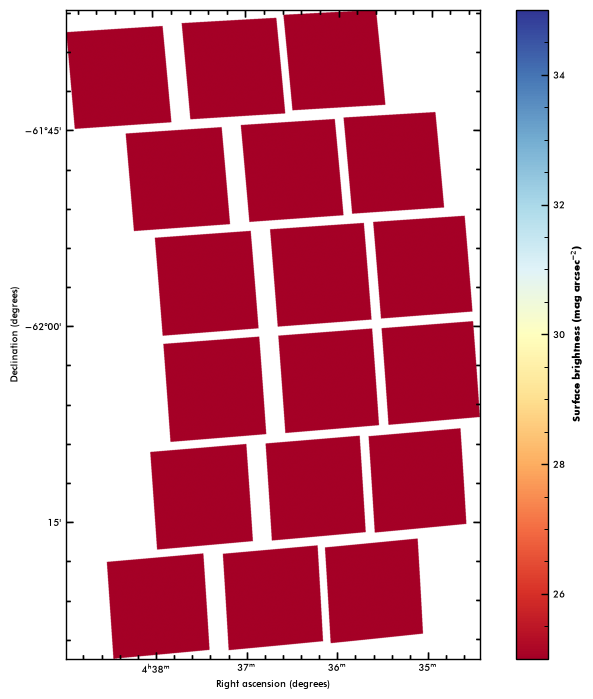

Plot: Stray-light surface brightness flux.
0.4218947
37.832867


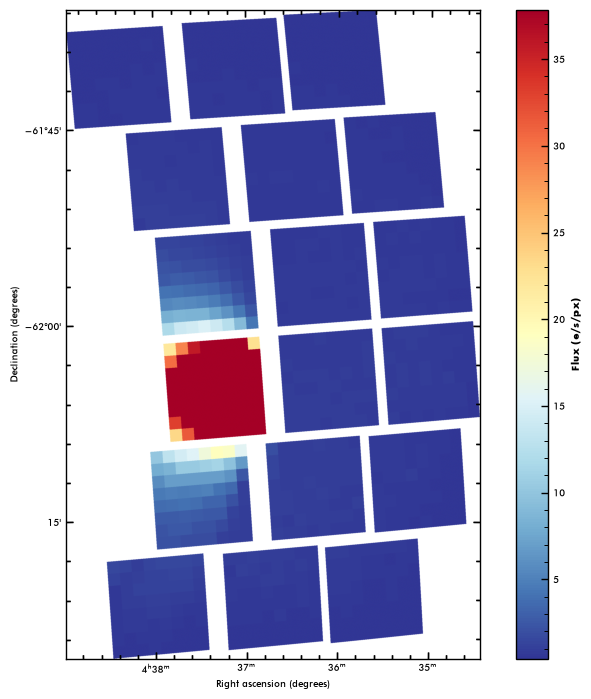

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


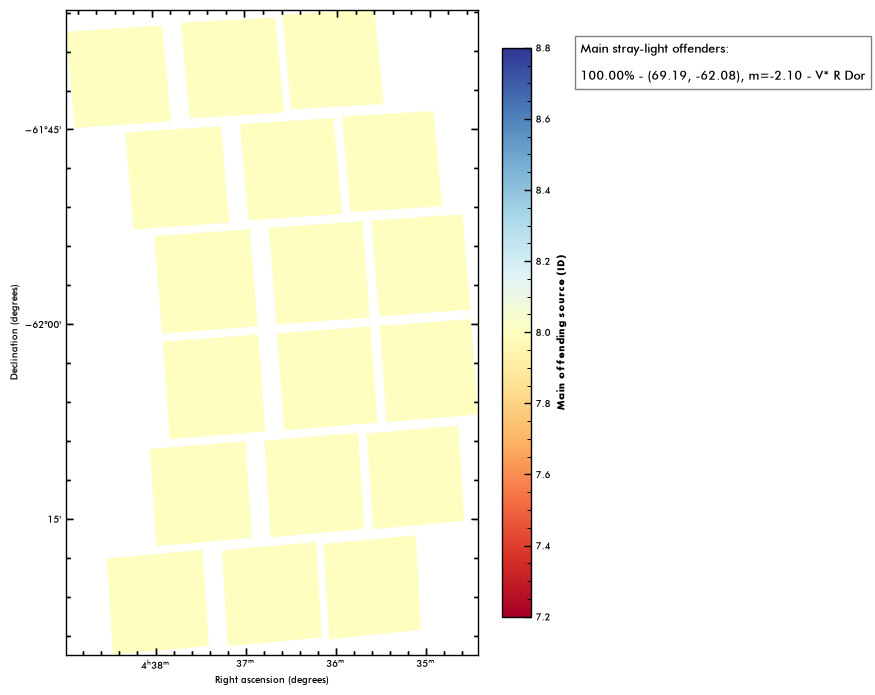

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


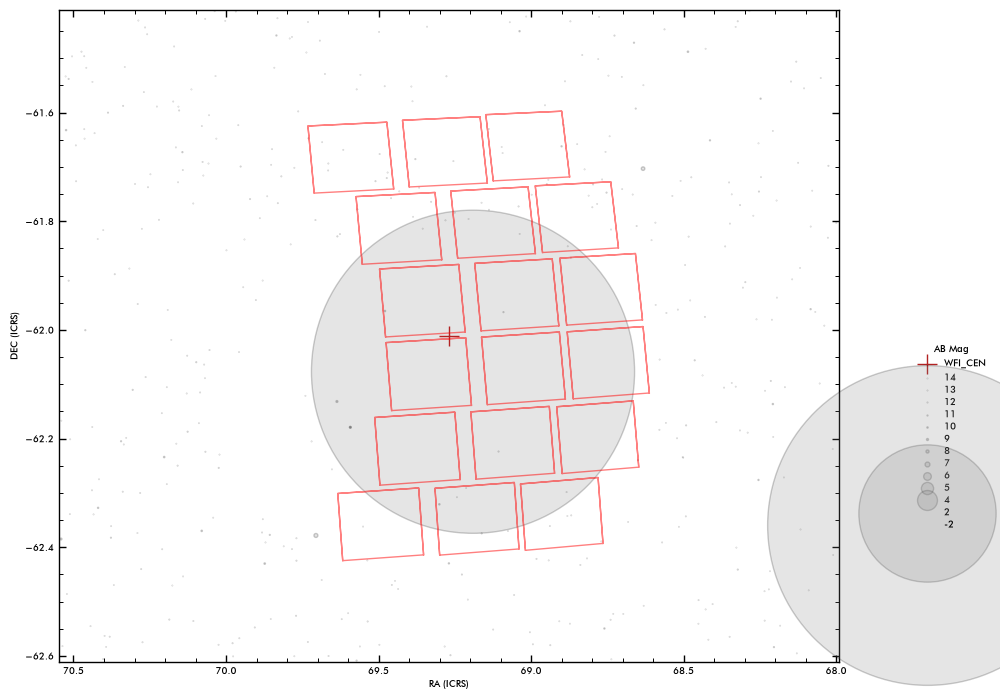

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:21:55.511735 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_068_Roman_RA_069.270_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_068_Roman_RA_069.270_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:22:12.182525 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:22:12 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 15:22:13 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T15:22:24.045039 > Done.


18it [00:03,  4.84it/s]

2026-10-24T15:22:27.773187 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.56s/it]


2026-10-24T15:23:14.888684 > Done : 0:00:47.115518 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:23:15.965955 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:23:23.905722 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


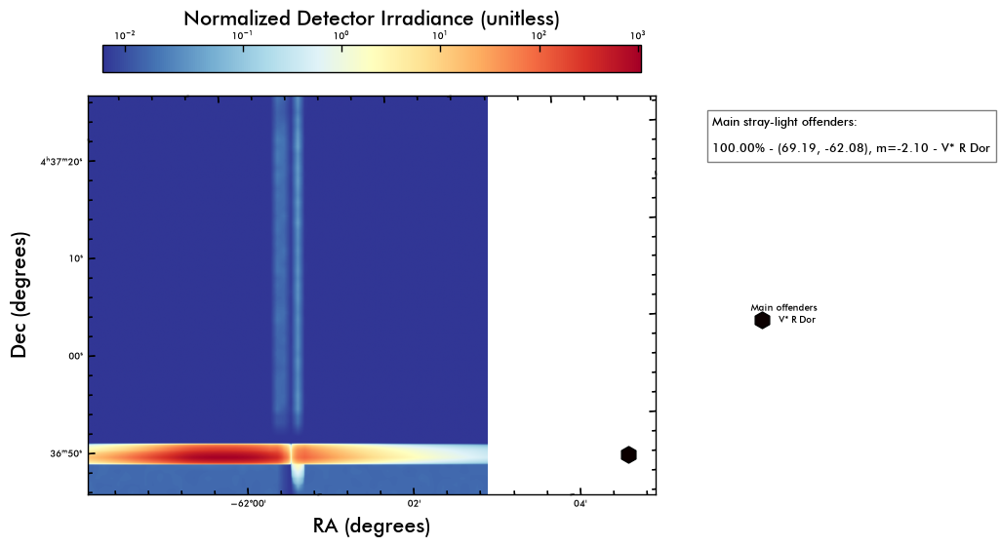

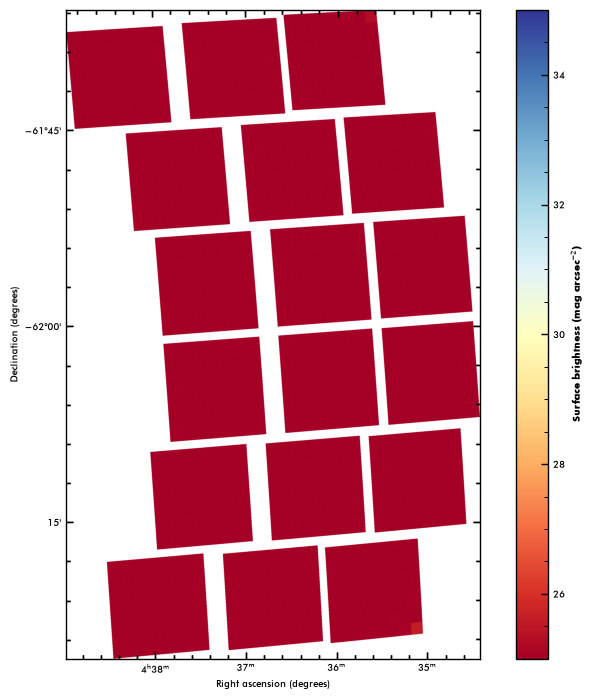

Plot: Stray-light surface brightness flux.
0.06527774
37.832626


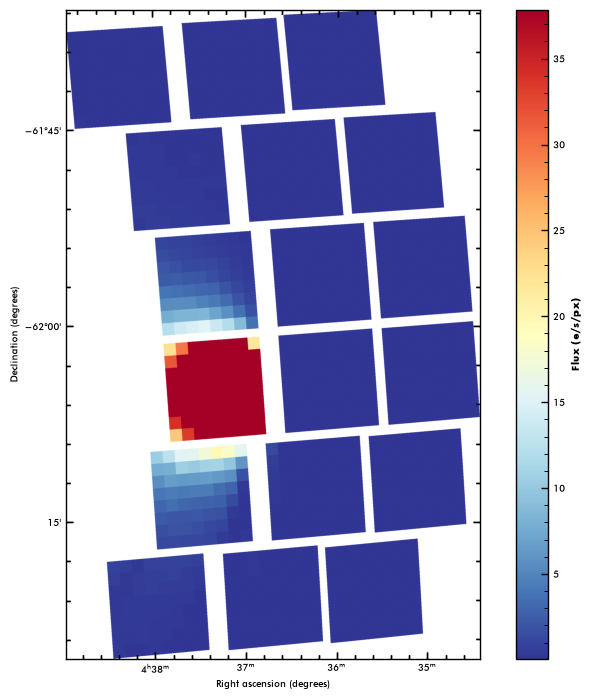

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


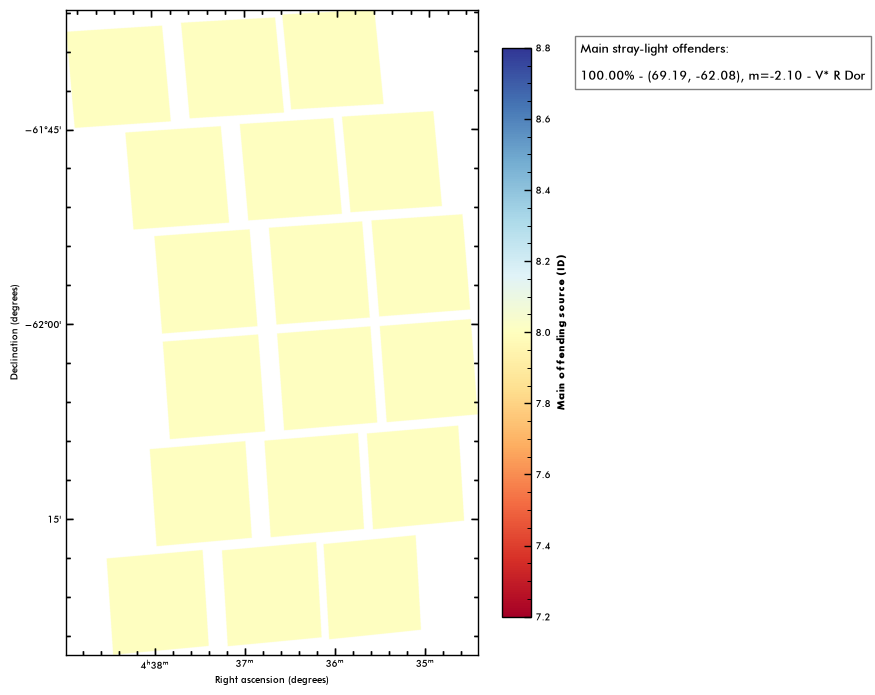

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


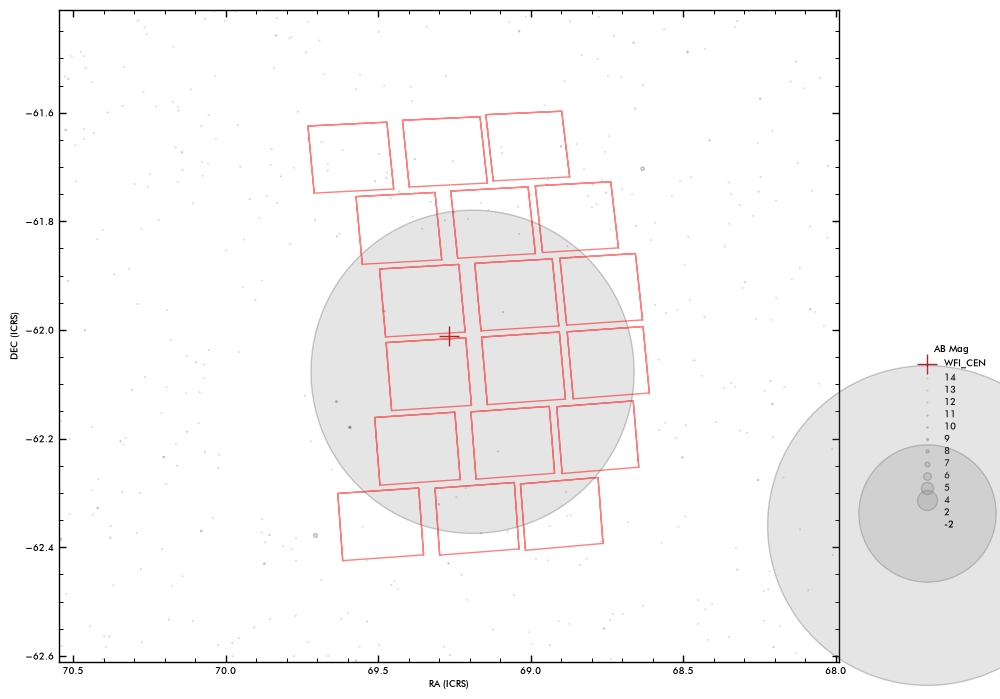

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:23:31.890243 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_069_Roman_RA_069.268_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_069_Roman_RA_069.268_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:23:49.382799 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:23:49 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 15:23:50 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T15:24:01.250061 > Done.


18it [00:03,  4.94it/s]

2026-10-24T15:24:04.906645 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.56s/it]


2026-10-24T15:24:51.992454 > Done : 0:00:47.085828 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:24:53.036738 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:25:00.933447 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


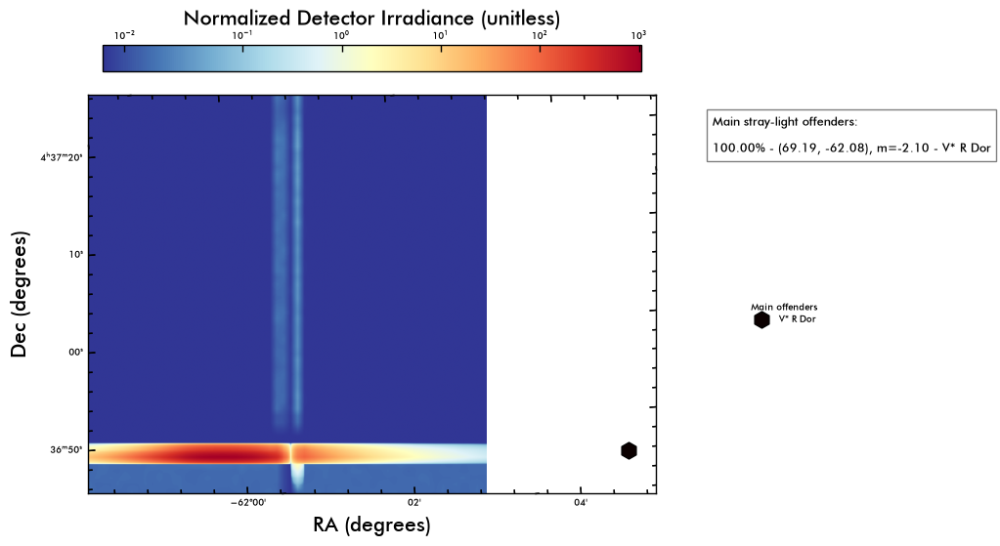

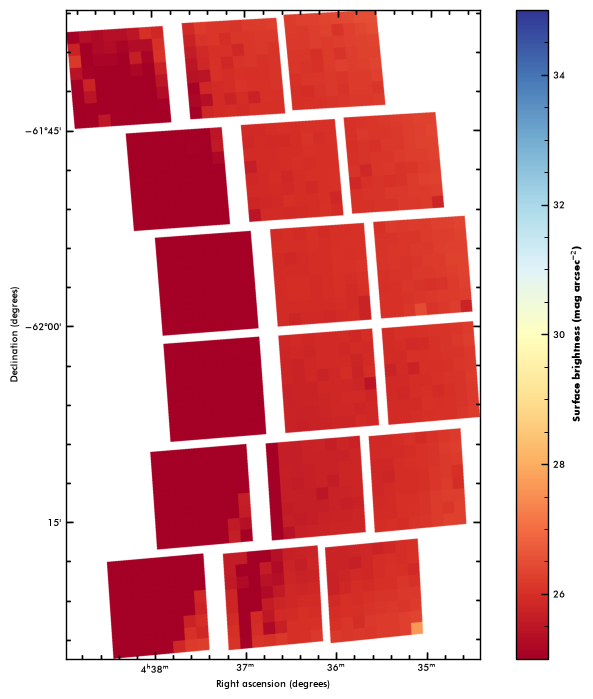

Plot: Stray-light surface brightness flux.
0.015188881
24.35571


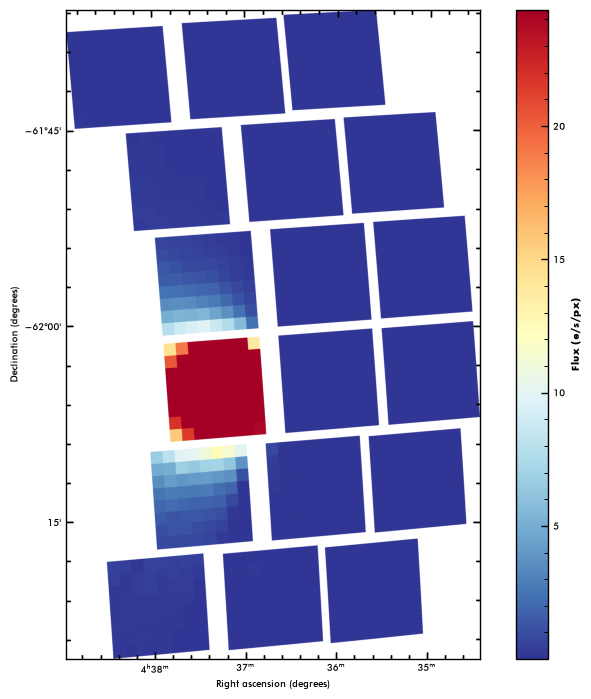

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


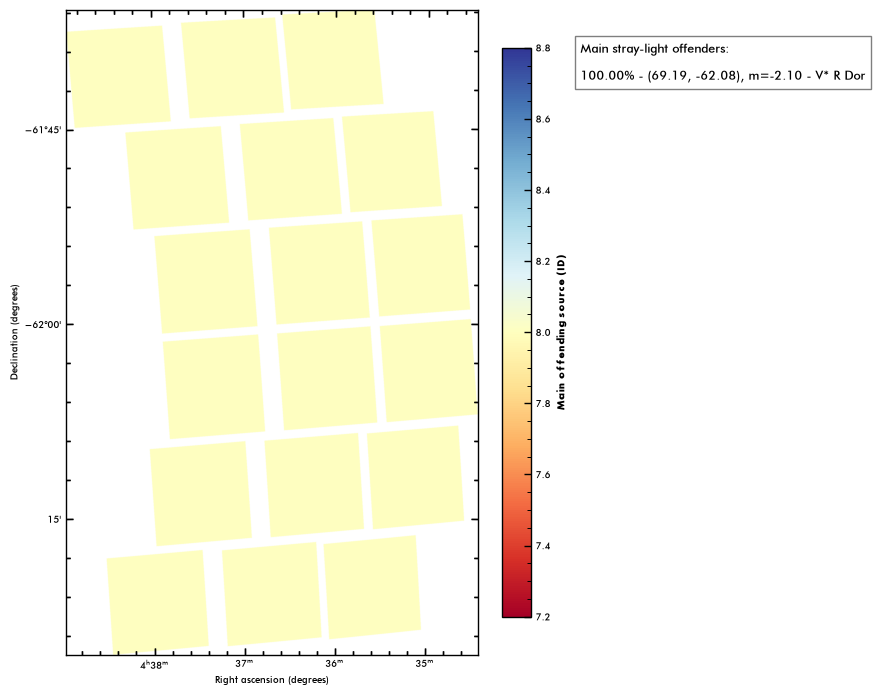

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


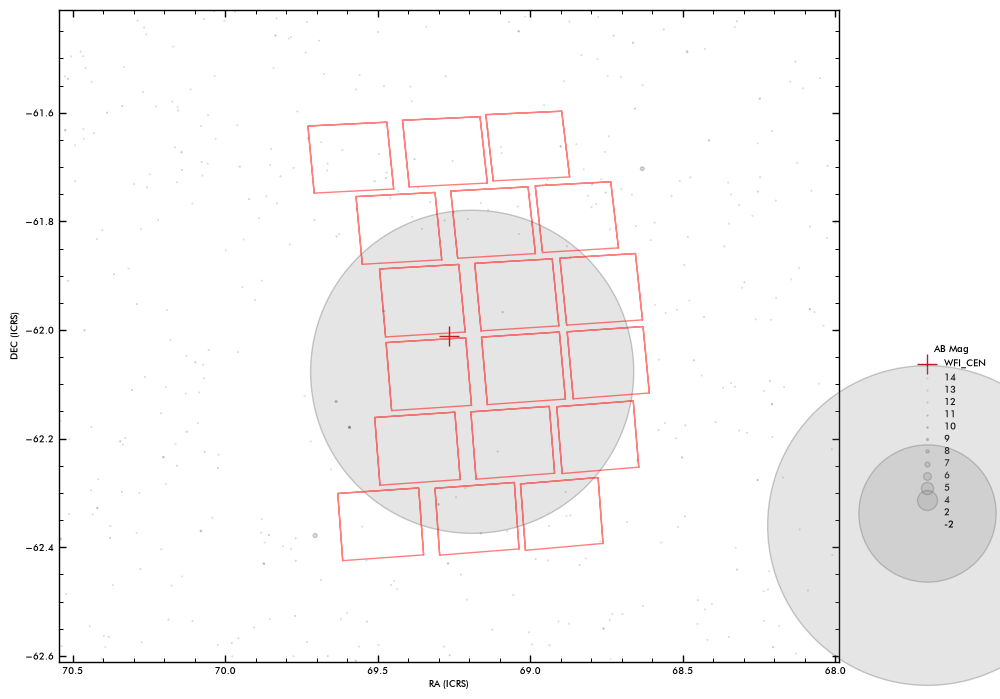

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:25:08.583993 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_070_Roman_RA_069.267_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_070_Roman_RA_069.267_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:25:25.022586 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:25:25 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 15:25:26 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T15:25:36.801817 > Done.


18it [00:03,  4.82it/s]

2026-10-24T15:25:40.545572 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.58s/it]


2026-10-24T15:26:28.055652 > Done : 0:00:47.510098 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:26:29.099521 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:26:36.943105 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


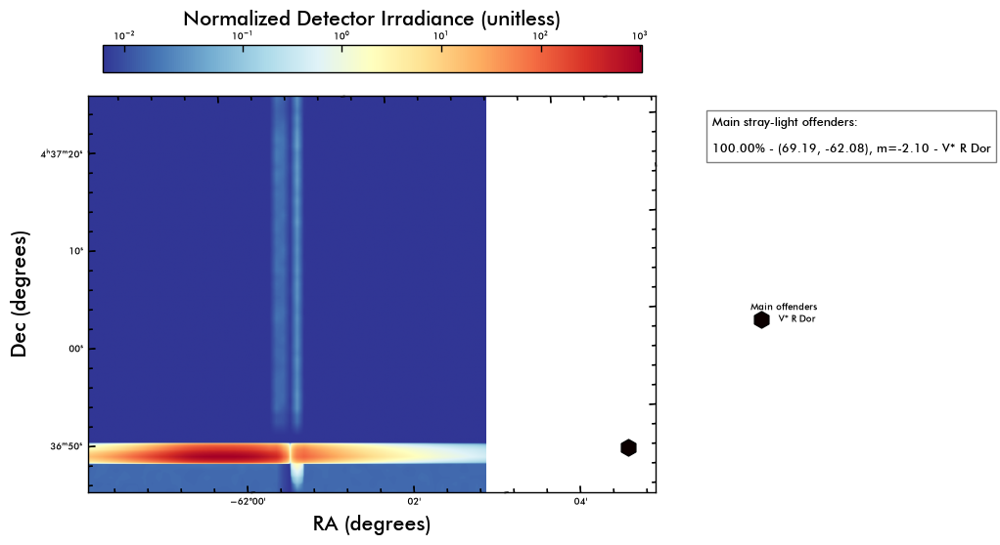

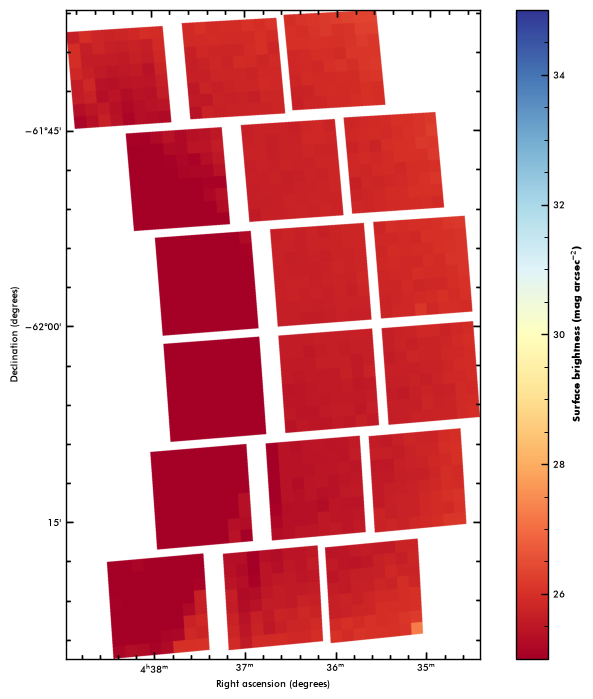

Plot: Stray-light surface brightness flux.
0.018417379
5.1534405


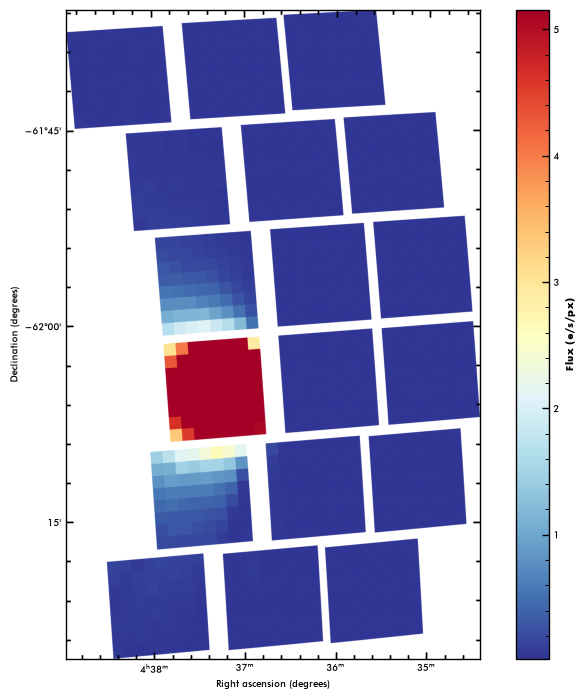

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


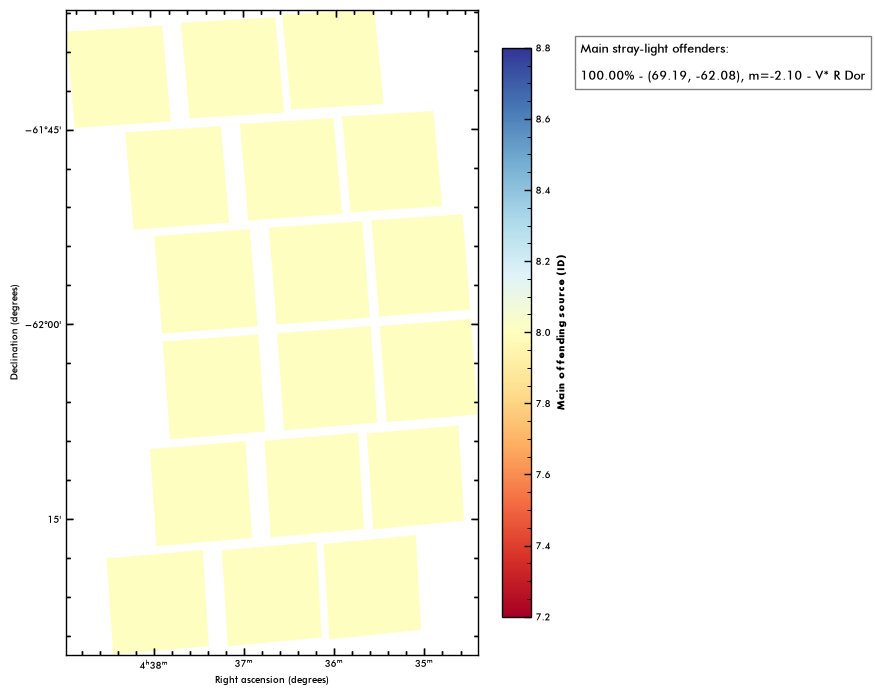

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


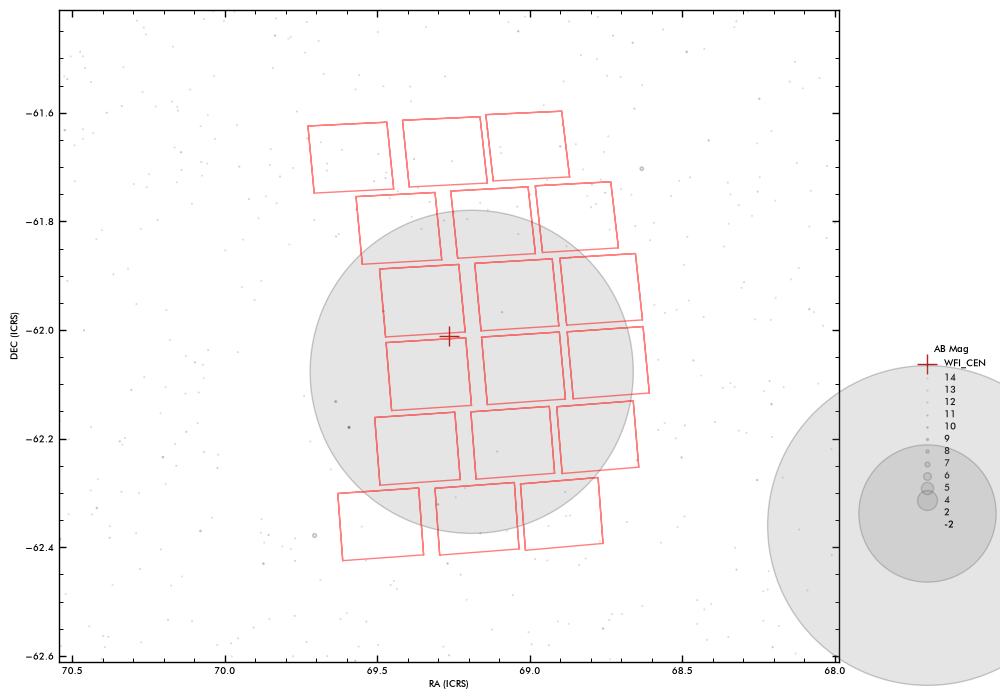

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:26:44.413870 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_071_Roman_RA_069.265_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_071_Roman_RA_069.265_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:27:01.079932 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:27:01 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 15:27:02 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T15:27:12.861561 > Done.


18it [00:03,  4.94it/s]

2026-10-24T15:27:16.514728 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.59s/it]


2026-10-24T15:28:04.152927 > Done : 0:00:47.638221 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:28:05.145923 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:28:12.999314 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


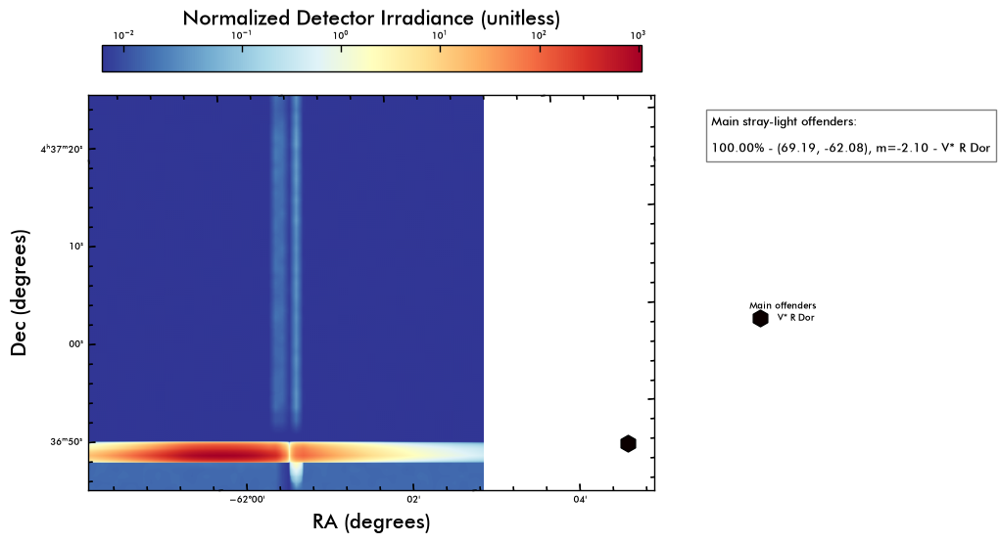

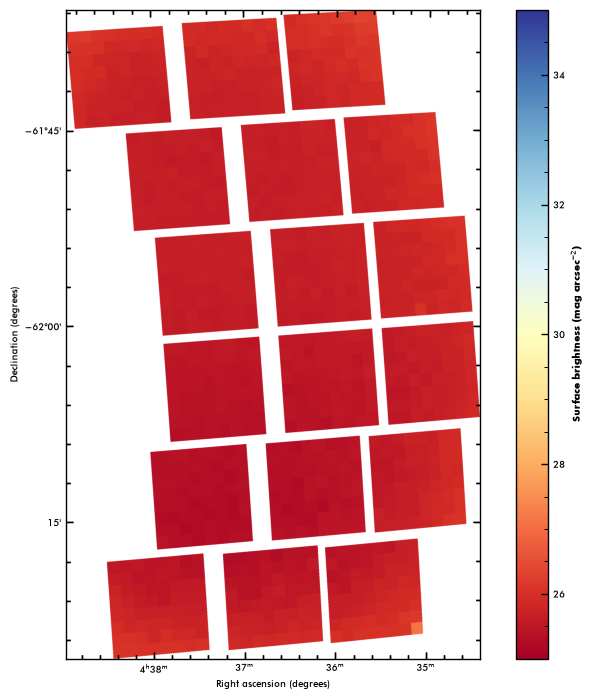

Plot: Stray-light surface brightness flux.
0.018774804
0.0347883


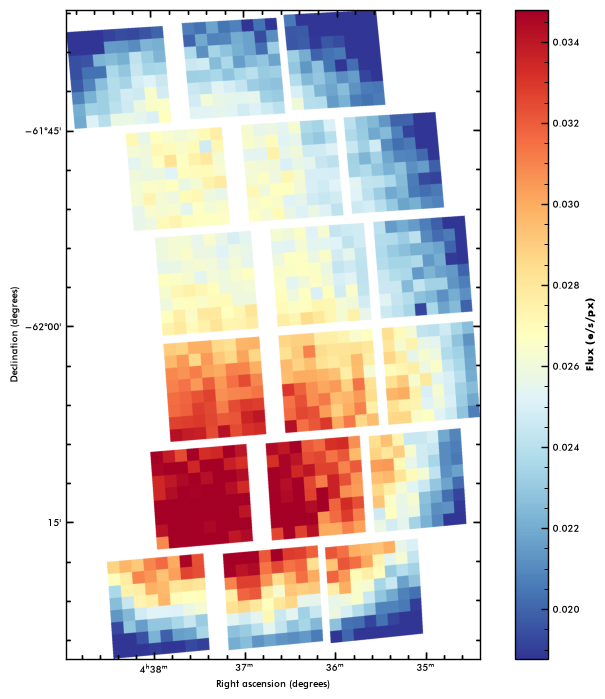

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


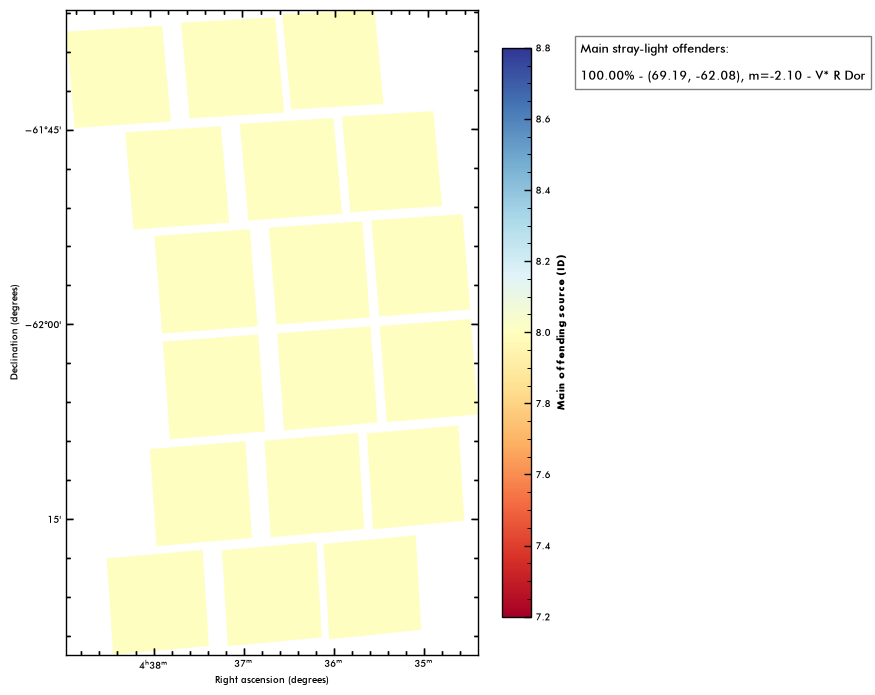

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


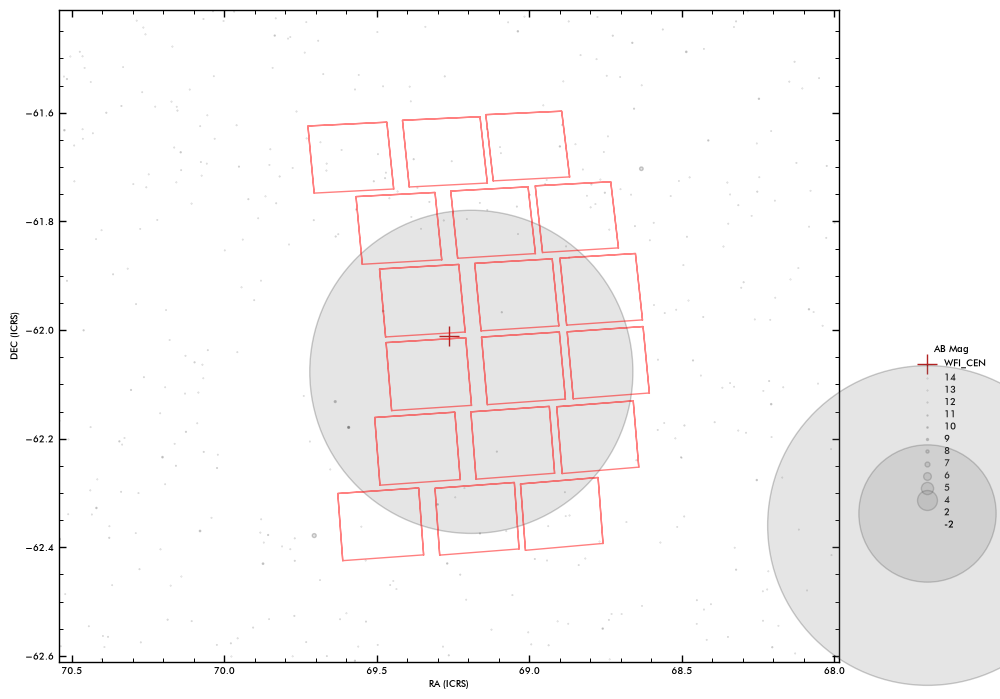

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:28:20.003433 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_072_Roman_RA_069.264_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_072_Roman_RA_069.264_DEC_-62.011_MJD_61352.00000_PA_094.32_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:28:36.548875 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:28:36 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽

2026-10-24 15:28:38 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T15:28:48.365446 > Done.


18it [00:03,  4.83it/s]

2026-10-24T15:28:52.102329 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.54s/it]


2026-10-24T15:29:38.908463 > Done : 0:00:46.806149 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:29:39.980119 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:29:47.910846 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


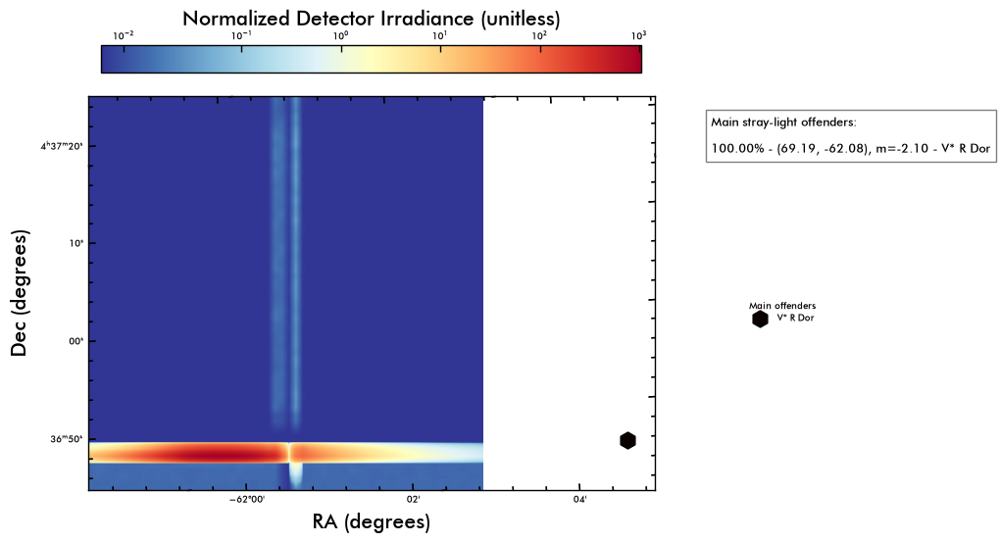

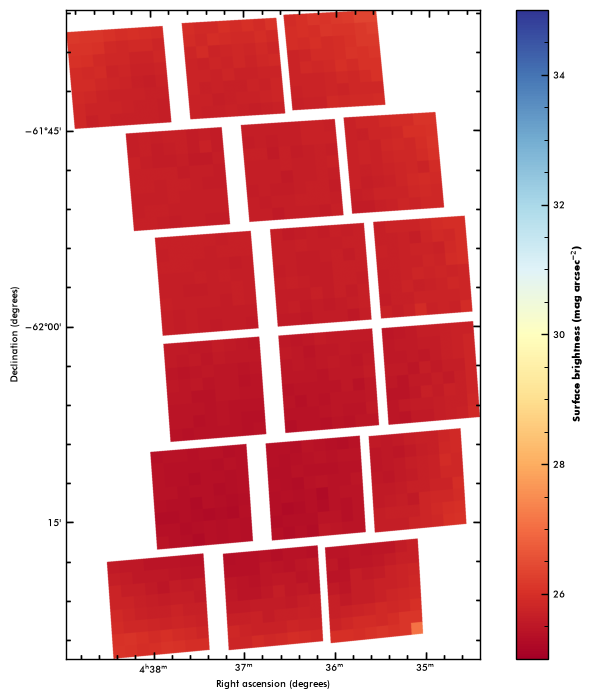

Plot: Stray-light surface brightness flux.
0.019019289
0.03399399


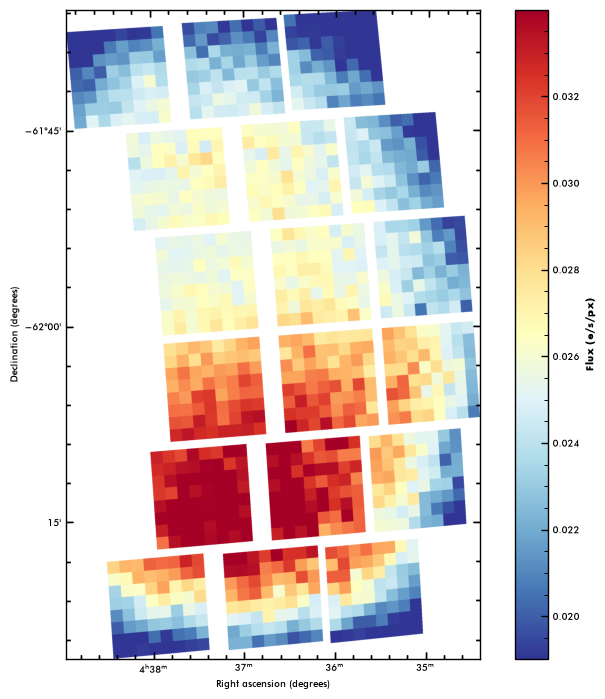

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


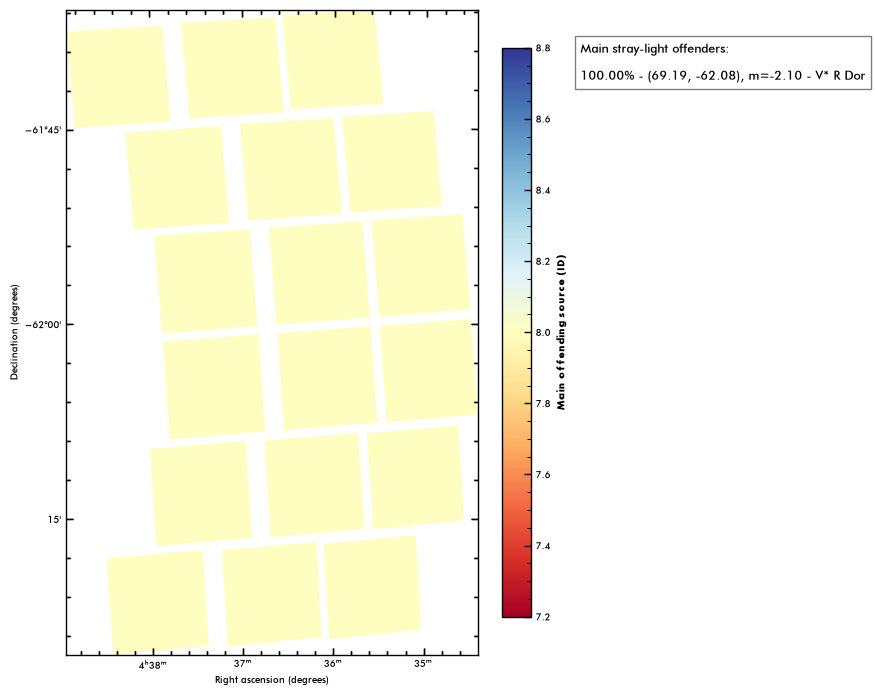

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


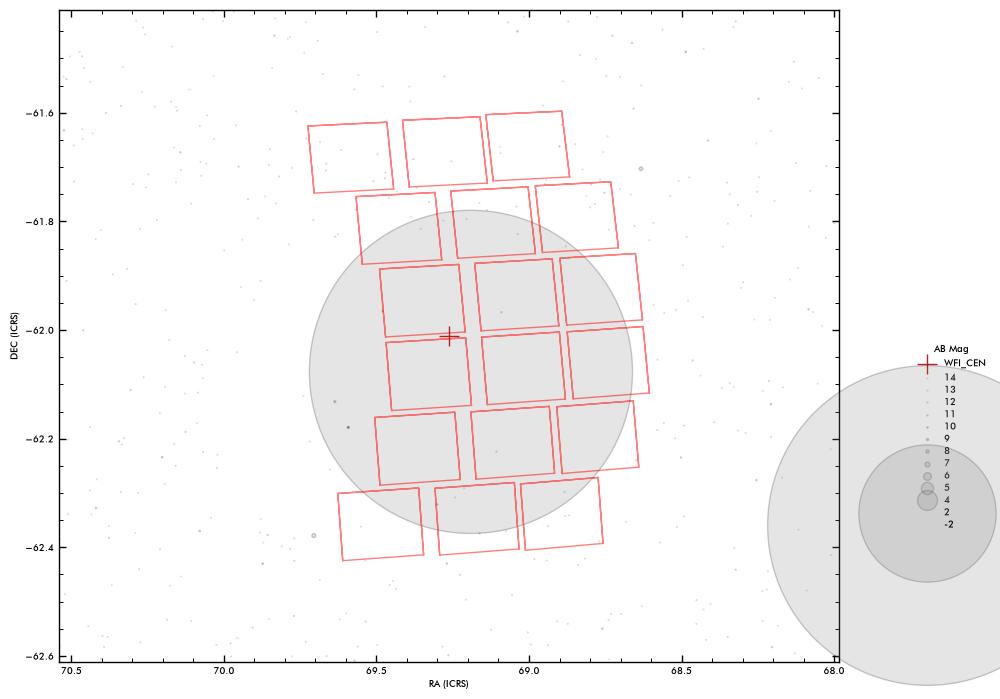

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:29:55.085560 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_073_Roman_RA_069.263_DEC_-62.011_MJD_61352.00000_PA_094.33_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON1_073_Roman_RA_069.263_DEC_-62.011_MJD_61352.00000_PA_094.33_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:30:11.719625 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:30:11 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 15:30:13 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T15:30:23.605650 > Done.


18it [00:03,  4.98it/s]

2026-10-24T15:30:27.228726 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.60s/it]


2026-10-24T15:31:15.046741 > Done : 0:00:47.818035 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:31:16.039799 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:31:23.890550 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


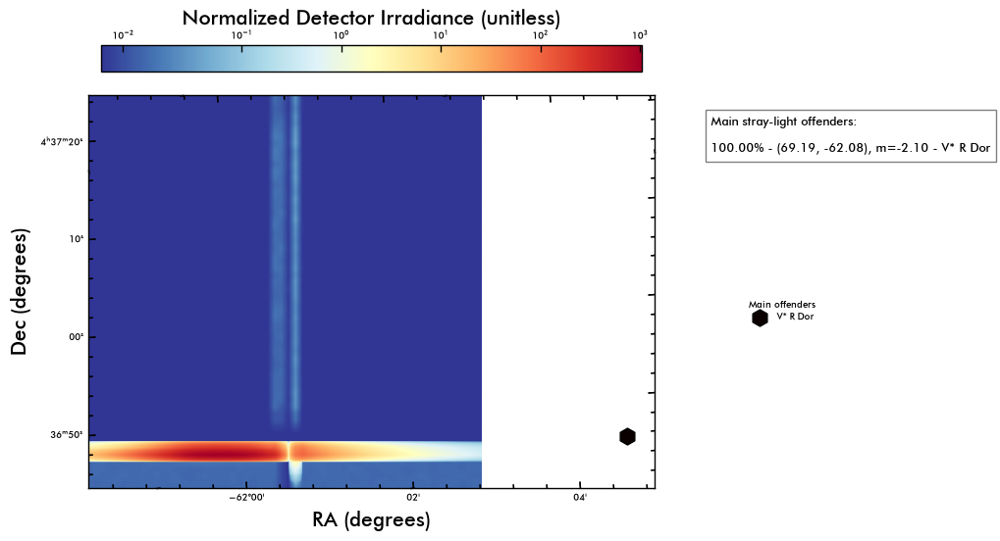

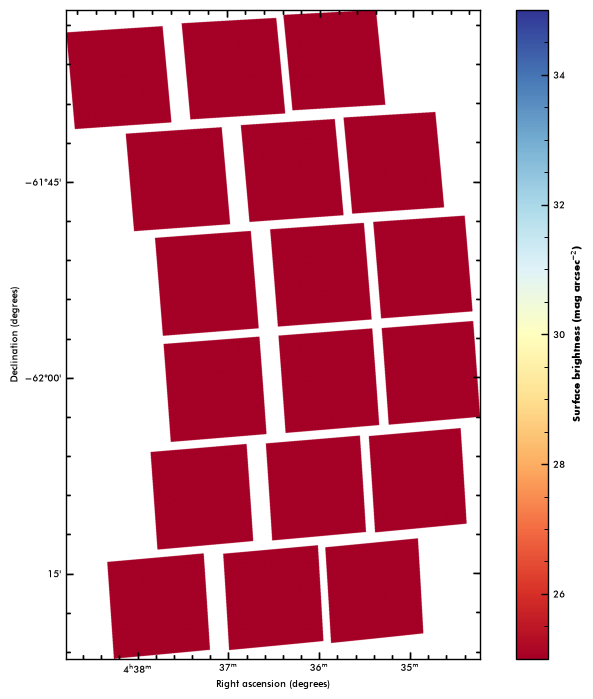

Plot: Stray-light surface brightness flux.
0.09426987
0.370999


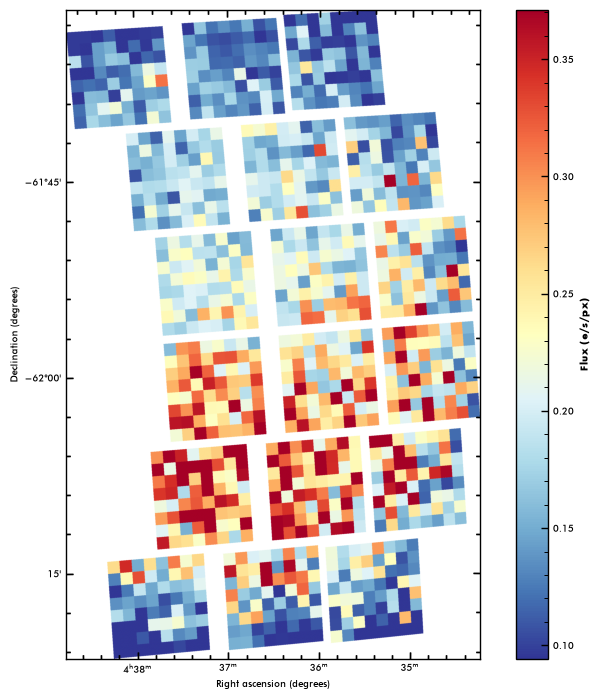

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


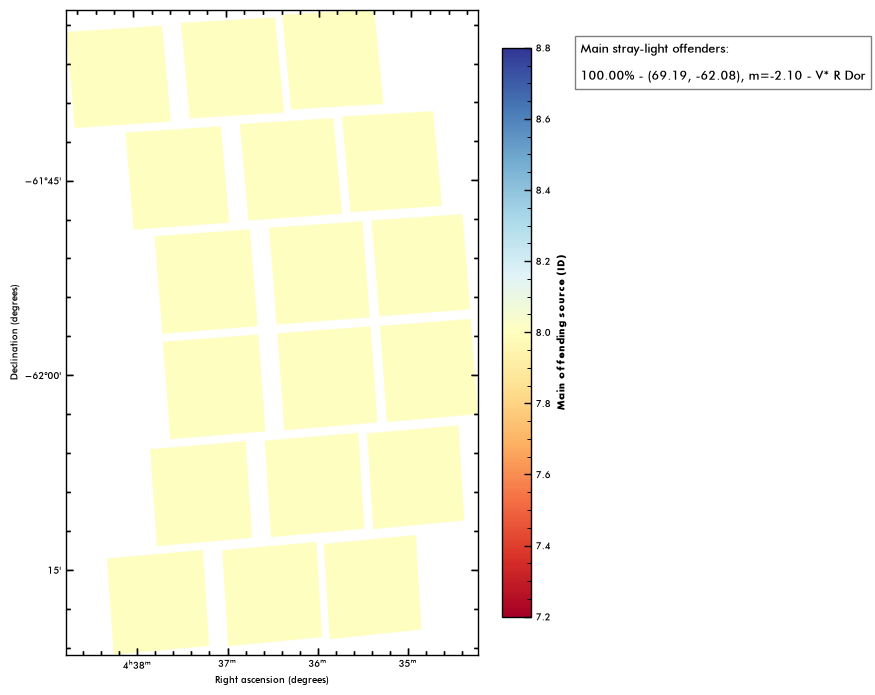

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


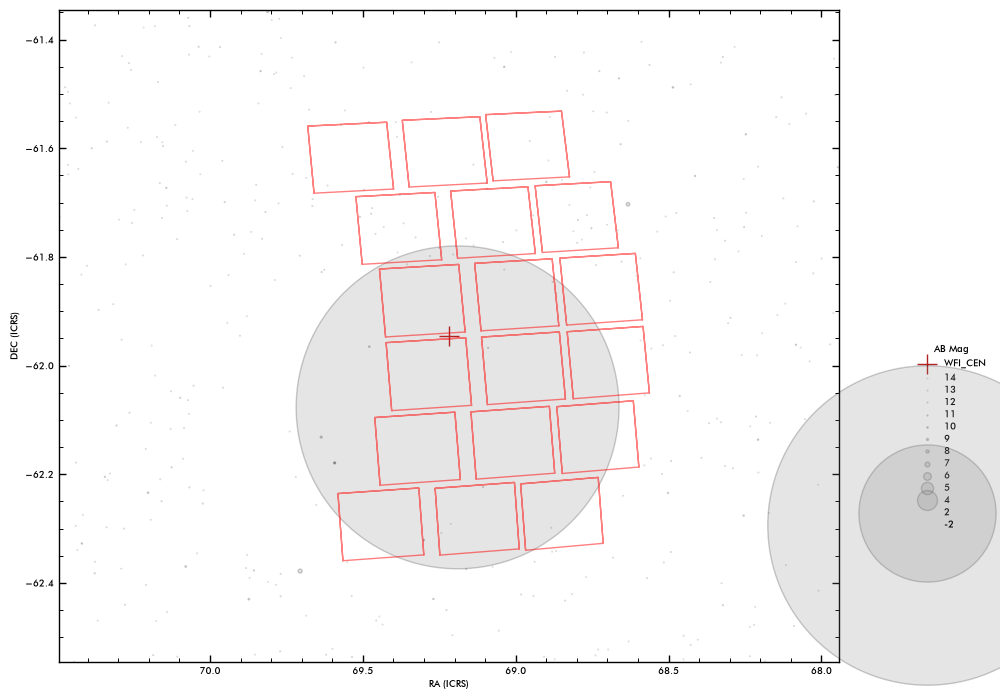

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:31:31.354906 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_074_Roman_RA_069.219_DEC_-61.945_MJD_61352.00000_PA_094.36_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_074_Roman_RA_069.219_DEC_-61.945_MJD_61352.00000_PA_094.36_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:31:47.983590 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:31:47 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷

2026-10-24 15:31:49 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣷
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣾
2026-10-24T15:32:01.085126 > Done.


18it [00:03,  4.82it/s]

2026-10-24T15:32:04.828758 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.56s/it]


2026-10-24T15:32:52.012248 > Done : 0:00:47.183512 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:32:53.013510 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:33:00.761964 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


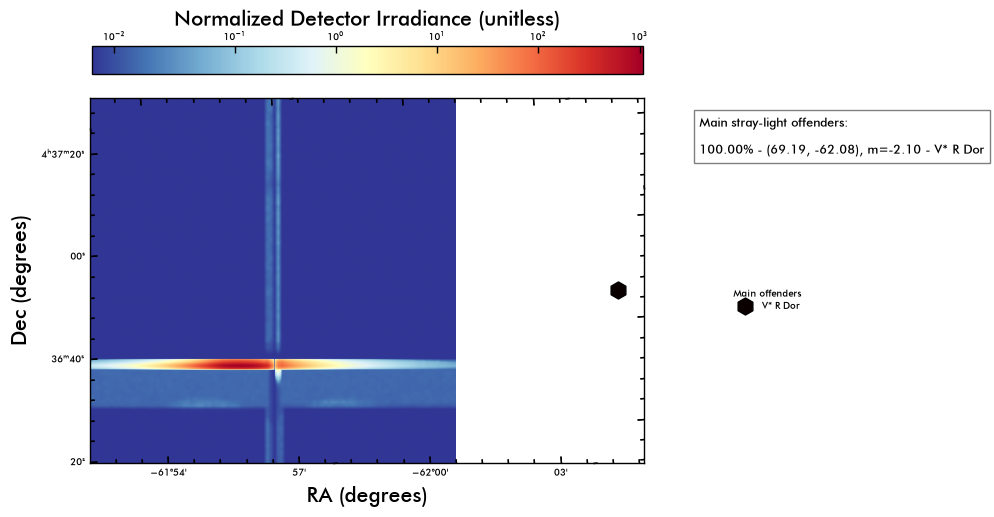

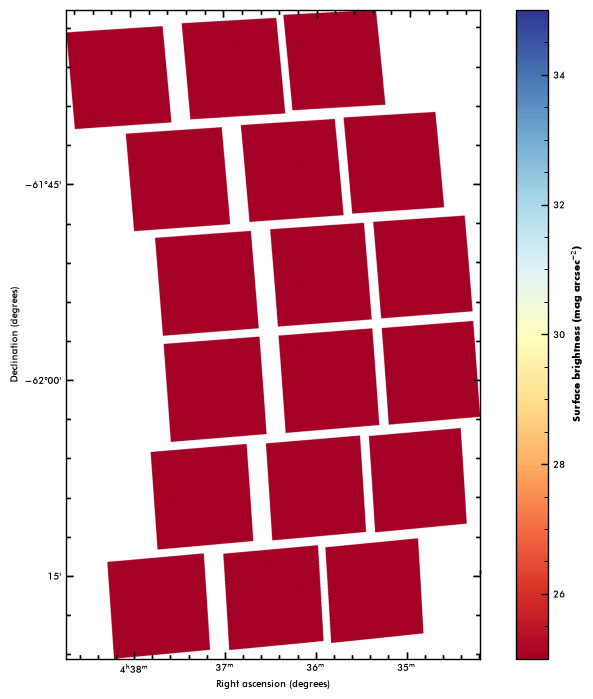

Plot: Stray-light surface brightness flux.
0.4582371
1.3191496


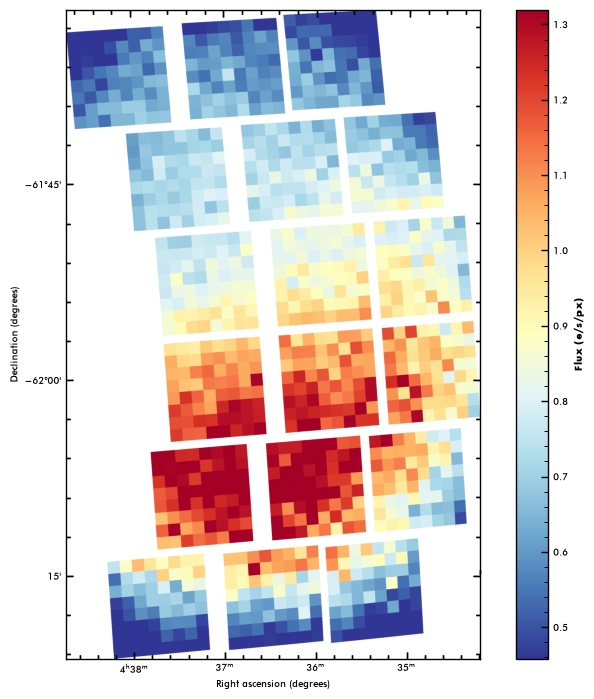

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


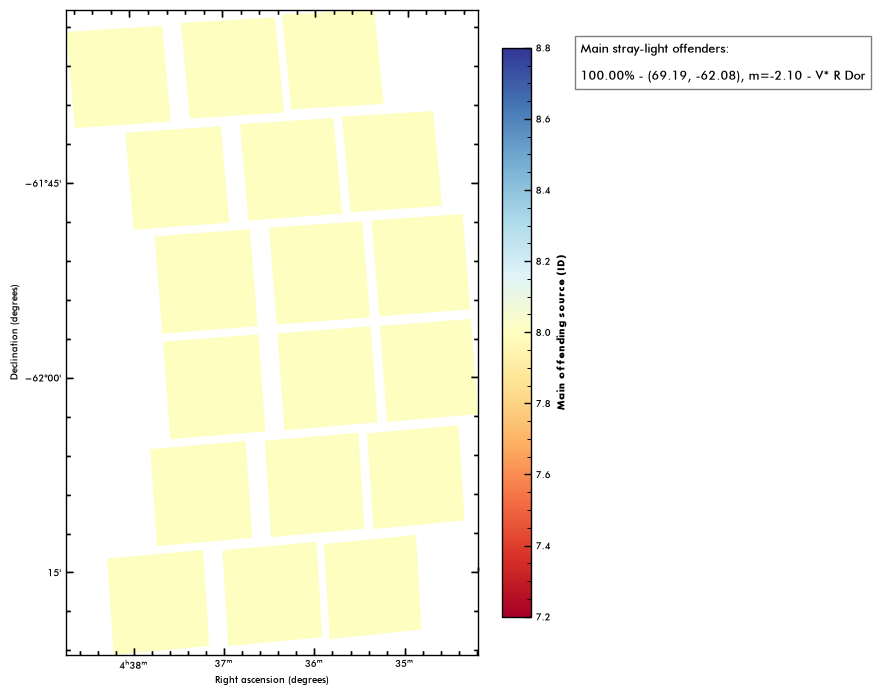

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


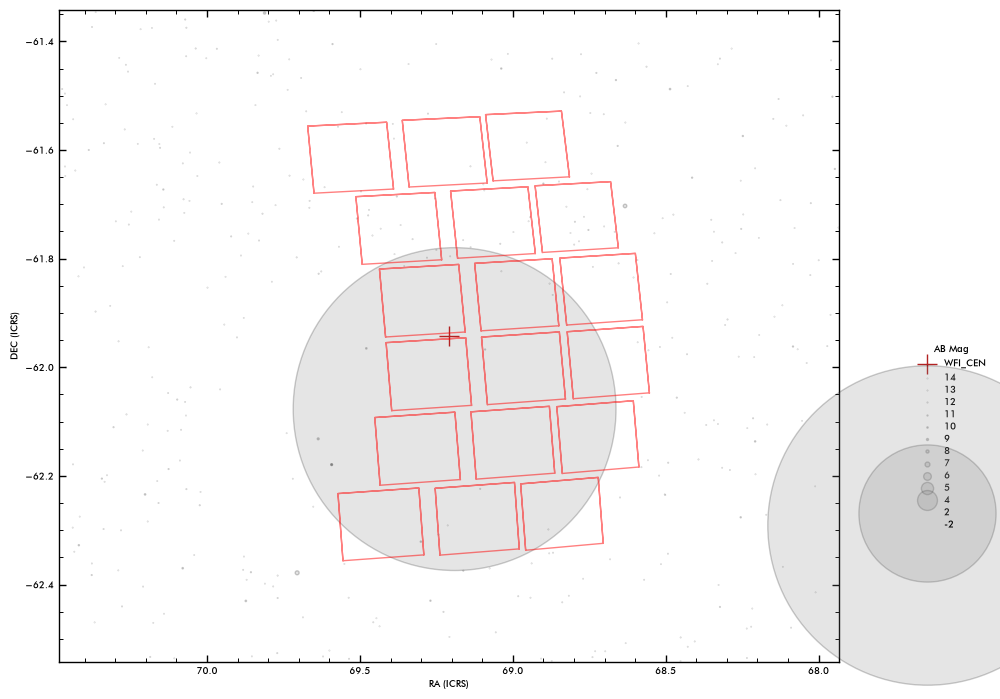

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:33:08.110663 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_075_Roman_RA_069.209_DEC_-61.942_MJD_61352.00000_PA_094.37_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_075_Roman_RA_069.209_DEC_-61.942_MJD_61352.00000_PA_094.37_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:33:24.755687 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:33:24 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⡿

2026-10-24 15:33:26 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣷
2026-10-24T15:33:37.189480 > Done.


18it [00:04,  4.26it/s]

2026-10-24T15:33:41.427643 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.57s/it]


2026-10-24T15:34:28.750387 > Done : 0:00:47.322762 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:34:29.781766 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:34:37.626349 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


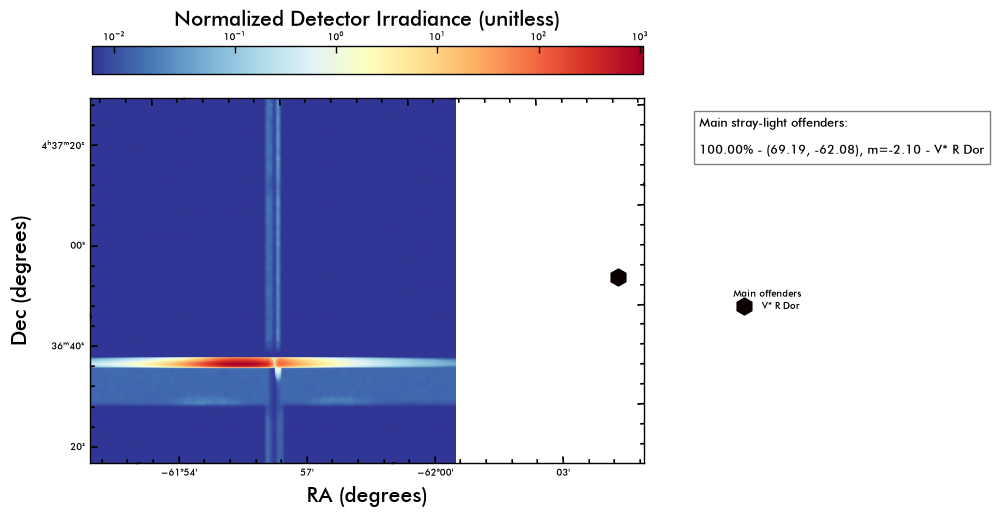

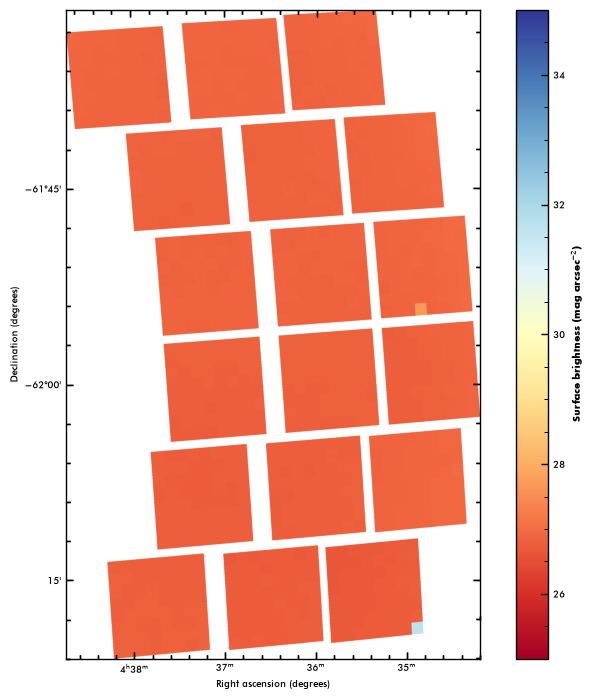

Plot: Stray-light surface brightness flux.
0.008079648
0.009550219


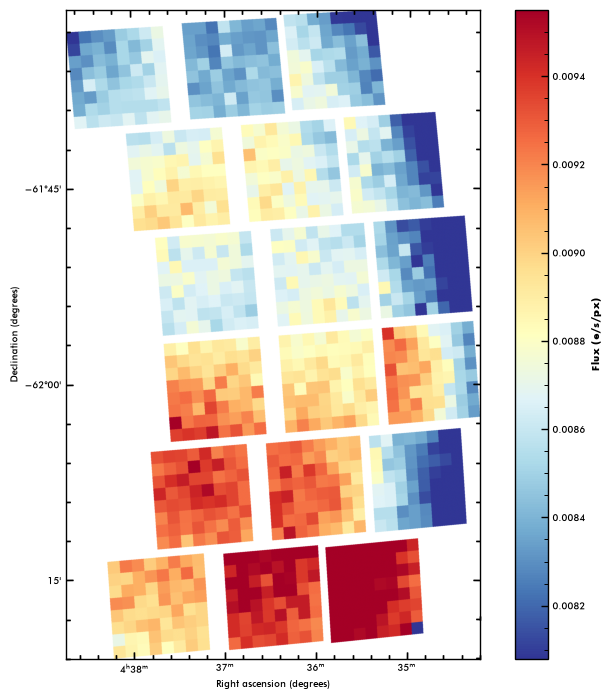

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196852]
Unique IDs with counts > 1:
[     8 196852]
V* R Dor
UCAC2   4465405
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (69.48, -61.97), m=10.02 - UCAC2   4465405


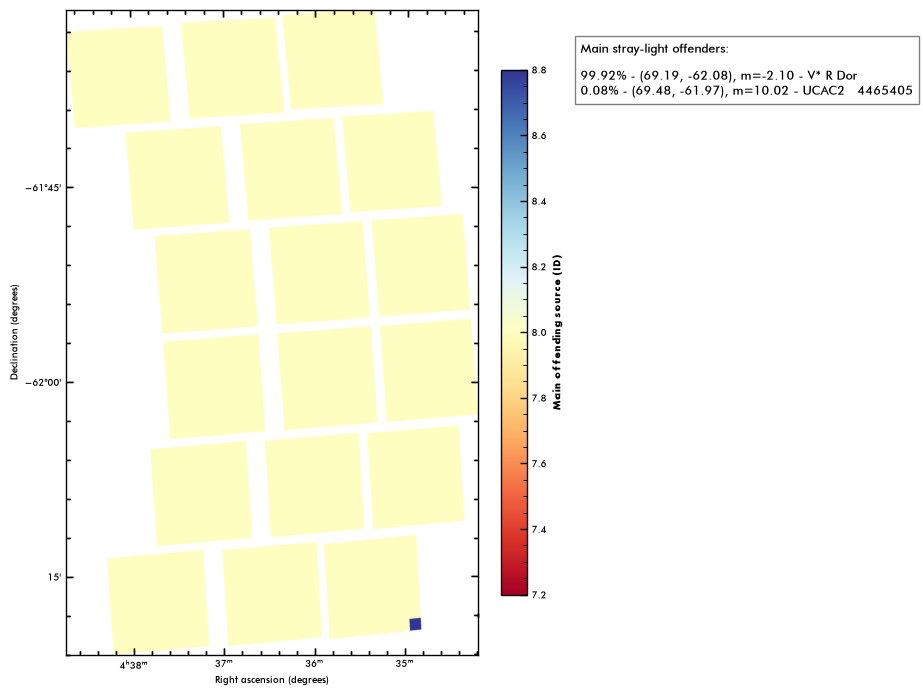

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


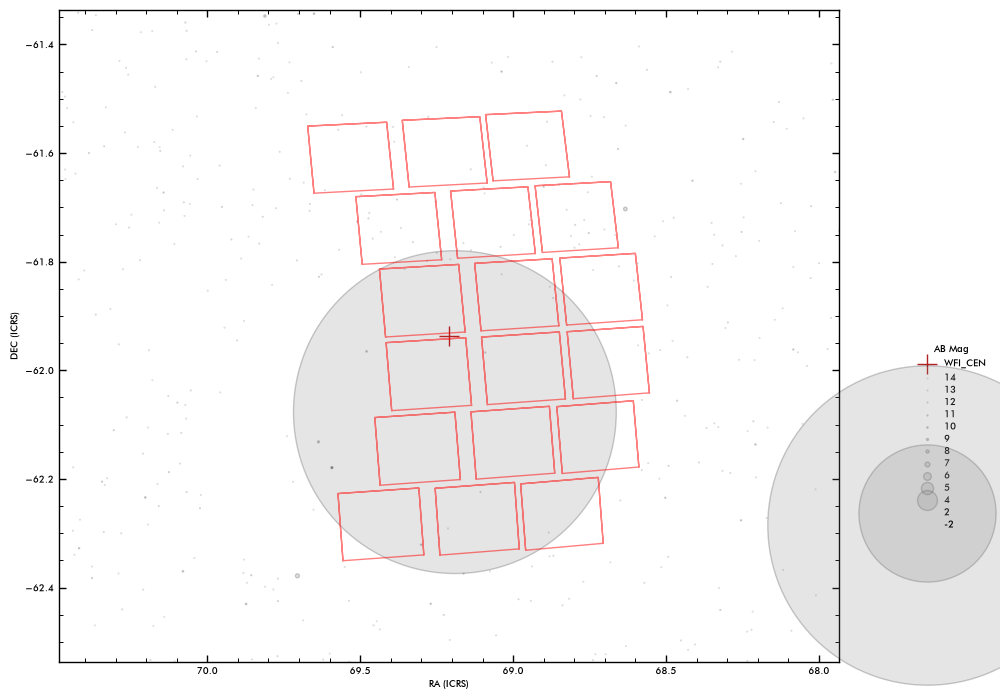

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196852]
Unique IDs with counts > 1:
[     8 196852]
V* R Dor
UCAC2   4465405
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (69.48, -61.97), m=10.02 - UCAC2   4465405
2026-10-24T15:34:45.542852 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_076_Roman_RA_069.210_DEC_-61.937_MJD_61352.00000_PA_094.37_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_076_Roman_RA_069.210_DEC_-61.937_MJD_61352.00000_PA_094.37_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:35:02.147139 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:35:02 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:35:03 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T15:35:13.804114 > Done.


18it [00:03,  4.99it/s]

2026-10-24T15:35:17.420209 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.60s/it]


2026-10-24T15:36:05.378445 > Done : 0:00:47.958257 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:36:06.372353 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:36:14.252752 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


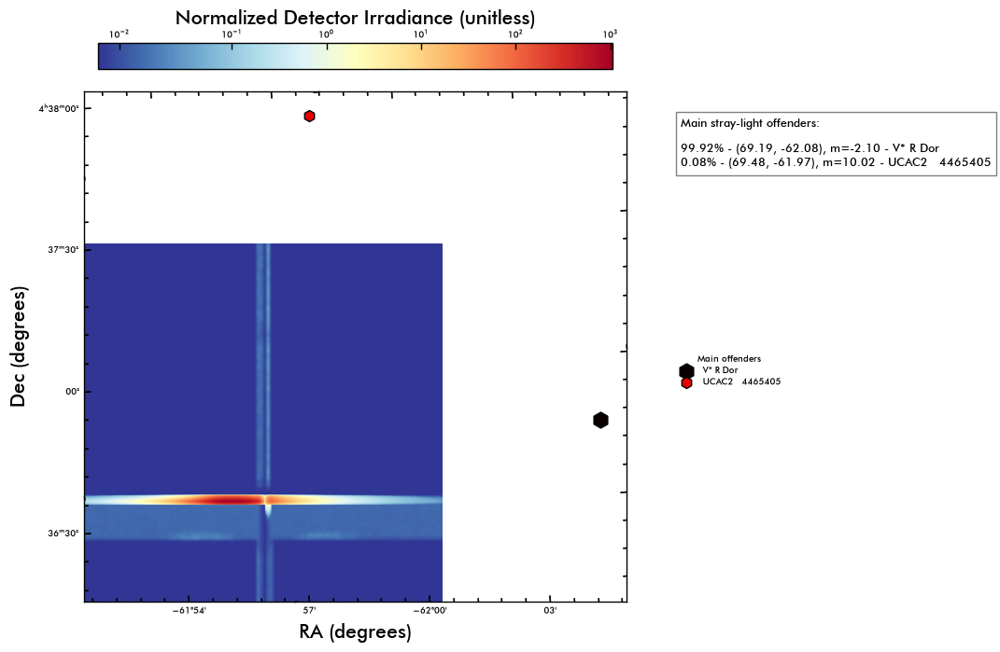

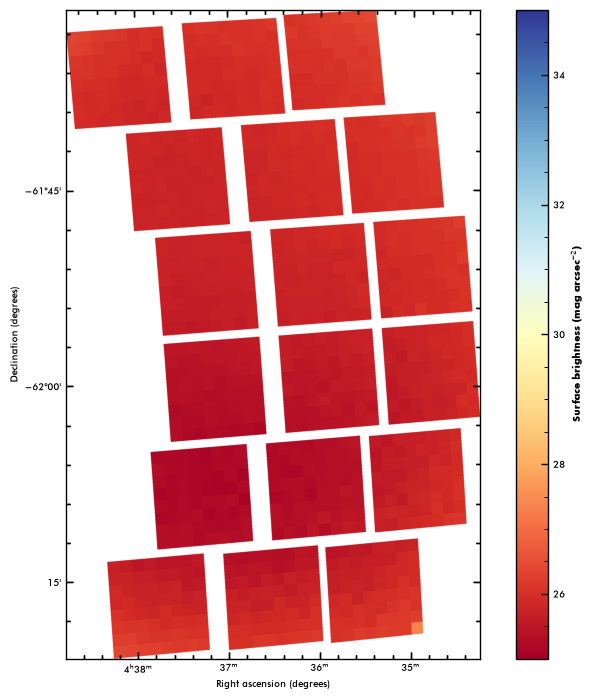

Plot: Stray-light surface brightness flux.
0.016519973
0.037583172


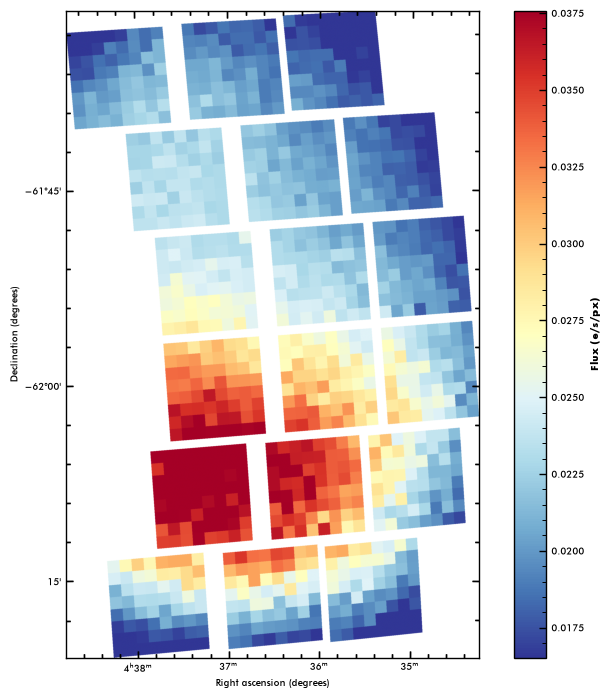

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


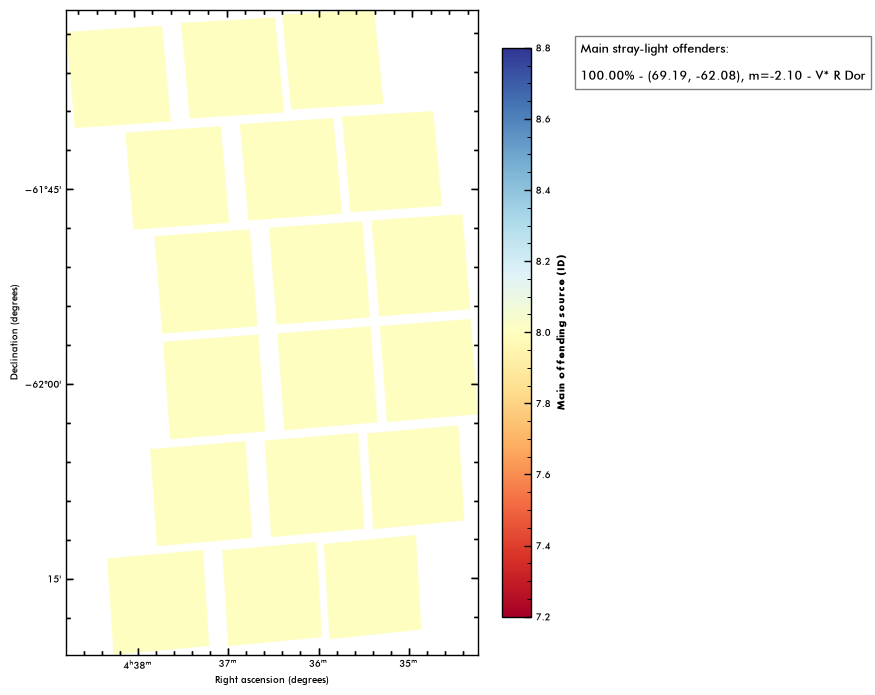

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


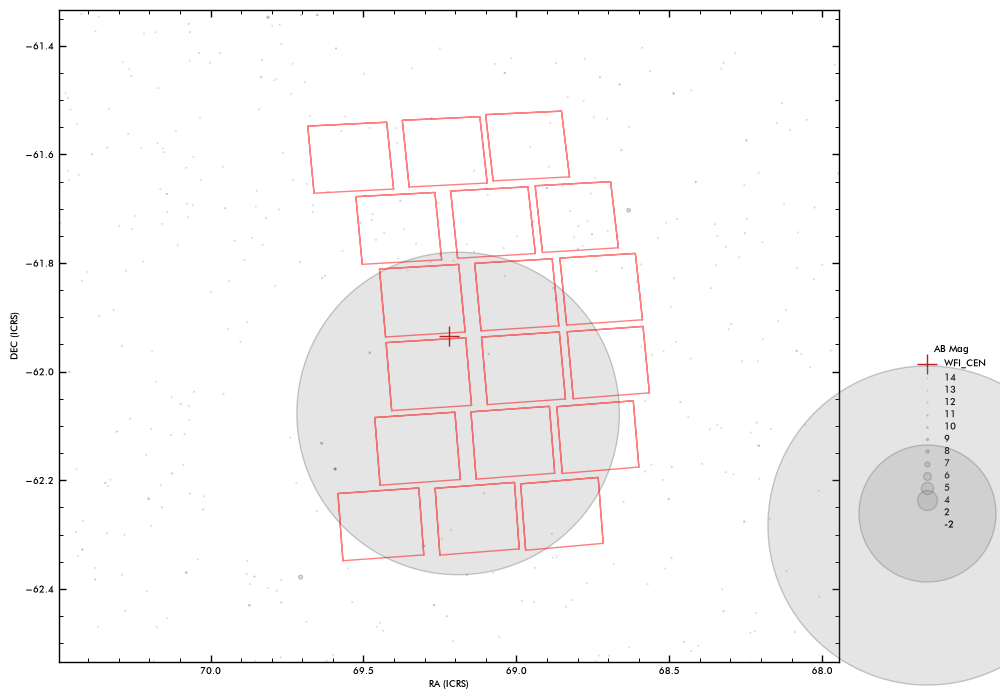

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:36:21.337765 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_077_Roman_RA_069.221_DEC_-61.934_MJD_61352.00000_PA_094.36_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_077_Roman_RA_069.221_DEC_-61.934_MJD_61352.00000_PA_094.36_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:36:37.849658 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:36:37 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 15:36:39 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣟
2026-10-24T15:36:49.933697 > Done.


18it [00:03,  4.97it/s]

2026-10-24T15:36:53.565347 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.53s/it]


2026-10-24T15:37:40.238167 > Done : 0:00:46.672836 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:37:41.269312 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:37:49.135136 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


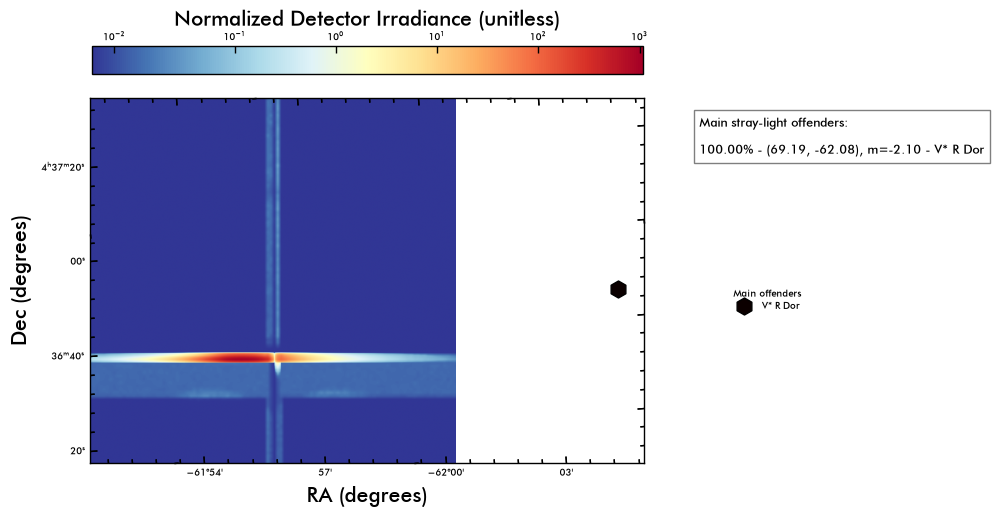

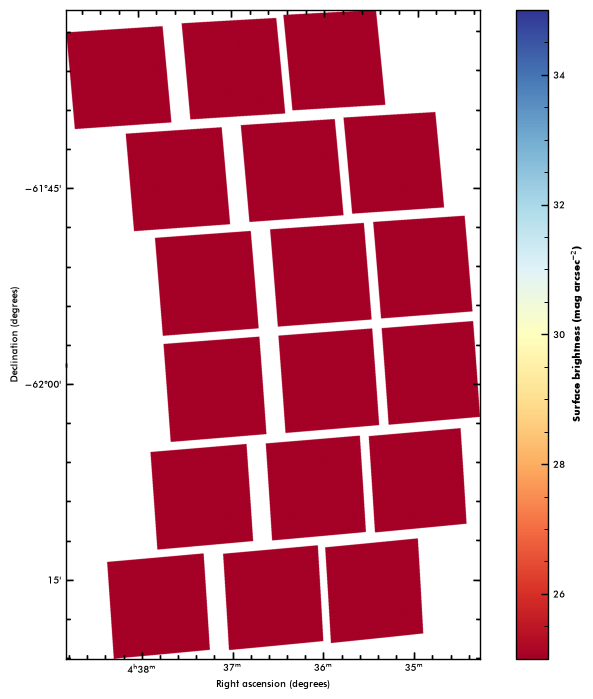

Plot: Stray-light surface brightness flux.
0.85095024
2.556254


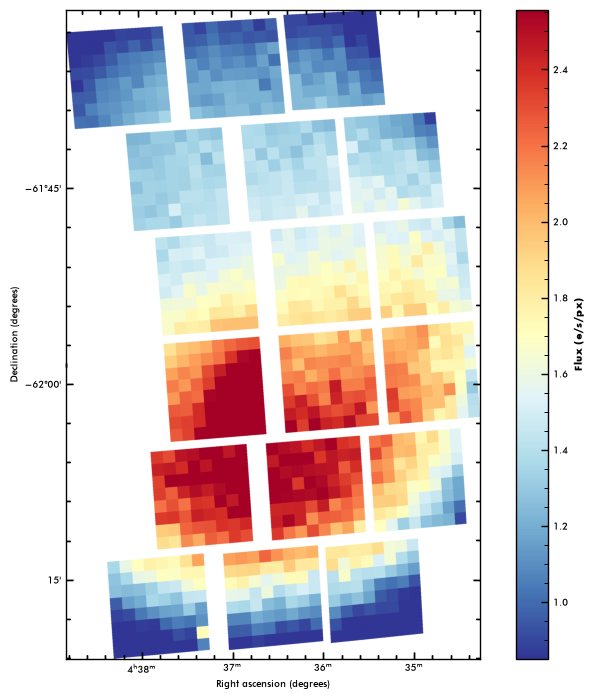

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


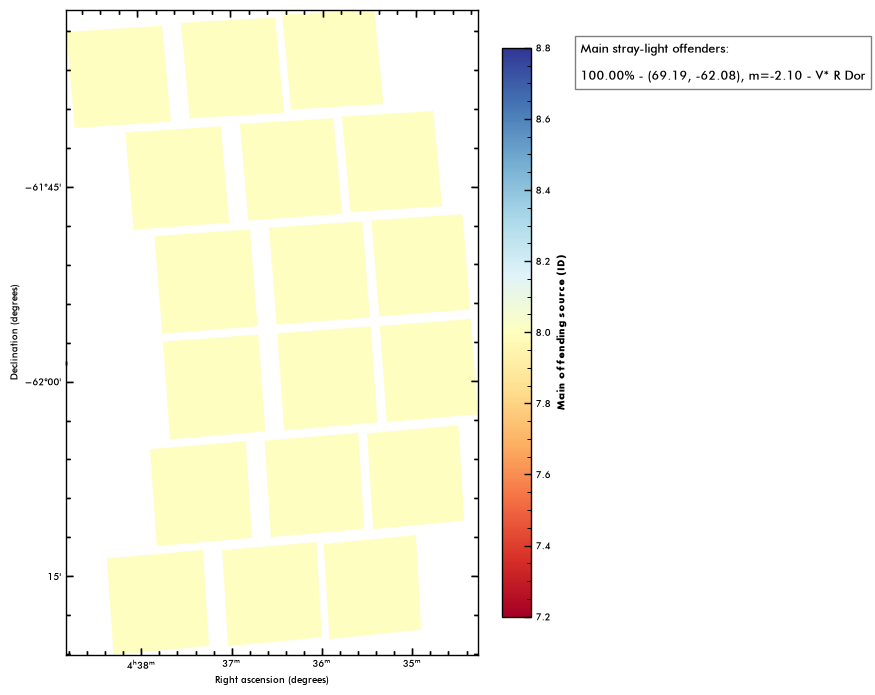

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


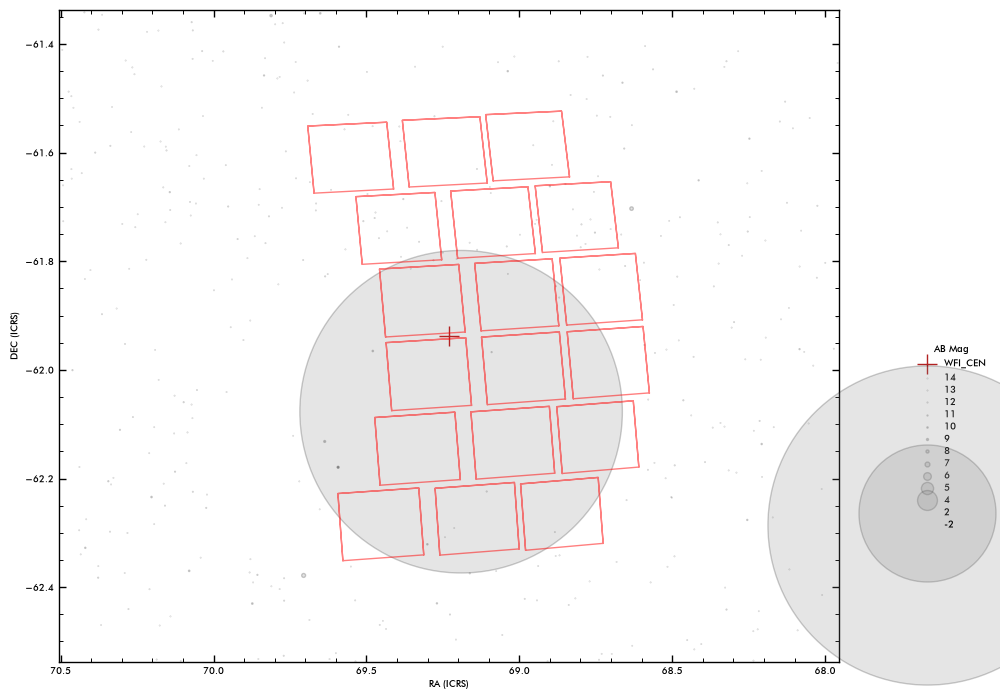

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:37:56.553980 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_078_Roman_RA_069.230_DEC_-61.937_MJD_61352.00000_PA_094.35_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_078_Roman_RA_069.230_DEC_-61.937_MJD_61352.00000_PA_094.35_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:38:13.405703 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:38:13 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣾

2026-10-24 15:38:15 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⢿
2026-10-24T15:38:25.401144 > Done.


18it [00:03,  4.84it/s]

2026-10-24T15:38:29.133930 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.57s/it]


2026-10-24T15:39:16.453844 > Done : 0:00:47.319932 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:39:17.476394 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:39:25.384238 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


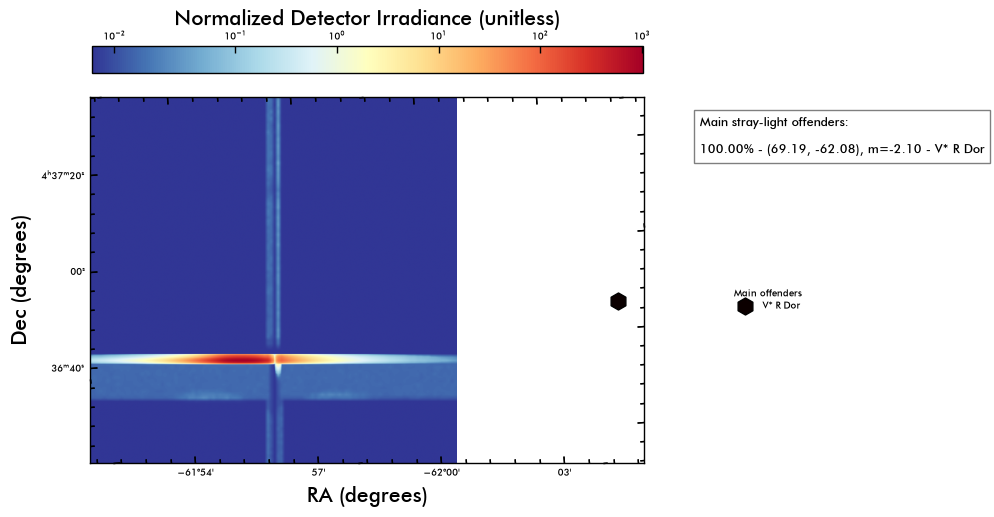

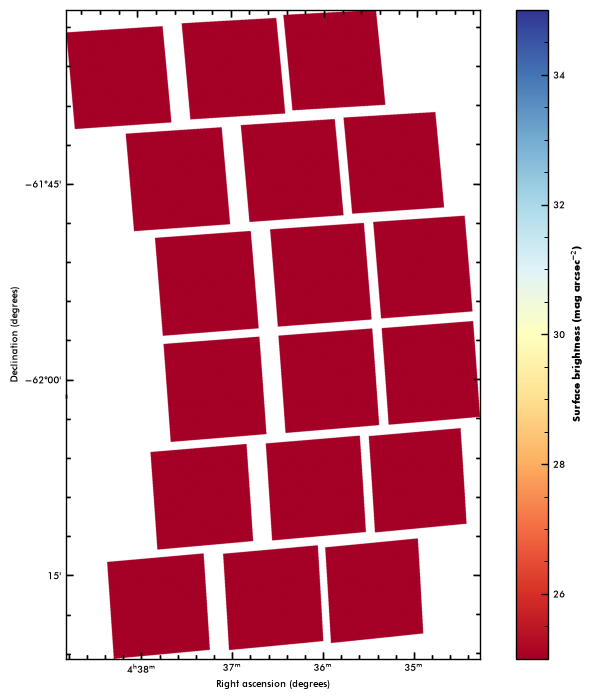

Plot: Stray-light surface brightness flux.
0.42116085
1.1970994


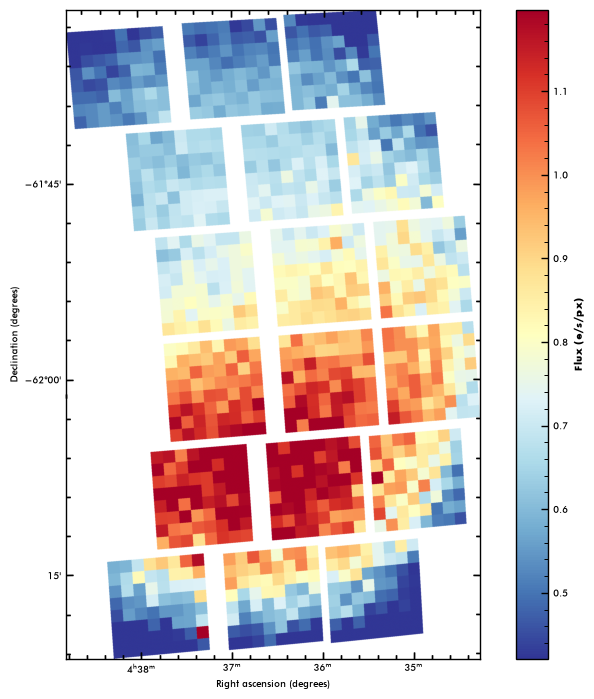

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196853]
Unique IDs with counts > 1:
[     8 196853]
V* R Dor
CPD-62   374
Main stray-light offenders:

99.91% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (69.30, -62.32), m=10.27 - CPD-62   374


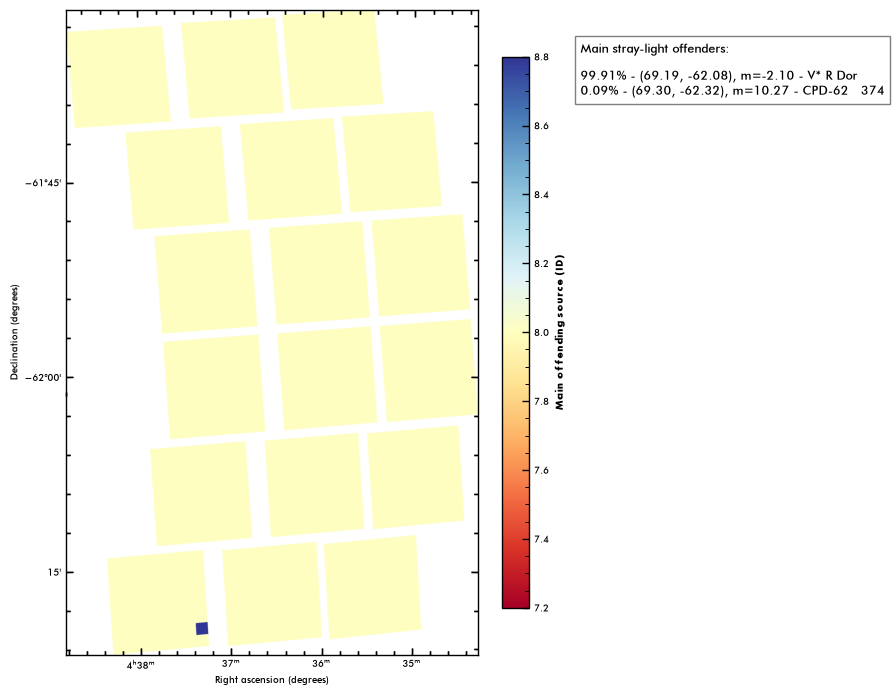

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


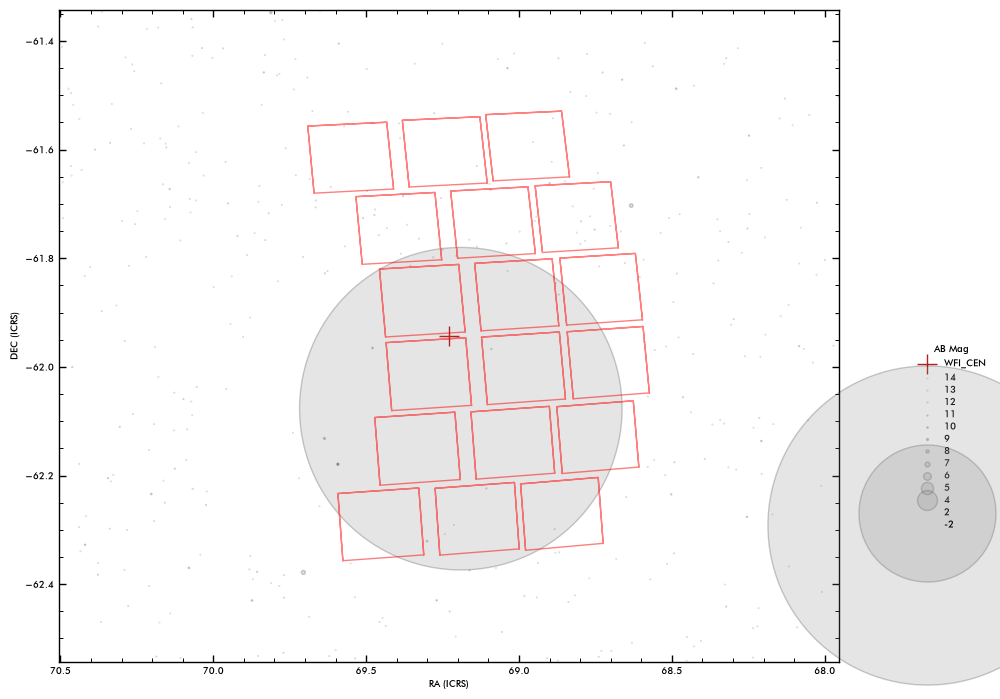

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196853]
Unique IDs with counts > 1:
[     8 196853]
V* R Dor
CPD-62   374
Main stray-light offenders:

99.91% - (69.19, -62.08), m=-2.10 - V* R Dor
0.09% - (69.30, -62.32), m=10.27 - CPD-62   374
2026-10-24T15:39:33.572117 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_079_Roman_RA_069.230_DEC_-61.943_MJD_61352.00000_PA_094.36_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_079_Roman_RA_069.230_DEC_-61.943_MJD_61352.00000_PA_094.36_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:39:50.182915 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:39:50 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 15:39:51 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣯

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣯
2026-10-24T15:40:03.020585 > Done.


18it [00:04,  4.43it/s]

2026-10-24T15:40:07.089875 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.58s/it]


2026-10-24T15:40:54.644244 > Done : 0:00:47.554387 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:40:55.703458 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:41:03.612832 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


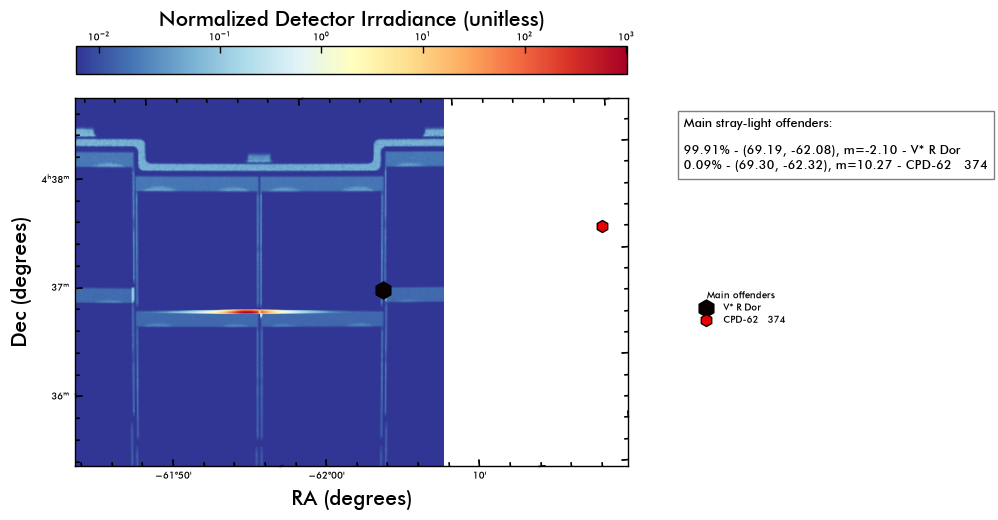

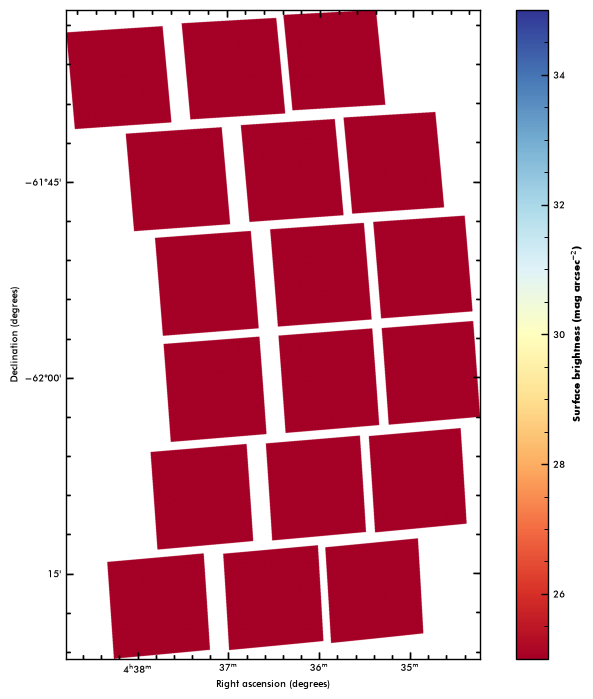

Plot: Stray-light surface brightness flux.
0.09426987
0.370999


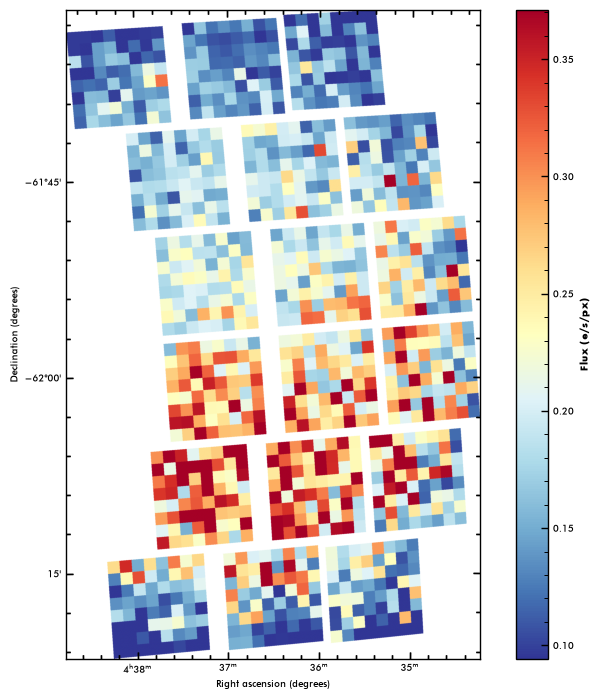

Plot: Main offender map.
8.0
8.0
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor


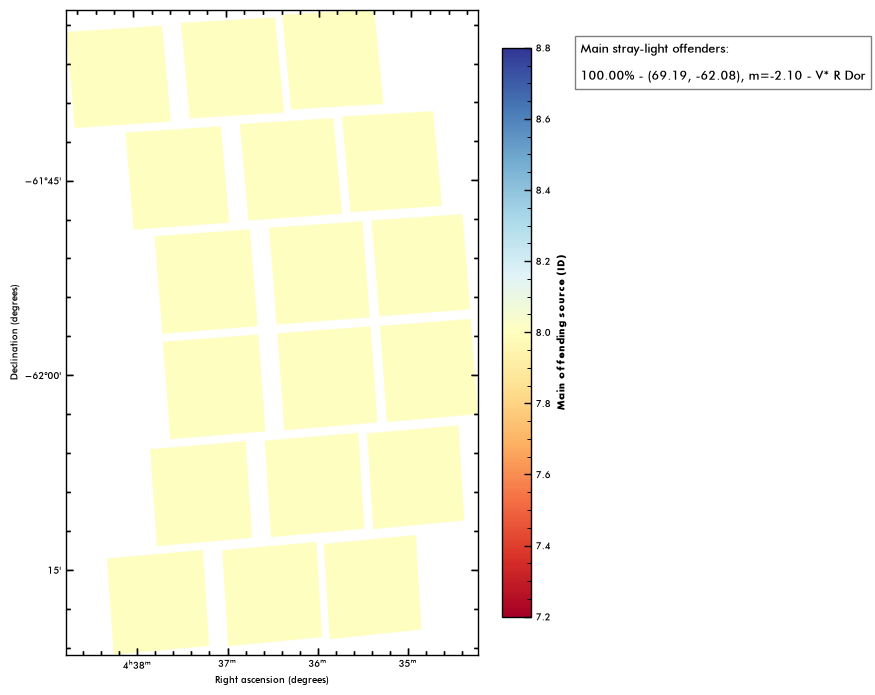

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


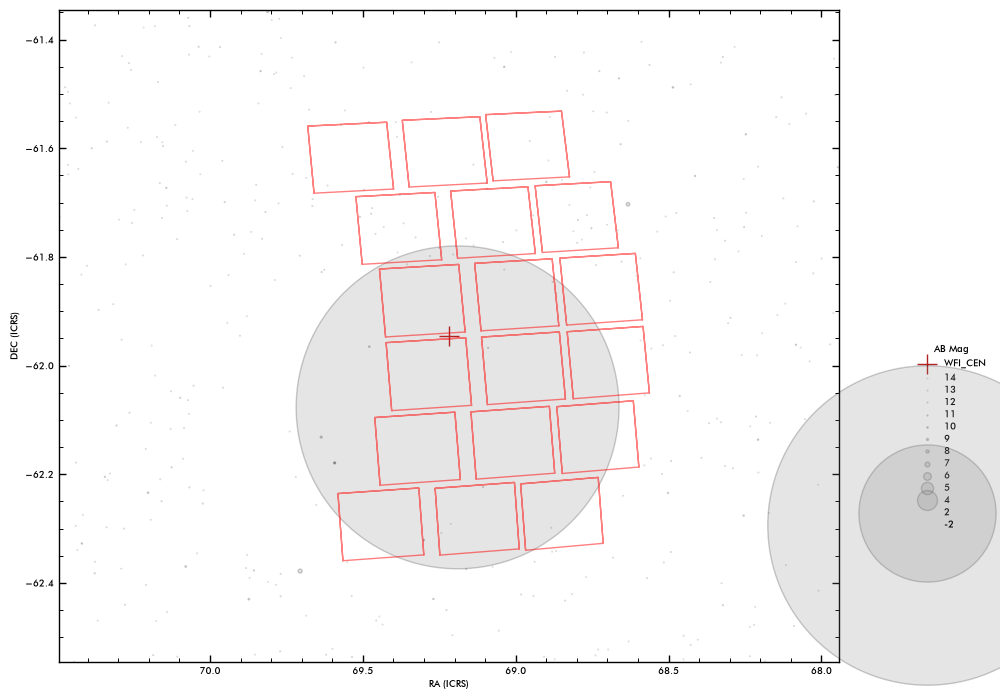

Plot: Location of Main offenders on NDI map.
Unique IDs:
[8]
Unique IDs with counts > 1:
[8]
V* R Dor
Main stray-light offenders:

100.00% - (69.19, -62.08), m=-2.10 - V* R Dor
2026-10-24T15:41:10.944389 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_080_Roman_RA_069.219_DEC_-61.945_MJD_61352.00000_PA_094.36_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_SCAN_DRAGON2_080_Roman_RA_069.219_DEC_-61.945_MJD_61352.00000_PA_094.36_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:41:27.649854 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:41:27 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:41:29 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

...

INFO: Query finished. [astroquery.utils.tap.core]

Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣽
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣽
2026-10-24T15:42:20.682470 > Done.


18it [00:03,  4.85it/s]

2026-10-24T15:42:24.402688 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:46<00:00,  2.56s/it]


2026-10-24T15:43:11.550932 > Done : 0:00:47.148261 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:43:12.536922 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:43:20.380109 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


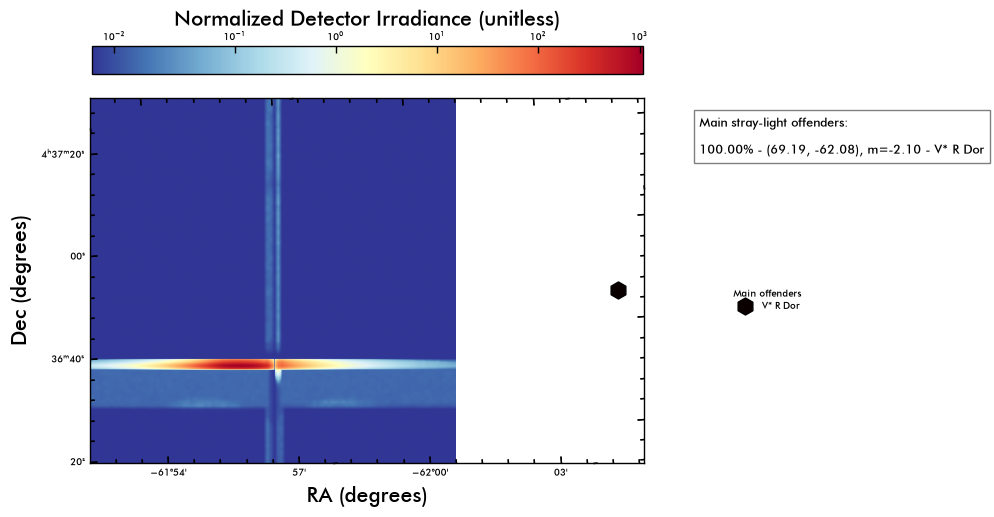

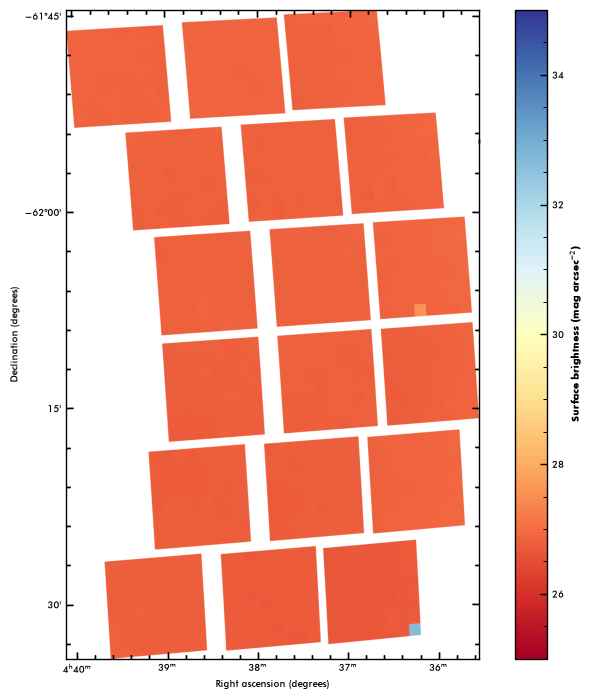

Plot: Stray-light surface brightness flux.
0.008256034
0.009714219


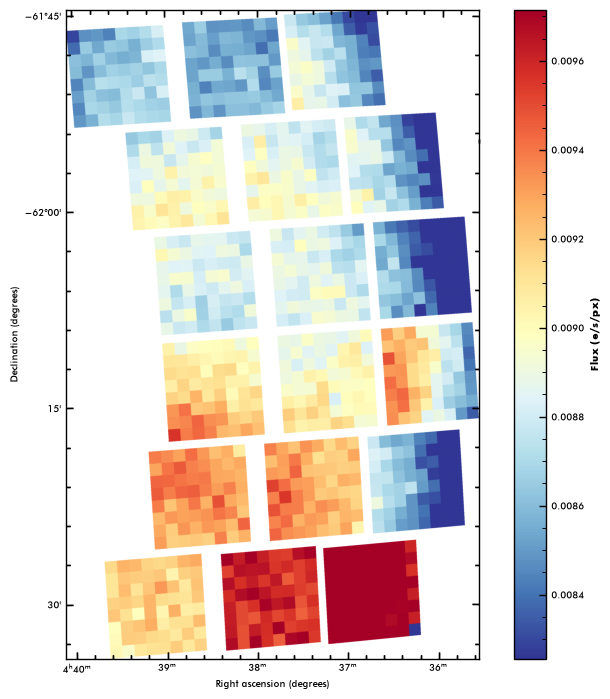

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196843]
Unique IDs with counts > 1:
[     8 196843]
V* R Dor
TYC 8880-190-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (69.87, -62.43), m=9.84 - TYC 8880-190-1


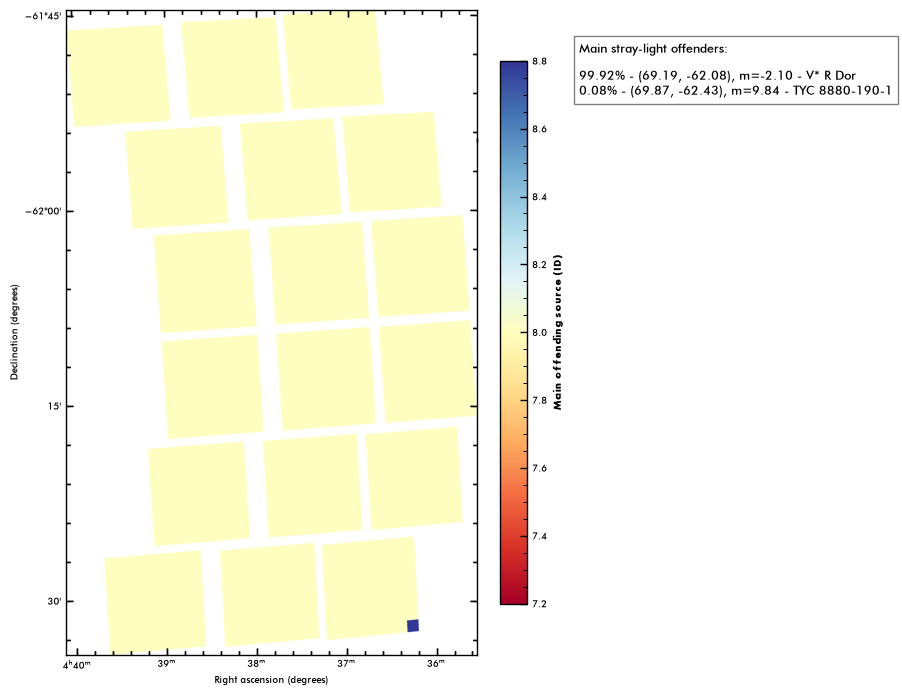

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


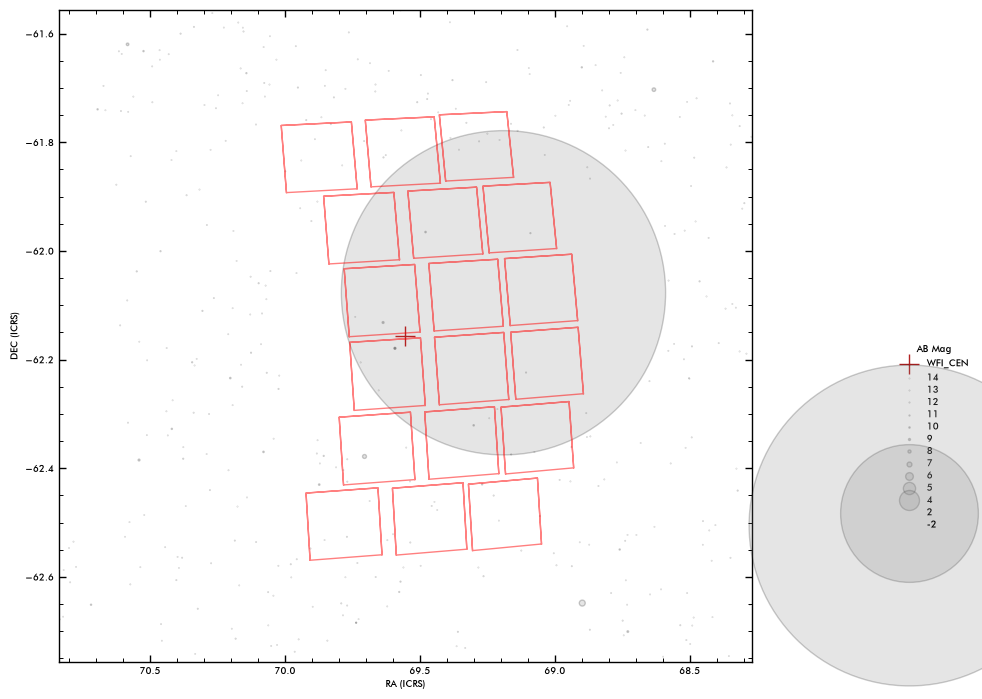

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196843]
Unique IDs with counts > 1:
[     8 196843]
V* R Dor
TYC 8880-190-1
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (69.87, -62.43), m=9.84 - TYC 8880-190-1
2026-10-24T15:43:28.464166 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_NEGATIVE_GAP_1_081_Roman_RA_069.554_DEC_-62.156_MJD_61352.00000_PA_094.07_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_NEGATIVE_GAP_1_081_Roman_RA_069.554_DEC_-62.156_MJD_61352.00000_PA_094.07_stray.pdf
> Synthetic Roman WFI exposure
2026-10-24T15:43:45.638840 > Fetching source catalog
INFO: radius parameter (minimum distance to search for individual stars) is > 0.5 degrees.
Gaia/2MASS/WISE query database can take several minutes to process. Please be patient.
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⢿

2026-10-24 15:43:45 INFO     Retrieving tables...


INFO: Retrieving tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣻

2026-10-24 15:43:47 INFO     Parsing tables...


INFO: Parsing tables... [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟

...

INFO: Done. [astroquery.utils.tap.core]
Querying Gaia/2MASS/WISE/JPL Horizons databases. This might take a few minutes... ⣟
[DEMO WARNING:] Naked eye stars do not have photometry besides g band
All-sky source map constructed.                                                 . ⣻
2026-10-24T15:43:57.988192 > Done.


18it [00:03,  4.88it/s]

2026-10-24T15:44:01.687890 > Starting Stray-light scan: 



100%|██████████| 18/18 [00:45<00:00,  2.53s/it]


2026-10-24T15:44:48.253900 > Done : 0:00:46.566028 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-24T15:44:49.247044 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-10-24T15:44:57.153336 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


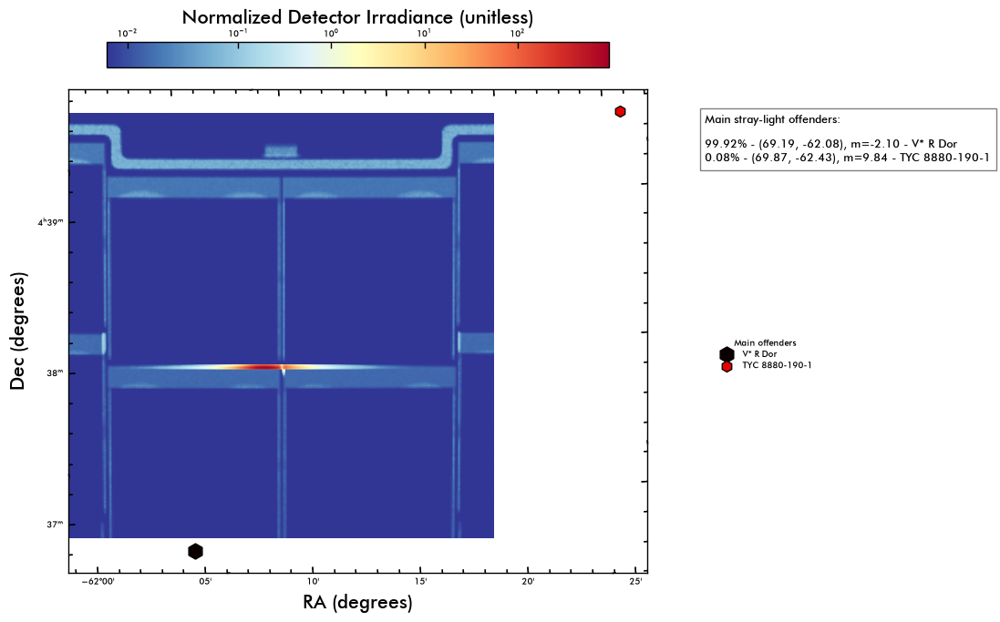

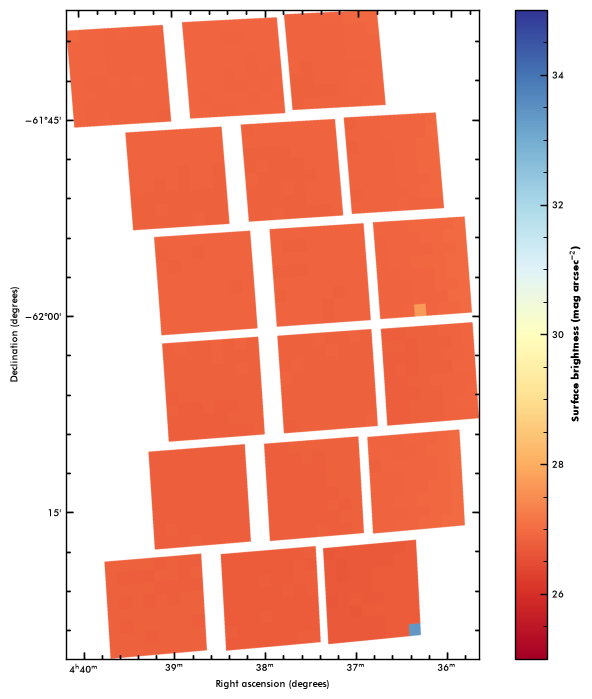

Plot: Stray-light surface brightness flux.
0.00803996
0.0095295515


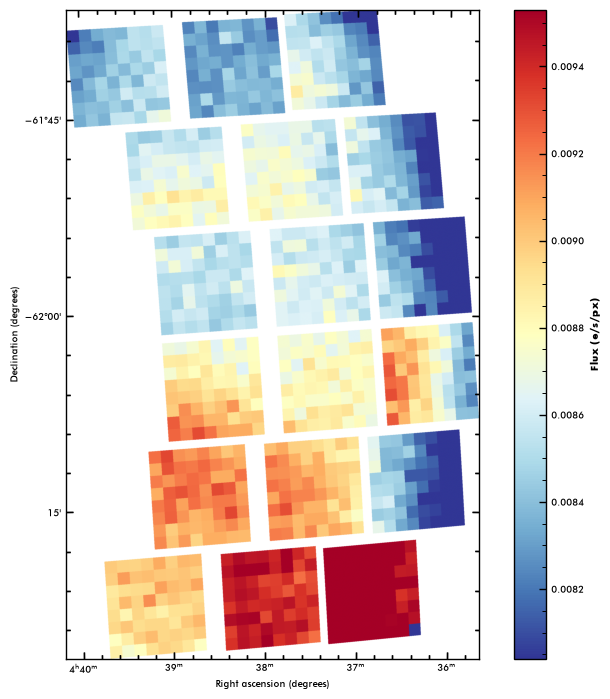

Plot: Main offender map.
8.0
8.0
Unique IDs:
[     8 196850]
Unique IDs with counts > 1:
[     8 196850]
V* R Dor
UCAC2   4465405
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (69.48, -61.97), m=10.02 - UCAC2   4465405


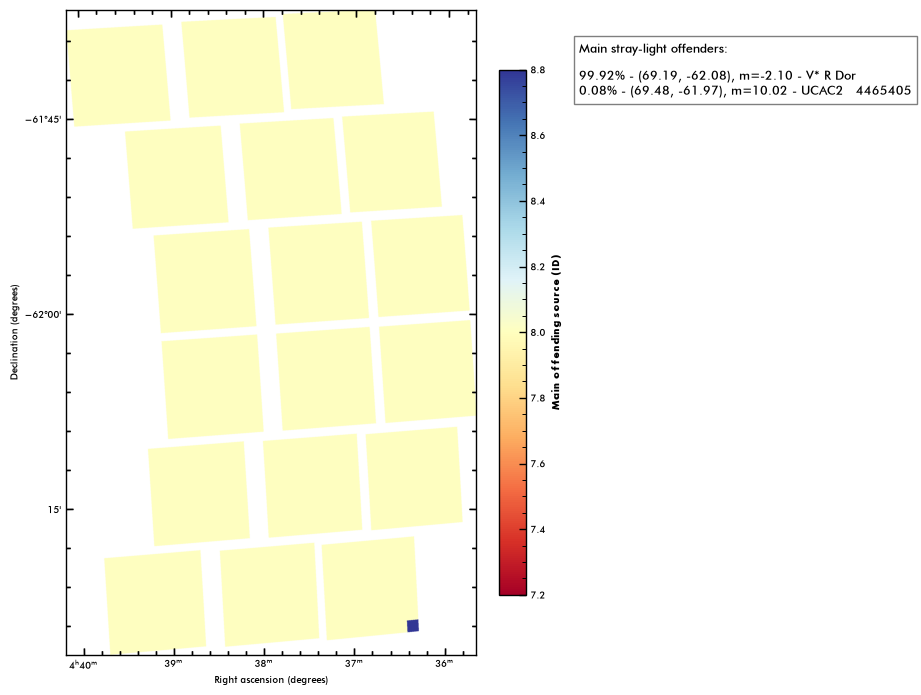

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


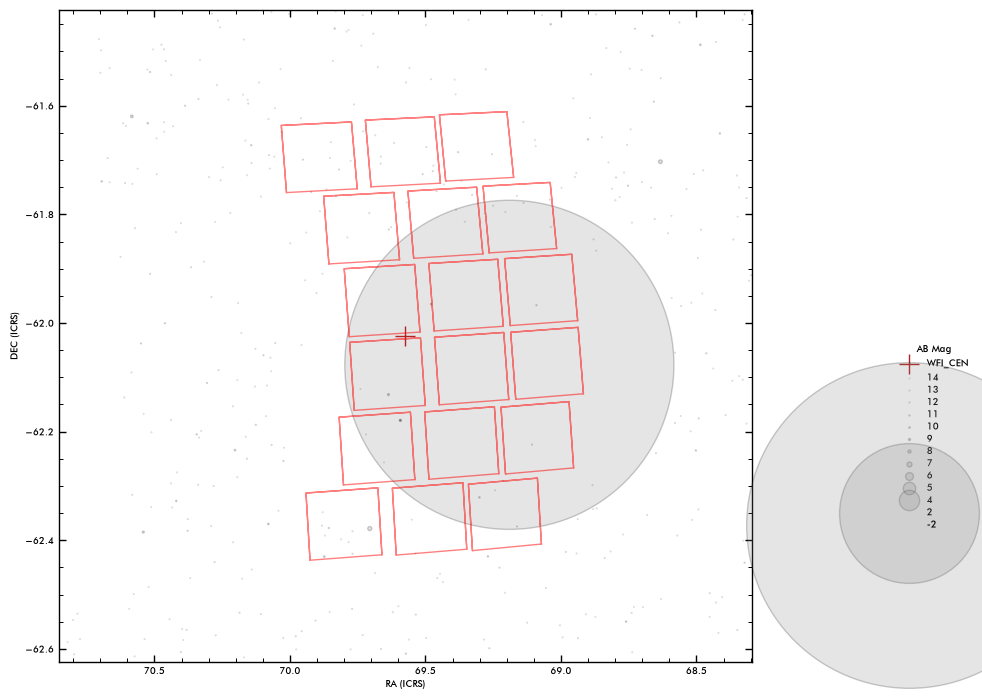

Plot: Location of Main offenders on NDI map.
Unique IDs:
[     8 196850]
Unique IDs with counts > 1:
[     8 196850]
V* R Dor
UCAC2   4465405
Main stray-light offenders:

99.92% - (69.19, -62.08), m=-2.10 - V* R Dor
0.08% - (69.48, -61.97), m=10.02 - UCAC2   4465405
2026-10-24T15:45:04.428280 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_NEGATIVE_GAP_2_082_Roman_RA_069.574_DEC_-62.024_MJD_61352.00000_PA_094.05_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/CAR171/CAR171_NEGATIVE_GAP_2_082_Roman_RA_069.574_DEC_-62.024_MJD_61352.00000_PA_094.05_stray.pdf


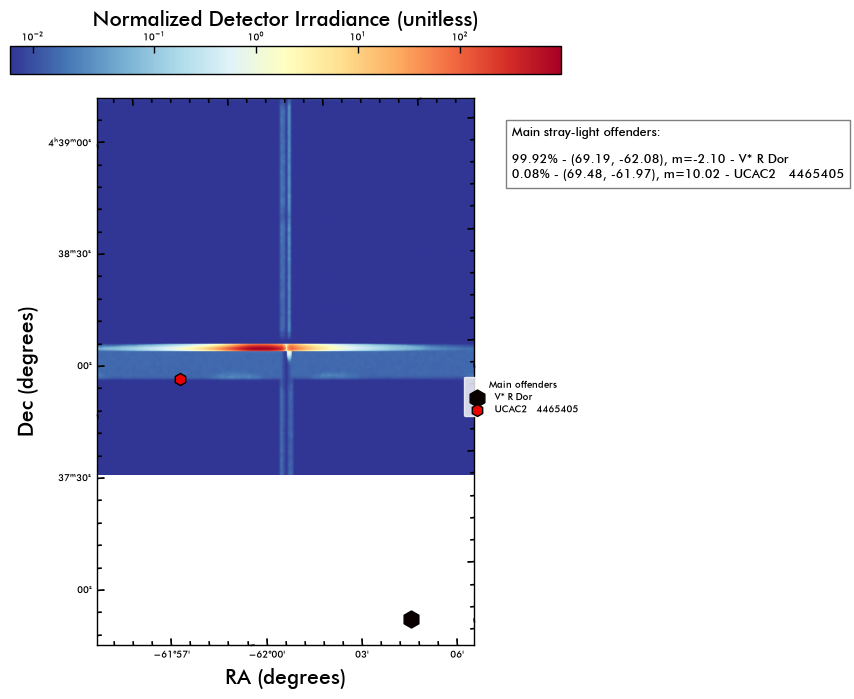

In [9]:

# if True:
for i in range(len(ra_wfi)):
    prefix = "CAR171_" + car171_APT["Target"].iloc[i]

    if os.path.exists(prefix + "/"):
        print("Directory " + prefix + " already exists. Skipping this target.")
        continue

    #i = 0
    ra = car171_APT["RA"].iloc[i] # ra_wfi[i]
    dec = car171_APT["DEC"].iloc[i] # dec_wfi[i]
    pa = car171_APT["WFIPA_off"].iloc[i] # WFIPA_off[i]
    mjd = date.mjd
    bandpass="F146"
    exptime=192

    if car171_APT["Target_Source"].iloc[i] == "Canopus":
        mag_star = -0.74
    if car171_APT["Target_Source"].iloc[i] == "R Doradus":
        mag_star = -1.861947209375566
    if car171_APT["Target_Source"].iloc[i] == "EtaUma":
        mag_star = 3
    if car171_APT["Target_Source"].iloc[i] == "HD128998":
        mag_star = 6.75

    import pandas as pd
    star_catalog = pd.DataFrame({"ra": car171_APT["RA_Source"].iloc[i], 
                                "dec": car171_APT["Dec_Source"].iloc[i] , 
                                "source_id": car171_APT["Target_Source"].iloc[i], 
                                "cat_id": 7,
                                "mag_lambda": mag_star}, index=[0])

    #rosalia_stray = rs.correct.rosalia_stray(ra=ra, dec=dec, prefix="CAR171_" + CAR171["Activity name"].iloc[i] + "_",
    #                                         PA=pa, date=date, bandpass=bandpass, 
    #                                         exptime=exptime, radius=1, catalog=star_catalog,
    #                                         g_mag_max=17, verbose=3)
    observer={"TELESCOP": "Roman/WFI", "pointing": [ra, dec], 
              "FILTER":bandpass, "PA_Y": pa, "EXPSTART": mjd, "EXPTIME": exptime}
    custom_roman_exposure = rs.core.exposure(observer=observer, prefix=prefix) 
    straylight_out = custom_roman_exposure.straylight()
    
    os.system("mkdir " + prefix)
    os.system("mv " + prefix + "*.* " + prefix + "/")


In [10]:
# For the Dragon's Breath example, let's change the target to a dimmer star. 
# Magnitude 2 star. 

# Let's find Canopus (alpha Carinae), the star selected for CAR171. 
# This star is in the continuous viewing zone of Roman, and it is the second brightest star in the sky.
import astropy.units as u
from astroquery.simbad import Simbad
from astropy.coordinates import SkyCoord

alfUrsae = Simbad.query_object('Mizar')
ra_star = alfUrsae["ra"][0]
dec_star = alfUrsae["dec"][0]

target = SkyCoord(ra_star*u.deg, dec_star*u.deg, frame="icrs")
print(target)

# These are the coordinates of specially sensitive locations 
# for stray-light, measured in offset degrees from the center of WFI focal plane
dX = np.array([-0.0688, 0.0688, -0.138, 0.138])
dY = np.array([-0.0312-20/60/60, -0.0312, -0.0035, -0.0048])
number_of_points_of_interest = len(dX)


# To measure the stray-light from those sources, we need to place the center 
# of Roman / WFI at a certain distance and position angle from the source 
# that generates the stray-light. We will name that source the "offending" source. 

# ROSALIA has a specific tool to compute those locations. 

# The optimal position angle of Roman depends with time. 
# Let's set an approximate time for the Commissioning Activities

ra_wfi = np.zeros(number_of_points_of_interest)
dec_wfi = np.zeros(number_of_points_of_interest)
pa_wfi = np.zeros(number_of_points_of_interest)

for i in range(number_of_points_of_interest):
    offset_pointing = rs.telescopes.Roman.find_wfi_center_for_offset_target(ra_target=target.ra.degree,
                                                      dec_target=target.dec.degree,
                                                      mjd=date.mjd,
                                                      dX=dX[i], dY=dY[i])
    ra_wfi[i] = offset_pointing["ra_wficen"]
    dec_wfi[i] = offset_pointing["dec_wficen"]
    pa_wfi[i] = offset_pointing["pa_wfi"]


<SkyCoord (ICRS): (ra, dec) in deg
    (200.98141867, 54.92535197)>


KeyError: 'pa_wfi'